# Module 01: Munich EV Exploratory Analysis

## Research-oriented exploratory notebook

This notebook develops and audits trip-level energy-consumption modelling for the Munich EV dataset. It retains diagnostic and exploratory code so that decisions are traceable, but distinguishes them from confirmed dataset properties and evaluation protocols.

Munich contains 70 trips with driving, battery, thermal, HVAC, environmental, and trip-context telemetry. It has no persistent vehicle, driver, or user identifier, and no direct SOH, capacity, or degradation label. SOC records charge state and must not be interpreted as SOH.

### Navigation

1. Data context and loading  
2. Data quality and telemetry audit  
3. Energy target construction  
4. Feature engineering and audit  
5. Modelling protocol and linear baselines  
6. Feature-selection and robustness studies  
7. Exploratory nonlinear models  
8. Temporal and early-trip forecasting  
9. Findings and limitations


# Module 01: EV Energy Consumption Prediction

## 1. Project Overview

This module investigates the prediction of electric vehicle energy consumption
using driving and vehicle telemetry data collected from trips in the Munich region.

The objective is to develop and compare multiple predictive modelling approaches
and determine which modelling strategy provides the most reliable prediction of
energy consumption.

Rather than assuming a particular model is optimal, this study follows an
experimental model-comparison approach. Conventional machine-learning models,
classical time-series approaches, and temporal deep-learning approaches will be
evaluated under a consistent experimental framework.

The analysis covers:

- Understanding the structure and characteristics of the dataset
- Assessing data quality and missing/inconsistent values
- Exploratory data analysis
- Defining the prediction target
- Feature engineering and preprocessing
- Establishing baseline models
- Comparing conventional machine-learning models
- Investigating time-series and temporal modelling approaches
- Evaluating model performance using multiple metrics
- Performing error analysis and model interpretation
- Selecting the final model based on experimental evidence

The notebook is intended to document the complete modelling process so that
each modelling decision can be traced back to the characteristics of the data
and the results of the experiments.

## 2. Dataset Overview

The dataset contains information at two levels:

### Trip-level information

`Overview.xlsx` provides a summary for each recorded trip. It contains
contextual and trip-level variables such as:

- Trip identifier
- Date and time
- Route/area
- Weather
- Battery temperature at the start and end of the trip
- Battery state of charge at the start and end
- Ambient temperature
- Target cabin temperature
- Distance
- Duration
- Heating/air-conditioning related information
- Notes describing changes or special conditions

### Time-series telemetry

Individual trip files such as `TripA01.csv` contain high-frequency vehicle
telemetry recorded during the trip.

The telemetry includes variables related to:

- Vehicle motion
- Driving behaviour
- Battery electrical behaviour
- Battery temperature
- State of charge
- Heating and air-conditioning
- Environmental and cabin conditions

The telemetry is recorded at a fine temporal resolution. For example, the
sample `TripA01.csv` contains measurements at 0.1-second intervals.

The two levels of data provide complementary information: the trip-level
dataset describes the overall characteristics of a trip, while the telemetry
files provide the temporal behaviour occurring within each trip.

## 3. Data Loading

The dataset is stored locally within the Module 01 directory. The analysis
uses the trip overview file together with the individual trip telemetry files.

## 1. Data Context and Loading

The first cells inspect the overview spreadsheet and representative telemetry files. The aim is to understand the raw data structure before applying any cleaning or modelling assumptions.


In [1]:
from pathlib import Path
import pandas as pd

# Project paths
MODULE_DIR = Path(r"C:\Users\gayat\projects\get_into\FIP\module_01")

OVERVIEW_PATH = MODULE_DIR / "Overview.xlsx"

print("Module directory:", MODULE_DIR)
print("Overview file:", OVERVIEW_PATH)
print("Overview exists:", OVERVIEW_PATH.exists())

Module directory: C:\Users\gayat\projects\get_into\FIP\module_01
Overview file: C:\Users\gayat\projects\get_into\FIP\module_01\Overview.xlsx
Overview exists: True


In [2]:
overview = pd.read_excel(OVERVIEW_PATH)

print("Shape:", overview.shape)
overview.head()

Shape: (72, 16)


,Trip,Date,Route/Area,Weather,Battery Temperature (Start) [°C],Battery Temperature (End),Battery State of Charge (Start),Battery State of Charge (End),Unnamed: 8,Ambient Temperature (Start) [°C],Target Cabin Temperature,Distance [km],Duration [min],Unnamed: 13,Fan,Note
0,TripA01,2019-06-25_13-21-14,Munich East,sunny,21.0,22.0,0.863,0.803,0.060,25.5,23.0,7.427690,16.820000,NaN,"Automatic, Level 1",NaN
1,TripA02,2019-06-25_14-05-31,Munich East,sunny,23.0,26.0,0.803,0.673,0.130,32.0,23.0,23.509709,23.550000,NaN,"Automatic, Level 1",Target Cabin Temperature changed
2,TripA03,2019-06-28_10-02-15,Munich East,sunny,24.0,25.0,0.835,0.751,0.084,21.5,27.0,12.820846,11.180000,NaN,"Automatic, Level 1",Target Cabin Temperature changed
3,TripA04,2019-06-28_10-13-30,Munich East,sunny,25.0,27.0,0.751,0.667,0.084,24.0,22.0,10.727491,6.870000,NaN,"Automatic, Level 1",NaN
4,TripA05,2019-06-28_10-20-26,Munich East,sunny,27.0,27.0,0.667,0.602,0.065,24.5,24.0,12.393223,22.776667,NaN,"Automatic, Level 1",NaN


In [3]:
print("Columns:")
for i, col in enumerate(overview.columns, start=1):
    print(f"{i:2}. {col}")

Columns:
 1. Trip
 2. Date
 3. Route/Area
 4. Weather
 5. Battery Temperature (Start) [°C]
 6. Battery Temperature (End)
 7. Battery State of Charge (Start)
 8. Battery State of Charge (End)
 9. Unnamed: 8
10. Ambient Temperature (Start) [°C]
11. Target Cabin Temperature
12. Distance [km]
13. Duration [min]
14. Unnamed: 13
15. Fan
16. Note


In [6]:
TRIP_PATH = MODULE_DIR / "TripA01.csv"

trip_a01 = pd.read_csv(
    TRIP_PATH,
    sep=";",
    encoding="cp1252"
)

print("Shape:", trip_a01.shape)
trip_a01.head()

Shape: (10090, 28)


,Time [s],Velocity [km/h],Elevation [m],Throttle [%],Motor Torque [Nm],Longitudinal Acceleration [m/s^2],Regenerative Braking Signal,Battery Voltage [V],Battery Current [A],Battery Temperature [°C],...,AirCon Power [kW],Heater Signal,Heater Voltage [V],Heater Current [A],Ambient Temperature [°C],Coolant Temperature Heatercore [°C],Requested Coolant Temperature [°C],Coolant Temperature Inlet [°C],Heat Exchanger Temperature [°C],Cabin Temperature Sensor [°C]
0,0.0,0.0,574.0,0.0,0.0,-0.03,0.0,391.4,-2.20,21.0,...,0.4,1,0,0,25.5,0,0,0,30.5,24.5
1,0.1,0.0,574.0,0.0,0.0,0.00,0.0,391.4,-2.21,21.0,...,0.4,1,0,0,25.5,0,0,0,30.5,24.5
2,0.2,0.0,574.0,0.0,0.0,-0.01,0.0,391.4,-2.26,21.0,...,0.4,1,0,0,25.5,0,0,0,30.5,24.5
3,0.3,0.0,574.0,0.0,0.0,-0.03,0.0,391.4,-2.30,21.0,...,0.4,1,0,0,25.5,0,0,0,30.5,24.5
4,0.4,0.0,574.0,0.0,0.0,-0.03,0.0,391.4,-2.30,21.0,...,0.4,1,0,0,25.5,0,0,0,30.5,24.5


In [7]:
print("Columns:")
for i, col in enumerate(trip_a01.columns, start=1):
    print(f"{i:2}. {col}")

Columns:
 1. Time [s]
 2. Velocity [km/h]
 3. Elevation [m]
 4. Throttle [%]
 5. Motor Torque [Nm]
 6. Longitudinal Acceleration [m/s^2]
 7. Regenerative Braking Signal 
 8. Battery Voltage [V]
 9. Battery Current [A]
10. Battery Temperature [°C]
11. max. Battery Temperature [°C]
12. SoC [%]
13. displayed SoC [%]
14. min. SoC [%]
15. max. SoC [%)
16. Heating Power CAN [kW]
17. Heating Power LIN [W]
18. Requested Heating Power [W]
19. AirCon Power [kW]
20. Heater Signal
21. Heater Voltage [V]
22. Heater Current [A]
23. Ambient Temperature [°C]
24. Coolant Temperature Heatercore [°C]
25. Requested Coolant Temperature [°C]
26. Coolant Temperature Inlet [°C]
27. Heat Exchanger Temperature [°C]
28. Cabin Temperature Sensor [°C]


In [8]:
trip_a01.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10090 entries, 0 to 10089
Data columns (total 28 columns):
 #   Column                               Non-Null Count  Dtype  
---  ------                               --------------  -----  
 0   Time [s]                             10090 non-null  float64
 1   Velocity [km/h]                      10090 non-null  float64
 2   Elevation [m]                        10090 non-null  float64
 3   Throttle [%]                         10090 non-null  float64
 4   Motor Torque [Nm]                    10090 non-null  float64
 5   Longitudinal Acceleration [m/s^2]    10090 non-null  float64
 6   Regenerative Braking Signal          10090 non-null  float64
 7   Battery Voltage [V]                  10090 non-null  float64
 8   Battery Current [A]                  10090 non-null  float64
 9   Battery Temperature [°C]             10090 non-null  float64
 10  max. Battery Temperature [°C]        10090 non-null  float64
 11  SoC [%]                     

## 4. Initial Dataset Structure

The dataset contains two complementary data sources.

### 4.1 Trip-Level Dataset

The `Overview.xlsx` file contains 72 recorded trips, with one row corresponding
to each trip.

It provides contextual and aggregate information such as:

- Trip identifier
- Date and time
- Route/area
- Weather
- Battery temperature at trip start and end
- Battery state of charge at trip start and end
- Ambient temperature
- Target cabin temperature
- Distance travelled
- Trip duration
- Fan configuration
- Additional notes

Two columns (`Unnamed: 8` and `Unnamed: 13`) appear to be spreadsheet artefacts
and will be investigated before being removed from the modelling dataset.

### 4.2 High-Frequency Telemetry Dataset

Each trip is accompanied by a CSV file containing time-series measurements
recorded during that trip.

For the example trip `TripA01.csv`:

- 10,090 observations are available.
- 28 telemetry variables are recorded.
- Measurements are recorded at approximately 0.1-second intervals.
- The variables cover vehicle dynamics, battery behaviour, thermal conditions,
  and cabin climate conditions.

The telemetry data includes variables such as velocity, elevation, throttle,
motor torque, longitudinal acceleration, regenerative braking, battery voltage,
battery current, battery temperature, state of charge, heating/air-conditioning
power, ambient temperature, and cabin temperature.

The distinction between trip-level and time-series data is important for the
subsequent modelling pipeline. The individual telemetry observations cannot
automatically be treated as independent training samples because multiple
observations belong to the same trip.

In [9]:
overview.dtypes

Trip                                 object
Date                                 object
Route/Area                           object
Weather                              object
Battery Temperature (Start) [°C]    float64
Battery Temperature (End)           float64
Battery State of Charge (Start)     float64
Battery State of Charge (End)       float64
Unnamed: 8                          float64
Ambient Temperature (Start) [°C]    float64
Target Cabin Temperature            float64
Distance [km]                       float64
Duration [min]                      float64
Unnamed: 13                         float64
Fan                                  object
Note                                 object
dtype: object

In [10]:
overview.isna().sum()

Trip                                 2
Date                                 2
Route/Area                           2
Weather                              2
Battery Temperature (Start) [°C]     2
Battery Temperature (End)            2
Battery State of Charge (Start)      2
Battery State of Charge (End)        2
Unnamed: 8                           2
Ambient Temperature (Start) [°C]     2
Target Cabin Temperature             2
Distance [km]                        2
Duration [min]                       2
Unnamed: 13                         72
Fan                                  2
Note                                46
dtype: int64

In [11]:
overview.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Trip,70,70,TripA01,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Date,70,69,2019-07-19_09-34-23,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Route/Area,70,9,Munich East,31,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Weather,70,8,sunny,26,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Battery Temperature (Start) [°C],70.0,NaN,NaN,NaN,14.257143,7.73227,-1.0,8.25,13.5,20.0,30.0
Battery Temperature (End),70.0,NaN,NaN,NaN,16.585714,6.581689,3.0,11.25,16.0,21.0,30.0
Battery State of Charge (Start),70.0,NaN,NaN,NaN,0.728329,0.144845,0.315,0.674,0.753,0.847,0.885
Battery State of Charge (End),70.0,NaN,NaN,NaN,0.599014,0.164806,0.154,0.504,0.64,0.7145,0.829
Unnamed: 8,70.0,NaN,NaN,NaN,0.1398,0.119806,-0.241,0.0795,0.12,0.16025,0.719
Ambient Temperature (Start) [°C],70.0,NaN,NaN,NaN,12.364286,9.871611,-3.0,3.5,7.5,21.375,33.5


In [12]:
print("Unique trips:", overview["Trip"].nunique())
print("Duplicate trip IDs:", overview["Trip"].duplicated().sum())

Unique trips: 70
Duplicate trip IDs: 1


In [13]:
overview["Trip"].value_counts().head()

Trip
TripA01    1
TripB13    1
TripB19    1
TripB18    1
TripB17    1
Name: count, dtype: int64

In [14]:
trip_a01["Time [s]"].head(20).to_list()

[0.0,
 0.1,
 0.2,
 0.3,
 0.4,
 0.5,
 0.6,
 0.7,
 0.8,
 0.9,
 1.0,
 1.1,
 1.2,
 1.3,
 1.4,
 1.5,
 1.6,
 1.7,
 1.8,
 1.9]

In [15]:
dt = trip_a01["Time [s]"].diff().dropna()

print("Mean time step:", dt.mean())
print("Median time step:", dt.median())
print("Minimum time step:", dt.min())
print("Maximum time step:", dt.max())

Mean time step: 0.09999999999999999
Median time step: 0.10000000000002274
Minimum time step: 0.09999999999990905
Maximum time step: 0.10000000000002274


In [16]:
print("Start time:", trip_a01["Time [s]"].iloc[0])
print("End time:", trip_a01["Time [s]"].iloc[-1])
print("Duration from telemetry:", trip_a01["Time [s]"].iloc[-1] / 60, "minutes")

Start time: 0.0
End time: 1008.9
Duration from telemetry: 16.815 minutes


In [17]:
overview.loc[
    overview["Trip"] == "TripA01",
    ["Trip", "Distance [km]", "Duration [min]",
     "Battery State of Charge (Start)",
     "Battery State of Charge (End)"]
]

,Trip,Distance [km],Duration [min],Battery State of Charge (Start),Battery State of Charge (End)
0,TripA01,7.42769,16.82,0.863,0.803


In [18]:
overview[overview["Trip"].duplicated(keep=False)].sort_values("Trip")

,Trip,Date,Route/Area,Weather,Battery Temperature (Start) [°C],Battery Temperature (End),Battery State of Charge (Start),Battery State of Charge (End),Unnamed: 8,Ambient Temperature (Start) [°C],Target Cabin Temperature,Distance [km],Duration [min],Unnamed: 13,Fan,Note
32,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
33,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [19]:
from pathlib import Path

for path in sorted(MODULE_DIR.rglob("*")):
    if path.is_file():
        print(path.relative_to(MODULE_DIR))

explore.ipynb
Overview.xlsx
readin.m
TripA01.csv
TripA02.csv
TripA03.csv
TripA04.csv
TripA05.csv
TripA06.csv
TripA07.csv
TripA08.csv
TripA09.csv
TripA10.csv
TripA11.csv
TripA12.csv
TripA13.csv
TripA14.csv
TripA15.csv
TripA16.csv
TripA17.csv
TripA18.csv
TripA19.csv
TripA20.csv
TripA21.csv
TripA22.csv
TripA23.csv
TripA24.csv
TripA25.csv
TripA26.csv
TripA27.csv
TripA28.csv
TripA29.csv
TripA30.csv
TripA31.csv
TripA32.csv
TripB01.csv
TripB02.csv
TripB03.csv
TripB04.csv
TripB05.csv
TripB06.csv
TripB07.csv
TripB08.csv
TripB09.csv
TripB10.csv
TripB11.csv
TripB12.csv
TripB13.csv
TripB14.csv
TripB15.csv
TripB16.csv
TripB17.csv
TripB18.csv
TripB19.csv
TripB20.csv
TripB21.csv
TripB22.csv
TripB23.csv
TripB24.csv
TripB25.csv
TripB26.csv
TripB27.csv
TripB28.csv
TripB29.csv
TripB30.csv
TripB31.csv
TripB32.csv
TripB33.csv
TripB34.csv
TripB35.csv
TripB36.csv
TripB37.csv
TripB38.csv


## 2. Data Quality and Telemetry Audit

The overview is cleaned to its 70 non-empty trip records, and the repeated diagnostics below validate identifiers, timestamps, telemetry availability, SOC coverage, and known header inconsistencies. These diagnostic cells are retained because they establish the quality controls used downstream.


In [20]:
# Remove completely empty rows only for this inspection
overview_clean_check = overview.dropna(how="all").copy()

print("Original rows:", len(overview))
print("Completely empty rows:", overview.isna().all(axis=1).sum())
print("Rows after removing empty rows:", len(overview_clean_check))
print("Unique trip IDs:", overview_clean_check["Trip"].nunique())
print("Duplicate trip IDs:", overview_clean_check["Trip"].duplicated().sum())

Original rows: 72
Completely empty rows: 2
Rows after removing empty rows: 70
Unique trip IDs: 70
Duplicate trip IDs: 0


### Initial Data Quality Finding

The trip overview contains 72 spreadsheet rows. However, two rows are
completely empty and do not represent recorded trips.

After excluding these empty rows:

- Number of recorded trips: 70
- Number of unique trip identifiers: 70
- Duplicate trip identifiers: 0

The 70 trips consist of 32 `TripA` trips and 38 `TripB` trips.

## 4. Initial Data Quality Assessment

Before feature engineering and modelling, the raw trip-level summary data and
telemetry data are checked for structural consistency and measurement quality.

The audit verifies:

- correspondence between overview trips and telemetry files
- duplicate or missing trip identifiers
- telemetry sampling intervals
- telemetry duration versus recorded trip duration
- starting and ending battery SOC consistency
- missing values in telemetry
- invalid or non-finite measurements
- unusual trip-level inconsistencies

This step is performed before modelling so that subsequent feature engineering
and model comparisons are based on a clearly understood dataset.

In [22]:
# Remove completely empty rows
overview = overview.dropna(how="all").copy()

print("Shape after removing empty rows:", overview.shape)
print("Unique trips:", overview["Trip"].nunique())
print("Duplicate trip IDs:", overview["Trip"].duplicated().sum())

Shape after removing empty rows: (70, 16)
Unique trips: 70
Duplicate trip IDs: 0


In [23]:
overview = overview.rename(columns={
    "Unnamed: 8": "SoC Change",
    "Unnamed: 13": "Empty Column"
})

In [24]:
overview = overview.drop(columns=["Empty Column"])

In [28]:
overview.head()

,Trip,Date,Route/Area,Weather,Battery Temperature (Start) [°C],Battery Temperature (End),Battery State of Charge (Start),Battery State of Charge (End),SoC Change,Ambient Temperature (Start) [°C],Target Cabin Temperature,Distance [km],Duration [min],Fan,Note
0,TripA01,2019-06-25_13-21-14,Munich East,sunny,21.0,22.0,0.863,0.803,0.060,25.5,23.0,7.427690,16.820000,"Automatic, Level 1",NaN
1,TripA02,2019-06-25_14-05-31,Munich East,sunny,23.0,26.0,0.803,0.673,0.130,32.0,23.0,23.509709,23.550000,"Automatic, Level 1",Target Cabin Temperature changed
2,TripA03,2019-06-28_10-02-15,Munich East,sunny,24.0,25.0,0.835,0.751,0.084,21.5,27.0,12.820846,11.180000,"Automatic, Level 1",Target Cabin Temperature changed
3,TripA04,2019-06-28_10-13-30,Munich East,sunny,25.0,27.0,0.751,0.667,0.084,24.0,22.0,10.727491,6.870000,"Automatic, Level 1",NaN
4,TripA05,2019-06-28_10-20-26,Munich East,sunny,27.0,27.0,0.667,0.602,0.065,24.5,24.0,12.393223,22.776667,"Automatic, Level 1",NaN


In [26]:
print("Final overview shape:", overview.shape)
print("\nColumns:")
for i, col in enumerate(overview.columns, 1):
    print(f"{i:2}. {col}")

Final overview shape: (70, 15)

Columns:
 1. Trip
 2. Date
 3. Route/Area
 4. Weather
 5. Battery Temperature (Start) [°C]
 6. Battery Temperature (End)
 7. Battery State of Charge (Start)
 8. Battery State of Charge (End)
 9. SoC Change
10. Ambient Temperature (Start) [°C]
11. Target Cabin Temperature
12. Distance [km]
13. Duration [min]
14. Fan
15. Note


In [29]:
from pathlib import Path
import pandas as pd
import numpy as np

module_path = Path(r"C:\Users\gayat\projects\get_into\FIP\module_01")

telemetry_files = sorted(module_path.glob("Trip*.csv"))

print("Telemetry files found:", len(telemetry_files))
print("Overview trips:", len(overview))

overview_trips = set(overview["Trip"].dropna().astype(str))
telemetry_trips = {f.stem for f in telemetry_files}

print("Trips in overview but missing telemetry:",
      sorted(overview_trips - telemetry_trips))

print("Telemetry files without overview entry:",
      sorted(telemetry_trips - overview_trips))

Telemetry files found: 70
Overview trips: 70
Trips in overview but missing telemetry: []
Telemetry files without overview entry: []


In [30]:
audit_rows = []

for file in telemetry_files:

    trip_name = file.stem

    try:
        df = pd.read_csv(
            file,
            sep=";",
            encoding="cp1252"
        )

        time = df["Time [s]"].to_numpy(dtype=float)
        soc = df["SoC [%]"].to_numpy(dtype=float)

        time_diff = np.diff(time)

        overview_row = overview[
            overview["Trip"].astype(str) == trip_name
        ]

        if len(overview_row) != 1:
            audit_rows.append({
                "Trip": trip_name,
                "Rows": len(df),
                "Status": "Missing/ambiguous overview entry"
            })
            continue

        overview_row = overview_row.iloc[0]

        audit_rows.append({
            "Trip": trip_name,
            "Rows": len(df),

            "Telemetry Start [s]": time[0],
            "Telemetry End [s]": time[-1],
            "Telemetry Duration [min]": time[-1] / 60,

            "Overview Duration [min]": overview_row["Duration [min]"],

            "Duration Difference [min]":
                time[-1] / 60 - overview_row["Duration [min]"],

            "Telemetry SOC Start [%]": soc[0],
            "Telemetry SOC End [%]": soc[-1],

            "Overview SOC Start [%]":
                overview_row["Battery State of Charge (Start)"] * 100,

            "Overview SOC End [%]":
                overview_row["Battery State of Charge (End)"] * 100,

            "SOC Start Difference [%]":
                soc[0] -
                overview_row["Battery State of Charge (Start)"] * 100,

            "SOC End Difference [%]":
                soc[-1] -
                overview_row["Battery State of Charge (End)"] * 100,

            "Mean Sampling Interval [s]":
                np.mean(time_diff),

            "Min Sampling Interval [s]":
                np.min(time_diff),

            "Max Sampling Interval [s]":
                np.max(time_diff),

            "Missing Values": df.isna().sum().sum(),

            "Non-finite Values":
                (~np.isfinite(df.select_dtypes(include=np.number))).sum().sum(),

            "Status": "OK"
        })

    except Exception as e:

        audit_rows.append({
            "Trip": trip_name,
            "Status": f"ERROR: {e}"
        })

audit = pd.DataFrame(audit_rows)

audit

,Trip,Rows,Telemetry Start [s],Telemetry End [s],Telemetry Duration [min],Overview Duration [min],Duration Difference [min],Telemetry SOC Start [%],Telemetry SOC End [%],Overview SOC Start [%],Overview SOC End [%],SOC Start Difference [%],SOC End Difference [%],Mean Sampling Interval [s],Min Sampling Interval [s],Max Sampling Interval [s],Missing Values,Non-finite Values,Status
0,TripA01,10090,0.0,1008.9,16.815000,16.820000,-0.005000,86.9,81.5,86.3,80.3,6.000000e-01,1.200000e+00,0.1,0.1,0.1,0,0,OK
1,TripA02,14130,0.0,1412.9,23.548333,23.550000,-0.001667,80.3,67.3,80.3,67.3,-1.421085e-14,-1.421085e-14,0.1,0.1,0.1,0,0,OK
2,TripA03,6706,0.0,670.5,11.175000,11.180000,-0.005000,83.5,75.1,83.5,75.1,0.000000e+00,0.000000e+00,0.1,0.1,0.1,0,0,OK
3,TripA04,4124,0.0,412.3,6.871667,6.870000,0.001667,75.1,66.7,75.1,66.7,0.000000e+00,0.000000e+00,0.1,0.1,0.1,0,0,OK
4,TripA05,13667,0.0,1366.6,22.776667,22.776667,0.000000,66.7,60.2,66.7,60.2,0.000000e+00,7.105427e-15,0.1,0.1,0.1,0,0,OK
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
65,TripB34,7338,0.0,733.7,12.228333,12.228333,0.000000,73.9,NaN,73.9,71.3,0.000000e+00,NaN,0.1,0.1,0.1,17748,17748,OK
66,TripB35,13626,0.0,1362.5,22.708333,22.708333,0.000000,85.4,NaN,85.4,71.5,1.421085e-14,NaN,0.1,0.1,0.1,104,104,OK
67,TripB36,28523,0.0,2852.2,47.536667,47.536667,0.000000,72.1,NaN,72.1,44.5,0.000000e+00,NaN,0.1,0.1,0.1,8,8,OK
68,TripB37,14173,0.0,1417.2,23.620000,23.620000,0.000000,83.8,NaN,83.8,68.0,0.000000e+00,NaN,0.1,0.1,0.1,64,64,OK


In [31]:
print("Number of audited trips:", len(audit))

print("\nSampling interval:")
print(audit["Mean Sampling Interval [s]"].describe())

print("\nDuration difference:")
print(audit["Duration Difference [min]"].describe())

print("\nSOC start difference:")
print(audit["SOC Start Difference [%]"].describe())

print("\nSOC end difference:")
print(audit["SOC End Difference [%]"].describe())

print("\nMissing values:")
print(audit["Missing Values"].value_counts())

print("\nNon-finite values:")
print(audit["Non-finite Values"].value_counts())

Number of audited trips: 70

Sampling interval:
count    7.000000e+01
mean     1.000000e-01
std      1.347574e-16
min      1.000000e-01
25%      1.000000e-01
50%      1.000000e-01
75%      1.000000e-01
max      1.000000e-01
Name: Mean Sampling Interval [s], dtype: float64

Duration difference:
count    70.000000
mean      0.000071
std       0.002015
min      -0.005000
25%       0.000000
50%       0.000000
75%       0.000000
max       0.015000
Name: Duration Difference [min], dtype: float64

SOC start difference:
count    6.900000e+01
mean     1.304348e-02
std      8.028084e-02
min     -1.421085e-14
25%      0.000000e+00
50%      0.000000e+00
75%      0.000000e+00
max      6.000000e-01
Name: SOC Start Difference [%], dtype: float64

SOC end difference:
count    43.000000
mean     -1.132558
std       5.515982
min     -34.600000
25%       0.000000
50%       0.000000
75%       0.000000
max       1.200000
Name: SOC End Difference [%], dtype: float64

Missing values:
Missing Values
0        

In [32]:
print("Trips with sampling interval != 0.1 s:")
display(
    audit[
        ~np.isclose(
            audit["Mean Sampling Interval [s]"],
            0.1,
            atol=1e-4
        )
    ]
)

print("Trips with large duration mismatch:")
display(
    audit[
        audit["Duration Difference [min]"].abs() > 0.05
    ]
)

print("Trips with SOC mismatch:")
display(
    audit[
        (audit["SOC Start Difference [%]"].abs() > 0.5) |
        (audit["SOC End Difference [%]"].abs() > 0.5)
    ]
)

print("Trips with missing telemetry values:")
display(
    audit[audit["Missing Values"] > 0]
)

Trips with sampling interval != 0.1 s:


,Trip,Rows,Telemetry Start [s],Telemetry End [s],Telemetry Duration [min],Overview Duration [min],Duration Difference [min],Telemetry SOC Start [%],Telemetry SOC End [%],Overview SOC Start [%],Overview SOC End [%],SOC Start Difference [%],SOC End Difference [%],Mean Sampling Interval [s],Min Sampling Interval [s],Max Sampling Interval [s],Missing Values,Non-finite Values,Status


Trips with large duration mismatch:


,Trip,Rows,Telemetry Start [s],Telemetry End [s],Telemetry Duration [min],Overview Duration [min],Duration Difference [min],Telemetry SOC Start [%],Telemetry SOC End [%],Overview SOC Start [%],Overview SOC End [%],SOC Start Difference [%],SOC End Difference [%],Mean Sampling Interval [s],Min Sampling Interval [s],Max Sampling Interval [s],Missing Values,Non-finite Values,Status


Trips with SOC mismatch:


,Trip,Rows,Telemetry Start [s],Telemetry End [s],Telemetry Duration [min],Overview Duration [min],Duration Difference [min],Telemetry SOC Start [%],Telemetry SOC End [%],Overview SOC Start [%],Overview SOC End [%],SOC Start Difference [%],SOC End Difference [%],Mean Sampling Interval [s],Min Sampling Interval [s],Max Sampling Interval [s],Missing Values,Non-finite Values,Status
0,TripA01,10090,0.0,1008.9,16.815000,16.820000,-0.005,86.9,81.5,86.3,80.3,0.6,1.2,0.1,0.1,0.1,0,0,OK
15,TripA16,19066,0.0,1906.5,31.775000,31.775000,0.000,63.0,46.8,63.0,51.5,0.0,-4.7,0.1,0.1,0.1,0,0,OK
30,TripA31,11870,0.0,1186.9,19.781667,19.781667,0.000,81.0,71.9,81.0,82.5,0.0,-10.6,0.1,0.1,0.1,0,0,OK
45,TripB14,38220,0.0,3821.9,63.698333,63.698333,0.000,85.5,0.0,85.5,34.6,0.0,-34.6,0.1,0.1,0.1,62,62,OK


Trips with missing telemetry values:


,Trip,Rows,Telemetry Start [s],Telemetry End [s],Telemetry Duration [min],Overview Duration [min],Duration Difference [min],Telemetry SOC Start [%],Telemetry SOC End [%],Overview SOC Start [%],Overview SOC End [%],SOC Start Difference [%],SOC End Difference [%],Mean Sampling Interval [s],Min Sampling Interval [s],Max Sampling Interval [s],Missing Values,Non-finite Values,Status
10,TripA11,14245,0.0,1424.4,23.740000,23.740000,0.0,87.0,75.6,87.0,75.6,0.000000e+00,0.000000e+00,0.1,0.1,0.1,14244,14244,OK
35,TripB04,29550,0.0,2954.9,49.248333,49.248333,0.0,45.1,69.2,45.1,69.2,0.000000e+00,1.421085e-14,0.1,0.1,0.1,100,100,OK
36,TripB05,10195,0.0,1019.4,16.990000,16.990000,0.0,71.9,NaN,71.9,59.5,1.421085e-14,NaN,0.1,0.1,0.1,10237,10237,OK
37,TripB06,13521,0.0,1352.0,22.533333,22.533333,0.0,83.2,NaN,83.2,69.3,0.000000e+00,NaN,0.1,0.1,0.1,13905,13905,OK
38,TripB07,22899,0.0,2289.8,38.163333,38.163333,0.0,67.4,NaN,67.4,50.4,0.000000e+00,NaN,0.1,0.1,0.1,100200,100200,OK
39,TripB08,29140,0.0,2913.9,48.565000,48.565000,0.0,67.3,NaN,67.3,44.0,-1.421085e-14,NaN,0.1,0.1,0.1,64,64,OK
40,TripB09,56102,0.0,5610.1,93.501667,93.501667,0.0,70.0,NaN,70.0,46.0,0.000000e+00,NaN,0.1,0.1,0.1,82164,82164,OK
41,TripB10,20233,0.0,2023.2,33.720000,33.720000,0.0,84.8,NaN,84.8,39.0,0.000000e+00,NaN,0.1,0.1,0.1,2128,2128,OK
42,TripB11,7534,0.0,753.3,12.555000,12.555000,0.0,NaN,NaN,38.9,30.8,NaN,NaN,0.1,0.1,0.1,68,68,OK
43,TripB12,32256,0.0,3225.5,53.758333,53.758333,0.0,73.4,NaN,73.4,51.3,0.000000e+00,NaN,0.1,0.1,0.1,24,24,OK


In [33]:
missingness_rows = []

for file in telemetry_files:

    trip_name = file.stem

    df = pd.read_csv(
        file,
        sep=";",
        encoding="cp1252"
    )

    numeric_cols = df.select_dtypes(include=np.number).columns

    missing_total = df[numeric_cols].isna().sum().sum()

    if missing_total > 0:

        row = {
            "Trip": trip_name,
            "Rows": len(df),
            "Missing Values": missing_total
        }

        for col in numeric_cols:
            count = df[col].isna().sum()

            if count > 0:
                missing_indices = df.index[df[col].isna()]

                row[f"{col} Missing"] = count
                row[f"{col} First Missing"] = missing_indices.min()
                row[f"{col} Last Missing"] = missing_indices.max()

        missingness_rows.append(row)

missingness = pd.DataFrame(missingness_rows)

display(missingness)

,Trip,Rows,Missing Values,Unnamed: 23 Missing,Unnamed: 23 First Missing,Unnamed: 23 Last Missing,Ambient Temperature Sensor [°C] Missing,Ambient Temperature Sensor [°C] First Missing,Ambient Temperature Sensor [°C] Last Missing,Coolant Volume Flow +500 [l/h] Missing,...,SoC [%] Last Missing,displayed SoC [%] Missing,displayed SoC [%] First Missing,displayed SoC [%] Last Missing,min. SoC [%] Missing,min. SoC [%] First Missing,min. SoC [%] Last Missing,max. SoC [%) Missing,max. SoC [%) First Missing,max. SoC [%) Last Missing
0,TripA11,14245,14244,14244.0,0.0,14244.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,TripB04,29550,100,NaN,NaN,NaN,5.0,29445.0,29449.0,5.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,TripB05,10195,10237,NaN,NaN,NaN,2.0,10193.0,10194.0,10195.0,...,10194.0,1.0,10194.0,10194.0,1.0,10194.0,10194.0,1.0,10194.0,10194.0
3,TripB06,13521,13905,NaN,NaN,NaN,20.0,13501.0,13520.0,13521.0,...,13520.0,1.0,13520.0,13520.0,1.0,13520.0,13520.0,1.0,13520.0,13520.0
4,TripB07,22899,100200,NaN,NaN,NaN,4175.0,18724.0,22898.0,4175.0,...,22898.0,4175.0,18724.0,22898.0,4175.0,18724.0,22898.0,4175.0,18724.0,22898.0
5,TripB08,29140,64,NaN,NaN,NaN,3.0,29137.0,29139.0,3.0,...,29139.0,1.0,29139.0,29139.0,1.0,29139.0,29139.0,1.0,29139.0,29139.0
6,TripB09,56102,82164,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,56101.0,20541.0,35561.0,56101.0,20541.0,35561.0,56101.0,20541.0,35561.0,56101.0
7,TripB10,20233,2128,NaN,NaN,NaN,106.0,20127.0,20232.0,106.0,...,20232.0,2.0,20231.0,20232.0,2.0,20231.0,20232.0,2.0,20231.0,20232.0
8,TripB11,7534,68,NaN,NaN,NaN,3.0,7531.0,7533.0,3.0,...,7533.0,2.0,0.0,7533.0,2.0,0.0,7533.0,2.0,0.0,7533.0
9,TripB12,32256,24,NaN,NaN,NaN,1.0,32255.0,32255.0,1.0,...,32255.0,1.0,32255.0,32255.0,1.0,32255.0,32255.0,1.0,32255.0,32255.0


In [34]:
missing_summary = []

for file in telemetry_files:

    trip = file.stem

    df = pd.read_csv(
        file,
        sep=";",
        encoding="cp1252"
    )

    numeric_cols = df.select_dtypes(include=np.number).columns

    total_cells = df[numeric_cols].size
    missing_cells = df[numeric_cols].isna().sum().sum()

    row_missing = df[numeric_cols].isna().any(axis=1)

    missing_summary.append({
        "Trip": trip,
        "Rows": len(df),
        "Missing Cells": missing_cells,
        "Missing Cell %": 100 * missing_cells / total_cells,
        "Rows With Any Missing": row_missing.sum(),
        "Rows With Any Missing %": 100 * row_missing.mean()
    })

missing_summary = pd.DataFrame(missing_summary)

display(
    missing_summary.sort_values(
        "Missing Cell %",
        ascending=False
    )
)

,Trip,Rows,Missing Cells,Missing Cell %,Rows With Any Missing,Rows With Any Missing %
38,TripB07,22899,100200,9.116119,4175,18.232237
65,TripB34,7338,17748,5.038839,4407,60.057236
10,TripA11,14245,14244,4.166374,14244,99.992980
40,TripB09,56102,82164,3.051139,20541,36.613668
37,TripB06,13521,13905,2.142501,13521,100.000000
...,...,...,...,...,...,...
19,TripA20,17196,0,0.000000,0,0.000000
18,TripA19,15876,0,0.000000,0,0.000000
17,TripA18,8808,0,0.000000,0,0.000000
16,TripA17,6687,0,0.000000,0,0.000000


In [35]:
display(
    missing_summary[
        missing_summary["Missing Cell %"] > 0
    ].sort_values(
        "Missing Cell %",
        ascending=False
    )
)

,Trip,Rows,Missing Cells,Missing Cell %,Rows With Any Missing,Rows With Any Missing %
38,TripB07,22899,100200,9.116119,4175,18.232237
65,TripB34,7338,17748,5.038839,4407,60.057236
10,TripA11,14245,14244,4.166374,14244,99.992980
40,TripB09,56102,82164,3.051139,20541,36.613668
37,TripB06,13521,13905,2.142501,13521,100.000000
36,TripB05,10195,10237,2.091916,10195,100.000000
59,TripB28,13665,6540,0.997073,1625,11.891694
50,TripB19,11911,4144,0.724820,207,1.737889
55,TripB24,9780,1428,0.304192,71,0.725971
41,TripB10,20233,2128,0.219114,106,0.523897


In [36]:
column_missing = []

for file in telemetry_files:

    trip = file.stem

    df = pd.read_csv(
        file,
        sep=";",
        encoding="cp1252"
    )

    for col in df.columns:

        missing = df[col].isna().sum()

        if missing > 0:
            column_missing.append({
                "Trip": trip,
                "Column": col,
                "Missing": missing,
                "Missing %": 100 * missing / len(df)
            })

column_missing = pd.DataFrame(column_missing)

display(
    column_missing.sort_values(
        ["Column", "Missing %"],
        ascending=[True, False]
    )
)

,Trip,Column,Missing,Missing %
73,TripB07,Ambient Temperature Sensor [°C],4175,18.232237
267,TripB19,Ambient Temperature Sensor [°C],207,1.737889
367,TripB24,Ambient Temperature Sensor [°C],71,0.725971
125,TripB10,Ambient Temperature Sensor [°C],106,0.523897
49,TripB06,Ambient Temperature Sensor [°C],20,0.147918
...,...,...,...,...
561,TripB35,min. SoC [%],1,0.007339
589,TripB37,min. SoC [%],1,0.007056
585,TripB36,min. SoC [%],2,0.007012
95,TripB08,min. SoC [%],1,0.003432


In [37]:
column_summary = (
    column_missing
    .groupby("Column")
    .agg(
        Trips_Affected=("Trip", "nunique"),
        Total_Missing=("Missing", "sum"),
    )
    .sort_values("Total_Missing", ascending=False)
)

column_summary

,Trips_Affected,Total_Missing
Column,,
max. SoC [%),28,30794
displayed SoC [%],28,30794
min. SoC [%],27,30793
SoC [%],27,30793
Coolant Volume Flow +500 [l/h],26,28333
Unnamed: 23,1,14244
Temperature Head Co-Driver [°C],26,4639
Temperature Vent right [°C],26,4639
Temperature Vent right [°C],26,4639


In [38]:
duplicate_columns = []

for file in telemetry_files:

    df = pd.read_csv(
        file,
        sep=";",
        encoding="cp1252"
    )

    duplicates = df.columns[df.columns.duplicated()].tolist()

    if duplicates:
        duplicate_columns.append({
            "Trip": file.stem,
            "Duplicate Columns": duplicates
        })

duplicate_columns

[]

In [39]:
all_columns = []

for file in telemetry_files:

    df = pd.read_csv(
        file,
        sep=";",
        encoding="cp1252"
    )

    all_columns.extend(df.columns.tolist())

column_counts = pd.Series(all_columns).value_counts()

column_counts[column_counts > len(telemetry_files)]

Series([], Name: count, dtype: int64)

In [40]:
def missing_runs(series):
    mask = series.isna().to_numpy()

    runs = []
    start = None

    for i, is_missing in enumerate(mask):

        if is_missing and start is None:
            start = i

        elif not is_missing and start is not None:
            runs.append((start, i - 1))
            start = None

    if start is not None:
        runs.append((start, len(mask) - 1))

    return runs


important_columns = [
    "Velocity [km/h]",
    "Battery Voltage [V]",
    "Battery Current [A]",
    "Battery Temperature [°C]",
    "SoC [%]",
    "Ambient Temperature [°C]",
    "Ambient Temperature Sensor [°C]"
]

run_summary = []

for file in telemetry_files:

    df = pd.read_csv(
        file,
        sep=";",
        encoding="cp1252"
    )

    for col in important_columns:

        if col not in df.columns:
            continue

        runs = missing_runs(df[col])

        for start, end in runs:

            run_summary.append({
                "Trip": file.stem,
                "Column": col,
                "Start Row": start,
                "End Row": end,
                "Missing Rows": end - start + 1
            })

missing_runs_df = pd.DataFrame(run_summary)

display(missing_runs_df)

,Trip,Column,Start Row,End Row,Missing Rows
0,TripB04,Ambient Temperature Sensor [°C],29445,29449,5
1,TripB05,SoC [%],10194,10194,1
2,TripB05,Ambient Temperature Sensor [°C],10193,10194,2
3,TripB06,SoC [%],13520,13520,1
4,TripB06,Ambient Temperature Sensor [°C],13501,13520,20
5,TripB07,SoC [%],18724,22898,4175
6,TripB07,Ambient Temperature Sensor [°C],18724,22898,4175
7,TripB08,SoC [%],29139,29139,1
8,TripB08,Ambient Temperature Sensor [°C],29137,29139,3
9,TripB09,SoC [%],35561,56101,20541


In [41]:
major_soc_gaps = {
    "TripB07": (18724, 22898),
    "TripB09": (35561, 56101),
    "TripB28": (12040, 13664),
    "TripB34": (2931, 7337)
}

important_columns = [
    "Velocity [km/h]",
    "Throttle [%]",
    "Motor Torque [Nm]",
    "Longitudinal Acceleration [m/s^2]",
    "Regenerative Braking Signal",
    "Battery Voltage [V]",
    "Battery Current [A]",
    "Battery Temperature [°C]",
    "SoC [%]",
    "Ambient Temperature [°C]"
]

gap_context = []

for trip, (start, end) in major_soc_gaps.items():

    file = module_path / f"{trip}.csv"
    df = pd.read_csv(file, sep=";", encoding="cp1252")

    gap = df.iloc[start:end + 1]

    for col in important_columns:
        if col in gap.columns:
            gap_context.append({
                "Trip": trip,
                "Column": col,
                "Rows": len(gap),
                "Missing": gap[col].isna().sum(),
                "Missing %": gap[col].isna().mean() * 100,
                "Mean": gap[col].mean(),
                "Min": gap[col].min(),
                "Max": gap[col].max()
            })

gap_context_df = pd.DataFrame(gap_context)

display(
    gap_context_df
    .sort_values(["Trip", "Missing %"], ascending=[True, False])
)

,Trip,Column,Rows,Missing,Missing %,Mean,Min,Max
7,TripB07,SoC [%],4175,4175,100.0,NaN,NaN,NaN
0,TripB07,Velocity [km/h],4175,0,0.0,52.681933,0.00,76.67
1,TripB07,Throttle [%],4175,0,0.0,33.326081,0.00,68.27
2,TripB07,Motor Torque [Nm],4175,0,0.0,9.926259,-87.00,174.00
3,TripB07,Longitudinal Acceleration [m/s^2],4175,0,0.0,-0.042941,-3.09,2.88
4,TripB07,Battery Voltage [V],4175,0,0.0,363.504546,331.85,378.98
5,TripB07,Battery Current [A],4175,0,0.0,-20.435468,-264.11,103.52
6,TripB07,Battery Temperature [°C],4175,0,0.0,8.254129,8.00,9.00
8,TripB07,Ambient Temperature [°C],4175,0,0.0,1.901880,1.50,2.50
16,TripB09,SoC [%],20541,20541,100.0,NaN,NaN,NaN


In [42]:
major_soc_gaps = {
    "TripB07": (18724, 22898),
    "TripB09": (35561, 56101),
    "TripB28": (12040, 13664),
    "TripB34": (2931, 7337)
}

for trip, (start, end) in major_soc_gaps.items():

    file = module_path / f"{trip}.csv"
    df = pd.read_csv(file, sep=";", encoding="cp1252")

    print(f"\n{'='*70}")
    print(trip)

    cols = [
        "Time [s]",
        "Velocity [km/h]",
        "Battery Voltage [V]",
        "Battery Current [A]",
        "Battery Temperature [°C]",
        "SoC [%]"
    ]

    # 5 samples before and after
    boundary = pd.concat([
        df.iloc[max(0, start-5):start],
        df.iloc[end+1:end+6]
    ])

    display(boundary[cols])


TripB07


,Time [s],Velocity [km/h],Battery Voltage [V],Battery Current [A],Battery Temperature [°C],SoC [%]
18719,1871.9,71.50,353.99,-84.14,8.0,50.4
18720,1872.0,71.71,354.55,-80.12,8.0,50.4
18721,1872.1,71.87,354.90,-76.87,8.0,50.4
18722,1872.2,72.06,355.29,-73.51,8.0,50.4
18723,1872.3,72.15,355.89,-69.51,8.0,50.4



TripB09


,Time [s],Velocity [km/h],Battery Voltage [V],Battery Current [A],Battery Temperature [°C],SoC [%]
35556,3555.6,0.0,389.13,92.43,14.0,46.0
35557,3555.7,0.0,389.18,92.48,14.0,46.0
35558,3555.8,0.0,389.20,92.61,14.0,46.0
35559,3555.9,0.0,389.20,92.81,14.0,46.0
35560,3556.0,0.0,389.20,92.90,14.0,46.0



TripB28


,Time [s],Velocity [km/h],Battery Voltage [V],Battery Current [A],Battery Temperature [°C],SoC [%]
12035,1203.5,0.0,346.4,-4.82,10.0,20.0
12036,1203.6,0.0,346.4,-4.87,10.0,20.0
12037,1203.7,0.0,346.4,-5.00,10.0,20.0
12038,1203.8,0.0,346.4,-5.30,10.0,20.0
12039,1203.9,0.0,346.4,-5.50,10.0,20.0



TripB34


,Time [s],Velocity [km/h],Battery Voltage [V],Battery Current [A],Battery Temperature [°C],SoC [%]
2926,292.6,57.97,381.90,-15.34,11,71.3
2927,292.7,57.97,381.90,-16.54,11,71.3
2928,292.8,57.97,381.86,-17.16,11,71.3
2929,292.9,57.94,381.76,-17.06,11,71.3
2930,293.0,57.88,381.70,-17.00,11,71.3


In [43]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Project paths
module_path = Path(r"C:\Users\gayat\projects\get_into\FIP\module_01")

overview_path = module_path / "Overview.xlsx"

telemetry_files = sorted(
    list(module_path.glob("TripA*.csv")) +
    list(module_path.glob("TripB*.csv"))
)

print(f"Telemetry files: {len(telemetry_files)}")
print(f"Overview exists: {overview_path.exists()}")

Telemetry files: 70
Overview exists: True


In [44]:
overview = pd.read_excel(overview_path)

# Remove completely empty rows
overview = overview.dropna(how="all").copy()

# Rename meaningful unnamed column
overview = overview.rename(columns={
    "Unnamed: 8": "SoC Change"
})

# Remove completely empty column
overview = overview.drop(columns=["Unnamed: 13"], errors="ignore")

overview.head()

,Trip,Date,Route/Area,Weather,Battery Temperature (Start) [°C],Battery Temperature (End),Battery State of Charge (Start),Battery State of Charge (End),SoC Change,Ambient Temperature (Start) [°C],Target Cabin Temperature,Distance [km],Duration [min],Fan,Note
0,TripA01,2019-06-25_13-21-14,Munich East,sunny,21.0,22.0,0.863,0.803,0.060,25.5,23.0,7.427690,16.820000,"Automatic, Level 1",NaN
1,TripA02,2019-06-25_14-05-31,Munich East,sunny,23.0,26.0,0.803,0.673,0.130,32.0,23.0,23.509709,23.550000,"Automatic, Level 1",Target Cabin Temperature changed
2,TripA03,2019-06-28_10-02-15,Munich East,sunny,24.0,25.0,0.835,0.751,0.084,21.5,27.0,12.820846,11.180000,"Automatic, Level 1",Target Cabin Temperature changed
3,TripA04,2019-06-28_10-13-30,Munich East,sunny,25.0,27.0,0.751,0.667,0.084,24.0,22.0,10.727491,6.870000,"Automatic, Level 1",NaN
4,TripA05,2019-06-28_10-20-26,Munich East,sunny,27.0,27.0,0.667,0.602,0.065,24.5,24.0,12.393223,22.776667,"Automatic, Level 1",NaN


In [45]:
print("Shape:", overview.shape)
print("\nColumns:")
for col in overview.columns:
    print("-", col)

Shape: (70, 15)

Columns:
- Trip
- Date
- Route/Area
- Weather
- Battery Temperature (Start) [°C]
- Battery Temperature (End)
- Battery State of Charge (Start)
- Battery State of Charge (End)
- SoC Change
- Ambient Temperature (Start) [°C]
- Target Cabin Temperature
- Distance [km]
- Duration [min]
- Fan
- Note


In [46]:
overview[[
    "Trip",
    "Date",
    "Battery Temperature (Start) [°C]",
    "Battery Temperature (End)",
    "Battery State of Charge (Start)",
    "Battery State of Charge (End)",
    "SoC Change",
    "Distance [km]",
    "Duration [min]"
]].head(10)

,Trip,Date,Battery Temperature (Start) [°C],Battery Temperature (End),Battery State of Charge (Start),Battery State of Charge (End),SoC Change,Distance [km],Duration [min]
0,TripA01,2019-06-25_13-21-14,21.0,22.0,0.863,0.803,0.060,7.427690,16.820000
1,TripA02,2019-06-25_14-05-31,23.0,26.0,0.803,0.673,0.130,23.509709,23.550000
2,TripA03,2019-06-28_10-02-15,24.0,25.0,0.835,0.751,0.084,12.820846,11.180000
3,TripA04,2019-06-28_10-13-30,25.0,27.0,0.751,0.667,0.084,10.727491,6.870000
4,TripA05,2019-06-28_10-20-26,27.0,27.0,0.667,0.602,0.065,12.393223,22.776667
5,TripA06,2019-07-01_09-05-25,25.0,28.0,0.851,0.634,0.217,45.993461,52.740000
6,TripA07,2019-07-01_12-59-48,30.0,30.0,0.634,0.342,0.292,44.335916,34.886667
7,TripA08,2019-07-02_17-36-31,26.0,27.0,0.866,0.761,0.105,18.228627,46.763333
8,TripA09,2019-07-03_08-05-00,22.0,22.0,0.747,0.686,0.061,11.661272,30.571667
9,TripA10,2019-07-03_12-16-12,22.0,23.0,0.696,0.609,0.087,16.246007,23.625000


In [47]:
overview[
    [
        "Battery State of Charge (Start)",
        "Battery State of Charge (End)",
        "SoC Change"
    ]
].describe()

,Battery State of Charge (Start),Battery State of Charge (End),SoC Change
count,70.000000,70.000000,70.000000
mean,0.728329,0.599014,0.139800
std,0.144845,0.164806,0.119806
min,0.315000,0.154000,-0.241000
25%,0.674000,0.504000,0.079500
50%,0.753000,0.640000,0.120000
75%,0.847000,0.714500,0.160250
max,0.885000,0.829000,0.719000


In [48]:
calculated_soc_change = (
    overview["Battery State of Charge (Start)"]
    - overview["Battery State of Charge (End)"]
)

comparison = pd.DataFrame({
    "Stored": overview["SoC Change"],
    "Calculated": calculated_soc_change,
    "Difference": overview["SoC Change"] - calculated_soc_change
})

comparison.describe()

,Stored,Calculated,Difference
count,70.000000,70.000000,70.000000
mean,0.139800,0.129314,0.010486
std,0.119806,0.098627,0.087730
min,-0.241000,-0.241000,0.000000
25%,0.079500,0.079000,0.000000
50%,0.120000,0.117500,0.000000
75%,0.160250,0.157500,0.000000
max,0.719000,0.509000,0.734000


In [49]:
soc_check = overview[[
    "Trip",
    "Battery State of Charge (Start)",
    "Battery State of Charge (End)",
    "SoC Change"
]].copy()

soc_check["Calculated SoC Change"] = (
    soc_check["Battery State of Charge (Start)"]
    - soc_check["Battery State of Charge (End)"]
)

soc_check["Difference"] = (
    soc_check["SoC Change"]
    - soc_check["Calculated SoC Change"]
)

soc_check["Absolute Difference"] = soc_check["Difference"].abs()

display(
    soc_check
    .sort_values("Absolute Difference", ascending=False)
)

,Trip,Battery State of Charge (Start),Battery State of Charge (End),SoC Change,Calculated SoC Change,Difference,Absolute Difference
30,TripA31,0.810,0.825,0.719,-0.015,0.734,0.734
0,TripA01,0.863,0.803,0.060,0.060,0.000,0.000
46,TripB13,0.570,0.551,0.019,0.019,0.000,0.000
52,TripB19,0.858,0.716,0.142,0.142,0.000,0.000
51,TripB18,0.828,0.681,0.147,0.147,0.000,0.000
...,...,...,...,...,...,...,...
29,TripA30,0.855,0.810,0.045,0.045,0.000,0.000
31,TripA32,0.865,0.595,0.270,0.270,0.000,0.000
34,TripB01,0.861,0.574,0.287,0.287,0.000,0.000
35,TripB02,0.810,0.662,0.148,0.148,0.000,0.000


In [50]:
display(
    soc_check[
        soc_check["Absolute Difference"] > 0.001
    ]
)

,Trip,Battery State of Charge (Start),Battery State of Charge (End),SoC Change,Calculated SoC Change,Difference,Absolute Difference
30,TripA31,0.81,0.825,0.719,-0.015,0.734,0.734


In [51]:
overview["SoC Change Calculated"] = (
    overview["Battery State of Charge (Start)"]
    - overview["Battery State of Charge (End)"]
)

In [52]:
# Inspect all telemetry column names across the 70 trips

all_columns = {}

for file in telemetry_files:
    df = pd.read_csv(file, sep=";", encoding="cp1252")

    for col in df.columns:
        all_columns.setdefault(col, set()).add(file.stem)

print(f"Unique telemetry columns: {len(all_columns)}")

for col, trips in all_columns.items():
    print(f"{col:<65} | {len(trips):2d} trips")

Unique telemetry columns: 50
Time [s]                                                          | 70 trips
Velocity [km/h]                                                   | 69 trips
Elevation [m]                                                     | 70 trips
Throttle [%]                                                      | 70 trips
Motor Torque [Nm]                                                 | 70 trips
Longitudinal Acceleration [m/s^2]                                 | 70 trips
Regenerative Braking Signal                                       | 70 trips
Battery Voltage [V]                                               | 70 trips
Battery Current [A]                                               | 70 trips
Battery Temperature [°C]                                          | 70 trips
max. Battery Temperature [°C]                                     | 70 trips
SoC [%]                                                           | 70 trips
displayed SoC [%]                              

In [53]:
health_keywords = [
    "soh",
    "health",
    "capacity",
    "degradation",
    "aging",
    "age",
    "battery"
]

health_related = [
    col for col in all_columns
    if any(keyword in col.lower() for keyword in health_keywords)
]

print("\nPotential health-related columns:")
for col in health_related:
    print("-", col)


Potential health-related columns:
- Battery Voltage [V]
- Battery Current [A]
- Battery Temperature [°C]
- max. Battery Temperature [°C]
- Heater Voltage [V]


In [54]:
readin_path = module_path / "readin.m"

print(readin_path.read_text(encoding="latin1"))

%%% Readin CSV %%%

%%readin 
[file, path] = uigetfile('*.csv', ' Please choose file');
filename = [path, file];

%save as table
Data_table = readtable(filename); 

%save as struct
Data_struct = table2struct(Data_table); 

%% rename
% Struct_x.Time = Data_table(:,1);
% Struct_x.Velocity = Data_table(:,2);
% Struct_x.Elevation = Data_table(:,3);


%% replace NAN
% function [Profile] = deletenans (Profile)
%   nanx = isnan(Profile);
%   t    = 1:numel(Profile);
%   Profile(nanx) = interp1(t(~nanx), Profile(~nanx), t(nanx));
% end

% clearvars file filename 




In [55]:
text = readin_path.read_text(encoding="latin1")

print(text[:20000])

%%% Readin CSV %%%

%%readin 
[file, path] = uigetfile('*.csv', ' Please choose file');
filename = [path, file];

%save as table
Data_table = readtable(filename); 

%save as struct
Data_struct = table2struct(Data_table); 

%% rename
% Struct_x.Time = Data_table(:,1);
% Struct_x.Velocity = Data_table(:,2);
% Struct_x.Elevation = Data_table(:,3);


%% replace NAN
% function [Profile] = deletenans (Profile)
%   nanx = isnan(Profile);
%   t    = 1:numel(Profile);
%   Profile(nanx) = interp1(t(~nanx), Profile(~nanx), t(nanx));
% end

% clearvars file filename 




In [57]:
timeline = overview.copy()

timeline["Date"] = pd.to_datetime(
    timeline["Date"],
    format="mixed",
    errors="coerce"
)

timeline = timeline.sort_values("Date").reset_index(drop=True)

display(
    timeline[
        [
            "Trip",
            "Date",
            "Distance [km]",
            "Duration [min]",
            "Battery State of Charge (Start)",
            "Battery State of Charge (End)",
            "SoC Change",
            "Battery Temperature (Start) [°C]",
            "Battery Temperature (End)"
        ]
    ]
)

,Trip,Date,Distance [km],Duration [min],Battery State of Charge (Start),Battery State of Charge (End),SoC Change,Battery Temperature (Start) [°C],Battery Temperature (End)
0,TripA01,NaT,7.427690,16.820000,0.863,0.803,0.060,21.0,22.0
1,TripA02,NaT,23.509709,23.550000,0.803,0.673,0.130,23.0,26.0
2,TripA03,NaT,12.820846,11.180000,0.835,0.751,0.084,24.0,25.0
3,TripA04,NaT,10.727491,6.870000,0.751,0.667,0.084,25.0,27.0
4,TripA05,NaT,12.393223,22.776667,0.667,0.602,0.065,27.0,27.0
...,...,...,...,...,...,...,...,...,...
65,TripB34,NaT,9.143200,12.228333,0.739,0.713,0.026,11.0,11.0
66,TripB35,NaT,15.419300,22.708333,0.854,0.715,0.139,11.0,13.0
67,TripB36,NaT,38.718800,47.536667,0.721,0.445,0.276,6.0,10.0
68,TripB37,NaT,17.462600,23.620000,0.838,0.680,0.158,8.0,10.0


In [58]:
print("Unparsed dates:", timeline["Date"].isna().sum())

Unparsed dates: 70


In [59]:
print("First trip:", timeline["Date"].min())
print("Last trip :", timeline["Date"].max())
print("Time span :", timeline["Date"].max() - timeline["Date"].min())

print("\nTrips by month:")
print(
    timeline["Date"]
    .dt.to_period("M")
    .value_counts()
    .sort_index()
)

First trip: NaT
Last trip : NaT
Time span : NaT

Trips by month:
Series([], Freq: M, Name: count, dtype: int64)


In [60]:
print(overview["Date"].head(10).tolist())
print("\nLast 10:")
print(overview["Date"].tail(10).tolist())

print("\nRaw dtype:")
print(overview["Date"].dtype)

['2019-06-25_13-21-14', '2019-06-25_14-05-31', '2019-06-28_10-02-15', '2019-06-28_10-13-30', '2019-06-28_10-20-26', '2019-07-01_09-05-25', '2019-07-01_12-59-48', '2019-07-02_17-36-31', '2019-07-03_08-05-00', '2019-07-03_12-16-12']

Last 10:
['2020-01-12_12-33-29', '2020-01-13_07-53-37', '2020-01-13_17-31-04', '2020-01-14_09-47-42', '2020-01-14_11-44-28', '2020-01-14_12-55-08', '2020-01-14_17-59-06', '2020-01-15_10-43-44', '2020-01-21_09-15-20', '2020-02-07_09-32-02']

Raw dtype:
object


In [61]:
for value in overview["Date"].dropna().head(10):
    print(repr(value), type(value))

'2019-06-25_13-21-14' <class 'str'>
'2019-06-25_14-05-31' <class 'str'>
'2019-06-28_10-02-15' <class 'str'>
'2019-06-28_10-13-30' <class 'str'>
'2019-06-28_10-20-26' <class 'str'>
'2019-07-01_09-05-25' <class 'str'>
'2019-07-01_12-59-48' <class 'str'>
'2019-07-02_17-36-31' <class 'str'>
'2019-07-03_08-05-00' <class 'str'>
'2019-07-03_12-16-12' <class 'str'>


In [62]:
timeline = overview.copy()

date_strings = timeline["Date"].astype(str).str.strip()

# Convert the date portion to YYYY-MM-DD regardless of whether
# the original used '-' or '_'
date_strings = date_strings.str.replace(
    r"^(\d{4})_(\d{2})_(\d{2})_",
    r"\1-\2-\3_",
    regex=True
)

timeline["Date"] = pd.to_datetime(
    date_strings,
    format="%Y-%m-%d_%H-%M-%S",
    errors="coerce"
)

print("Unparsed dates:", timeline["Date"].isna().sum())

display(timeline[["Trip", "Date"]].head())

Unparsed dates: 0


,Trip,Date
0,TripA01,2019-06-25 13:21:14
1,TripA02,2019-06-25 14:05:31
2,TripA03,2019-06-28 10:02:15
3,TripA04,2019-06-28 10:13:30
4,TripA05,2019-06-28 10:20:26


In [63]:
timeline = overview.copy()

date_strings = timeline["Date"].astype(str).str.strip()

# Normalize the one-off date formatting inconsistency
date_strings = date_strings.str.replace(
    r"^(\d{4})_(\d{2})_(\d{2})_",
    r"\1-\2-\3_",
    regex=True
)

timeline["Date"] = pd.to_datetime(
    date_strings,
    format="%Y-%m-%d_%H-%M-%S"
)

timeline = timeline.sort_values("Date").reset_index(drop=True)

In [64]:
print("First trip :", timeline["Date"].min())
print("Last trip  :", timeline["Date"].max())
print("Time span  :", timeline["Date"].max() - timeline["Date"].min())

First trip : 2019-06-25 13:21:14
Last trip  : 2020-02-07 09:32:02
Time span  : 226 days 20:10:48


In [65]:
monthly_trips = (
    timeline["Date"]
    .dt.to_period("M")
    .value_counts()
    .sort_index()
)

display(monthly_trips)

Date
2019-06     5
2019-07    27
2019-12     8
2020-01    29
2020-02     1
Freq: M, Name: count, dtype: int64

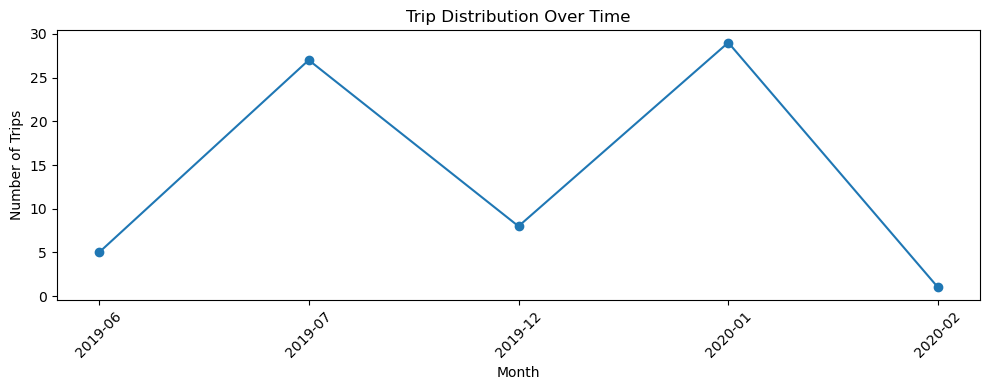

In [66]:
plt.figure(figsize=(10, 4))

plt.plot(
    monthly_trips.index.astype(str),
    monthly_trips.values,
    marker="o"
)

plt.xlabel("Month")
plt.ylabel("Number of Trips")
plt.title("Trip Distribution Over Time")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [67]:
timeline["Time Since Previous Trip"] = (
    timeline["Date"].diff()
)

display(
    timeline[
        ["Trip", "Date", "Time Since Previous Trip"]
    ]
)

,Trip,Date,Time Since Previous Trip
0,TripA01,2019-06-25 13:21:14,NaT
1,TripA02,2019-06-25 14:05:31,0 days 00:44:17
2,TripA03,2019-06-28 10:02:15,2 days 19:56:44
3,TripA04,2019-06-28 10:13:30,0 days 00:11:15
4,TripA05,2019-06-28 10:20:26,0 days 00:06:56
...,...,...,...
65,TripB34,2020-01-14 12:55:08,0 days 01:10:40
66,TripB35,2020-01-14 17:59:06,0 days 05:03:58
67,TripB36,2020-01-15 10:43:44,0 days 16:44:38
68,TripB37,2020-01-21 09:15:20,5 days 22:31:36


In [68]:
print(
    timeline["Time Since Previous Trip"]
    .describe()
)

count                            69
mean      3 days 06:54:04.173913043
std      16 days 17:15:55.100535719
min                 0 days 00:00:00
25%                 0 days 00:45:48
50%                 0 days 10:18:03
75%                 0 days 21:05:15
max               137 days 23:38:05
Name: Time Since Previous Trip, dtype: object


## 3. Energy Target Construction

Trip-level electrical energy and SOC-direction checks are examined before defining energy consumption. The modelling target is trip-level energy consumption in kWh/km, derived from net battery energy and trip distance—not a battery-SOH or degradation target.


In [69]:
# Inspect SOC coverage and trajectory statistics for all trips

soc_summary = []

for file in telemetry_files:
    trip = file.stem

    df = pd.read_csv(
        file,
        sep=";",
        encoding="cp1252"
    )

    soc = df["SoC [%]"]

    valid_soc = soc.dropna()

    soc_summary.append({
        "Trip": trip,
        "Rows": len(df),
        "Valid SOC": len(valid_soc),
        "Missing SOC": soc.isna().sum(),
        "Missing %": soc.isna().mean() * 100,
        "SOC Start": valid_soc.iloc[0] if len(valid_soc) else np.nan,
        "SOC End": valid_soc.iloc[-1] if len(valid_soc) else np.nan,
        "SOC Min": valid_soc.min() if len(valid_soc) else np.nan,
        "SOC Max": valid_soc.max() if len(valid_soc) else np.nan,
        "SOC Change": (
            valid_soc.iloc[0] - valid_soc.iloc[-1]
            if len(valid_soc) else np.nan
        )
    })

soc_summary = pd.DataFrame(soc_summary)

display(soc_summary)

,Trip,Rows,Valid SOC,Missing SOC,Missing %,SOC Start,SOC End,SOC Min,SOC Max,SOC Change
0,TripA01,10090,10090,0,0.000000,86.9,81.5,81.5,86.9,5.4
1,TripA02,14130,14130,0,0.000000,80.3,67.3,66.9,80.3,13.0
2,TripA03,6706,6706,0,0.000000,83.5,75.1,74.8,83.5,8.4
3,TripA04,4124,4124,0,0.000000,75.1,66.7,66.3,75.1,8.4
4,TripA05,13667,13667,0,0.000000,66.7,60.2,60.1,66.7,6.5
...,...,...,...,...,...,...,...,...,...,...
65,TripB34,7338,2931,4407,60.057236,73.9,71.3,71.3,73.9,2.6
66,TripB35,13626,13625,1,0.007339,85.4,71.5,71.5,85.4,13.9
67,TripB36,28523,28521,2,0.007012,72.1,44.5,44.4,72.1,27.6
68,TripB37,14173,14172,1,0.007056,83.8,68.0,68.0,83.8,15.8


In [70]:
display(
    soc_summary[
        [
            "SOC Start",
            "SOC End",
            "SOC Change",
            "SOC Min",
            "SOC Max"
        ]
    ].describe()
)

,SOC Start,SOC End,SOC Change,SOC Min,SOC Max
count,70.000000,70.000000,70.000000,70.000000,70.000000
mean,72.845714,59.205714,13.640000,58.347143,73.220000
std,14.496633,17.627382,12.229039,18.211437,14.102735
min,31.500000,0.000000,-24.100000,0.000000,31.500000
25%,67.400000,49.200000,7.950000,47.300000,67.425000
50%,75.300000,64.000000,12.000000,63.550000,75.300000
75%,84.700000,71.450000,16.025000,71.450000,84.700000
max,88.500000,82.900000,85.500000,82.900000,88.500000


In [ ]:
import numpy as np
import pandas as pd
from pathlib import Path

# ============================================================
# Estimate effective battery capacity from each trip
# ============================================================

trip_results = []

for trip_file in sorted(module_path.glob("Trip*.csv")):

    try:
        # Read telemetry
        df = pd.read_csv(
            trip_file,
            sep=";",
            encoding="cp1252"
        )

        # ----------------------------------------------------
        # Required columns
        # ----------------------------------------------------
        required_cols = [
            "Time [s]",
            "Battery Current [A]",
            "SoC [%]"
        ]

        if not all(col in df.columns for col in required_cols):
            print(f"Skipping {trip_file.name}: missing required columns")
            continue

        # ----------------------------------------------------
        # Extract required signals
        # ----------------------------------------------------
        time = pd.to_numeric(df["Time [s]"], errors="coerce")
        current = pd.to_numeric(
            df["Battery Current [A]"],
            errors="coerce"
        )
        soc = pd.to_numeric(
            df["SoC [%]"],
            errors="coerce"
        )

        # ----------------------------------------------------
        # Remove rows with missing values
        # ----------------------------------------------------
        valid = (
            time.notna()
            & current.notna()
            & soc.notna()
        )

        time = time[valid].to_numpy()
        current = current[valid].to_numpy()
        soc = soc[valid].to_numpy()

        # Need at least two points for integration
        if len(time) < 2:
            print(f"Skipping {trip_file.name}: insufficient data")
            continue

        # ----------------------------------------------------
        # SOC change
        # ----------------------------------------------------
        soc_start = soc[0]
        soc_end = soc[-1]

        soc_change = soc_start - soc_end

        # Convert SOC percentage points to fraction
        soc_change_fraction = abs(soc_change) / 100

        # ----------------------------------------------------
        # Battery charge/discharge throughput
        #
        # Integral of |current| over time gives Ah
        #
        # Q = integral(I dt) / 3600
        # ----------------------------------------------------
        charge_throughput_ah = (
            np.trapz(
                np.abs(current),
                time
            ) / 3600
        )

        # ----------------------------------------------------
        # Estimate effective capacity
        #
        # C_eff ≈ charge throughput / SOC fraction changed
        #
        # This is only a rough proxy because a trip is not
        # necessarily a complete battery cycle.
        # ----------------------------------------------------
        if soc_change_fraction > 0.01:
            estimated_capacity_ah = (
                charge_throughput_ah /
                soc_change_fraction
            )
        else:
            estimated_capacity_ah = np.nan

        # ----------------------------------------------------
        # Store results
        # ----------------------------------------------------
        trip_results.append({
            "Trip": trip_file.stem,
            "SOC Start [%]": soc_start,
            "SOC End [%]": soc_end,
            "SOC Change [percentage points]": soc_change,
            "Charge Throughput [Ah]": charge_throughput_ah,
            "Estimated Capacity [Ah]": estimated_capacity_ah,
            "Number of Valid Samples": len(time)
        })

    except Exception as e:
        print(f"Error processing {trip_file.name}: {e}")


# ============================================================
# Create results dataframe
# ============================================================

capacity_df = pd.DataFrame(trip_results)

print("Capacity estimation completed.")
print(f"Trips processed: {len(capacity_df)}")

display(capacity_df.head())

Capacity estimation completed.
Trips processed: 70


,Trip,SOC Start [%],SOC End [%],SOC Change [percentage points],Charge Throughput [Ah],Estimated Capacity [Ah],Number of Valid Samples
0,TripA01,86.9,81.5,5.4,5.308013,98.296533,10090
1,TripA02,80.3,67.3,13.0,16.484156,126.801199,14130
2,TripA03,83.5,75.1,8.4,7.530107,89.644127,6706
3,TripA04,75.1,66.7,8.4,6.509432,77.493236,4124
4,TripA05,66.7,60.2,6.5,7.556201,116.249241,13667


In [75]:
# ============================================================
# Inspect estimated capacity distribution
# ============================================================

print("Estimated Capacity Statistics")
print("=" * 50)

print(
    capacity_df["Estimated Capacity [Ah]"]
    .describe()
)

print("\nNumber of valid capacity estimates:")
print(
    capacity_df["Estimated Capacity [Ah]"]
    .notna()
    .sum()
)

print("\nNumber of invalid / unavailable estimates:")
print(
    capacity_df["Estimated Capacity [Ah]"]
    .isna()
    .sum()
)

Estimated Capacity Statistics
count     70.000000
mean      91.540470
std       21.216075
min       44.150476
25%       76.181069
50%       87.287618
75%      101.582507
max      170.054118
Name: Estimated Capacity [Ah], dtype: float64

Number of valid capacity estimates:
70

Number of invalid / unavailable estimates:
0


In [76]:
# ============================================================
# Identify suspicious capacity estimates
# ============================================================

capacity_df["Suspicious Capacity"] = (
    (capacity_df["Estimated Capacity [Ah]"] < 10)
    |
    (capacity_df["Estimated Capacity [Ah]"] > 100)
)

print("Suspicious estimates:")
display(
    capacity_df[
        capacity_df["Suspicious Capacity"]
    ][
        [
            "Trip",
            "SOC Start [%]",
            "SOC End [%]",
            "SOC Change [percentage points]",
            "Charge Throughput [Ah]",
            "Estimated Capacity [Ah]"
        ]
    ]
)

Suspicious estimates:


,Trip,SOC Start [%],SOC End [%],SOC Change [percentage points],Charge Throughput [Ah],Estimated Capacity [Ah]
1,TripA02,80.3,67.3,13.0,16.484156,126.801199
4,TripA05,66.7,60.2,6.5,7.556201,116.249241
7,TripA08,86.6,76.1,10.5,13.330471,126.956862
8,TripA09,74.7,68.6,6.1,6.164305,101.054180
10,TripA11,87.0,75.6,11.4,11.600482,101.758616
11,TripA12,75.5,64.3,11.2,12.808200,114.358925
13,TripA14,82.8,79.9,2.9,3.039570,104.812768
18,TripA19,88.5,80.4,8.1,9.108386,112.449213
20,TripA21,71.3,63.7,7.6,9.184927,120.854302
25,TripA26,86.2,78.8,7.4,9.931290,134.206625


In [77]:
# ============================================================
# Battery / SOC relationship audit
# ============================================================

trip_audit = []

for trip_file in sorted(module_path.glob("Trip*.csv")):

    try:
        df = pd.read_csv(
            trip_file,
            sep=";",
            encoding="cp1252"
        )

        required = [
            "Time [s]",
            "Battery Voltage [V]",
            "Battery Current [A]",
            "SoC [%]"
        ]

        if not all(col in df.columns for col in required):
            continue

        time = pd.to_numeric(df["Time [s]"], errors="coerce")
        voltage = pd.to_numeric(
            df["Battery Voltage [V]"],
            errors="coerce"
        )
        current = pd.to_numeric(
            df["Battery Current [A]"],
            errors="coerce"
        )
        soc = pd.to_numeric(
            df["SoC [%]"],
            errors="coerce"
        )

        valid = (
            time.notna()
            & voltage.notna()
            & current.notna()
            & soc.notna()
        )

        time = time[valid].to_numpy()
        voltage = voltage[valid].to_numpy()
        current = current[valid].to_numpy()
        soc = soc[valid].to_numpy()

        if len(time) < 2:
            continue

        # ----------------------------------------------------
        # SOC change
        # ----------------------------------------------------

        soc_start = soc[0]
        soc_end = soc[-1]
        soc_change = soc_end - soc_start

        # ----------------------------------------------------
        # Signed current integral
        # ----------------------------------------------------

        net_current_ah = (
            np.trapz(current, time) / 3600
        )

        # Absolute current throughput
        absolute_current_ah = (
            np.trapz(np.abs(current), time) / 3600
        )

        # ----------------------------------------------------
        # Electrical power
        # ----------------------------------------------------

        power_kw = voltage * current / 1000

        net_energy_kwh = (
            np.trapz(power_kw, time) / 3600
        )

        absolute_energy_kwh = (
            np.trapz(np.abs(power_kw), time) / 3600
        )

        # ----------------------------------------------------
        # Driving distance
        # ----------------------------------------------------

        distance_km = np.nan

        # Find matching overview row
        trip_name = trip_file.stem

        match = overview[
            overview["Trip"].astype(str).str.strip()
            == trip_name
        ]

        if len(match) == 1:
            distance_km = match.iloc[0]["Distance [km]"]

        # ----------------------------------------------------
        # Derived consumption metrics
        # ----------------------------------------------------

        if distance_km and distance_km > 0:
            energy_per_km = (
                abs(net_energy_kwh) / distance_km
            )
        else:
            energy_per_km = np.nan

        if abs(soc_change) > 0.5:
            energy_per_soc = (
                abs(net_energy_kwh) /
                abs(soc_change)
            )
        else:
            energy_per_soc = np.nan

        # ----------------------------------------------------
        # Store
        # ----------------------------------------------------

        trip_audit.append({
            "Trip": trip_name,
            "SOC Start [%]": soc_start,
            "SOC End [%]": soc_end,
            "SOC Change [pp]": soc_change,
            "Net Current [Ah]": net_current_ah,
            "Absolute Current [Ah]": absolute_current_ah,
            "Net Energy [kWh]": net_energy_kwh,
            "Absolute Energy [kWh]": absolute_energy_kwh,
            "Distance [km]": distance_km,
            "Energy [kWh/km]": energy_per_km,
            "Energy per SOC [kWh/pp]": energy_per_soc
        })

    except Exception as e:
        print(f"Error: {trip_file.name}: {e}")


battery_audit_df = pd.DataFrame(trip_audit)

print("Trips analysed:", len(battery_audit_df))

display(battery_audit_df.head(10))

Trips analysed: 70


,Trip,SOC Start [%],SOC End [%],SOC Change [pp],Net Current [Ah],Absolute Current [Ah],Net Energy [kWh],Absolute Energy [kWh],Distance [km],Energy [kWh/km],Energy per SOC [kWh/pp]
0,TripA01,86.9,81.5,-5.4,-3.350259,5.308013,-1.289181,2.056004,7.427690,0.173564,0.238737
1,TripA02,80.3,67.3,-13.0,-8.000599,16.484156,-2.934639,6.235537,23.509709,0.124827,0.225741
2,TripA03,83.5,75.1,-8.4,-5.200250,7.530107,-1.954406,2.864096,12.820846,0.152440,0.232667
3,TripA04,75.1,66.7,-8.4,-5.161216,6.509432,-1.899911,2.420973,10.727491,0.177107,0.226180
4,TripA05,66.7,60.2,-6.5,-4.021570,7.556201,-1.504167,2.855926,12.393223,0.121370,0.231410
5,TripA06,85.1,63.4,-21.7,-13.229150,19.456229,-5.022637,7.440021,45.993461,0.109203,0.231458
6,TripA07,63.4,34.2,-29.2,-17.985796,22.157742,-6.550272,8.108219,44.335916,0.147742,0.224324
7,TripA08,86.6,76.1,-10.5,-6.430464,13.330471,-2.449564,5.147672,18.228627,0.134380,0.233292
8,TripA09,74.7,68.6,-6.1,-3.754667,6.164305,-1.432895,2.365652,11.661272,0.122876,0.234901
9,TripA10,69.6,60.9,-8.7,-5.390766,7.362223,-2.020156,2.772627,16.246007,0.124348,0.232202


In [78]:
# ============================================================
# Summary statistics
# ============================================================

battery_audit_df.describe()

,SOC Start [%],SOC End [%],SOC Change [pp],Net Current [Ah],Absolute Current [Ah],Net Energy [kWh],Absolute Energy [kWh],Distance [km],Energy [kWh/km],Energy per SOC [kWh/pp]
count,70.000000,70.000000,70.000000,70.000000,70.000000,70.000000,70.000000,70.000000,70.000000,70.000000
mean,72.845714,59.205714,-13.640000,-8.206644,12.336253,-2.974586,4.558680,19.354558,0.165054,0.227569
std,14.496633,17.627382,12.229039,5.995511,7.704874,2.177049,2.797703,11.615868,0.042613,0.017809
min,31.500000,0.000000,-85.500000,-31.429948,1.777819,-11.260721,0.677430,2.782300,0.067874,0.131704
25%,67.400000,49.200000,-16.025000,-9.979461,7.536630,-3.627362,2.857969,12.500129,0.135271,0.223274
50%,75.300000,64.000000,-12.000000,-7.418351,10.347703,-2.682036,3.854464,16.502600,0.163716,0.228918
75%,84.700000,71.450000,-7.950000,-4.901570,14.145546,-1.800283,5.138940,19.340116,0.191241,0.232847
max,88.500000,82.900000,24.100000,14.031037,40.812988,5.783560,14.646073,60.974700,0.348506,0.297975


In [79]:
# ============================================================
# Inspect unusual SOC behaviour
# ============================================================

print("Trips where SOC increased:")
display(
    battery_audit_df[
        battery_audit_df["SOC Change [pp]"] > 1
    ][
        [
            "Trip",
            "SOC Start [%]",
            "SOC End [%]",
            "SOC Change [pp]",
            "Net Current [Ah]",
            "Net Energy [kWh]",
            "Distance [km]"
        ]
    ]
)

print("\nTrips with very high estimated energy consumption:")
display(
    battery_audit_df[
        battery_audit_df["Energy [kWh/km]"] > 1
    ][
        [
            "Trip",
            "SOC Change [pp]",
            "Net Energy [kWh]",
            "Distance [km]",
            "Energy [kWh/km]"
        ]
    ]
)

Trips where SOC increased:


,Trip,SOC Start [%],SOC End [%],SOC Change [pp],Net Current [Ah],Net Energy [kWh],Distance [km]
35,TripB04,45.1,69.2,24.1,14.031037,5.78356,16.5953



Trips with very high estimated energy consumption:


,Trip,SOC Change [pp],Net Energy [kWh],Distance [km],Energy [kWh/km]


In [80]:
# ============================================================
# Energy Consumption Target Analysis
# ============================================================

energy_df = battery_audit_df[
    [
        "Trip",
        "SOC Start [%]",
        "SOC End [%]",
        "SOC Change [pp]",
        "Net Energy [kWh]",
        "Absolute Energy [kWh]",
        "Distance [km]",
        "Energy [kWh/km]"
    ]
].copy()

# Convert energy to positive consumption
energy_df["Energy Consumption [kWh]"] = (
    energy_df["Net Energy [kWh]"].abs()
)

energy_df["Energy Consumption [kWh/km]"] = (
    energy_df["Energy Consumption [kWh]"]
    / energy_df["Distance [km]"]
)

print("Energy Consumption Target Statistics")
print("=" * 55)

print(
    energy_df[
        [
            "Energy Consumption [kWh]",
            "Energy Consumption [kWh/km]"
        ]
    ].describe()
)

Energy Consumption Target Statistics
       Energy Consumption [kWh]  Energy Consumption [kWh/km]
count                 70.000000                    70.000000
mean                   3.139830                     0.165054
std                    1.927311                     0.042613
min                    0.435264                     0.067874
25%                    1.871129                     0.135271
50%                    2.754691                     0.163716
75%                    3.677539                     0.191241
max                   11.260721                     0.348506


In [81]:
# ============================================================
# Lowest and highest energy-consuming trips
# ============================================================

print("Lowest energy consumption:")
display(
    energy_df.sort_values(
        "Energy Consumption [kWh/km]"
    ).head(10)
)

print("\nHighest energy consumption:")
display(
    energy_df.sort_values(
        "Energy Consumption [kWh/km]",
        ascending=False
    ).head(10)
)

Lowest energy consumption:


,Trip,SOC Start [%],SOC End [%],SOC Change [pp],Net Energy [kWh],Absolute Energy [kWh],Distance [km],Energy [kWh/km],Energy Consumption [kWh],Energy Consumption [kWh/km]
65,TripB34,73.9,71.3,-2.6,-0.620581,0.677430,9.143200,0.067874,0.620581,0.067874
40,TripB09,70.0,46.0,-24.0,-4.759262,14.646073,54.182500,0.087838,4.759262,0.087838
25,TripA26,86.2,78.8,-7.4,-1.726815,3.828613,18.032233,0.095763,1.726815,0.095763
14,TripA15,74.8,63.4,-11.4,-2.665912,3.947706,26.973501,0.098834,2.665912,0.098834
28,TripA29,70.9,63.1,-7.8,-1.779866,3.662715,16.332609,0.108976,1.779866,0.108976
5,TripA06,85.1,63.4,-21.7,-5.022637,7.440021,45.993461,0.109203,5.022637,0.109203
18,TripA19,88.5,80.4,-8.1,-1.920658,3.520883,16.730382,0.114801,1.920658,0.114801
27,TripA28,81.9,72.0,-9.9,-2.320283,4.104951,19.515316,0.118895,2.320283,0.118895
4,TripA05,66.7,60.2,-6.5,-1.504167,2.855926,12.393223,0.121370,1.504167,0.121370
20,TripA21,71.3,63.7,-7.6,-1.744471,3.477591,14.323605,0.121790,1.744471,0.121790



Highest energy consumption:


,Trip,SOC Start [%],SOC End [%],SOC Change [pp],Net Energy [kWh],Absolute Energy [kWh],Distance [km],Energy [kWh/km],Energy Consumption [kWh],Energy Consumption [kWh/km]
35,TripB04,45.1,69.2,24.1,5.783560,13.383029,16.5953,0.348506,5.783560,0.348506
33,TripB02,81.0,66.2,-14.8,-4.410032,5.918965,18.9260,0.233014,4.410032,0.233014
54,TripB23,72.1,53.5,-18.6,-4.074609,4.908354,18.7051,0.217834,4.074609,0.217834
63,TripB32,52.6,38.1,-14.5,-3.095867,3.655334,14.2409,0.217393,3.095867,0.217393
60,TripB29,31.5,15.4,-16.1,-3.360732,4.132740,15.8334,0.212256,3.360732,0.212256
61,TripB30,84.2,70.4,-13.8,-3.136299,3.525795,14.8606,0.211048,3.136299,0.211048
49,TripB18,82.8,68.1,-14.7,-3.329099,3.586209,15.8136,0.210521,3.329099,0.210521
62,TripB31,72.1,57.8,-14.3,-3.203007,3.653410,15.2414,0.210152,3.203007,0.210152
68,TripB37,83.8,68.0,-15.8,-3.667473,4.386940,17.4626,0.210019,3.667473,0.210019
46,TripB15,85.1,67.5,-17.6,-4.026008,5.346585,19.2393,0.209260,4.026008,0.209260


In [82]:
# ============================================================
# Compare net vs absolute energy
# ============================================================

energy_df["Regeneration Difference [kWh]"] = (
    energy_df["Absolute Energy [kWh]"]
    - energy_df["Energy Consumption [kWh]"]
)

display(
    energy_df.sort_values(
        "Regeneration Difference [kWh]",
        ascending=False
    ).head(10)
)

,Trip,SOC Start [%],SOC End [%],SOC Change [pp],Net Energy [kWh],Absolute Energy [kWh],Distance [km],Energy [kWh/km],Energy Consumption [kWh],Energy Consumption [kWh/km],Regeneration Difference [kWh]
40,TripB09,70.0,46.0,-24.0,-4.759262,14.646073,54.182500,0.087838,4.759262,0.087838,9.886811
35,TripB04,45.1,69.2,24.1,5.783560,13.383029,16.595300,0.348506,5.783560,0.348506,7.599468
32,TripB01,86.1,57.4,-28.7,-6.404801,10.122783,38.791800,0.165107,6.404801,0.165107,3.717982
1,TripA02,80.3,67.3,-13.0,-2.934639,6.235537,23.509709,0.124827,2.934639,0.124827,3.300898
7,TripA08,86.6,76.1,-10.5,-2.449564,5.147672,18.228627,0.134380,2.449564,0.134380,2.698108
5,TripA06,85.1,63.4,-21.7,-5.022637,7.440021,45.993461,0.109203,5.022637,0.109203,2.417384
45,TripB14,85.5,0.0,-85.5,-11.260721,13.625512,60.974700,0.184679,11.260721,0.184679,2.364791
26,TripA27,78.5,66.8,-11.7,-2.698160,5.062345,20.429845,0.132070,2.698160,0.132070,2.364185
11,TripA12,75.5,64.3,-11.2,-2.579156,4.851956,18.653903,0.138264,2.579156,0.138264,2.272801
25,TripA26,86.2,78.8,-7.4,-1.726815,3.828613,18.032233,0.095763,1.726815,0.095763,2.101798


In [83]:
# ============================================================
# Final target validation
# ============================================================

target_df = battery_audit_df.copy()

# Positive energy consumption for discharge-dominant trips
target_df["Energy Consumption [kWh]"] = (
    -target_df["Net Energy [kWh]"]
)

target_df["Energy Consumption [kWh/km]"] = (
    target_df["Energy Consumption [kWh]"]
    / target_df["Distance [km]"]
)

# Classify trips according to battery energy direction
target_df["Energy Direction"] = np.where(
    target_df["Net Energy [kWh]"] < 0,
    "Discharge",
    "Charge / Net Positive"
)

print("Energy direction:")
print(
    target_df["Energy Direction"]
    .value_counts()
)

print("\nNet-positive trips:")
display(
    target_df[
        target_df["Net Energy [kWh]"] >= 0
    ][
        [
            "Trip",
            "SOC Start [%]",
            "SOC End [%]",
            "SOC Change [pp]",
            "Net Energy [kWh]",
            "Distance [km]"
        ]
    ]
)

Energy direction:
Energy Direction
Discharge                69
Charge / Net Positive     1
Name: count, dtype: int64

Net-positive trips:


,Trip,SOC Start [%],SOC End [%],SOC Change [pp],Net Energy [kWh],Distance [km]
35,TripB04,45.1,69.2,24.1,5.78356,16.5953


In [84]:
# ============================================================
# Target statistics for discharge-dominant trips
# ============================================================

discharge_df = target_df[
    target_df["Net Energy [kWh]"] < 0
].copy()

print("Discharge-dominant trips:", len(discharge_df))

print("\nEnergy Consumption [kWh/km]")
print("=" * 50)

print(
    discharge_df[
        "Energy Consumption [kWh/km]"
    ].describe()
)

Discharge-dominant trips: 69

Energy Consumption [kWh/km]
count    69.000000
mean      0.162395
std       0.036612
min       0.067874
25%       0.134380
50%       0.162325
75%       0.191109
max       0.233014
Name: Energy Consumption [kWh/km], dtype: float64


In [85]:
# ============================================================
# Identify extreme target values
# ============================================================

display(
    discharge_df.sort_values(
        "Energy Consumption [kWh/km]"
    )[
        [
            "Trip",
            "Distance [km]",
            "SOC Change [pp]",
            "Net Energy [kWh]",
            "Energy Consumption [kWh/km]"
        ]
    ].head(10)
)

display(
    discharge_df.sort_values(
        "Energy Consumption [kWh/km]",
        ascending=False
    )[
        [
            "Trip",
            "Distance [km]",
            "SOC Change [pp]",
            "Net Energy [kWh]",
            "Energy Consumption [kWh/km]"
        ]
    ].head(10)
)

,Trip,Distance [km],SOC Change [pp],Net Energy [kWh],Energy Consumption [kWh/km]
65,TripB34,9.143200,-2.6,-0.620581,0.067874
40,TripB09,54.182500,-24.0,-4.759262,0.087838
25,TripA26,18.032233,-7.4,-1.726815,0.095763
14,TripA15,26.973501,-11.4,-2.665912,0.098834
28,TripA29,16.332609,-7.8,-1.779866,0.108976
5,TripA06,45.993461,-21.7,-5.022637,0.109203
18,TripA19,16.730382,-8.1,-1.920658,0.114801
27,TripA28,19.515316,-9.9,-2.320283,0.118895
4,TripA05,12.393223,-6.5,-1.504167,0.121370
20,TripA21,14.323605,-7.6,-1.744471,0.121790


,Trip,Distance [km],SOC Change [pp],Net Energy [kWh],Energy Consumption [kWh/km]
33,TripB02,18.9260,-14.8,-4.410032,0.233014
54,TripB23,18.7051,-18.6,-4.074609,0.217834
63,TripB32,14.2409,-14.5,-3.095867,0.217393
60,TripB29,15.8334,-16.1,-3.360732,0.212256
61,TripB30,14.8606,-13.8,-3.136299,0.211048
49,TripB18,15.8136,-14.7,-3.329099,0.210521
62,TripB31,15.2414,-14.3,-3.203007,0.210152
68,TripB37,17.4626,-15.8,-3.667473,0.210019
46,TripB15,19.2393,-17.6,-4.026008,0.209260
41,TripB10,47.8391,-45.8,-9.994145,0.208912


In [86]:
# ============================================================
# Check missing / invalid energy targets
# ============================================================

print("Missing energy targets:")
display(
    target_df[
        target_df["Energy Consumption [kWh/km]"].isna()
    ][
        [
            "Trip",
            "Net Energy [kWh]",
            "Distance [km]",
            "SOC Start [%]",
            "SOC End [%]"
        ]
    ]
)

Missing energy targets:


,Trip,Net Energy [kWh],Distance [km],SOC Start [%],SOC End [%]


In [87]:
# ============================================================
# Check all target values are physically valid
# ============================================================

print("Invalid target values:")

display(
    target_df[
        (
            target_df["Energy Consumption [kWh/km]"] <= 0
        )
        |
        (
            ~np.isfinite(
                target_df["Energy Consumption [kWh/km]"]
            )
        )
    ][
        [
            "Trip",
            "Net Energy [kWh]",
            "Distance [km]",
            "Energy Consumption [kWh/km]"
        ]
    ]
)

Invalid target values:


,Trip,Net Energy [kWh],Distance [km],Energy Consumption [kWh/km]
35,TripB04,5.78356,16.5953,-0.348506


## 4. Feature Engineering and Audit

Candidate telemetry and context predictors are summarized at trip level, then inspected for missingness, constants, redundancy, and potential target leakage. The later rebuild and consistency-check cells resolve data-quality issues before the final 67-trip modelling dataset is established.


In [88]:
# ============================================================
# Candidate Feature Availability Audit
# ============================================================

candidate_features = [
    # Driving
    "Velocity [km/h]",
    "Elevation [m]",
    "Throttle [%]",
    "Motor Torque [Nm]",
    "Longitudinal Acceleration [m/s^2]",
    "Regenerative Braking Signal",

    # Battery
    "Battery Voltage [V]",
    "Battery Current [A]",
    "Battery Temperature [°C]",
    "max. Battery Temperature [°C]",
    "SoC [%]",
    "displayed SoC [%]",
    "min. SoC [%]",
    "max. SoC [%)",

    # HVAC / thermal
    "Heating Power CAN [kW]",
    "Heating Power LIN [W]",
    "Requested Heating Power [W]",
    "AirCon Power [kW]",
    "Heater Signal",
    "Heater Voltage [V]",
    "Heater Current [A]",

    # Environment
    "Ambient Temperature [°C]",
    "Coolant Temperature Heatercore [°C]",
    "Requested Coolant Temperature [°C]",
    "Coolant Temperature Inlet [°C]",
    "Heat Exchanger Temperature [°C]",
    "Cabin Temperature Sensor [°C]"
]

feature_audit = []

for col in candidate_features:

    trips_with_column = 0
    trips_with_data = 0
    total_missing = 0
    total_values = 0

    for trip_file in sorted(module_path.glob("Trip*.csv")):

        try:
            df = pd.read_csv(
                trip_file,
                sep=";",
                encoding="cp1252"
            )

            if col not in df.columns:
                continue

            trips_with_column += 1

            values = pd.to_numeric(
                df[col],
                errors="coerce"
            )

            n_missing = values.isna().sum()
            n_valid = values.notna().sum()

            total_missing += n_missing
            total_values += len(values)

            if n_valid > 0:
                trips_with_data += 1

        except Exception:
            pass

    missing_pct = (
        100 * total_missing / total_values
        if total_values > 0
        else np.nan
    )

    feature_audit.append({
        "Feature": col,
        "Trips with column": trips_with_column,
        "Trips with data": trips_with_data,
        "Total values": total_values,
        "Missing values": total_missing,
        "Missing [%]": missing_pct
    })


feature_audit_df = pd.DataFrame(feature_audit)

display(
    feature_audit_df.sort_values(
        ["Trips with data", "Missing [%]"],
        ascending=[False, True]
    )
)

,Feature,Trips with column,Trips with data,Total values,Missing values,Missing [%]
1,Elevation [m],70,70,1094793,0,0.000000
2,Throttle [%],70,70,1094793,0,0.000000
3,Motor Torque [Nm],70,70,1094793,0,0.000000
4,Longitudinal Acceleration [m/s^2],70,70,1094793,0,0.000000
6,Battery Voltage [V],70,70,1094793,0,0.000000
7,Battery Current [A],70,70,1094793,0,0.000000
8,Battery Temperature [°C],70,70,1094793,0,0.000000
9,max. Battery Temperature [°C],70,70,1094793,0,0.000000
14,Heating Power CAN [kW],70,70,1094793,0,0.000000
16,Requested Heating Power [W],70,70,1094793,0,0.000000


In [89]:
# ============================================================
# Trip-Level Feature Engineering
# ============================================================

def safe_stats(series, prefix):
    """
    Calculate robust summary statistics for one telemetry signal.
    """
    
    x = pd.to_numeric(series, errors="coerce").dropna()

    if len(x) == 0:
        return {
            f"{prefix}_mean": np.nan,
            f"{prefix}_std": np.nan,
            f"{prefix}_min": np.nan,
            f"{prefix}_max": np.nan,
            f"{prefix}_median": np.nan
        }

    return {
        f"{prefix}_mean": x.mean(),
        f"{prefix}_std": x.std(),
        f"{prefix}_min": x.min(),
        f"{prefix}_max": x.max(),
        f"{prefix}_median": x.median()
    }


trip_features = []

for trip_file in sorted(module_path.glob("Trip*.csv")):

    trip_name = trip_file.stem

    try:
        df = pd.read_csv(
            trip_file,
            sep=";",
            encoding="cp1252"
        )

        row = {
            "Trip": trip_name
        }

        # ----------------------------------------------------
        # Basic trip information
        # ----------------------------------------------------

        match = overview[
            overview["Trip"].astype(str).str.strip()
            == trip_name
        ]

        if len(match) != 1:
            print(f"Overview mismatch: {trip_name}")
            continue

        overview_row = match.iloc[0]

        row["Distance [km]"] = overview_row["Distance [km]"]
        row["Duration [min]"] = overview_row["Duration [min]"]

        # ----------------------------------------------------
        # Driving features
        # ----------------------------------------------------

        driving_columns = {
            "Velocity [km/h]": "speed",
            "Elevation [m]": "elevation",
            "Throttle [%]": "throttle",
            "Motor Torque [Nm]": "torque",
            "Longitudinal Acceleration [m/s^2]": "acceleration"
        }

        for column, prefix in driving_columns.items():

            if column in df.columns:
                row.update(
                    safe_stats(df[column], prefix)
                )

        # ----------------------------------------------------
        # Speed-specific features
        # ----------------------------------------------------

        if "Velocity [km/h]" in df.columns:

            speed = pd.to_numeric(
                df["Velocity [km/h]"],
                errors="coerce"
            ).dropna()

            if len(speed) > 0:

                row["speed_stationary_fraction"] = (
                    (speed <= 1).mean()
                )

                row["speed_above_50_fraction"] = (
                    (speed >= 50).mean()
                )

        # ----------------------------------------------------
        # Acceleration-specific features
        # ----------------------------------------------------

        if "Longitudinal Acceleration [m/s^2]" in df.columns:

            accel = pd.to_numeric(
                df["Longitudinal Acceleration [m/s^2]"],
                errors="coerce"
            ).dropna()

            if len(accel) > 0:

                row["hard_acceleration_fraction"] = (
                    (accel >= 2).mean()
                )

                row["hard_deceleration_fraction"] = (
                    (accel <= -2).mean()
                )

                row["jerk_mean_abs"] = (
                    np.abs(np.diff(accel)).mean()
                    if len(accel) > 1
                    else np.nan
                )

        # ----------------------------------------------------
        # Battery features
        # ----------------------------------------------------

        battery_columns = {
            "Battery Voltage [V]": "battery_voltage",
            "Battery Current [A]": "battery_current",
            "Battery Temperature [°C]": "battery_temp",
            "max. Battery Temperature [°C]":
                "battery_temp_max",
            "SoC [%]": "soc"
        }

        for column, prefix in battery_columns.items():

            if column in df.columns:
                row.update(
                    safe_stats(df[column], prefix)
                )

        # ----------------------------------------------------
        # SOC-specific features
        # ----------------------------------------------------

        if "SoC [%]" in df.columns:

            soc = pd.to_numeric(
                df["SoC [%]"],
                errors="coerce"
            ).dropna()

            if len(soc) > 1:

                row["soc_start"] = soc.iloc[0]
                row["soc_end"] = soc.iloc[-1]
                row["soc_change"] = (
                    soc.iloc[-1] - soc.iloc[0]
                )

        # ----------------------------------------------------
        # HVAC / thermal features
        # ----------------------------------------------------

        hvac_columns = {
            "Heating Power CAN [kW]":
                "heating_power",
            "Requested Heating Power [W]":
                "requested_heating",
            "AirCon Power [kW]":
                "aircon_power",
            "Heater Signal":
                "heater_signal",
            "Heat Exchanger Temperature [°C]":
                "heat_exchanger_temp",
            "Cabin Temperature Sensor [°C]":
                "cabin_temp",
            "Ambient Temperature [°C]":
                "ambient_temp"
        }

        for column, prefix in hvac_columns.items():

            if column in df.columns:
                row.update(
                    safe_stats(df[column], prefix)
                )

        # ----------------------------------------------------
        # HVAC usage fractions
        # ----------------------------------------------------

        if "Heater Signal" in df.columns:

            heater = pd.to_numeric(
                df["Heater Signal"],
                errors="coerce"
            ).dropna()

            if len(heater) > 0:

                row["heater_active_fraction"] = (
                    (heater > 0).mean()
                )

        # ----------------------------------------------------
        # Target
        # ----------------------------------------------------

        target_match = target_df[
            target_df["Trip"] == trip_name
        ]

        if len(target_match) == 1:

            net_energy = target_match.iloc[0][
                "Net Energy [kWh]"
            ]

            distance = target_match.iloc[0][
                "Distance [km]"
            ]

            if net_energy < 0 and distance > 0:

                row["Energy Consumption [kWh/km]"] = (
                    -net_energy / distance
                )

            else:
                row["Energy Consumption [kWh/km]"] = np.nan

        trip_features.append(row)

    except Exception as e:

        print(
            f"Error processing {trip_name}: {e}"
        )


features_df = pd.DataFrame(trip_features)

print(
    "Feature dataset shape:",
    features_df.shape
)

display(features_df.head())

Feature dataset shape: (70, 98)


,Trip,Distance [km],Duration [min],speed_mean,speed_std,speed_min,speed_max,speed_median,elevation_mean,elevation_std,...,cabin_temp_min,cabin_temp_max,cabin_temp_median,ambient_temp_mean,ambient_temp_std,ambient_temp_min,ambient_temp_max,ambient_temp_median,heater_active_fraction,Energy Consumption [kWh/km]
0,TripA01,7.427690,16.820000,26.502170,15.497032,0.00,53.30,29.550,566.791625,5.577563,...,22.17,25.84,24.00,30.769972,1.619032,25.50,33.5,31.0,1.0,0.173564
1,TripA02,23.509709,23.550000,59.909267,32.868059,1.11,132.70,49.215,561.721151,11.696280,...,19.84,23.34,22.34,31.127573,0.693260,29.50,32.5,31.0,1.0,0.124827
2,TripA03,12.820846,11.180000,68.826493,38.047229,0.00,143.82,76.070,578.935567,4.536659,...,22.84,27.01,24.84,23.334916,0.770235,21.50,24.5,23.5,1.0,0.152440
3,TripA04,10.727491,6.870000,93.645415,41.693047,0.00,136.94,112.425,582.000000,0.000000,...,21.84,23.00,22.00,24.423957,0.180969,23.51,24.5,24.5,1.0,0.177107
4,TripA05,12.393223,22.776667,32.646337,18.151337,0.00,80.83,32.870,568.957137,2.547320,...,22.00,24.50,23.34,24.587443,0.549129,23.50,26.0,24.5,1.0,0.121370


In [90]:
# ============================================================
# Feature Dataset Quality Check
# ============================================================

print("Rows:", len(features_df))
print("Columns:", len(features_df.columns))

print("\nMissing values:")
display(
    features_df.isna().sum()
    .sort_values(ascending=False)
    .head(20)
)

print("\nTarget:")
print(
    features_df[
        "Energy Consumption [kWh/km]"
    ].describe()
)

Rows: 70
Columns: 98

Missing values:


Energy Consumption [kWh/km]    1
speed_min                      1
speed_above_50_fraction        1
speed_median                   1
speed_max                      1
speed_stationary_fraction      1
speed_std                      1
speed_mean                     1
requested_heating_mean         0
aircon_power_median            0
aircon_power_max               0
aircon_power_min               0
aircon_power_std               0
aircon_power_mean              0
requested_heating_median       0
requested_heating_max          0
requested_heating_min          0
requested_heating_std          0
heating_power_median           0
heating_power_max              0
dtype: int64


Target:
count    69.000000
mean      0.162395
std       0.036612
min       0.067874
25%       0.134380
50%       0.162325
75%       0.191109
max       0.233014
Name: Energy Consumption [kWh/km], dtype: float64


In [91]:
# ============================================================
# Create modeling dataset
# ============================================================

model_df = features_df[
    features_df["Energy Consumption [kWh/km]"].notna()
].copy()

print("Modeling dataset shape:", model_df.shape)

print("\nMissing values after removing B04:")
missing_model = (
    model_df.isna()
    .sum()
    .sort_values(ascending=False)
)

display(
    missing_model[missing_model > 0]
)

Modeling dataset shape: (69, 98)

Missing values after removing B04:


speed_stationary_fraction    1
speed_mean                   1
speed_std                    1
speed_min                    1
speed_max                    1
speed_median                 1
speed_above_50_fraction      1
dtype: int64

In [92]:
# ============================================================
# Separate target from predictors
# ============================================================

target_col = "Energy Consumption [kWh/km]"

X = model_df.drop(
    columns=["Trip", target_col]
)

y = model_df[target_col]

print("X shape:", X.shape)
print("y shape:", y.shape)

display(X.head())

X shape: (69, 96)
y shape: (69,)


,Distance [km],Duration [min],speed_mean,speed_std,speed_min,speed_max,speed_median,elevation_mean,elevation_std,elevation_min,...,cabin_temp_std,cabin_temp_min,cabin_temp_max,cabin_temp_median,ambient_temp_mean,ambient_temp_std,ambient_temp_min,ambient_temp_max,ambient_temp_median,heater_active_fraction
0,7.427690,16.820000,26.502170,15.497032,0.00,53.30,29.550,566.791625,5.577563,558.0,...,1.249755,22.17,25.84,24.00,30.769972,1.619032,25.50,33.5,31.0,1.0
1,23.509709,23.550000,59.909267,32.868059,1.11,132.70,49.215,561.721151,11.696280,546.0,...,1.053332,19.84,23.34,22.34,31.127573,0.693260,29.50,32.5,31.0,1.0
2,12.820846,11.180000,68.826493,38.047229,0.00,143.82,76.070,578.935567,4.536659,572.0,...,1.362068,22.84,27.01,24.84,23.334916,0.770235,21.50,24.5,23.5,1.0
3,10.727491,6.870000,93.645415,41.693047,0.00,136.94,112.425,582.000000,0.000000,582.0,...,0.348660,21.84,23.00,22.00,24.423957,0.180969,23.51,24.5,24.5,1.0
4,12.393223,22.776667,32.646337,18.151337,0.00,80.83,32.870,568.957137,2.547320,563.0,...,0.582391,22.00,24.50,23.34,24.587443,0.549129,23.50,26.0,24.5,1.0


In [93]:
# ============================================================
# Feature groups
# ============================================================

driving_features = [
    col for col in X.columns
    if any(key in col for key in [
        "speed_",
        "elevation_",
        "throttle_",
        "torque_",
        "acceleration_",
        "hard_acceleration",
        "hard_deceleration",
        "jerk_"
    ])
]

environment_features = [
    col for col in X.columns
    if any(key in col for key in [
        "ambient_",
        "cabin_temp",
        "heat_exchanger_temp"
    ])
]

hvac_features = [
    col for col in X.columns
    if any(key in col for key in [
        "heating_",
        "requested_heating",
        "aircon_",
        "heater_"
    ])
]

battery_features = [
    col for col in X.columns
    if any(key in col for key in [
        "battery_",
        "soc"
    ])
]

print("Driving features:", len(driving_features))
print("Environment features:", len(environment_features))
print("HVAC features:", len(hvac_features))
print("Battery features:", len(battery_features))

Driving features: 30
Environment features: 15
HVAC features: 21
Battery features: 28


In [94]:
# ============================================================
# Display feature groups
# ============================================================

print("\nDRIVING")
print(driving_features)

print("\nENVIRONMENT")
print(environment_features)

print("\nHVAC")
print(hvac_features)

print("\nBATTERY")
print(battery_features)


DRIVING
['speed_mean', 'speed_std', 'speed_min', 'speed_max', 'speed_median', 'elevation_mean', 'elevation_std', 'elevation_min', 'elevation_max', 'elevation_median', 'throttle_mean', 'throttle_std', 'throttle_min', 'throttle_max', 'throttle_median', 'torque_mean', 'torque_std', 'torque_min', 'torque_max', 'torque_median', 'acceleration_mean', 'acceleration_std', 'acceleration_min', 'acceleration_max', 'acceleration_median', 'speed_stationary_fraction', 'speed_above_50_fraction', 'hard_acceleration_fraction', 'hard_deceleration_fraction', 'jerk_mean_abs']

ENVIRONMENT
['heat_exchanger_temp_mean', 'heat_exchanger_temp_std', 'heat_exchanger_temp_min', 'heat_exchanger_temp_max', 'heat_exchanger_temp_median', 'cabin_temp_mean', 'cabin_temp_std', 'cabin_temp_min', 'cabin_temp_max', 'cabin_temp_median', 'ambient_temp_mean', 'ambient_temp_std', 'ambient_temp_min', 'ambient_temp_max', 'ambient_temp_median']

HVAC
['heating_power_mean', 'heating_power_std', 'heating_power_min', 'heating_power_

.

In [95]:
# ============================================================
# Find the remaining row with missing speed features
# ============================================================

speed_missing = model_df[
    model_df["speed_mean"].isna()
]

display(
    speed_missing[
        [
            "Trip",
            "Distance [km]",
            "Duration [min]",
            "Energy Consumption [kWh/km]"
        ]
    ]
)

,Trip,Distance [km],Duration [min],Energy Consumption [kWh/km]
69,TripB38,18.9022,27.38,0.185535


In [96]:
model_df = model_df[
    model_df["Trip"] != "TripB04"
].copy()

print("Final modeling rows:", len(model_df))

Final modeling rows: 69


In [97]:
target_col = "Energy Consumption [kWh/km]"

X = model_df.drop(
    columns=["Trip", target_col]
)

y = model_df[target_col]

print("X:", X.shape)
print("y:", y.shape)

print("\nRemaining missing values:")
display(
    X.isna().sum()
    .sort_values(ascending=False)
    .head(10)
)

X: (69, 96)
y: (69,)

Remaining missing values:


speed_above_50_fraction      1
speed_mean                   1
speed_std                    1
speed_min                    1
speed_max                    1
speed_median                 1
speed_stationary_fraction    1
requested_heating_median     0
requested_heating_std        0
requested_heating_min        0
dtype: int64

In [98]:
# ============================================================
# Feature variance analysis
# ============================================================

feature_variance = X.var(
    numeric_only=True
).sort_values()

display(
    feature_variance.head(20)
)

throttle_min                  0.000000
heater_signal_std             0.000000
hard_deceleration_fraction    0.000009
hard_acceleration_fraction    0.000084
jerk_mean_abs                 0.000269
acceleration_mean             0.001206
acceleration_median           0.001717
speed_stationary_fraction     0.006332
aircon_power_min              0.006605
acceleration_std              0.012960
speed_min                     0.018119
aircon_power_std              0.027638
speed_above_50_fraction       0.039078
heater_signal_mean            0.068201
heater_signal_max             0.068201
heater_signal_median          0.068201
heater_signal_min             0.068201
heater_active_fraction        0.068201
aircon_power_median           0.077417
aircon_power_mean             0.093458
dtype: float64

In [99]:
# ============================================================
# Identify constant features
# ============================================================

constant_features = [
    col
    for col in X.columns
    if X[col].nunique(dropna=False) <= 1
]

print("Constant features:", len(constant_features))

print(constant_features)

Constant features: 2
['throttle_min', 'heater_signal_std']


In [100]:
X_reduced = X.drop(
    columns=constant_features
)

print(
    "Features after removing constants:",
    X_reduced.shape[1]
)

Features after removing constants: 94


In [101]:
# ============================================================
# Highly correlated predictor pairs
# ============================================================

corr_matrix = X_reduced.corr().abs()

upper = corr_matrix.where(
    np.triu(
        np.ones(corr_matrix.shape),
        k=1
    ).astype(bool)
)

high_corr_pairs = (
    upper
    .stack()
    .sort_values(ascending=False)
)

high_corr_pairs = high_corr_pairs[
    high_corr_pairs > 0.95
]

print(
    "Highly correlated feature pairs (|r| > 0.95):",
    len(high_corr_pairs)
)

display(
    high_corr_pairs.head(50)
)

Highly correlated feature pairs (|r| > 0.95): 48


heater_signal_mean        heater_signal_max             1.000000
heater_signal_median      heater_active_fraction        1.000000
heater_signal_max         heater_active_fraction        1.000000
                          heater_signal_median          1.000000
heater_signal_min         heater_active_fraction        1.000000
                          heater_signal_median          1.000000
                          heater_signal_max             1.000000
heater_signal_mean        heater_signal_min             1.000000
                          heater_active_fraction        1.000000
                          heater_signal_median          1.000000
soc_max                   soc_start                     1.000000
ambient_temp_mean         ambient_temp_median           0.999282
battery_temp_mean         battery_temp_max_mean         0.998598
                          battery_temp_median           0.998065
battery_temp_max_mean     battery_temp_max_median       0.997934
battery_temp_median      

In [102]:
# ============================================================
# Feature-target correlation
# ============================================================

target_corr = (
    X_reduced
    .corrwith(y)
    .abs()
    .sort_values(ascending=False)
)

print("Top features correlated with energy consumption:")
display(
    target_corr.head(25)
)

Top features correlated with energy consumption:


torque_mean                   0.688913
battery_current_mean          0.678617
cabin_temp_min                0.662214
ambient_temp_min              0.636102
heat_exchanger_temp_mean      0.635718
heat_exchanger_temp_median    0.630936
heat_exchanger_temp_max       0.621436
ambient_temp_mean             0.620751
ambient_temp_median           0.615004
ambient_temp_max              0.613832
battery_current_median        0.613540
battery_temp_max_median       0.598134
battery_temp_max_mean         0.596529
battery_temp_mean             0.590370
battery_temp_median           0.588645
battery_temp_max              0.583492
battery_temp_min              0.568855
battery_temp_max_min          0.567835
cabin_temp_mean               0.566267
battery_voltage_min           0.558580
heating_power_mean            0.547744
battery_temp_max_max          0.532326
heat_exchanger_temp_std       0.519805
cabin_temp_std                0.516936
elevation_mean                0.515487
dtype: float64

.

In [103]:
# ============================================================
# Investigate missing velocity in TripB38
# ============================================================

b38 = pd.read_csv(
    module_path / "TripB38.csv",
    sep=";",
    encoding="cp1252"
)

print(b38.shape)

print("\nColumns containing velocity:")
print(
    [
        col for col in b38.columns
        if "Velocity" in col
    ]
)

display(
    b38[
        [
            col for col in b38.columns
            if "Velocity" in col
        ]
    ].head(20)
)

(16429, 48)

Columns containing velocity:
['Velocity [km/h]]]']


,Velocity [km/h]]]
0,0.00
1,0.00
2,0.00
3,0.00
4,0.00
5,0.00
6,0.00
7,0.00
8,0.00
9,0.00


In [104]:
# Normalize known malformed column names
df.columns = df.columns.str.strip()

velocity_cols = [c for c in df.columns if c.startswith("Velocity [km/h]")]
if "Velocity [km/h]" not in df.columns and len(velocity_cols) == 1:
    df = df.rename(columns={velocity_cols[0]: "Velocity [km/h]"})

In [105]:
model_df = features_df[
    features_df["Energy Consumption [kWh/km]"].notna()
].copy()

model_df = model_df[model_df["Trip"] != "TripB04"].copy()

X = model_df.drop(
    columns=["Trip", "Energy Consumption [kWh/km]"]
)
y = model_df["Energy Consumption [kWh/km]"]

print("model_df:", model_df.shape)
print("X:", X.shape)
print("y:", y.shape)
print("\nMissing values:")
print(X.isna().sum()[X.isna().sum() > 0])

model_df: (69, 98)
X: (69, 96)
y: (69,)

Missing values:
speed_mean                   1
speed_std                    1
speed_min                    1
speed_max                    1
speed_median                 1
speed_stationary_fraction    1
speed_above_50_fraction      1
dtype: int64


In [106]:
# Check exactly what the feature extraction sees for B38
b38 = pd.read_csv(
    module_path / "TripB38.csv",
    sep=";",
    encoding="cp1252"
)

print([repr(c) for c in b38.columns if "Velocity" in c])

# Apply the same normalization
b38.columns = b38.columns.str.strip()

velocity_cols = [c for c in b38.columns if c.startswith("Velocity [km/h")]

print("\nVelocity columns found:")
print(velocity_cols)

if "Velocity [km/h]" not in b38.columns and len(velocity_cols) == 1:
    b38 = b38.rename(columns={velocity_cols[0]: "Velocity [km/h]"})

print("\nAfter normalization:")
print("Velocity [km/h]" in b38.columns)
print(b38["Velocity [km/h]"].describe())

["'Velocity [km/h]]]'"]

Velocity columns found:
['Velocity [km/h]]]']

After normalization:
True
count    16429.00000
mean        41.41931
std         25.66614
min          0.00000
25%         26.05000
50%         42.06000
75%         54.78000
max        130.15000
Name: Velocity [km/h], dtype: float64


In [107]:
for trip in trips:

    file_path = module_path / f"{trip}.csv"

    df = pd.read_csv(
        file_path,
        sep=";",
        encoding="cp1252"
    )

    # Normalize column names
    df.columns = df.columns.str.strip()

    velocity_cols = [
        c for c in df.columns
        if c.startswith("Velocity [km/h")
    ]

    if "Velocity [km/h]" not in df.columns and len(velocity_cols) == 1:
        df = df.rename(
            columns={velocity_cols[0]: "Velocity [km/h]"}
        )

    # ... your existing feature extraction ...

In [109]:
# ============================================================
# Load and clean Overview.xlsx
# ============================================================

overview_path = module_path / "Overview.xlsx"

overview = pd.read_excel(overview_path)

# Remove completely empty rows
overview_clean = overview.dropna(
    how="all"
).copy()

# Remove completely empty columns
overview_clean = overview_clean.dropna(
    axis=1,
    how="all"
)

# Rename the unnamed SOC-change column
if "Unnamed: 8" in overview_clean.columns:
    overview_clean = overview_clean.rename(
        columns={
            "Unnamed: 8": "SoC Change"
        }
    )

print("Overview shape:", overview_clean.shape)
print("Trips:", overview_clean["Trip"].nunique())
display(overview_clean.head())

Overview shape: (70, 15)
Trips: 70


,Trip,Date,Route/Area,Weather,Battery Temperature (Start) [°C],Battery Temperature (End),Battery State of Charge (Start),Battery State of Charge (End),SoC Change,Ambient Temperature (Start) [°C],Target Cabin Temperature,Distance [km],Duration [min],Fan,Note
0,TripA01,2019-06-25_13-21-14,Munich East,sunny,21.0,22.0,0.863,0.803,0.060,25.5,23.0,7.427690,16.820000,"Automatic, Level 1",NaN
1,TripA02,2019-06-25_14-05-31,Munich East,sunny,23.0,26.0,0.803,0.673,0.130,32.0,23.0,23.509709,23.550000,"Automatic, Level 1",Target Cabin Temperature changed
2,TripA03,2019-06-28_10-02-15,Munich East,sunny,24.0,25.0,0.835,0.751,0.084,21.5,27.0,12.820846,11.180000,"Automatic, Level 1",Target Cabin Temperature changed
3,TripA04,2019-06-28_10-13-30,Munich East,sunny,25.0,27.0,0.751,0.667,0.084,24.0,22.0,10.727491,6.870000,"Automatic, Level 1",NaN
4,TripA05,2019-06-28_10-20-26,Munich East,sunny,27.0,27.0,0.667,0.602,0.065,24.5,24.0,12.393223,22.776667,"Automatic, Level 1",NaN


.

### Consistency and exclusion audit

The following cells re-check SOC/electrical-energy direction consistency and document the final modelling rule. Three inconsistent trips (`TripA31`, `TripB04`, and `TripB09`) are excluded by the documented checks, yielding 67 valid discharge-dominant trips. No additional causal interpretation is implied.


In [ ]:
import numpy as np
import pandas as pd

# ============================================================
# 1. Helper functions
# ============================================================

def safe_stats(series, prefix):
    """
    Calculate basic statistical features for a time-series column.
    """
    s = pd.to_numeric(series, errors="coerce")

    return {
        f"{prefix}_mean": s.mean(),
        f"{prefix}_std": s.std(),
        f"{prefix}_min": s.min(),
        f"{prefix}_max": s.max(),
        f"{prefix}_median": s.median(),
    }


def normalize_columns(df):
    """
    Clean column names and fix known malformed column names.

    Some Munich trip files contain:
        Velocity [km/h]]]

    instead of:
        Velocity [km/h]
    """

    # Remove surrounding whitespace
    df.columns = df.columns.str.strip()

    # --------------------------------------------------------
    # Fix malformed velocity column
    # --------------------------------------------------------
    velocity_cols = [
        c for c in df.columns
        if c.startswith("Velocity [km/h")
    ]

    if "Velocity [km/h]" not in df.columns and len(velocity_cols) == 1:
        df = df.rename(
            columns={velocity_cols[0]: "Velocity [km/h]"}
        )

    return df




# ============================================================
# 2. Feature extraction
# ============================================================

feature_rows = []

for trip in trips:

    file_path = module_path / f"{trip}.csv"

    # --------------------------------------------------------
    # Load trip telemetry
    # --------------------------------------------------------
    df = pd.read_csv(
        file_path,
        sep=";",
        encoding="cp1252"
    )

    # --------------------------------------------------------
    # Normalize / repair column names
    # --------------------------------------------------------
    df = normalize_columns(df)

    # --------------------------------------------------------
    # Start feature dictionary
    # --------------------------------------------------------
    features = {
        "Trip": trip
    }

    # ========================================================
    # BASIC TRIP FEATURES
    # ========================================================

    # Distance and duration come from the Overview file
    overview_row = overview_clean[
        overview_clean["Trip"] == trip
    ]

    if len(overview_row) == 1:

        features["Distance [km]"] = pd.to_numeric(
            overview_row["Distance [km]"].iloc[0],
            errors="coerce"
        )

        features["Duration [min]"] = pd.to_numeric(
            overview_row["Duration [min]"].iloc[0],
            errors="coerce"
        )

    else:
        features["Distance [km]"] = np.nan
        features["Duration [min]"] = np.nan

    


    # ========================================================
    # DRIVING FEATURES
    # ========================================================

    # --------------------------------------------------------
    # Speed
    # --------------------------------------------------------

    if "Velocity [km/h]" in df.columns:

        speed = pd.to_numeric(
            df["Velocity [km/h]"],
            errors="coerce"
        )

        features.update(
            safe_stats(speed, "speed")
        )

        features["speed_stationary_fraction"] = (
            (speed <= 1).mean()
        )

        features["speed_above_50_fraction"] = (
            (speed >= 50).mean()
        )

    else:

        features.update({
            "speed_mean": np.nan,
            "speed_std": np.nan,
            "speed_min": np.nan,
            "speed_max": np.nan,
            "speed_median": np.nan,
            "speed_stationary_fraction": np.nan,
            "speed_above_50_fraction": np.nan
        })


    # --------------------------------------------------------
    # Elevation
    # --------------------------------------------------------

    if "Elevation [m]" in df.columns:

        elevation = pd.to_numeric(
            df["Elevation [m]"],
            errors="coerce"
        )

        features.update(
            safe_stats(elevation, "elevation")
        )

    else:

        features.update({
            "elevation_mean": np.nan,
            "elevation_std": np.nan,
            "elevation_min": np.nan,
            "elevation_max": np.nan,
            "elevation_median": np.nan
        })


    # --------------------------------------------------------
    # Throttle
    # --------------------------------------------------------

    if "Throttle [%]" in df.columns:

        throttle = pd.to_numeric(
            df["Throttle [%]"],
            errors="coerce"
        )

        features.update(
            safe_stats(throttle, "throttle")
        )

    else:

        features.update({
            "throttle_mean": np.nan,
            "throttle_std": np.nan,
            "throttle_min": np.nan,
            "throttle_max": np.nan,
            "throttle_median": np.nan
        })


    # --------------------------------------------------------
    # Motor torque
    # --------------------------------------------------------

    if "Motor Torque [Nm]" in df.columns:

        torque = pd.to_numeric(
            df["Motor Torque [Nm]"],
            errors="coerce"
        )

        features.update(
            safe_stats(torque, "torque")
        )

    else:

        features.update({
            "torque_mean": np.nan,
            "torque_std": np.nan,
            "torque_min": np.nan,
            "torque_max": np.nan,
            "torque_median": np.nan
        })


    # --------------------------------------------------------
    # Longitudinal acceleration
    # --------------------------------------------------------

    if "Longitudinal Acceleration [m/s^2]" in df.columns:

        acceleration = pd.to_numeric(
            df["Longitudinal Acceleration [m/s^2]"],
            errors="coerce"
        )

        features.update(
            safe_stats(acceleration, "acceleration")
        )

        # Hard acceleration / braking
        features["hard_acceleration_fraction"] = (
            (acceleration >= 2.0).mean()
        )

        features["hard_deceleration_fraction"] = (
            (acceleration <= -2.0).mean()
        )

        # Jerk
        acceleration_diff = acceleration.diff()

        features["jerk_mean_abs"] = (
            acceleration_diff.abs().mean()
        )

    else:

        features.update({
            "acceleration_mean": np.nan,
            "acceleration_std": np.nan,
            "acceleration_min": np.nan,
            "acceleration_max": np.nan,
            "acceleration_median": np.nan,
            "hard_acceleration_fraction": np.nan,
            "hard_deceleration_fraction": np.nan,
            "jerk_mean_abs": np.nan
        })


    # ========================================================
    # BATTERY FEATURES
    # ========================================================

    # --------------------------------------------------------
    # Battery voltage
    # --------------------------------------------------------

    if "Battery Voltage [V]" in df.columns:

        voltage = pd.to_numeric(
            df["Battery Voltage [V]"],
            errors="coerce"
        )

        features.update(
            safe_stats(voltage, "battery_voltage")
        )

    else:

        features.update({
            "battery_voltage_mean": np.nan,
            "battery_voltage_std": np.nan,
            "battery_voltage_min": np.nan,
            "battery_voltage_max": np.nan,
            "battery_voltage_median": np.nan
        })


    # --------------------------------------------------------
    # Battery current
    # --------------------------------------------------------

    if "Battery Current [A]" in df.columns:

        current = pd.to_numeric(
            df["Battery Current [A]"],
            errors="coerce"
        )

        features.update(
            safe_stats(current, "battery_current")
        )

    else:

        features.update({
            "battery_current_mean": np.nan,
            "battery_current_std": np.nan,
            "battery_current_min": np.nan,
            "battery_current_max": np.nan,
            "battery_current_median": np.nan
        })


    # --------------------------------------------------------
    # Battery temperature
    # --------------------------------------------------------

    if "Battery Temperature [°C]" in df.columns:

        battery_temp = pd.to_numeric(
            df["Battery Temperature [°C]"],
            errors="coerce"
        )

        features.update(
            safe_stats(battery_temp, "battery_temp")
        )

    else:

        features.update({
            "battery_temp_mean": np.nan,
            "battery_temp_std": np.nan,
            "battery_temp_min": np.nan,
            "battery_temp_max": np.nan,
            "battery_temp_median": np.nan
        })


    # --------------------------------------------------------
    # Maximum battery temperature
    # --------------------------------------------------------

    if "max. Battery Temperature [°C]" in df.columns:

        battery_temp_max = pd.to_numeric(
            df["max. Battery Temperature [°C]"],
            errors="coerce"
        )

        features.update(
            safe_stats(
                battery_temp_max,
                "battery_temp_max"
            )
        )

    else:

        features.update({
            "battery_temp_max_mean": np.nan,
            "battery_temp_max_std": np.nan,
            "battery_temp_max_min": np.nan,
            "battery_temp_max_max": np.nan,
            "battery_temp_max_median": np.nan
        })


    # --------------------------------------------------------
    # State of Charge
    # --------------------------------------------------------

    if "SoC [%]" in df.columns:

        soc = pd.to_numeric(
            df["SoC [%]"],
            errors="coerce"
        )

        features.update(
            safe_stats(soc, "soc")
        )

    else:

        soc = pd.Series(dtype=float)

        features.update({
            "soc_mean": np.nan,
            "soc_std": np.nan,
            "soc_min": np.nan,
            "soc_max": np.nan,
            "soc_median": np.nan
        })


    # --------------------------------------------------------
    # SOC start / end / change
    # --------------------------------------------------------

    if len(soc.dropna()) > 0:

        features["soc_start"] = soc.dropna().iloc[0]
        features["soc_end"] = soc.dropna().iloc[-1]
        features["soc_change"] = (
            features["soc_start"] -
            features["soc_end"]
        )

    else:

        features["soc_start"] = np.nan
        features["soc_end"] = np.nan
        features["soc_change"] = np.nan


    # ========================================================
    # ENVIRONMENT / THERMAL FEATURES
    # ========================================================

    # --------------------------------------------------------
    # Heat exchanger temperature
    # --------------------------------------------------------

    if "Heat Exchanger Temperature [°C]" in df.columns:

        heat_exchanger = pd.to_numeric(
            df["Heat Exchanger Temperature [°C]"],
            errors="coerce"
        )

        features.update(
            safe_stats(
                heat_exchanger,
                "heat_exchanger_temp"
            )
        )

    else:

        features.update({
            "heat_exchanger_temp_mean": np.nan,
            "heat_exchanger_temp_std": np.nan,
            "heat_exchanger_temp_min": np.nan,
            "heat_exchanger_temp_max": np.nan,
            "heat_exchanger_temp_median": np.nan
        })


    # --------------------------------------------------------
    # Cabin temperature
    # --------------------------------------------------------

    if "Cabin Temperature Sensor [°C]" in df.columns:

        cabin_temp = pd.to_numeric(
            df["Cabin Temperature Sensor [°C]"],
            errors="coerce"
        )

        features.update(
            safe_stats(
                cabin_temp,
                "cabin_temp"
            )
        )

    else:

        features.update({
            "cabin_temp_mean": np.nan,
            "cabin_temp_std": np.nan,
            "cabin_temp_min": np.nan,
            "cabin_temp_max": np.nan,
            "cabin_temp_median": np.nan
        })


    # --------------------------------------------------------
    # Ambient temperature
    # --------------------------------------------------------

    if "Ambient Temperature [°C]" in df.columns:

        ambient_temp = pd.to_numeric(
            df["Ambient Temperature [°C]"],
            errors="coerce"
        )

        features.update(
            safe_stats(
                ambient_temp,
                "ambient_temp"
            )
        )

    else:

        features.update({
            "ambient_temp_mean": np.nan,
            "ambient_temp_std": np.nan,
            "ambient_temp_min": np.nan,
            "ambient_temp_max": np.nan,
            "ambient_temp_median": np.nan
        })


    # ========================================================
    # HVAC FEATURES
    # ========================================================

    # --------------------------------------------------------
    # Heating power CAN
    # --------------------------------------------------------

    if "Heating Power CAN [kW]" in df.columns:

        heating_power = pd.to_numeric(
            df["Heating Power CAN [kW]"],
            errors="coerce"
        )

        features.update(
            safe_stats(
                heating_power,
                "heating_power"
            )
        )

    else:

        features.update({
            "heating_power_mean": np.nan,
            "heating_power_std": np.nan,
            "heating_power_min": np.nan,
            "heating_power_max": np.nan,
            "heating_power_median": np.nan
        })


    # --------------------------------------------------------
    # Requested heating power
    # --------------------------------------------------------

    if "Requested Heating Power [W]" in df.columns:

        requested_heating = pd.to_numeric(
            df["Requested Heating Power [W]"],
            errors="coerce"
        )

        features.update(
            safe_stats(
                requested_heating,
                "requested_heating"
            )
        )

    else:

        features.update({
            "requested_heating_mean": np.nan,
            "requested_heating_std": np.nan,
            "requested_heating_min": np.nan,
            "requested_heating_max": np.nan,
            "requested_heating_median": np.nan
        })


    # --------------------------------------------------------
    # Air conditioning power
    # --------------------------------------------------------

    if "AirCon Power [kW]" in df.columns:

        aircon_power = pd.to_numeric(
            df["AirCon Power [kW]"],
            errors="coerce"
        )

        features.update(
            safe_stats(
                aircon_power,
                "aircon_power"
            )
        )

    else:

        features.update({
            "aircon_power_mean": np.nan,
            "aircon_power_std": np.nan,
            "aircon_power_min": np.nan,
            "aircon_power_max": np.nan,
            "aircon_power_median": np.nan
        })


    # --------------------------------------------------------
    # Heater signal
    # --------------------------------------------------------

    if "Heater Signal" in df.columns:

        heater_signal = pd.to_numeric(
            df["Heater Signal"],
            errors="coerce"
        )

        features.update(
            safe_stats(
                heater_signal,
                "heater_signal"
            )
        )

        features["heater_active_fraction"] = (
            (heater_signal > 0).mean()
        )

    else:

        features.update({
            "heater_signal_mean": np.nan,
            "heater_signal_std": np.nan,
            "heater_signal_min": np.nan,
            "heater_signal_max": np.nan,
            "heater_signal_median": np.nan,
            "heater_active_fraction": np.nan
        })


    # ========================================================
    # ENERGY TARGET
    # ========================================================

    # Need both voltage and current
    if (
        "Battery Voltage [V]" in df.columns
        and "Battery Current [A]" in df.columns
        and "Time [s]" in df.columns
    ):

        time = pd.to_numeric(
            df["Time [s]"],
            errors="coerce"
        )

        voltage = pd.to_numeric(
            df["Battery Voltage [V]"],
            errors="coerce"
        )

        current = pd.to_numeric(
            df["Battery Current [A]"],
            errors="coerce"
        )

        valid = (
            time.notna()
            & voltage.notna()
            & current.notna()
        )

        if valid.sum() >= 2:

            t = time[valid].to_numpy()
            v = voltage[valid].to_numpy()
            i = current[valid].to_numpy()

            # Net battery energy in kWh
            net_energy_kwh = np.trapz(
                v * i / 1000,
                t
            ) / 3600

            features["Net Energy [kWh]"] = net_energy_kwh

            # Energy consumption is positive for
            # discharge-dominant trips
            features["Energy Consumption [kWh]"] = (
                -net_energy_kwh
            )

            distance = features["Distance [km]"]

            if (
                pd.notna(distance)
                and distance > 0
            ):
                features[
                    "Energy Consumption [kWh/km]"
                ] = (
                    features["Energy Consumption [kWh]"]
                    / distance
                )
            else:
                features[
                    "Energy Consumption [kWh/km]"
                ] = np.nan

            # Classify direction
            if net_energy_kwh < 0:
                features["Energy Direction"] = "Discharge"
            else:
                features[
                    "Energy Direction"
                ] = "Charge / Net Positive"

        else:

            features["Net Energy [kWh]"] = np.nan
            features["Energy Consumption [kWh]"] = np.nan
            features["Energy Consumption [kWh/km]"] = np.nan
            features["Energy Direction"] = np.nan

    else:

        features["Net Energy [kWh]"] = np.nan
        features["Energy Consumption [kWh]"] = np.nan
        features["Energy Consumption [kWh/km]"] = np.nan
        features["Energy Direction"] = np.nan


    # ========================================================
    # Store trip
    # ========================================================

    feature_rows.append(features)


# ============================================================
# 3. Create final feature dataframe
# ============================================================

features_df = pd.DataFrame(feature_rows)

print("Feature extraction complete.")
print("Shape:", features_df.shape)

display(features_df.head())

Feature extraction complete.
Shape: (1, 101)


,Trip,Distance [km],Duration [min],speed_mean,speed_std,speed_min,speed_max,speed_median,speed_stationary_fraction,speed_above_50_fraction,...,heater_signal_mean,heater_signal_std,heater_signal_min,heater_signal_max,heater_signal_median,heater_active_fraction,Net Energy [kWh],Energy Consumption [kWh],Energy Consumption [kWh/km],Energy Direction
0,TripB38,18.9022,27.38,41.41931,25.66614,0.0,130.15,42.06,0.104997,0.377016,...,1.0,0.0,1,1,1.0,1.0,-3.507027,3.507027,0.185535,Discharge


In [112]:
import numpy as np
import pandas as pd


# ============================================================
# 0. PATHS
# ============================================================

module_path = module_path


# ============================================================
# 1. LOAD AND CLEAN OVERVIEW
# ============================================================

overview_path = module_path / "Overview.xlsx"

overview = pd.read_excel(
    overview_path
)

# Remove completely empty rows
overview_clean = overview.dropna(
    how="all"
).copy()

# Remove completely empty columns
overview_clean = overview_clean.dropna(
    axis=1,
    how="all"
)

# Rename spreadsheet SOC-change column
if "Unnamed: 8" in overview_clean.columns:
    overview_clean = overview_clean.rename(
        columns={
            "Unnamed: 8": "SoC Change"
        }
    )

# Normalize Trip column
overview_clean["Trip"] = (
    overview_clean["Trip"]
    .astype(str)
    .str.strip()
)

print("=" * 70)
print("OVERVIEW")
print("=" * 70)

print("Shape:", overview_clean.shape)
print("Number of trips:", overview_clean["Trip"].nunique())


# ============================================================
# 2. BUILD TRIP LIST DIRECTLY FROM CSV FILES
# ============================================================

trip_files = sorted(
    module_path.glob("Trip*.csv")
)

trips = [
    f.stem
    for f in trip_files
]

print("\nTelemetry files found:", len(trips))

print(
    "First 5 trips:",
    trips[:5]
)

print(
    "Last 5 trips:",
    trips[-5:]
)


# ============================================================
# 3. CHECK OVERVIEW / TELEMETRY MATCH
# ============================================================

overview_trips = set(
    overview_clean["Trip"]
)

telemetry_trips = set(
    trips
)

missing_telemetry = sorted(
    overview_trips - telemetry_trips
)

extra_telemetry = sorted(
    telemetry_trips - overview_trips
)

print("\nTrips in Overview but not telemetry:")
print(missing_telemetry)

print("\nTelemetry trips not in Overview:")
print(extra_telemetry)


# ============================================================
# 4. HELPER FUNCTIONS
# ============================================================

def safe_stats(series, prefix):
    """
    Calculate basic statistical features for a time-series.
    """

    s = pd.to_numeric(
        series,
        errors="coerce"
    )

    return {
        f"{prefix}_mean": s.mean(),
        f"{prefix}_std": s.std(),
        f"{prefix}_min": s.min(),
        f"{prefix}_max": s.max(),
        f"{prefix}_median": s.median(),
    }


def normalize_columns(df):
    """
    Normalize column names and repair the known malformed
    velocity column found in TripB38.
    """

    df.columns = (
        df.columns
        .astype(str)
        .str.strip()
    )

    # Find malformed velocity columns
    velocity_cols = [
        c
        for c in df.columns
        if c.startswith("Velocity [km/h")
    ]

    # Rename the malformed version
    if (
        "Velocity [km/h]" not in df.columns
        and len(velocity_cols) == 1
    ):
        df = df.rename(
            columns={
                velocity_cols[0]:
                "Velocity [km/h]"
            }
        )

    return df


# ============================================================
# 5. FEATURE EXTRACTION
# ============================================================

feature_rows = []

for trip in trips:

    file_path = module_path / f"{trip}.csv"

    # --------------------------------------------------------
    # Load telemetry
    # --------------------------------------------------------

    df = pd.read_csv(
        file_path,
        sep=";",
        encoding="cp1252"
    )

    # --------------------------------------------------------
    # Normalize columns
    # --------------------------------------------------------

    df = normalize_columns(df)

    # --------------------------------------------------------
    # Get Overview row
    # --------------------------------------------------------

    overview_rows = overview_clean[
        overview_clean["Trip"] == trip
    ]

    # A trip should have exactly one Overview row
    if len(overview_rows) != 1:

        print(
            f"WARNING: {trip} has "
            f"{len(overview_rows)} Overview rows."
        )

        overview_row = None

    else:

        overview_row = overview_rows.iloc[0]


    # --------------------------------------------------------
    # Start feature dictionary
    # --------------------------------------------------------

    features = {
        "Trip": trip
    }


    # ========================================================
    # BASIC TRIP INFORMATION
    # ========================================================

    if overview_row is not None:

        features[
            "Distance [km]"
        ] = pd.to_numeric(
            overview_row[
                "Distance [km]"
            ],
            errors="coerce"
        )

        features[
            "Duration [min]"
        ] = pd.to_numeric(
            overview_row[
                "Duration [min]"
            ],
            errors="coerce"
        )

        # Overview stores SOC as fractions
        # Example: 0.863 = 86.3%

        features[
            "soc_start"
        ] = pd.to_numeric(
            overview_row[
                "Battery State of Charge (Start)"
            ],
            errors="coerce"
        ) * 100

        features[
            "soc_end"
        ] = pd.to_numeric(
            overview_row[
                "Battery State of Charge (End)"
            ],
            errors="coerce"
        ) * 100

        # Calculate ourselves because the spreadsheet
        # contains an inconsistent SoC Change value
        # for TripA31.

        if (
            pd.notna(
                features["soc_start"]
            )
            and pd.notna(
                features["soc_end"]
            )
        ):

            features[
                "soc_change"
            ] = (
                features["soc_start"]
                - features["soc_end"]
            )

        else:

            features[
                "soc_change"
            ] = np.nan

    else:

        features[
            "Distance [km]"
        ] = np.nan

        features[
            "Duration [min]"
        ] = np.nan

        features[
            "soc_start"
        ] = np.nan

        features[
            "soc_end"
        ] = np.nan

        features[
            "soc_change"
        ] = np.nan


    # ========================================================
    # DRIVING FEATURES
    # ========================================================

    # --------------------------------------------------------
    # SPEED
    # --------------------------------------------------------

    if "Velocity [km/h]" in df.columns:

        speed = pd.to_numeric(
            df[
                "Velocity [km/h]"
            ],
            errors="coerce"
        )

        features.update(
            safe_stats(
                speed,
                "speed"
            )
        )

        features[
            "speed_stationary_fraction"
        ] = (
            speed <= 1
        ).mean()

        features[
            "speed_above_50_fraction"
        ] = (
            speed >= 50
        ).mean()

    else:

        features.update({
            "speed_mean": np.nan,
            "speed_std": np.nan,
            "speed_min": np.nan,
            "speed_max": np.nan,
            "speed_median": np.nan,
            "speed_stationary_fraction": np.nan,
            "speed_above_50_fraction": np.nan
        })


    # --------------------------------------------------------
    # ELEVATION
    # --------------------------------------------------------

    if "Elevation [m]" in df.columns:

        elevation = pd.to_numeric(
            df["Elevation [m]"],
            errors="coerce"
        )

        features.update(
            safe_stats(
                elevation,
                "elevation"
            )
        )

    else:

        features.update({
            "elevation_mean": np.nan,
            "elevation_std": np.nan,
            "elevation_min": np.nan,
            "elevation_max": np.nan,
            "elevation_median": np.nan
        })


    # --------------------------------------------------------
    # THROTTLE
    # --------------------------------------------------------

    if "Throttle [%]" in df.columns:

        throttle = pd.to_numeric(
            df["Throttle [%]"],
            errors="coerce"
        )

        features.update(
            safe_stats(
                throttle,
                "throttle"
            )
        )

    else:

        features.update({
            "throttle_mean": np.nan,
            "throttle_std": np.nan,
            "throttle_min": np.nan,
            "throttle_max": np.nan,
            "throttle_median": np.nan
        })


    # --------------------------------------------------------
    # MOTOR TORQUE
    # --------------------------------------------------------

    if "Motor Torque [Nm]" in df.columns:

        torque = pd.to_numeric(
            df["Motor Torque [Nm]"],
            errors="coerce"
        )

        features.update(
            safe_stats(
                torque,
                "torque"
            )
        )

    else:

        features.update({
            "torque_mean": np.nan,
            "torque_std": np.nan,
            "torque_min": np.nan,
            "torque_max": np.nan,
            "torque_median": np.nan
        })


    # --------------------------------------------------------
    # LONGITUDINAL ACCELERATION
    # --------------------------------------------------------

    if (
        "Longitudinal Acceleration [m/s^2]"
        in df.columns
    ):

        acceleration = pd.to_numeric(
            df[
                "Longitudinal Acceleration [m/s^2]"
            ],
            errors="coerce"
        )

        features.update(
            safe_stats(
                acceleration,
                "acceleration"
            )
        )

        features[
            "hard_acceleration_fraction"
        ] = (
            acceleration >= 2.0
        ).mean()

        features[
            "hard_deceleration_fraction"
        ] = (
            acceleration <= -2.0
        ).mean()

        acceleration_diff = (
            acceleration.diff()
        )

        features[
            "jerk_mean_abs"
        ] = acceleration_diff.abs().mean()

    else:

        features.update({
            "acceleration_mean": np.nan,
            "acceleration_std": np.nan,
            "acceleration_min": np.nan,
            "acceleration_max": np.nan,
            "acceleration_median": np.nan,
            "hard_acceleration_fraction": np.nan,
            "hard_deceleration_fraction": np.nan,
            "jerk_mean_abs": np.nan
        })


    # ========================================================
    # BATTERY FEATURES
    # ========================================================

    # --------------------------------------------------------
    # BATTERY VOLTAGE
    # --------------------------------------------------------

    if "Battery Voltage [V]" in df.columns:

        voltage = pd.to_numeric(
            df[
                "Battery Voltage [V]"
            ],
            errors="coerce"
        )

        features.update(
            safe_stats(
                voltage,
                "battery_voltage"
            )
        )

    else:

        voltage = pd.Series(
            dtype=float
        )

        features.update({
            "battery_voltage_mean": np.nan,
            "battery_voltage_std": np.nan,
            "battery_voltage_min": np.nan,
            "battery_voltage_max": np.nan,
            "battery_voltage_median": np.nan
        })


    # --------------------------------------------------------
    # BATTERY CURRENT
    # --------------------------------------------------------

    if "Battery Current [A]" in df.columns:

        current = pd.to_numeric(
            df[
                "Battery Current [A]"
            ],
            errors="coerce"
        )

        features.update(
            safe_stats(
                current,
                "battery_current"
            )
        )

    else:

        current = pd.Series(
            dtype=float
        )

        features.update({
            "battery_current_mean": np.nan,
            "battery_current_std": np.nan,
            "battery_current_min": np.nan,
            "battery_current_max": np.nan,
            "battery_current_median": np.nan
        })


    # --------------------------------------------------------
    # BATTERY TEMPERATURE
    # --------------------------------------------------------

    if "Battery Temperature [°C]" in df.columns:

        battery_temp = pd.to_numeric(
            df[
                "Battery Temperature [°C]"
            ],
            errors="coerce"
        )

        features.update(
            safe_stats(
                battery_temp,
                "battery_temp"
            )
        )

    else:

        features.update({
            "battery_temp_mean": np.nan,
            "battery_temp_std": np.nan,
            "battery_temp_min": np.nan,
            "battery_temp_max": np.nan,
            "battery_temp_median": np.nan
        })


    # --------------------------------------------------------
    # MAX BATTERY TEMPERATURE
    # --------------------------------------------------------

    if (
        "max. Battery Temperature [°C]"
        in df.columns
    ):

        battery_temp_max = pd.to_numeric(
            df[
                "max. Battery Temperature [°C]"
            ],
            errors="coerce"
        )

        features.update(
            safe_stats(
                battery_temp_max,
                "battery_temp_max"
            )
        )

    else:

        features.update({
            "battery_temp_max_mean": np.nan,
            "battery_temp_max_std": np.nan,
            "battery_temp_max_min": np.nan,
            "battery_temp_max_max": np.nan,
            "battery_temp_max_median": np.nan
        })


    # --------------------------------------------------------
    # TELEMETRY SOC STATISTICS
    # --------------------------------------------------------

    if "SoC [%]" in df.columns:

        soc = pd.to_numeric(
            df[
                "SoC [%]"
            ],
            errors="coerce"
        )

        features.update(
            safe_stats(
                soc,
                "soc"
            )
        )

    else:

        features.update({
            "soc_mean": np.nan,
            "soc_std": np.nan,
            "soc_min": np.nan,
            "soc_max": np.nan,
            "soc_median": np.nan
        })


    # ========================================================
    # ENVIRONMENT / THERMAL FEATURES
    # ========================================================

    # --------------------------------------------------------
    # HEAT EXCHANGER
    # --------------------------------------------------------

    if (
        "Heat Exchanger Temperature [°C]"
        in df.columns
    ):

        heat_exchanger = pd.to_numeric(
            df[
                "Heat Exchanger Temperature [°C]"
            ],
            errors="coerce"
        )

        features.update(
            safe_stats(
                heat_exchanger,
                "heat_exchanger_temp"
            )
        )

    else:

        features.update({
            "heat_exchanger_temp_mean": np.nan,
            "heat_exchanger_temp_std": np.nan,
            "heat_exchanger_temp_min": np.nan,
            "heat_exchanger_temp_max": np.nan,
            "heat_exchanger_temp_median": np.nan
        })


    # --------------------------------------------------------
    # CABIN TEMPERATURE
    # --------------------------------------------------------

    if (
        "Cabin Temperature Sensor [°C]"
        in df.columns
    ):

        cabin_temp = pd.to_numeric(
            df[
                "Cabin Temperature Sensor [°C]"
            ],
            errors="coerce"
        )

        features.update(
            safe_stats(
                cabin_temp,
                "cabin_temp"
            )
        )

    else:

        features.update({
            "cabin_temp_mean": np.nan,
            "cabin_temp_std": np.nan,
            "cabin_temp_min": np.nan,
            "cabin_temp_max": np.nan,
            "cabin_temp_median": np.nan
        })


    # --------------------------------------------------------
    # AMBIENT TEMPERATURE
    # --------------------------------------------------------

    if (
        "Ambient Temperature [°C]"
        in df.columns
    ):

        ambient_temp = pd.to_numeric(
            df[
                "Ambient Temperature [°C]"
            ],
            errors="coerce"
        )

        features.update(
            safe_stats(
                ambient_temp,
                "ambient_temp"
            )
        )

    else:

        features.update({
            "ambient_temp_mean": np.nan,
            "ambient_temp_std": np.nan,
            "ambient_temp_min": np.nan,
            "ambient_temp_max": np.nan,
            "ambient_temp_median": np.nan
        })


    # ========================================================
    # HVAC FEATURES
    # ========================================================

    # --------------------------------------------------------
    # HEATING POWER
    # --------------------------------------------------------

    if "Heating Power CAN [kW]" in df.columns:

        heating_power = pd.to_numeric(
            df[
                "Heating Power CAN [kW]"
            ],
            errors="coerce"
        )

        features.update(
            safe_stats(
                heating_power,
                "heating_power"
            )
        )

    else:

        features.update({
            "heating_power_mean": np.nan,
            "heating_power_std": np.nan,
            "heating_power_min": np.nan,
            "heating_power_max": np.nan,
            "heating_power_median": np.nan
        })


    # --------------------------------------------------------
    # REQUESTED HEATING
    # --------------------------------------------------------

    if (
        "Requested Heating Power [W]"
        in df.columns
    ):

        requested_heating = pd.to_numeric(
            df[
                "Requested Heating Power [W]"
            ],
            errors="coerce"
        )

        features.update(
            safe_stats(
                requested_heating,
                "requested_heating"
            )
        )

    else:

        features.update({
            "requested_heating_mean": np.nan,
            "requested_heating_std": np.nan,
            "requested_heating_min": np.nan,
            "requested_heating_max": np.nan,
            "requested_heating_median": np.nan
        })


    # --------------------------------------------------------
    # AIR CONDITIONING POWER
    # --------------------------------------------------------

    if "AirCon Power [kW]" in df.columns:

        aircon_power = pd.to_numeric(
            df[
                "AirCon Power [kW]"
            ],
            errors="coerce"
        )

        features.update(
            safe_stats(
                aircon_power,
                "aircon_power"
            )
        )

    else:

        features.update({
            "aircon_power_mean": np.nan,
            "aircon_power_std": np.nan,
            "aircon_power_min": np.nan,
            "aircon_power_max": np.nan,
            "aircon_power_median": np.nan
        })


    # --------------------------------------------------------
    # HEATER SIGNAL
    # --------------------------------------------------------

    if "Heater Signal" in df.columns:

        heater_signal = pd.to_numeric(
            df[
                "Heater Signal"
            ],
            errors="coerce"
        )

        features.update(
            safe_stats(
                heater_signal,
                "heater_signal"
            )
        )

        features[
            "heater_active_fraction"
        ] = (
            heater_signal > 0
        ).mean()

    else:

        features.update({
            "heater_signal_mean": np.nan,
            "heater_signal_std": np.nan,
            "heater_signal_min": np.nan,
            "heater_signal_max": np.nan,
            "heater_signal_median": np.nan,
            "heater_active_fraction": np.nan
        })


    # ========================================================
    # ENERGY TARGET
    # ========================================================

    if (
        "Battery Voltage [V]" in df.columns
        and "Battery Current [A]" in df.columns
        and "Time [s]" in df.columns
    ):

        time = pd.to_numeric(
            df["Time [s]"],
            errors="coerce"
        )

        voltage = pd.to_numeric(
            df["Battery Voltage [V]"],
            errors="coerce"
        )

        current = pd.to_numeric(
            df["Battery Current [A]"],
            errors="coerce"
        )

        valid = (
            time.notna()
            & voltage.notna()
            & current.notna()
        )

        if valid.sum() >= 2:

            t = time[valid].to_numpy()
            v = voltage[valid].to_numpy()
            i = current[valid].to_numpy()

            # Net electrical energy in kWh
            net_energy_kwh = np.trapz(
                v * i / 1000,
                t
            ) / 3600

            features[
                "Net Energy [kWh]"
            ] = net_energy_kwh

            # Positive consumption for discharge
            features[
                "Energy Consumption [kWh]"
            ] = -net_energy_kwh

            distance = features[
                "Distance [km]"
            ]

            if (
                pd.notna(distance)
                and distance > 0
            ):

                features[
                    "Energy Consumption [kWh/km]"
                ] = (
                    -net_energy_kwh
                    / distance
                )

            else:

                features[
                    "Energy Consumption [kWh/km]"
                ] = np.nan

            if net_energy_kwh < 0:

                features[
                    "Energy Direction"
                ] = "Discharge"

            else:

                features[
                    "Energy Direction"
                ] = "Charge / Net Positive"

        else:

            features[
                "Net Energy [kWh]"
            ] = np.nan

            features[
                "Energy Consumption [kWh]"
            ] = np.nan

            features[
                "Energy Consumption [kWh/km]"
            ] = np.nan

            features[
                "Energy Direction"
            ] = np.nan

    else:

        features[
            "Net Energy [kWh]"
        ] = np.nan

        features[
            "Energy Consumption [kWh]"
        ] = np.nan

        features[
            "Energy Consumption [kWh/km]"
        ] = np.nan

        features[
            "Energy Direction"
        ] = np.nan


    # --------------------------------------------------------
    # Store this trip
    # --------------------------------------------------------

    feature_rows.append(
        features
    )


# ============================================================
# 6. CREATE FEATURE DATAFRAME
# ============================================================

features_df = pd.DataFrame(
    feature_rows
)

print("\n" + "=" * 70)
print("FEATURE EXTRACTION")
print("=" * 70)

print(
    "Feature dataframe shape:",
    features_df.shape
)

print(
    "Number of extracted trips:",
    features_df["Trip"].nunique()
)

display(
    features_df.head()
)


# ============================================================
# 7. CHECK FEATURE MISSINGNESS
# ============================================================

print("\n" + "=" * 70)
print("FEATURE MISSINGNESS")
print("=" * 70)

missing_features = (
    features_df
    .isna()
    .sum()
)

missing_features = (
    missing_features[
        missing_features > 0
    ]
    .sort_values(
        ascending=False
    )
)

if len(missing_features) == 0:

    print(
        "No missing values."
    )

else:

    display(
        missing_features
    )


# ============================================================
# 8. CHECK B38
# ============================================================

print("\n" + "=" * 70)
print("TRIP B38 CHECK")
print("=" * 70)

display(
    features_df.loc[
        features_df["Trip"] == "TripB38",
        [
            "Trip",
            "speed_mean",
            "speed_std",
            "speed_min",
            "speed_max",
            "speed_median",
            "speed_stationary_fraction",
            "speed_above_50_fraction"
        ]
    ]
)


# ============================================================
# 9. CREATE MODELING DATASET
# ============================================================

# Keep only trips with a valid target
model_df = features_df[
    features_df[
        "Energy Consumption [kWh/km]"
    ].notna()
].copy()

# Exclude B04 from supervised modelling because it is
# net-charge-dominant rather than a discharge trip.

model_df = model_df[
    model_df["Trip"] != "TripB04"
].copy()


# ============================================================
# 10. CREATE X AND y
# ============================================================

X = model_df.drop(
    columns=[
        "Trip",
        "Energy Consumption [kWh/km]"
    ]
)

y = model_df[
    "Energy Consumption [kWh/km]"
]


# ============================================================
# 11. FINAL MODELING DATASET CHECK
# ============================================================

print("\n" + "=" * 70)
print("FINAL MODELING DATASET")
print("=" * 70)

print(
    "Total extracted trips:",
    len(features_df)
)

print(
    "Trips with valid target:",
    features_df[
        "Energy Consumption [kWh/km]"
    ].notna().sum()
)

print(
    "Excluded net-positive trip:",
    (
        features_df["Trip"]
        == "TripB04"
    ).sum()
)

print(
    "Final modeling trips:",
    len(model_df)
)

print(
    "X shape:",
    X.shape
)

print(
    "y shape:",
    y.shape
)


# ============================================================
# 12. FINAL MISSING-VALUE CHECK
# ============================================================

missing_predictors = (
    X.isna().sum()
)

missing_predictors = (
    missing_predictors[
        missing_predictors > 0
    ]
    .sort_values(
        ascending=False
    )
)

print(
    "\nMissing predictor values:"
)

if len(missing_predictors) == 0:

    print(
        "None. All predictors are complete."
    )

else:

    display(
        missing_predictors
    )


# ============================================================
# 13. TARGET CHECK
# ============================================================

print("\n" + "=" * 70)
print("TARGET CHECK")
print("=" * 70)

print(
    "Target missing:",
    y.isna().sum()
)

print(
    "Target <= 0:",
    (y <= 0).sum()
)

print(
    "Target > 0:",
    (y > 0).sum()
)

print("\nTarget statistics:")

display(
    y.describe()
)


# ============================================================
# 14. ENERGY DIRECTION
# ============================================================

print("\n" + "=" * 70)
print("ENERGY DIRECTION")
print("=" * 70)

display(
    model_df[
        "Energy Direction"
    ].value_counts()
)


# ============================================================
# 15. FINAL SANITY CHECKS
# ============================================================

assert len(features_df) == len(trips), (
    "Not all telemetry trips were extracted."
)

assert "TripB38" in features_df["Trip"].values, (
    "TripB38 is missing."
)

assert "TripB04" not in model_df["Trip"].values, (
    "TripB04 should be excluded from modelling."
)

assert X.shape[0] == y.shape[0], (
    "X and y have different numbers of rows."
)

assert X.isna().sum().sum() == 0, (
    "Predictor dataset still contains missing values."
)

assert y.isna().sum() == 0, (
    "Target still contains missing values."
)

print("\n" + "=" * 70)
print("ALL SANITY CHECKS PASSED")
print("=" * 70)

OVERVIEW
Shape: (70, 15)
Number of trips: 70

Telemetry files found: 70
First 5 trips: ['TripA01', 'TripA02', 'TripA03', 'TripA04', 'TripA05']
Last 5 trips: ['TripB34', 'TripB35', 'TripB36', 'TripB37', 'TripB38']

Trips in Overview but not telemetry:
[]

Telemetry trips not in Overview:
[]

FEATURE EXTRACTION
Feature dataframe shape: (70, 101)
Number of extracted trips: 70


,Trip,Distance [km],Duration [min],soc_start,soc_end,soc_change,speed_mean,speed_std,speed_min,speed_max,...,heater_signal_mean,heater_signal_std,heater_signal_min,heater_signal_max,heater_signal_median,heater_active_fraction,Net Energy [kWh],Energy Consumption [kWh],Energy Consumption [kWh/km],Energy Direction
0,TripA01,7.427690,16.820000,86.3,80.3,6.0,26.502170,15.497032,0.00,53.30,...,1.0,0.0,1,1,1.0,1.0,-1.289181,1.289181,0.173564,Discharge
1,TripA02,23.509709,23.550000,80.3,67.3,13.0,59.909267,32.868059,1.11,132.70,...,1.0,0.0,1,1,1.0,1.0,-2.934639,2.934639,0.124827,Discharge
2,TripA03,12.820846,11.180000,83.5,75.1,8.4,68.826493,38.047229,0.00,143.82,...,1.0,0.0,1,1,1.0,1.0,-1.954406,1.954406,0.152440,Discharge
3,TripA04,10.727491,6.870000,75.1,66.7,8.4,93.645415,41.693047,0.00,136.94,...,1.0,0.0,1,1,1.0,1.0,-1.899911,1.899911,0.177107,Discharge
4,TripA05,12.393223,22.776667,66.7,60.2,6.5,32.646337,18.151337,0.00,80.83,...,1.0,0.0,1,1,1.0,1.0,-1.504167,1.504167,0.121370,Discharge



FEATURE MISSINGNESS
No missing values.

TRIP B38 CHECK


,Trip,speed_mean,speed_std,speed_min,speed_max,speed_median,speed_stationary_fraction,speed_above_50_fraction
69,TripB38,41.41931,25.66614,0.0,130.15,42.06,0.104997,0.377016



FINAL MODELING DATASET
Total extracted trips: 70
Trips with valid target: 70
Excluded net-positive trip: 1
Final modeling trips: 69
X shape: (69, 99)
y shape: (69,)

Missing predictor values:
None. All predictors are complete.

TARGET CHECK
Target missing: 0
Target <= 0: 1
Target > 0: 68

Target statistics:


count    69.000000
mean      0.158665
std       0.064579
min      -0.292920
25%       0.137943
50%       0.165107
75%       0.191109
max       0.233014
Name: Energy Consumption [kWh/km], dtype: float64


ENERGY DIRECTION


Energy Direction
Discharge                68
Charge / Net Positive     1
Name: count, dtype: int64


ALL SANITY CHECKS PASSED


In [113]:
# ============================================================
# CHECK THE NEGATIVE TARGET
# ============================================================

display(
    model_df.loc[
        model_df["Energy Consumption [kWh/km]"] <= 0,
        [
            "Trip",
            "Net Energy [kWh]",
            "Energy Consumption [kWh]",
            "Distance [km]",
            "Energy Consumption [kWh/km]",
            "Energy Direction"
        ]
    ]
)

print(
    "B04 present:",
    (model_df["Trip"] == "TripB04").any()
)

print(
    "Trips with non-positive target:",
    (model_df["Energy Consumption [kWh/km]"] <= 0).sum()
)

,Trip,Net Energy [kWh],Energy Consumption [kWh],Distance [km],Energy Consumption [kWh/km],Energy Direction
40,TripB09,15.871137,-15.871137,54.1825,-0.29292,Charge / Net Positive


B04 present: False
Trips with non-positive target: 1


In [116]:
# ============================================================
# INVESTIGATE B09
# ============================================================

b09_overview = overview_clean[
    overview_clean["Trip"] == "TripB09"
]

display(
    b09_overview[
        [
            "Trip",
            "Distance [km]",
            "Duration [min]",
            "Battery State of Charge (Start)",
            "Battery State of Charge (End)",
            "SoC Change"
        ]
    ]
)

display(
    features_df.loc[
        features_df["Trip"] == "TripB09",
        [
            "Trip",
            "soc_start",
            "soc_end",
            "soc_change",
            "battery_voltage_mean",
            "battery_current_mean",
            "Net Energy [kWh]",
            "Energy Consumption [kWh]",
            "Energy Consumption [kWh/km]",
            "Energy Direction"
        ]
    ]
)
print(1)

,Trip,Distance [km],Duration [min],Battery State of Charge (Start),Battery State of Charge (End),SoC Change
42,TripB09,54.1825,93.501667,0.7,0.46,0.24


,Trip,soc_start,soc_end,soc_change,battery_voltage_mean,battery_current_mean,Net Energy [kWh],Energy Consumption [kWh],Energy Consumption [kWh/km],Energy Direction
40,TripB09,70.0,46.0,24.0,371.593686,24.532807,15.871137,-15.871137,-0.29292,Charge / Net Positive


1


In [115]:
# ============================================================
# B09 ELECTRICAL SIGNAL CHECK
# ============================================================

b09 = pd.read_csv(
    module_path / "TripB09.csv",
    sep=";",
    encoding="cp1252"
)

b09 = normalize_columns(b09)

b09["Battery Voltage [V]"] = pd.to_numeric(
    b09["Battery Voltage [V]"],
    errors="coerce"
)

b09["Battery Current [A]"] = pd.to_numeric(
    b09["Battery Current [A]"],
    errors="coerce"
)

b09["Time [s]"] = pd.to_numeric(
    b09["Time [s]"],
    errors="coerce"
)

print("Current:")
display(
    b09["Battery Current [A]"].describe()
)

print("\nVoltage:")
display(
    b09["Battery Voltage [V]"].describe()
)

print("\nCurrent sign counts:")
display(
    pd.Series({
        "negative": (b09["Battery Current [A]"] < 0).sum(),
        "zero": (b09["Battery Current [A]"] == 0).sum(),
        "positive": (b09["Battery Current [A]"] > 0).sum(),
        "missing": b09["Battery Current [A]"].isna().sum()
    })
)

Current:


count    56102.000000
mean        24.532807
std         67.373288
min       -266.800000
25%        -23.347500
50%         -0.340000
75%         92.900000
max        139.070000
Name: Battery Current [A], dtype: float64


Voltage:


count    56102.000000
mean       371.593686
std         17.723030
min        308.600000
25%        357.000000
50%        374.100000
75%        389.200000
max        389.200000
Name: Battery Voltage [V], dtype: float64


Current sign counts:


negative    28103
zero            2
positive    27997
missing         0
dtype: int64

.

In [117]:
# ============================================================
# INVESTIGATE ENERGY / SOC DIRECTION CONSISTENCY
# ============================================================

direction_check = features_df[
    [
        "Trip",
        "soc_start",
        "soc_end",
        "soc_change",
        "Net Energy [kWh]",
        "Distance [km]"
    ]
].copy()

# Positive SOC change means SOC decreased
direction_check["SOC Discharge"] = (
    direction_check["soc_change"] > 0
)

# Absolute electrical energy
direction_check["Absolute Energy [kWh]"] = (
    direction_check["Net Energy [kWh]"].abs()
)

direction_check[
    "Absolute Energy [kWh/km]"
] = (
    direction_check["Absolute Energy [kWh]"]
    / direction_check["Distance [km]"]
)

display(
    direction_check.sort_values(
        "soc_change",
        ascending=False
    )
)

,Trip,soc_start,soc_end,soc_change,Net Energy [kWh],Distance [km],SOC Discharge,Absolute Energy [kWh],Absolute Energy [kWh/km]
45,TripB14,85.5,34.6,50.9,-11.260721,60.974700,True,11.260721,0.184679
41,TripB10,84.8,39.0,45.8,-9.994159,47.839100,True,9.994159,0.208912
6,TripA07,63.4,34.2,29.2,-6.550272,44.335916,True,6.550272,0.147742
32,TripB01,86.1,57.4,28.7,-6.404801,38.791800,True,6.404801,0.165107
67,TripB36,72.1,44.5,27.6,-6.171586,38.718800,True,6.171586,0.159395
...,...,...,...,...,...,...,...,...,...
65,TripB34,73.9,71.3,2.6,-1.414931,9.143200,True,1.414931,0.154752
12,TripA13,85.5,82.9,2.6,-0.691114,4.572986,True,0.691114,0.151130
44,TripB13,57.0,55.1,1.9,-0.446232,2.782300,True,0.446232,0.160382
30,TripA31,81.0,82.5,-1.5,-2.113023,15.976052,False,2.113023,0.132262


In [118]:
# ============================================================
# SOC vs ELECTRICAL ENERGY DIRECTION
# ============================================================

direction_check["Net Energy Direction"] = np.where(
    direction_check["Net Energy [kWh]"] < 0,
    "Negative",
    "Positive"
)

print("SOC decreases, net energy negative:")
print(
    (
        (direction_check["soc_change"] > 0)
        & (direction_check["Net Energy [kWh]"] < 0)
    ).sum()
)

print("\nSOC decreases, net energy positive:")
print(
    (
        (direction_check["soc_change"] > 0)
        & (direction_check["Net Energy [kWh]"] > 0)
    ).sum()
)

print("\nSOC increases, net energy negative:")
print(
    (
        (direction_check["soc_change"] < 0)
        & (direction_check["Net Energy [kWh]"] < 0)
    ).sum()
)

print("\nSOC increases, net energy positive:")
print(
    (
        (direction_check["soc_change"] < 0)
        & (direction_check["Net Energy [kWh]"] > 0)
    ).sum()
)

SOC decreases, net energy negative:
67

SOC decreases, net energy positive:
1

SOC increases, net energy negative:
1

SOC increases, net energy positive:
1


In [119]:
# Correlation between SOC decrease and signed electrical energy
print(
    "Correlation:",
    direction_check[
        [
            "soc_change",
            "Net Energy [kWh]"
        ]
    ].corr().iloc[0, 1]
)

Correlation: -0.5762376459440822


In [120]:
# ============================================================
# INVESTIGATE THE 3 SOC / ENERGY DIRECTION EXCEPTIONS
# ============================================================

exceptions = direction_check[
    (
        (direction_check["soc_change"] > 0)
        & (direction_check["Net Energy [kWh]"] > 0)
    )
    |
    (
        (direction_check["soc_change"] > 0)
        & (direction_check["Net Energy [kWh]"] < 0)
    )
    |
    (
        (direction_check["soc_change"] < 0)
        & (direction_check["Net Energy [kWh]"] > 0)
    )
].copy()

display(
    exceptions[
        [
            "Trip",
            "soc_start",
            "soc_end",
            "soc_change",
            "Net Energy [kWh]",
            "Distance [km]",
            "Absolute Energy [kWh/km]"
        ]
    ]
)

,Trip,soc_start,soc_end,soc_change,Net Energy [kWh],Distance [km],Absolute Energy [kWh/km]
0,TripA01,86.3,80.3,6.0,-1.289181,7.427690,0.173564
1,TripA02,80.3,67.3,13.0,-2.934639,23.509709,0.124827
2,TripA03,83.5,75.1,8.4,-1.954406,12.820846,0.152440
3,TripA04,75.1,66.7,8.4,-1.899911,10.727491,0.177107
4,TripA05,66.7,60.2,6.5,-1.504167,12.393223,0.121370
...,...,...,...,...,...,...,...
65,TripB34,73.9,71.3,2.6,-1.414931,9.143200,0.154752
66,TripB35,85.4,71.5,13.9,-3.204556,15.419300,0.207828
67,TripB36,72.1,44.5,27.6,-6.171586,38.718800,0.159395
68,TripB37,83.8,68.0,15.8,-3.667533,17.462600,0.210022


In [121]:
# ============================================================
# CHECK TELEMETRY SOC COMPLETENESS FOR EXCEPTIONS
# ============================================================

for trip in exceptions["Trip"]:

    df = pd.read_csv(
        module_path / f"{trip}.csv",
        sep=";",
        encoding="cp1252"
    )

    df = normalize_columns(df)

    soc = pd.to_numeric(
        df["SoC [%]"],
        errors="coerce"
    )

    print(
        f"{trip}: "
        f"{soc.notna().sum()} / {len(soc)} "
        f"SOC samples present "
        f"({soc.isna().mean() * 100:.2f}% missing)"
    )

TripA01: 10090 / 10090 SOC samples present (0.00% missing)
TripA02: 14130 / 14130 SOC samples present (0.00% missing)
TripA03: 6706 / 6706 SOC samples present (0.00% missing)
TripA04: 4124 / 4124 SOC samples present (0.00% missing)
TripA05: 13667 / 13667 SOC samples present (0.00% missing)
TripA06: 31645 / 31645 SOC samples present (0.00% missing)
TripA07: 20933 / 20933 SOC samples present (0.00% missing)
TripA08: 28059 / 28059 SOC samples present (0.00% missing)
TripA09: 18344 / 18344 SOC samples present (0.00% missing)
TripA10: 14176 / 14176 SOC samples present (0.00% missing)
TripA11: 14245 / 14245 SOC samples present (0.00% missing)
TripA12: 16384 / 16384 SOC samples present (0.00% missing)
TripA13: 7160 / 7160 SOC samples present (0.00% missing)
TripA14: 6946 / 6946 SOC samples present (0.00% missing)
TripA15: 22348 / 22348 SOC samples present (0.00% missing)
TripA16: 19066 / 19066 SOC samples present (0.00% missing)
TripA17: 6687 / 6687 SOC samples present (0.00% missing)
TripA18

In [122]:
# ============================================================
# FINAL MODELING DATASET
# ============================================================

# A valid discharge trip must satisfy BOTH:
#
#   1. SOC decreases during the trip
#   2. Integrated battery energy is negative
#
# This removes trips with inconsistent or charge-dominant
# energy behaviour.

valid_discharge = (
    (features_df["soc_change"] > 0)
    &
    (features_df["Net Energy [kWh]"] < 0)
    &
    (features_df["Distance [km]"] > 0)
)

model_df = features_df[
    valid_discharge
].copy()


# ============================================================
# TARGET
# ============================================================

# Net energy is negative during discharge.
# Therefore negate it to express energy consumption
# as a positive quantity.

model_df[
    "Energy Consumption [kWh]"
] = (
    -model_df["Net Energy [kWh]"]
)

model_df[
    "Energy Consumption [kWh/km]"
] = (
    model_df["Energy Consumption [kWh]"]
    / model_df["Distance [km]"]
)

model_df[
    "Energy Direction"
] = "Discharge"


# ============================================================
# CREATE X AND y
# ============================================================

target_columns = [
    "Trip",
    "Net Energy [kWh]",
    "Energy Consumption [kWh]",
    "Energy Consumption [kWh/km]",
    "Energy Direction"
]

X = model_df.drop(
    columns=target_columns
)

y = model_df[
    "Energy Consumption [kWh/km]"
]


# ============================================================
# VALIDATION
# ============================================================

print("=" * 70)
print("FINAL MODELING DATASET")
print("=" * 70)

print(
    "Total trips:",
    len(features_df)
)

print(
    "Valid discharge trips:",
    len(model_df)
)

print(
    "X shape:",
    X.shape
)

print(
    "y shape:",
    y.shape
)

print(
    "\nMissing predictors:",
    X.isna().sum().sum()
)

print(
    "Missing targets:",
    y.isna().sum()
)

print(
    "\nTarget statistics:"
)

display(
    y.describe()
)


# ============================================================
# EXCLUDED TRIPS
# ============================================================

excluded_trips = features_df[
    ~features_df["Trip"].isin(
        model_df["Trip"]
    )
].copy()

print("\n" + "=" * 70)
print("EXCLUDED TRIPS")
print("=" * 70)

display(
    excluded_trips[
        [
            "Trip",
            "soc_start",
            "soc_end",
            "soc_change",
            "Net Energy [kWh]",
            "Distance [km]",
            "Energy Direction"
        ]
    ]
)


# ============================================================
# SANITY CHECKS
# ============================================================

assert len(model_df) == 67

assert X.shape[0] == 67
assert y.shape[0] == 67

assert X.isna().sum().sum() == 0
assert y.isna().sum() == 0

assert (y > 0).all()

assert (
    model_df["soc_change"] > 0
).all()

assert (
    model_df["Net Energy [kWh]"] < 0
).all()

print("\n" + "=" * 70)
print("ALL MODELING DATA CHECKS PASSED")
print("=" * 70)

FINAL MODELING DATASET
Total trips: 70
Valid discharge trips: 67
X shape: (67, 96)
y shape: (67,)

Missing predictors: 0
Missing targets: 0

Target statistics:


count    67.000000
mean      0.165799
std       0.033835
min       0.095763
25%       0.138328
50%       0.165180
75%       0.191197
max       0.233014
Name: Energy Consumption [kWh/km], dtype: float64


EXCLUDED TRIPS


,Trip,soc_start,soc_end,soc_change,Net Energy [kWh],Distance [km],Energy Direction
30,TripA31,81.0,82.5,-1.5,-2.113023,15.976052,Discharge
35,TripB04,45.1,69.2,-24.1,5.783560,16.595300,Charge / Net Positive
40,TripB09,70.0,46.0,24.0,15.871137,54.182500,Charge / Net Positive



ALL MODELING DATA CHECKS PASSED


## 5. Modelling Protocol and Linear Baselines

Repeated 5×10 cross-validation is used in this exploratory notebook to compare model families and feature representations. It is distinct from the fixed 53/14 holdout used in `comparison.ipynb` for federated comparisons; values from the two protocols should not be presented as interchangeable.


In [123]:
# ============================================================
# FEATURE AUDIT
# ============================================================
# Purpose:
#   1. Identify feature groups
#   2. Detect target-derived / leakage-prone features
#   3. Separate IDs, context variables, and actual predictors
#   4. Produce an auditable feature table
# ============================================================

import pandas as pd
import numpy as np
import re

# ------------------------------------------------------------
# 1. Start from the final modeling dataset
# ------------------------------------------------------------

feature_audit = pd.DataFrame({
    "Feature": X.columns
})

# ------------------------------------------------------------
# 2. Identify feature group
# ------------------------------------------------------------

def classify_feature(feature):
    f = feature.lower()

    # Target / energy related
    if any(k in f for k in [
        "net energy",
        "energy consumption",
        "energy per",
        "energy_consumption",
        "energy_per"
    ]):
        return "Target / Energy"

    # Driving behaviour
    if any(k in f for k in [
        "speed",
        "velocity",
        "throttle",
        "torque",
        "acceleration",
        "jerk",
        "elevation",
        "stationary"
    ]):
        return "Driving Behaviour"

    # Battery / electrical
    if any(k in f for k in [
        "battery voltage",
        "battery current",
        "battery temp",
        "battery temperature",
        "soc",
        "state of charge"
    ]):
        return "Battery / Electrical"

    # Thermal / HVAC
    if any(k in f for k in [
        "heating",
        "heater",
        "aircon",
        "air con",
        "cabin",
        "ambient",
        "coolant",
        "heat exchanger"
    ]):
        return "Thermal / HVAC"

    # Trip-level context
    if any(k in f for k in [
        "distance",
        "duration"
    ]):
        return "Trip Context"

    # Identifiers / metadata
    if any(k in f for k in [
        "trip",
        "date",
        "route",
        "weather",
        "note"
    ]):
        return "Metadata / ID"

    return "Other"


feature_audit["Group"] = feature_audit["Feature"].apply(classify_feature)

# ------------------------------------------------------------
# 3. Detect potentially target-derived features
# ------------------------------------------------------------

target_derived_keywords = [
    "net energy",
    "energy consumption",
    "energy per",
    "energy_per",
    "throughput",
    "integrated energy",
    "energy distance"
]

def is_target_derived(feature):
    f = feature.lower()
    return any(k in f for k in target_derived_keywords)


feature_audit["Target Derived"] = (
    feature_audit["Feature"]
    .apply(is_target_derived)
)

# ------------------------------------------------------------
# 4. Identify potentially problematic features
# ------------------------------------------------------------

def leakage_risk(feature):
    f = feature.lower()

    # Direct target leakage
    if is_target_derived(feature):
        return "CRITICAL"

    # End-of-trip information
    if any(k in f for k in [
        "soc_end",
        "soc change",
        "soc_change"
    ]):
        return "MEDIUM"

    # Trip-level variables used in target definition
    if any(k in f for k in [
        "distance",
        "duration"
    ]):
        return "MEDIUM"

    # Current can be strongly related to instantaneous power,
    # but is still a legitimate telemetry predictor
    if "current" in f:
        return "LOW-MEDIUM"

    return "LOW"


feature_audit["Leakage Risk"] = (
    feature_audit["Feature"]
    .apply(leakage_risk)
)

# ------------------------------------------------------------
# 5. Decide initial modelling status
# ------------------------------------------------------------

def modelling_status(row):
    if row["Target Derived"]:
        return "REMOVE"

    if row["Leakage Risk"] == "MEDIUM":
        return "TEST SEPARATELY"

    return "KEEP"


feature_audit["Initial Decision"] = feature_audit.apply(
    modelling_status,
    axis=1
)

# ------------------------------------------------------------
# 6. Display complete audit
# ------------------------------------------------------------

print("=" * 80)
print("FEATURE AUDIT")
print("=" * 80)

print(f"Total predictors: {len(feature_audit)}")

display(
    feature_audit.sort_values(
        ["Group", "Leakage Risk", "Feature"]
    ).reset_index(drop=True)
)

# ------------------------------------------------------------
# 7. Summary by feature group
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("FEATURE GROUP SUMMARY")
print("=" * 80)

display(
    feature_audit["Group"]
    .value_counts()
    .rename_axis("Feature Group")
    .reset_index(name="Number of Features")
)

# ------------------------------------------------------------
# 8. Leakage-risk summary
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("LEAKAGE RISK SUMMARY")
print("=" * 80)

display(
    feature_audit["Leakage Risk"]
    .value_counts()
    .rename_axis("Risk Level")
    .reset_index(name="Number of Features")
)

# ------------------------------------------------------------
# 9. Features requiring special treatment
# ------------------------------------------------------------

special_features = feature_audit[
    feature_audit["Initial Decision"] != "KEEP"
].copy()

print("\n" + "=" * 80)
print("FEATURES REQUIRING SPECIAL TREATMENT")
print("=" * 80)

display(
    special_features[
        [
            "Feature",
            "Group",
            "Target Derived",
            "Leakage Risk",
            "Initial Decision"
        ]
    ]
)

# ------------------------------------------------------------
# 10. Safety checks
# ------------------------------------------------------------

assert feature_audit["Feature"].is_unique
assert len(feature_audit) == X.shape[1]

print("\n" + "=" * 80)
print("FEATURE AUDIT COMPLETED")
print("=" * 80)

FEATURE AUDIT
Total predictors: 96


,Feature,Group,Target Derived,Leakage Risk,Initial Decision
0,soc_max,Battery / Electrical,False,LOW,KEEP
1,soc_mean,Battery / Electrical,False,LOW,KEEP
2,soc_median,Battery / Electrical,False,LOW,KEEP
3,soc_min,Battery / Electrical,False,LOW,KEEP
4,soc_start,Battery / Electrical,False,LOW,KEEP
...,...,...,...,...,...
91,requested_heating_median,Thermal / HVAC,False,LOW,KEEP
92,requested_heating_min,Thermal / HVAC,False,LOW,KEEP
93,requested_heating_std,Thermal / HVAC,False,LOW,KEEP
94,Distance [km],Trip Context,False,MEDIUM,TEST SEPARATELY



FEATURE GROUP SUMMARY


,Feature Group,Number of Features
0,Thermal / HVAC,31
1,Driving Behaviour,29
2,Other,26
3,Battery / Electrical,8
4,Trip Context,2



LEAKAGE RISK SUMMARY


,Risk Level,Number of Features
0,LOW,87
1,LOW-MEDIUM,5
2,MEDIUM,4



FEATURES REQUIRING SPECIAL TREATMENT


,Feature,Group,Target Derived,Leakage Risk,Initial Decision
0,Distance [km],Trip Context,False,MEDIUM,TEST SEPARATELY
1,Duration [min],Trip Context,False,MEDIUM,TEST SEPARATELY
3,soc_end,Battery / Electrical,False,MEDIUM,TEST SEPARATELY
4,soc_change,Battery / Electrical,False,MEDIUM,TEST SEPARATELY



FEATURE AUDIT COMPLETED


In [124]:
# ============================================================
# INSPECT FEATURE GROUPS
# ============================================================
# Purpose:
#   Inspect every feature grouped by category before deciding
#   which variables belong in each modelling feature set.
# ============================================================

for group in feature_audit["Group"].unique():
    print("\n" + "=" * 80)
    print(f"{group.upper()}")
    print("=" * 80)

    group_features = feature_audit.loc[
        feature_audit["Group"] == group,
        ["Feature", "Leakage Risk", "Initial Decision"]
    ].reset_index(drop=True)

    display(group_features)


# ------------------------------------------------------------
# Also inspect the 26 "Other" features specifically
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("OTHER FEATURES: DETAILED INSPECTION")
print("=" * 80)

other_features = feature_audit[
    feature_audit["Group"] == "Other"
].copy()

display(other_features)


TRIP CONTEXT


,Feature,Leakage Risk,Initial Decision
0,Distance [km],MEDIUM,TEST SEPARATELY
1,Duration [min],MEDIUM,TEST SEPARATELY



BATTERY / ELECTRICAL


,Feature,Leakage Risk,Initial Decision
0,soc_start,LOW,KEEP
1,soc_end,MEDIUM,TEST SEPARATELY
2,soc_change,MEDIUM,TEST SEPARATELY
3,soc_mean,LOW,KEEP
4,soc_std,LOW,KEEP
5,soc_min,LOW,KEEP
6,soc_max,LOW,KEEP
7,soc_median,LOW,KEEP



DRIVING BEHAVIOUR


...

,Feature,Leakage Risk,Initial Decision
0,hard_deceleration_fraction,LOW,KEEP
1,battery_voltage_mean,LOW,KEEP
2,battery_voltage_std,LOW,KEEP
3,battery_voltage_min,LOW,KEEP
4,battery_voltage_max,LOW,KEEP
5,battery_voltage_median,LOW,KEEP
6,battery_current_mean,LOW-MEDIUM,KEEP
7,battery_current_std,LOW-MEDIUM,KEEP
8,battery_current_min,LOW-MEDIUM,KEEP
9,battery_current_max,LOW-MEDIUM,KEEP



THERMAL / HVAC


,Feature,Leakage Risk,Initial Decision
0,cabin_temp_mean,LOW,KEEP
1,cabin_temp_std,LOW,KEEP
2,cabin_temp_min,LOW,KEEP
3,cabin_temp_max,LOW,KEEP
4,cabin_temp_median,LOW,KEEP
5,ambient_temp_mean,LOW,KEEP
6,ambient_temp_std,LOW,KEEP
7,ambient_temp_min,LOW,KEEP
8,ambient_temp_max,LOW,KEEP
9,ambient_temp_median,LOW,KEEP



OTHER FEATURES: DETAILED INSPECTION


,Feature,Group,Target Derived,Leakage Risk,Initial Decision
33,hard_deceleration_fraction,Other,False,LOW,KEEP
35,battery_voltage_mean,Other,False,LOW,KEEP
36,battery_voltage_std,Other,False,LOW,KEEP
37,battery_voltage_min,Other,False,LOW,KEEP
38,battery_voltage_max,Other,False,LOW,KEEP
39,battery_voltage_median,Other,False,LOW,KEEP
40,battery_current_mean,Other,False,LOW-MEDIUM,KEEP
41,battery_current_std,Other,False,LOW-MEDIUM,KEEP
42,battery_current_min,Other,False,LOW-MEDIUM,KEEP
43,battery_current_max,Other,False,LOW-MEDIUM,KEEP


In [126]:
# ============================================================
# FEATURE REDUNDANCY AUDIT
# ============================================================
# Purpose:
#   1. Identify highly correlated predictors
#   2. Examine feature-target relationships
#   3. Detect whether feature redundancy is severe
#
# Note:
#   Correlation pairs containing NaN are excluded automatically.
#   This is expected behaviour, not an error.
# ============================================================

import numpy as np
import pandas as pd

# ------------------------------------------------------------
# 1. Calculate Spearman correlation matrix
# ------------------------------------------------------------

corr_matrix = X.corr(method="spearman")

print("=" * 80)
print("CORRELATION MATRIX")
print("=" * 80)

print("Number of predictors:", X.shape[1])
print("Correlation matrix shape:", corr_matrix.shape)

# ------------------------------------------------------------
# 2. Extract unique feature pairs
# ------------------------------------------------------------

upper = corr_matrix.where(
    np.triu(
        np.ones(corr_matrix.shape),
        k=1
    ).astype(bool)
)

correlation_pairs = (
    upper
    .stack()
    .reset_index()
)

correlation_pairs.columns = [
    "Feature 1",
    "Feature 2",
    "Spearman Correlation"
]

correlation_pairs["Absolute Correlation"] = (
    correlation_pairs["Spearman Correlation"].abs()
)

correlation_pairs = correlation_pairs.sort_values(
    "Absolute Correlation",
    ascending=False
).reset_index(drop=True)

# ------------------------------------------------------------
# 3. Report pair counts
# ------------------------------------------------------------

total_possible_pairs = (
    X.shape[1] * (X.shape[1] - 1) // 2
)

valid_pairs = len(correlation_pairs)

missing_pairs = (
    total_possible_pairs - valid_pairs
)

print("\n" + "=" * 80)
print("CORRELATION PAIR SUMMARY")
print("=" * 80)

print("Possible feature pairs:", total_possible_pairs)
print("Valid correlation pairs:", valid_pairs)
print("Pairs excluded because correlation was NaN:", missing_pairs)

# ------------------------------------------------------------
# 4. Strongest correlations
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("TOP 30 MOST CORRELATED FEATURE PAIRS")
print("=" * 80)

display(
    correlation_pairs.head(30)
)

# ------------------------------------------------------------
# 5. Count strong correlations
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("HIGH-CORRELATION COUNTS")
print("=" * 80)

for threshold in [0.80, 0.90, 0.95, 0.99]:

    count = (
        correlation_pairs["Absolute Correlation"]
        >= threshold
    ).sum()

    print(
        f"|rho| >= {threshold:.2f}: {count} pairs"
    )

# ------------------------------------------------------------
# 6. Features involved in |rho| >= 0.90
# ------------------------------------------------------------

strong_pairs = correlation_pairs[
    correlation_pairs["Absolute Correlation"] >= 0.90
]

strong_features = pd.unique(
    strong_pairs[
        ["Feature 1", "Feature 2"]
    ].values.ravel()
)

print("\n" + "=" * 80)
print("FEATURES INVOLVED IN |rho| >= 0.90")
print("=" * 80)

print(
    "Number of highly correlated features:",
    len(strong_features)
)

display(
    pd.DataFrame({
        "Feature": sorted(strong_features)
    })
)

# ------------------------------------------------------------
# 7. Feature-target correlation
# ------------------------------------------------------------

target_corr = (
    X
    .copy()
    .assign(target=y.values)
    .corr(method="spearman")["target"]
    .drop("target")
    .sort_values(
        key=lambda s: s.abs(),
        ascending=False
    )
)

print("\n" + "=" * 80)
print("FEATURE-TARGET SPEARMAN CORRELATION")
print("=" * 80)

display(
    target_corr.rename(
        "Spearman Correlation"
    ).to_frame()
)

# ------------------------------------------------------------
# 8. Strongest target relationships
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("TOP 20 ABSOLUTE FEATURE-TARGET CORRELATIONS")
print("=" * 80)

target_corr_table = (
    target_corr
    .abs()
    .sort_values(ascending=False)
    .head(20)
    .rename("Absolute Spearman Correlation")
    .to_frame()
)

display(target_corr_table)

# ------------------------------------------------------------
# 9. Check for constant predictors
# ------------------------------------------------------------

constant_features = [
    col
    for col in X.columns
    if X[col].nunique(dropna=False) <= 1
]

print("\n" + "=" * 80)
print("CONSTANT FEATURE CHECK")
print("=" * 80)

print(
    "Constant predictors:",
    len(constant_features)
)

if constant_features:
    display(
        pd.DataFrame({
            "Feature": constant_features
        })
    )
else:
    print("No constant predictors found.")

# ------------------------------------------------------------
# 10. Final sanity checks
# ------------------------------------------------------------

assert corr_matrix.shape == (
    X.shape[1],
    X.shape[1]
)

assert valid_pairs <= total_possible_pairs

assert X.shape[0] == len(y)

print("\n" + "=" * 80)
print("REDUNDANCY AUDIT COMPLETED SUCCESSFULLY")
print("=" * 80)

CORRELATION MATRIX
Number of predictors: 96
Correlation matrix shape: (96, 96)

CORRELATION PAIR SUMMARY
Possible feature pairs: 4560
Valid correlation pairs: 4371
Pairs excluded because correlation was NaN: 189

TOP 30 MOST CORRELATED FEATURE PAIRS


,Feature 1,Feature 2,Spearman Correlation,Absolute Correlation
0,heater_signal_median,heater_active_fraction,1.000000,1.000000
1,heater_signal_mean,heater_signal_min,1.000000,1.000000
2,heater_signal_max,heater_active_fraction,1.000000,1.000000
3,heater_signal_max,heater_signal_median,1.000000,1.000000
4,heater_signal_min,heater_active_fraction,1.000000,1.000000
5,heater_signal_min,heater_signal_median,1.000000,1.000000
6,heater_signal_min,heater_signal_max,1.000000,1.000000
7,heater_signal_mean,heater_active_fraction,1.000000,1.000000
8,heater_signal_mean,heater_signal_median,1.000000,1.000000
9,heater_signal_mean,heater_signal_max,1.000000,1.000000



HIGH-CORRELATION COUNTS
|rho| >= 0.80: 171 pairs
|rho| >= 0.90: 87 pairs
|rho| >= 0.95: 57 pairs
|rho| >= 0.99: 26 pairs

FEATURES INVOLVED IN |rho| >= 0.90
Number of highly correlated features: 57


,Feature
0,acceleration_max
1,acceleration_std
2,aircon_power_max
3,aircon_power_mean
4,aircon_power_std
5,ambient_temp_max
6,ambient_temp_mean
7,ambient_temp_median
8,ambient_temp_min
9,battery_current_mean



FEATURE-TARGET SPEARMAN CORRELATION


...


TOP 20 ABSOLUTE FEATURE-TARGET CORRELATIONS


,Absolute Spearman Correlation
heat_exchanger_temp_mean,0.775561
heat_exchanger_temp_median,0.757706
heat_exchanger_temp_max,0.751247
battery_temp_max_min,0.748277
battery_temp_min,0.746556
battery_temp_max,0.744159
battery_temp_max_max,0.743985
ambient_temp_min,0.743016
battery_temp_max_mean,0.741240
torque_mean,0.740722



CONSTANT FEATURE CHECK
Constant predictors: 2


,Feature
0,throttle_min
1,heater_signal_std



REDUNDANCY AUDIT COMPLETED SUCCESSFULLY


In [127]:
# ============================================================
# CREATE INITIAL FEATURE SETS
# ============================================================
# Three modelling perspectives:
#
# 1. X_behavior
#    Driving + Battery + Thermal/HVAC
#
# 2. X_context
#    X_behavior + Distance + Duration
#
# 3. X_full
#    X_context + retrospective SOC variables
#
# Constant features are removed from all sets.
# ============================================================

# ------------------------------------------------------------
# 1. Remove constant predictors
# ------------------------------------------------------------

constant_features = [
    col
    for col in X.columns
    if X[col].nunique(dropna=False) <= 1
]

print("Constant features removed:")
for feature in constant_features:
    print(" -", feature)


X_base = X.drop(columns=constant_features).copy()

# ------------------------------------------------------------
# 2. Define feature groups explicitly
# ------------------------------------------------------------

soc_sensitive = [
    "soc_end",
    "soc_change"
]

trip_context = [
    "Distance [km]",
    "Duration [min]"
]

# Make sure expected columns exist
for col in soc_sensitive + trip_context:
    assert col in X_base.columns, f"Missing expected feature: {col}"

# ------------------------------------------------------------
# 3. Strict behavioural/physical feature set
# ------------------------------------------------------------
# Excludes:
#   - Distance
#   - Duration
#   - soc_end
#   - soc_change
#
# Keeps:
#   - Driving behaviour
#   - Battery measurements
#   - Thermal/HVAC measurements
#   - soc_start and SOC distribution statistics
# ------------------------------------------------------------

X_behavior = X_base.drop(
    columns=soc_sensitive + trip_context
)

# ------------------------------------------------------------
# 4. Add trip context
# ------------------------------------------------------------

X_context = X_behavior.copy()

X_context[
    trip_context
] = X_base[
    trip_context
]

# ------------------------------------------------------------
# 5. Full retrospective feature set
# ------------------------------------------------------------

X_full = X_context.copy()

X_full[
    soc_sensitive
] = X_base[
    soc_sensitive
]

# ------------------------------------------------------------
# 6. Print dimensions
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("FEATURE SET SUMMARY")
print("=" * 80)

print(f"Original X:    {X.shape}")
print(f"After constant removal: {X_base.shape}")
print(f"X_behavior:    {X_behavior.shape}")
print(f"X_context:     {X_context.shape}")
print(f"X_full:        {X_full.shape}")

# ------------------------------------------------------------
# 7. Display differences between sets
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("CONTEXT FEATURES")
print("=" * 80)

display(
    pd.DataFrame({
        "Feature": trip_context,
        "Included in X_behavior": [
            feature in X_behavior.columns
            for feature in trip_context
        ],
        "Included in X_context": [
            feature in X_context.columns
            for feature in trip_context
        ]
    })
)

print("\n" + "=" * 80)
print("RETROSPECTIVE SOC FEATURES")
print("=" * 80)

display(
    pd.DataFrame({
        "Feature": soc_sensitive,
        "Included in X_behavior": [
            feature in X_behavior.columns
            for feature in soc_sensitive
        ],
        "Included in X_full": [
            feature in X_full.columns
            for feature in soc_sensitive
        ]
    })
)

# ------------------------------------------------------------
# 8. Verify no target variables slipped in
# ------------------------------------------------------------

for name, dataset in {
    "X_behavior": X_behavior,
    "X_context": X_context,
    "X_full": X_full
}.items():

    forbidden = [
        col for col in dataset.columns
        if any(
            keyword in col.lower()
            for keyword in [
                "net energy",
                "energy consumption",
                "energy per",
                "throughput"
            ]
        )
    ]

    assert not forbidden, (
        f"{name} contains target-derived features: {forbidden}"
    )

    assert dataset.isna().sum().sum() == 0

print("\n" + "=" * 80)
print("FEATURE SET VALIDATION PASSED")
print("=" * 80)

Constant features removed:
 - throttle_min
 - heater_signal_std

FEATURE SET SUMMARY
Original X:    (67, 96)
After constant removal: (67, 94)
X_behavior:    (67, 90)
X_context:     (67, 92)
X_full:        (67, 94)

CONTEXT FEATURES


,Feature,Included in X_behavior,Included in X_context
0,Distance [km],False,True
1,Duration [min],False,True



RETROSPECTIVE SOC FEATURES


,Feature,Included in X_behavior,Included in X_full
0,soc_end,False,True
1,soc_change,False,True



FEATURE SET VALIDATION PASSED


In [128]:
# ============================================================
# CROSS-VALIDATION PROTOCOL
# ============================================================
# Dataset:
#   67 valid discharge trips
#
# Strategy:
#   Repeated 5-fold cross-validation
#
# Important:
#   The exact same splits will be reused for every model
#   and every feature set so comparisons are fair.
# ============================================================

from sklearn.model_selection import RepeatedKFold

# ------------------------------------------------------------
# 1. Define cross-validation
# ------------------------------------------------------------

N_SPLITS = 5
N_REPEATS = 10
RANDOM_STATE = 42

cv = RepeatedKFold(
    n_splits=N_SPLITS,
    n_repeats=N_REPEATS,
    random_state=RANDOM_STATE
)

# ------------------------------------------------------------
# 2. Create and store the splits once
# ------------------------------------------------------------

cv_splits = list(
    cv.split(X_full, y)
)

# ------------------------------------------------------------
# 3. Basic validation
# ------------------------------------------------------------

print("=" * 80)
print("CROSS-VALIDATION PROTOCOL")
print("=" * 80)

print("Samples:", len(y))
print("Folds per repeat:", N_SPLITS)
print("Number of repeats:", N_REPEATS)
print("Total validation folds:", len(cv_splits))
print("Random state:", RANDOM_STATE)

# ------------------------------------------------------------
# 4. Verify fold sizes
# ------------------------------------------------------------

fold_sizes = []

for fold_id, (train_idx, val_idx) in enumerate(cv_splits):

    fold_sizes.append({
        "Fold": fold_id + 1,
        "Training samples": len(train_idx),
        "Validation samples": len(val_idx)
    })

fold_sizes_df = pd.DataFrame(fold_sizes)

display(fold_sizes_df.head(10))

# ------------------------------------------------------------
# 5. Verify every observation is used for validation
# ------------------------------------------------------------

validation_counts = np.zeros(len(y), dtype=int)

for train_idx, val_idx in cv_splits:
    validation_counts[val_idx] += 1

print("\nValidation appearances per observation:")
print(
    pd.Series(validation_counts)
    .value_counts()
    .sort_index()
)

assert validation_counts.min() == N_REPEATS
assert validation_counts.max() == N_REPEATS

# ------------------------------------------------------------
# 6. Verify train/validation separation
# ------------------------------------------------------------

for train_idx, val_idx in cv_splits:

    assert len(
        set(train_idx).intersection(set(val_idx))
    ) == 0

print("\nNo train/validation overlap detected.")

print("\n" + "=" * 80)
print("CROSS-VALIDATION PROTOCOL VALIDATED")
print("=" * 80)

CROSS-VALIDATION PROTOCOL
Samples: 67
Folds per repeat: 5
Number of repeats: 10
Total validation folds: 50
Random state: 42


,Fold,Training samples,Validation samples
0,1,53,14
1,2,53,14
2,3,54,13
3,4,54,13
4,5,54,13
5,6,53,14
6,7,53,14
7,8,54,13
8,9,54,13
9,10,54,13



Validation appearances per observation:
10    67
Name: count, dtype: int64

No train/validation overlap detected.

CROSS-VALIDATION PROTOCOL VALIDATED


In [129]:
# ============================================================
# BASELINE MODELS
# ============================================================
# Baselines:
#   1. Training-fold mean
#   2. Training-fold median
#
# These establish the minimum performance that ML models
# should beat.
# ============================================================

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# ------------------------------------------------------------
# 1. Evaluation function
# ------------------------------------------------------------

def evaluate_baseline(X_data, y_data, splits, baseline="mean"):

    fold_results = []

    for fold_id, (train_idx, val_idx) in enumerate(splits):

        y_train = y_data.iloc[train_idx]
        y_val = y_data.iloc[val_idx]

        # ----------------------------------------------------
        # Calculate baseline ONLY from training data
        # ----------------------------------------------------

        if baseline == "mean":
            prediction_value = y_train.mean()

        elif baseline == "median":
            prediction_value = y_train.median()

        else:
            raise ValueError(
                "baseline must be 'mean' or 'median'"
            )

        y_pred = np.full(
            len(y_val),
            prediction_value
        )

        # ----------------------------------------------------
        # Metrics
        # ----------------------------------------------------

        mae = mean_absolute_error(
            y_val,
            y_pred
        )

        rmse = np.sqrt(
            mean_squared_error(
                y_val,
                y_pred
            )
        )

        r2 = r2_score(
            y_val,
            y_pred
        )

        fold_results.append({
            "Fold": fold_id + 1,
            "MAE": mae,
            "RMSE": rmse,
            "R2": r2
        })

    return pd.DataFrame(fold_results)


# ------------------------------------------------------------
# 2. Evaluate mean baseline
# ------------------------------------------------------------

mean_results = evaluate_baseline(
    X_full,
    y,
    cv_splits,
    baseline="mean"
)

# ------------------------------------------------------------
# 3. Evaluate median baseline
# ------------------------------------------------------------

median_results = evaluate_baseline(
    X_full,
    y,
    cv_splits,
    baseline="median"
)

# ------------------------------------------------------------
# 4. Summarise results
# ------------------------------------------------------------

baseline_summary = pd.DataFrame({

    "Model": [
        "Mean Baseline",
        "Median Baseline"
    ],

    "MAE Mean": [
        mean_results["MAE"].mean(),
        median_results["MAE"].mean()
    ],

    "MAE Std": [
        mean_results["MAE"].std(),
        median_results["MAE"].std()
    ],

    "RMSE Mean": [
        mean_results["RMSE"].mean(),
        median_results["RMSE"].mean()
    ],

    "RMSE Std": [
        mean_results["RMSE"].std(),
        median_results["RMSE"].std()
    ],

    "R2 Mean": [
        mean_results["R2"].mean(),
        median_results["R2"].mean()
    ],

    "R2 Std": [
        mean_results["R2"].std(),
        median_results["R2"].std()
    ]
})

print("=" * 80)
print("BASELINE PERFORMANCE")
print("=" * 80)

display(baseline_summary)

# ------------------------------------------------------------
# 5. Display fold-level variation
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("MEAN BASELINE: FOLD RESULTS")
print("=" * 80)

display(mean_results)

print("\n" + "=" * 80)
print("MEDIAN BASELINE: FOLD RESULTS")
print("=" * 80)

display(median_results)

# ------------------------------------------------------------
# 6. Sanity checks
# ------------------------------------------------------------

assert len(mean_results) == len(cv_splits)
assert len(median_results) == len(cv_splits)

assert mean_results[["MAE", "RMSE", "R2"]].notna().all().all()
assert median_results[["MAE", "RMSE", "R2"]].notna().all().all()

print("\n" + "=" * 80)
print("BASELINE EVALUATION COMPLETED")
print("=" * 80)

BASELINE PERFORMANCE


,Model,MAE Mean,MAE Std,RMSE Mean,RMSE Std,R2 Mean,R2 Std
0,Mean Baseline,0.028834,0.005036,0.033826,0.004815,-0.121115,0.210193
1,Median Baseline,0.029325,0.004896,0.034174,0.004760,-0.148046,0.234181



MEAN BASELINE: FOLD RESULTS


,Fold,MAE,RMSE,R2
0,1,0.031986,0.038959,-3.442014e-01
1,2,0.016809,0.021619,-1.048565e-01
2,3,0.027853,0.030587,-1.353900e-02
3,4,0.030179,0.035225,-7.134797e-02
4,5,0.037578,0.041588,-4.088874e-02
5,6,0.027217,0.035033,-9.948606e-02
6,7,0.031104,0.033486,-8.079369e-04
7,8,0.025179,0.029531,-3.406669e-03
8,9,0.028819,0.036720,-1.657376e-01
9,10,0.030405,0.034290,-3.253331e-07



MEDIAN BASELINE: FOLD RESULTS


,Fold,MAE,RMSE,R2
0,1,0.032517,0.039931,-0.412164
1,2,0.017403,0.022348,-0.180597
2,3,0.027956,0.030462,-0.005216
3,4,0.030094,0.034955,-0.055004
4,5,0.037505,0.041411,-0.032057
5,6,0.027580,0.035436,-0.124913
6,7,0.031104,0.033501,-0.001678
7,8,0.025334,0.029483,-0.000101
8,9,0.028887,0.037063,-0.187656
9,10,0.030531,0.034330,-0.002350



BASELINE EVALUATION COMPLETED


In [130]:
# ============================================================
# RIDGE REGRESSION WITH REPEATED CROSS-VALIDATION
# ============================================================
# Ridge is particularly appropriate here because:
#
#   - only 67 trips are available
#   - many predictors are strongly correlated
#   - we have 90+ predictors
#   - regularization helps control coefficient instability
#
# Scaling is performed INSIDE each CV fold through Pipeline.
# ============================================================

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# ------------------------------------------------------------
# 1. Ridge hyperparameters
# ------------------------------------------------------------

ridge_alphas = [
    0.01,
    0.1,
    1.0,
    10.0,
    100.0,
    1000.0
]

# ------------------------------------------------------------
# 2. Evaluation function
# ------------------------------------------------------------

def evaluate_ridge(X_data, y_data, splits, alpha):

    fold_results = []

    model = Pipeline([
        (
            "scaler",
            StandardScaler()
        ),
        (
            "ridge",
            Ridge(alpha=alpha)
        )
    ])

    for fold_id, (train_idx, val_idx) in enumerate(splits):

        X_train = X_data.iloc[train_idx]
        X_val = X_data.iloc[val_idx]

        y_train = y_data.iloc[train_idx]
        y_val = y_data.iloc[val_idx]

        # Fit ONLY on training fold
        model.fit(
            X_train,
            y_train
        )

        y_pred = model.predict(
            X_val
        )

        mae = mean_absolute_error(
            y_val,
            y_pred
        )

        rmse = np.sqrt(
            mean_squared_error(
                y_val,
                y_pred
            )
        )

        r2 = r2_score(
            y_val,
            y_pred
        )

        fold_results.append({
            "Fold": fold_id + 1,
            "MAE": mae,
            "RMSE": rmse,
            "R2": r2
        })

    return pd.DataFrame(fold_results)


# ------------------------------------------------------------
# 3. Evaluate all alpha values
# ------------------------------------------------------------

ridge_results = {}

for alpha in ridge_alphas:

    print(
        f"Evaluating Ridge alpha={alpha}..."
    )

    ridge_results[alpha] = evaluate_ridge(
        X_full,
        y,
        cv_splits,
        alpha
    )


# ------------------------------------------------------------
# 4. Summarise results
# ------------------------------------------------------------

ridge_summary_rows = []

for alpha, results in ridge_results.items():

    ridge_summary_rows.append({

        "Model": f"Ridge (alpha={alpha})",

        "Alpha": alpha,

        "MAE Mean":
            results["MAE"].mean(),

        "MAE Std":
            results["MAE"].std(),

        "RMSE Mean":
            results["RMSE"].mean(),

        "RMSE Std":
            results["RMSE"].std(),

        "R2 Mean":
            results["R2"].mean(),

        "R2 Std":
            results["R2"].std()
    })


ridge_summary = pd.DataFrame(
    ridge_summary_rows
).sort_values(
    "MAE Mean"
).reset_index(drop=True)


print("\n" + "=" * 80)
print("RIDGE REGRESSION RESULTS")
print("=" * 80)

display(ridge_summary)


# ------------------------------------------------------------
# 5. Identify best alpha by MAE
# ------------------------------------------------------------

best_ridge_row = ridge_summary.iloc[0]

best_alpha = best_ridge_row["Alpha"]

print("\n" + "=" * 80)
print("BEST RIDGE CONFIGURATION")
print("=" * 80)

print("Best alpha:", best_alpha)
print(
    "Mean MAE:",
    best_ridge_row["MAE Mean"]
)
print(
    "Mean RMSE:",
    best_ridge_row["RMSE Mean"]
)
print(
    "Mean R2:",
    best_ridge_row["R2 Mean"]
)


# ------------------------------------------------------------
# 6. Compare against mean baseline
# ------------------------------------------------------------

baseline_mae = mean_results["MAE"].mean()
baseline_rmse = mean_results["RMSE"].mean()

ridge_mae = best_ridge_row["MAE Mean"]
ridge_rmse = best_ridge_row["RMSE Mean"]

mae_improvement = (
    (baseline_mae - ridge_mae)
    / baseline_mae
) * 100

rmse_improvement = (
    (baseline_rmse - ridge_rmse)
    / baseline_rmse
) * 100

print("\n" + "=" * 80)
print("RIDGE VS MEAN BASELINE")
print("=" * 80)

print(
    f"MAE improvement:  {mae_improvement:.2f}%"
)

print(
    f"RMSE improvement: {rmse_improvement:.2f}%"
)

Evaluating Ridge alpha=0.01...
Evaluating Ridge alpha=0.1...
Evaluating Ridge alpha=1.0...
Evaluating Ridge alpha=10.0...
Evaluating Ridge alpha=100.0...
Evaluating Ridge alpha=1000.0...

RIDGE REGRESSION RESULTS


,Model,Alpha,MAE Mean,MAE Std,RMSE Mean,RMSE Std,R2 Mean,R2 Std
0,Ridge (alpha=10.0),10.00,0.010780,0.002164,0.013049,0.002586,0.818748,0.103218
1,Ridge (alpha=100.0),100.00,0.012678,0.001964,0.015758,0.002437,0.744012,0.104055
2,Ridge (alpha=1.0),1.00,0.013558,0.003524,0.017732,0.006127,0.656204,0.255123
3,Ridge (alpha=1000.0),1000.00,0.017695,0.003348,0.021332,0.003761,0.551966,0.117563
4,Ridge (alpha=0.1),0.10,0.018023,0.005216,0.024804,0.010409,0.301468,0.644417
5,Ridge (alpha=0.01),0.01,0.020021,0.005798,0.027688,0.011700,0.125340,0.810662



BEST RIDGE CONFIGURATION
Best alpha: 10.0
Mean MAE: 0.010779549084483992
Mean RMSE: 0.013049012287031425
Mean R2: 0.8187484929429736

RIDGE VS MEAN BASELINE
MAE improvement:  62.61%
RMSE improvement: 61.42%


In [131]:
# ============================================================
# RIDGE FEATURE-SET ABLATION
# ============================================================
# Compare:
#
#   1. X_behavior
#   2. X_context
#   3. X_full
#
# The same CV splits and Ridge alpha values are used for
# every feature set.
# ============================================================

feature_sets = {
    "Behavior": X_behavior,
    "Context": X_context,
    "Full": X_full
}

ridge_ablation_results = []

for feature_set_name, X_data in feature_sets.items():

    print("\n" + "=" * 80)
    print(f"FEATURE SET: {feature_set_name}")
    print(f"Number of features: {X_data.shape[1]}")
    print("=" * 80)

    for alpha in ridge_alphas:

        results = evaluate_ridge(
            X_data,
            y,
            cv_splits,
            alpha
        )

        ridge_ablation_results.append({

            "Feature Set": feature_set_name,

            "Features": X_data.shape[1],

            "Alpha": alpha,

            "MAE Mean":
                results["MAE"].mean(),

            "MAE Std":
                results["MAE"].std(),

            "RMSE Mean":
                results["RMSE"].mean(),

            "RMSE Std":
                results["RMSE"].std(),

            "R2 Mean":
                results["R2"].mean(),

            "R2 Std":
                results["R2"].std()
        })


ridge_ablation_summary = pd.DataFrame(
    ridge_ablation_results
)

# ------------------------------------------------------------
# Sort by MAE
# ------------------------------------------------------------

ridge_ablation_summary = (
    ridge_ablation_summary
    .sort_values(
        "MAE Mean"
    )
    .reset_index(drop=True)
)

print("\n" + "=" * 80)
print("RIDGE FEATURE-SET COMPARISON")
print("=" * 80)

display(
    ridge_ablation_summary
)

# ------------------------------------------------------------
# Best configuration for each feature set
# ------------------------------------------------------------

best_by_feature_set = (
    ridge_ablation_summary
    .sort_values("MAE Mean")
    .groupby("Feature Set", as_index=False)
    .first()
    .sort_values("MAE Mean")
)

print("\n" + "=" * 80)
print("BEST RIDGE CONFIGURATION PER FEATURE SET")
print("=" * 80)

display(
    best_by_feature_set[
        [
            "Feature Set",
            "Features",
            "Alpha",
            "MAE Mean",
            "MAE Std",
            "RMSE Mean",
            "RMSE Std",
            "R2 Mean",
            "R2 Std"
        ]
    ]
)

# ------------------------------------------------------------
# Compare against baseline
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("RIDGE IMPROVEMENT OVER MEAN BASELINE")
print("=" * 80)

comparison = best_by_feature_set[
    [
        "Feature Set",
        "Features",
        "Alpha",
        "MAE Mean",
        "RMSE Mean",
        "R2 Mean"
    ]
].copy()

comparison["MAE Improvement (%)"] = (
    (mean_results["MAE"].mean() - comparison["MAE Mean"])
    / mean_results["MAE"].mean()
    * 100
)

comparison["RMSE Improvement (%)"] = (
    (mean_results["RMSE"].mean() - comparison["RMSE Mean"])
    / mean_results["RMSE"].mean()
    * 100
)

display(
    comparison
)


FEATURE SET: Behavior
Number of features: 90

FEATURE SET: Context
Number of features: 92

FEATURE SET: Full
Number of features: 94

RIDGE FEATURE-SET COMPARISON


,Feature Set,Features,Alpha,MAE Mean,MAE Std,RMSE Mean,RMSE Std,R2 Mean,R2 Std
0,Full,94,10.00,0.010780,0.002164,0.013049,0.002586,0.818748,0.103218
1,Context,92,10.00,0.010828,0.002171,0.013110,0.002617,0.817002,0.104841
2,Behavior,90,10.00,0.011341,0.002295,0.014057,0.002999,0.789349,0.122029
3,Full,94,100.00,0.012678,0.001964,0.015758,0.002437,0.744012,0.104055
4,Context,92,100.00,0.012692,0.001973,0.015765,0.002438,0.743805,0.103923
5,Behavior,90,100.00,0.013227,0.002069,0.016450,0.002628,0.719811,0.120649
6,Context,92,1.00,0.013489,0.003530,0.017645,0.006165,0.659178,0.255929
7,Full,94,1.00,0.013558,0.003524,0.017732,0.006127,0.656204,0.255123
8,Behavior,90,1.00,0.014004,0.003654,0.018412,0.006692,0.628411,0.276458
9,Full,94,1000.00,0.017695,0.003348,0.021332,0.003761,0.551966,0.117563



BEST RIDGE CONFIGURATION PER FEATURE SET


,Feature Set,Features,Alpha,MAE Mean,MAE Std,RMSE Mean,RMSE Std,R2 Mean,R2 Std
2,Full,94,10.0,0.010780,0.002164,0.013049,0.002586,0.818748,0.103218
1,Context,92,10.0,0.010828,0.002171,0.013110,0.002617,0.817002,0.104841
0,Behavior,90,10.0,0.011341,0.002295,0.014057,0.002999,0.789349,0.122029



RIDGE IMPROVEMENT OVER MEAN BASELINE


,Feature Set,Features,Alpha,MAE Mean,RMSE Mean,R2 Mean,MAE Improvement (%),RMSE Improvement (%)
2,Full,94,10.0,0.010780,0.013049,0.818748,62.614823,61.423524
1,Context,92,10.0,0.010828,0.013110,0.817002,62.446321,61.243949
0,Behavior,90,10.0,0.011341,0.014057,0.789349,60.668196,58.444997


### Compact representation and Elastic Net

Constant/redundant features are removed and median summaries are excluded to form the compact 77-feature representation. Elastic Net then evaluates regularized linear prediction and feature selection under the repeated-CV protocol.


In [132]:
# ============================================================
# COMPACT FEATURE SET
# ============================================================
# Purpose:
#   Reduce redundancy caused by storing many summary statistics
#   of the same telemetry signal.
#
# Strategy:
#   Continuous signals:
#       keep mean, std, min, max
#       remove median
#
#   Existing behavioural fractions:
#       keep
#
#   Context:
#       Distance, Duration
#
#   Retrospective SOC:
#       soc_end, soc_change
#
# Constant features have already been removed.
# ============================================================

# ------------------------------------------------------------
# 1. Start from X_full
# ------------------------------------------------------------

compact_columns = []

for col in X_full.columns:

    # Remove median summaries
    if "_median" in col:
        continue

    compact_columns.append(col)


X_compact = X_full[
    compact_columns
].copy()

# ------------------------------------------------------------
# 2. Display dimensionality reduction
# ------------------------------------------------------------

print("=" * 80)
print("COMPACT FEATURE SET")
print("=" * 80)

print("Original Full features:", X_full.shape[1])
print("Compact features:", X_compact.shape[1])
print(
    "Features removed:",
    X_full.shape[1] - X_compact.shape[1]
)

# ------------------------------------------------------------
# 3. Show removed features
# ------------------------------------------------------------

removed_features = [
    col
    for col in X_full.columns
    if col not in X_compact.columns
]

print("\n" + "=" * 80)
print("REMOVED FEATURES")
print("=" * 80)

display(
    pd.DataFrame({
        "Removed Feature": removed_features
    })
)

# ------------------------------------------------------------
# 4. Check for missing values
# ------------------------------------------------------------

print("\nMissing values:", X_compact.isna().sum().sum())

assert X_compact.isna().sum().sum() == 0

# ------------------------------------------------------------
# 5. Check target-derived leakage
# ------------------------------------------------------------

for col in X_compact.columns:

    assert not any(
        keyword in col.lower()
        for keyword in [
            "net energy",
            "energy consumption",
            "energy per",
            "throughput"
        ]
    )

# ------------------------------------------------------------
# 6. Correlation audit after reduction
# ------------------------------------------------------------

compact_corr = X_compact.corr(
    method="spearman"
)

compact_upper = compact_corr.where(
    np.triu(
        np.ones(compact_corr.shape),
        k=1
    ).astype(bool)
)

compact_pairs = (
    compact_upper
    .stack()
    .reset_index()
)

compact_pairs.columns = [
    "Feature 1",
    "Feature 2",
    "Spearman Correlation"
]

compact_pairs["Absolute Correlation"] = (
    compact_pairs["Spearman Correlation"].abs()
)

print("\n" + "=" * 80)
print("COMPACT FEATURE CORRELATION")
print("=" * 80)

for threshold in [0.90, 0.95, 0.99]:

    count = (
        compact_pairs["Absolute Correlation"]
        >= threshold
    ).sum()

    print(
        f"|rho| >= {threshold:.2f}: {count} pairs"
    )

# ------------------------------------------------------------
# 7. Final validation
# ------------------------------------------------------------

assert X_compact.shape[0] == y.shape[0]

print("\n" + "=" * 80)
print("COMPACT FEATURE SET CREATED")
print("=" * 80)

print(
    f"Final shape: {X_compact.shape}"
)

COMPACT FEATURE SET
Original Full features: 94
Compact features: 77
Features removed: 17

REMOVED FEATURES


,Removed Feature
0,speed_median
1,elevation_median
2,throttle_median
3,torque_median
4,acceleration_median
5,battery_voltage_median
6,battery_current_median
7,battery_temp_median
8,battery_temp_max_median
9,soc_median



Missing values: 0

COMPACT FEATURE CORRELATION
|rho| >= 0.90: 46 pairs
|rho| >= 0.95: 30 pairs
|rho| >= 0.99: 14 pairs

COMPACT FEATURE SET CREATED
Final shape: (67, 77)


In [133]:
# ============================================================
# RIDGE: COMPACT VS FULL FEATURE SET
# ============================================================
# Compare:
#   X_full    -> 94 features
#   X_compact -> 77 features
#
# Same:
#   - target
#   - CV splits
#   - Ridge alphas
#   - preprocessing
# ============================================================

compact_ridge_results = []

comparison_sets = {
    "Full": X_full,
    "Compact": X_compact
}

for feature_set_name, X_data in comparison_sets.items():

    print("\n" + "=" * 80)
    print(f"EVALUATING: {feature_set_name}")
    print(f"Number of features: {X_data.shape[1]}")
    print("=" * 80)

    for alpha in ridge_alphas:

        results = evaluate_ridge(
            X_data,
            y,
            cv_splits,
            alpha
        )

        compact_ridge_results.append({

            "Feature Set": feature_set_name,

            "Features": X_data.shape[1],

            "Alpha": alpha,

            "MAE Mean":
                results["MAE"].mean(),

            "MAE Std":
                results["MAE"].std(),

            "RMSE Mean":
                results["RMSE"].mean(),

            "RMSE Std":
                results["RMSE"].std(),

            "R2 Mean":
                results["R2"].mean(),

            "R2 Std":
                results["R2"].std()
        })


compact_ridge_summary = pd.DataFrame(
    compact_ridge_results
)

compact_ridge_summary = (
    compact_ridge_summary
    .sort_values("MAE Mean")
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# Display all configurations
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("FULL VS COMPACT RIDGE")
print("=" * 80)

display(
    compact_ridge_summary
)

# ------------------------------------------------------------
# Best configuration for each feature set
# ------------------------------------------------------------

best_compact_ridge = (
    compact_ridge_summary
    .sort_values("MAE Mean")
    .groupby(
        "Feature Set",
        as_index=False
    )
    .first()
    .sort_values("MAE Mean")
)

print("\n" + "=" * 80)
print("BEST CONFIGURATION PER FEATURE SET")
print("=" * 80)

display(
    best_compact_ridge[
        [
            "Feature Set",
            "Features",
            "Alpha",
            "MAE Mean",
            "MAE Std",
            "RMSE Mean",
            "RMSE Std",
            "R2 Mean",
            "R2 Std"
        ]
    ]
)

# ------------------------------------------------------------
# Compare compact against full
# ------------------------------------------------------------

full_best = best_compact_ridge[
    best_compact_ridge["Feature Set"] == "Full"
].iloc[0]

compact_best = best_compact_ridge[
    best_compact_ridge["Feature Set"] == "Compact"
].iloc[0]

print("\n" + "=" * 80)
print("COMPACT VS FULL")
print("=" * 80)

print(
    f"Full MAE:    {full_best['MAE Mean']:.6f}"
)

print(
    f"Compact MAE: {compact_best['MAE Mean']:.6f}"
)

print(
    f"Full RMSE:    {full_best['RMSE Mean']:.6f}"
)

print(
    f"Compact RMSE: {compact_best['RMSE Mean']:.6f}"
)

print(
    f"Full R2:    {full_best['R2 Mean']:.6f}"
)

print(
    f"Compact R2: {compact_best['R2 Mean']:.6f}"
)

mae_change = (
    (compact_best["MAE Mean"] - full_best["MAE Mean"])
    / full_best["MAE Mean"]
) * 100

rmse_change = (
    (compact_best["RMSE Mean"] - full_best["RMSE Mean"])
    / full_best["RMSE Mean"]
) * 100

print(
    f"\nMAE change:  {mae_change:+.2f}%"
)

print(
    f"RMSE change: {rmse_change:+.2f}%"
)

print(
    f"Feature reduction: "
    f"{full_best['Features']} -> "
    f"{compact_best['Features']}"
)


EVALUATING: Full
Number of features: 94

EVALUATING: Compact
Number of features: 77

FULL VS COMPACT RIDGE


,Feature Set,Features,Alpha,MAE Mean,MAE Std,RMSE Mean,RMSE Std,R2 Mean,R2 Std
0,Full,94,10.00,0.010780,0.002164,0.013049,0.002586,0.818748,0.103218
1,Compact,77,10.00,0.010890,0.002080,0.013043,0.002394,0.820185,0.094176
2,Full,94,100.00,0.012678,0.001964,0.015758,0.002437,0.744012,0.104055
3,Compact,77,100.00,0.012872,0.002068,0.015882,0.002553,0.742276,0.096832
4,Compact,77,1.00,0.013200,0.003802,0.017145,0.006366,0.675486,0.273032
5,Full,94,1.00,0.013558,0.003524,0.017732,0.006127,0.656204,0.255123
6,Full,94,1000.00,0.017695,0.003348,0.021332,0.003761,0.551966,0.117563
7,Full,94,0.10,0.018023,0.005216,0.024804,0.010409,0.301468,0.644417
8,Compact,77,1000.00,0.018331,0.003526,0.021994,0.003941,0.525501,0.117272
9,Compact,77,0.10,0.018971,0.006396,0.026382,0.013621,0.144851,1.186629



BEST CONFIGURATION PER FEATURE SET


,Feature Set,Features,Alpha,MAE Mean,MAE Std,RMSE Mean,RMSE Std,R2 Mean,R2 Std
1,Full,94,10.0,0.01078,0.002164,0.013049,0.002586,0.818748,0.103218
0,Compact,77,10.0,0.01089,0.002080,0.013043,0.002394,0.820185,0.094176



COMPACT VS FULL
Full MAE:    0.010780
Compact MAE: 0.010890
Full RMSE:    0.013049
Compact RMSE: 0.013043
Full R2:    0.818748
Compact R2: 0.820185

MAE change:  +1.03%
RMSE change: -0.04%
Feature reduction: 94 -> 77


In [134]:
# ============================================================
# ELASTIC NET REGRESSION
# ============================================================
# Elastic Net combines:
#
#   L1 regularization -> feature selection
#   L2 regularization -> stability with correlated predictors
#
# Scaling is performed inside each CV fold.
# ============================================================

from sklearn.linear_model import ElasticNet
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# ------------------------------------------------------------
# 1. Hyperparameter grid
# ------------------------------------------------------------

elastic_alphas = [
    0.001,
    0.01,
    0.1,
    1.0
]

elastic_l1_ratios = [
    0.1,
    0.3,
    0.5,
    0.7,
    0.9
]

# ------------------------------------------------------------
# 2. Evaluation function
# ------------------------------------------------------------

def evaluate_elastic_net(
    X_data,
    y_data,
    splits,
    alpha,
    l1_ratio
):

    fold_results = []

    for fold_id, (train_idx, val_idx) in enumerate(splits):

        X_train = X_data.iloc[train_idx]
        X_val = X_data.iloc[val_idx]

        y_train = y_data.iloc[train_idx]
        y_val = y_data.iloc[val_idx]

        model = Pipeline([
            (
                "scaler",
                StandardScaler()
            ),
            (
                "elastic_net",
                ElasticNet(
                    alpha=alpha,
                    l1_ratio=l1_ratio,
                    max_iter=100000,
                    random_state=42
                )
            )
        ])

        model.fit(
            X_train,
            y_train
        )

        y_pred = model.predict(
            X_val
        )

        mae = mean_absolute_error(
            y_val,
            y_pred
        )

        rmse = np.sqrt(
            mean_squared_error(
                y_val,
                y_pred
            )
        )

        r2 = r2_score(
            y_val,
            y_pred
        )

        fold_results.append({
            "Fold": fold_id + 1,
            "MAE": mae,
            "RMSE": rmse,
            "R2": r2
        })

    return pd.DataFrame(fold_results)


# ------------------------------------------------------------
# 3. Evaluate hyperparameter combinations
# ------------------------------------------------------------

elastic_results = []

total_combinations = (
    len(elastic_alphas)
    * len(elastic_l1_ratios)
)

combination_number = 0

for alpha in elastic_alphas:

    for l1_ratio in elastic_l1_ratios:

        combination_number += 1

        print(
            f"Evaluating combination "
            f"{combination_number}/{total_combinations}: "
            f"alpha={alpha}, "
            f"l1_ratio={l1_ratio}"
        )

        results = evaluate_elastic_net(
            X_compact,
            y,
            cv_splits,
            alpha,
            l1_ratio
        )

        elastic_results.append({

            "Model": "Elastic Net",

            "Alpha": alpha,

            "L1 Ratio": l1_ratio,

            "MAE Mean":
                results["MAE"].mean(),

            "MAE Std":
                results["MAE"].std(),

            "RMSE Mean":
                results["RMSE"].mean(),

            "RMSE Std":
                results["RMSE"].std(),

            "R2 Mean":
                results["R2"].mean(),

            "R2 Std":
                results["R2"].std()
        })


elastic_summary = pd.DataFrame(
    elastic_results
)

elastic_summary = (
    elastic_summary
    .sort_values("MAE Mean")
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# 4. Display results
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("ELASTIC NET RESULTS")
print("=" * 80)

display(
    elastic_summary
)

# ------------------------------------------------------------
# 5. Best configuration
# ------------------------------------------------------------

best_elastic = elastic_summary.iloc[0]

print("\n" + "=" * 80)
print("BEST ELASTIC NET CONFIGURATION")
print("=" * 80)

print(
    "Alpha:",
    best_elastic["Alpha"]
)

print(
    "L1 ratio:",
    best_elastic["L1 Ratio"]
)

print(
    "MAE:",
    best_elastic["MAE Mean"]
)

print(
    "RMSE:",
    best_elastic["RMSE Mean"]
)

print(
    "R2:",
    best_elastic["R2 Mean"]
)

# ------------------------------------------------------------
# 6. Compare against Ridge
# ------------------------------------------------------------

ridge_best_mae = compact_best["MAE Mean"]
ridge_best_rmse = compact_best["RMSE Mean"]
ridge_best_r2 = compact_best["R2 Mean"]

print("\n" + "=" * 80)
print("ELASTIC NET VS COMPACT RIDGE")
print("=" * 80)

print(
    f"Ridge MAE:       {ridge_best_mae:.6f}"
)

print(
    f"Elastic Net MAE: {best_elastic['MAE Mean']:.6f}"
)

print(
    f"Ridge RMSE:       {ridge_best_rmse:.6f}"
)

print(
    f"Elastic Net RMSE: {best_elastic['RMSE Mean']:.6f}"
)

print(
    f"Ridge R2:       {ridge_best_r2:.6f}"
)

print(
    f"Elastic Net R2: {best_elastic['R2 Mean']:.6f}"
)

Evaluating combination 1/20: alpha=0.001, l1_ratio=0.1
Evaluating combination 2/20: alpha=0.001, l1_ratio=0.3
Evaluating combination 3/20: alpha=0.001, l1_ratio=0.5
Evaluating combination 4/20: alpha=0.001, l1_ratio=0.7
Evaluating combination 5/20: alpha=0.001, l1_ratio=0.9
Evaluating combination 6/20: alpha=0.01, l1_ratio=0.1
Evaluating combination 7/20: alpha=0.01, l1_ratio=0.3
Evaluating combination 8/20: alpha=0.01, l1_ratio=0.5
Evaluating combination 9/20: alpha=0.01, l1_ratio=0.7
Evaluating combination 10/20: alpha=0.01, l1_ratio=0.9
Evaluating combination 11/20: alpha=0.1, l1_ratio=0.1
Evaluating combination 12/20: alpha=0.1, l1_ratio=0.3
Evaluating combination 13/20: alpha=0.1, l1_ratio=0.5
Evaluating combination 14/20: alpha=0.1, l1_ratio=0.7
Evaluating combination 15/20: alpha=0.1, l1_ratio=0.9
Evaluating combination 16/20: alpha=1.0, l1_ratio=0.1
Evaluating combination 17/20: alpha=1.0, l1_ratio=0.3
Evaluating combination 18/20: alpha=1.0, l1_ratio=0.5
Evaluating combination

,Model,Alpha,L1 Ratio,MAE Mean,MAE Std,RMSE Mean,RMSE Std,R2 Mean,R2 Std
0,Elastic Net,0.001,0.3,0.009282,0.002098,0.011554,0.002497,0.853985,0.110963
1,Elastic Net,0.001,0.5,0.009292,0.002268,0.011653,0.002896,0.847936,0.132012
2,Elastic Net,0.001,0.7,0.009644,0.002434,0.012287,0.003245,0.829433,0.146798
3,Elastic Net,0.001,0.9,0.010056,0.002586,0.012986,0.003495,0.810157,0.156886
4,Elastic Net,0.010,0.1,0.010401,0.002622,0.013497,0.003521,0.796164,0.158055
5,Elastic Net,0.001,0.1,0.010789,0.002754,0.013876,0.003951,0.796195,0.126708
6,Elastic Net,0.010,0.3,0.013749,0.003169,0.018648,0.004815,0.625603,0.247257
7,Elastic Net,0.010,0.5,0.015124,0.003194,0.020231,0.005018,0.569561,0.263437
8,Elastic Net,0.010,0.7,0.016361,0.003313,0.021408,0.005211,0.525817,0.270296
9,Elastic Net,0.010,0.9,0.017574,0.003585,0.022491,0.005482,0.482476,0.282827



BEST ELASTIC NET CONFIGURATION
Alpha: 0.001
L1 ratio: 0.3
MAE: 0.009282385216994425
RMSE: 0.01155412187868842
R2: 0.8539854774352588

ELASTIC NET VS COMPACT RIDGE
Ridge MAE:       0.010890
Elastic Net MAE: 0.009282
Ridge RMSE:       0.013043
Elastic Net RMSE: 0.011554
Ridge R2:       0.820185
Elastic Net R2: 0.853985


In [135]:
# ============================================================
# INSPECT BEST ELASTIC NET FEATURE SELECTION
# ============================================================

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import ElasticNet

# Best configuration from CV
best_alpha = 0.001
best_l1_ratio = 0.3

final_elastic_net = Pipeline([
    (
        "scaler",
        StandardScaler()
    ),
    (
        "elastic_net",
        ElasticNet(
            alpha=best_alpha,
            l1_ratio=best_l1_ratio,
            max_iter=100000,
            random_state=42
        )
    )
])

# Fit on the complete compact dataset
final_elastic_net.fit(
    X_compact,
    y
)

# ------------------------------------------------------------
# Extract coefficients
# ------------------------------------------------------------

elastic_model = final_elastic_net.named_steps["elastic_net"]

coefficients = pd.Series(
    elastic_model.coef_,
    index=X_compact.columns
)

# ------------------------------------------------------------
# Feature selection
# ------------------------------------------------------------

nonzero_features = coefficients[
    coefficients.abs() > 1e-8
]

zero_features = coefficients[
    coefficients.abs() <= 1e-8
]

print("=" * 80)
print("ELASTIC NET FEATURE SELECTION")
print("=" * 80)

print(
    f"Total features:       {len(coefficients)}"
)

print(
    f"Non-zero features:    {len(nonzero_features)}"
)

print(
    f"Zero coefficients:    {len(zero_features)}"
)

print(
    f"Features retained:    "
    f"{len(nonzero_features) / len(coefficients) * 100:.2f}%"
)

print(
    f"Features eliminated:  "
    f"{len(zero_features) / len(coefficients) * 100:.2f}%"
)

# ------------------------------------------------------------
# All coefficients
# ------------------------------------------------------------

coefficient_table = pd.DataFrame({
    "Feature": coefficients.index,
    "Coefficient": coefficients.values,
    "Absolute Coefficient": coefficients.abs().values
})

coefficient_table = (
    coefficient_table
    .sort_values(
        "Absolute Coefficient",
        ascending=False
    )
    .reset_index(drop=True)
)

print("\n" + "=" * 80)
print("TOP ELASTIC NET FEATURES")
print("=" * 80)

display(
    coefficient_table.head(30)
)

# ------------------------------------------------------------
# Retained features
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("RETAINED FEATURES")
print("=" * 80)

display(
    coefficient_table[
        coefficient_table["Absolute Coefficient"] > 1e-8
    ]
)

# ------------------------------------------------------------
# Eliminated features
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("ELIMINATED FEATURES")
print("=" * 80)

display(
    coefficient_table[
        coefficient_table["Absolute Coefficient"] <= 1e-8
    ][["Feature", "Coefficient"]]
)

ELASTIC NET FEATURE SELECTION
Total features:       77
Non-zero features:    29
Zero coefficients:    48
Features retained:    37.66%
Features eliminated:  62.34%

TOP ELASTIC NET FEATURES


,Feature,Coefficient,Absolute Coefficient
0,battery_current_mean,-0.022085,0.022085
1,speed_above_50_fraction,-0.013031,0.013031
2,ambient_temp_min,-0.009440,0.009440
3,cabin_temp_min,-0.005983,0.005983
4,aircon_power_mean,0.005773,0.005773
5,heat_exchanger_temp_mean,0.005180,0.005180
6,battery_current_min,-0.004021,0.004021
7,Duration [min],-0.003098,0.003098
8,requested_heating_std,0.002488,0.002488
9,acceleration_mean,0.002430,0.002430



RETAINED FEATURES


,Feature,Coefficient,Absolute Coefficient
0,battery_current_mean,-0.022085,0.022085
1,speed_above_50_fraction,-0.013031,0.013031
2,ambient_temp_min,-0.009440,0.009440
3,cabin_temp_min,-0.005983,0.005983
4,aircon_power_mean,0.005773,0.005773
5,heat_exchanger_temp_mean,0.005180,0.005180
6,battery_current_min,-0.004021,0.004021
7,Duration [min],-0.003098,0.003098
8,requested_heating_std,0.002488,0.002488
9,acceleration_mean,0.002430,0.002430



ELIMINATED FEATURES


,Feature,Coefficient
29,heating_power_min,-0.0
30,heating_power_std,0.0
31,soc_end,0.0
32,heat_exchanger_temp_max,0.0
33,cabin_temp_mean,-0.0
34,cabin_temp_std,0.0
35,Distance [km],-0.0
36,cabin_temp_max,-0.0
37,ambient_temp_mean,-0.0
38,ambient_temp_std,0.0


## 6. Feature-Selection and Robustness Studies

Selection stability, stable-feature ablations, and nested cross-validation test whether conclusions depend heavily on a particular feature subset or tuning split. These studies inform robustness; they do not create an additional federated benchmark.


In [136]:
# ============================================================
# ELASTIC NET FEATURE-SELECTION STABILITY
# ============================================================
# For every CV training fold:
#   1. Fit the best Elastic Net
#   2. Record which features have non-zero coefficients
#
# This tells us how consistently each feature is selected.
# ============================================================

selection_records = []

for fold_id, (train_idx, val_idx) in enumerate(cv_splits):

    X_train = X_compact.iloc[train_idx]
    y_train = y.iloc[train_idx]

    model = Pipeline([
        (
            "scaler",
            StandardScaler()
        ),
        (
            "elastic_net",
            ElasticNet(
                alpha=0.001,
                l1_ratio=0.3,
                max_iter=100000,
                random_state=42
            )
        )
    ])

    model.fit(X_train, y_train)

    coefficients = model.named_steps[
        "elastic_net"
    ].coef_

    selected = (
        np.abs(coefficients) > 1e-8
    )

    for feature, is_selected, coefficient in zip(
        X_compact.columns,
        selected,
        coefficients
    ):
        selection_records.append({
            "Fold": fold_id + 1,
            "Feature": feature,
            "Selected": bool(is_selected),
            "Coefficient": coefficient
        })


selection_df = pd.DataFrame(
    selection_records
)

# ------------------------------------------------------------
# Selection frequency
# ------------------------------------------------------------

selection_frequency = (
    selection_df
    .groupby("Feature")
    .agg(
        Selection_Count=("Selected", "sum"),
        Selection_Frequency=("Selected", "mean"),
        Mean_Coefficient=("Coefficient", "mean"),
        Coefficient_Std=("Coefficient", "std")
    )
    .reset_index()
)

selection_frequency["Selection_Frequency_%"] = (
    selection_frequency["Selection_Frequency"] * 100
)

selection_frequency = (
    selection_frequency
    .sort_values(
        ["Selection_Frequency", "Selection_Count"],
        ascending=False
    )
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# Display
# ------------------------------------------------------------

print("=" * 80)
print("ELASTIC NET FEATURE-SELECTION STABILITY")
print("=" * 80)

print(
    f"Total CV folds: {len(cv_splits)}"
)

print(
    f"Total features: {len(X_compact.columns)}"
)

print("\nTop features by selection frequency:")

display(
    selection_frequency.head(30)
)

# ------------------------------------------------------------
# Stability groups
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("STABILITY SUMMARY")
print("=" * 80)

for threshold in [1.0, 0.8, 0.6, 0.5, 0.2]:

    count = (
        selection_frequency[
            selection_frequency["Selection_Frequency"]
            >= threshold
        ]
        .shape[0]
    )

    print(
        f"Selected in >= {threshold*100:.0f}% "
        f"of folds: {count} features"
    )

# ------------------------------------------------------------
# Highly stable features
# ------------------------------------------------------------

stable_features = selection_frequency[
    selection_frequency["Selection_Frequency"] >= 0.80
]

print("\n" + "=" * 80)
print("HIGHLY STABLE FEATURES (>=80% OF FOLDS)")
print("=" * 80)

display(
    stable_features
)

# ------------------------------------------------------------
# Features selected at least once
# ------------------------------------------------------------

ever_selected = selection_frequency[
    selection_frequency["Selection_Count"] > 0
]

print("\n" + "=" * 80)
print("FEATURES SELECTED AT LEAST ONCE")
print("=" * 80)

print(
    f"{len(ever_selected)} / "
    f"{len(X_compact.columns)} features"
)

# ------------------------------------------------------------
# Features never selected
# ------------------------------------------------------------

never_selected = selection_frequency[
    selection_frequency["Selection_Count"] == 0
]

print("\n" + "=" * 80)
print("FEATURES NEVER SELECTED")
print("=" * 80)

display(
    never_selected[["Feature"]]
)

ELASTIC NET FEATURE-SELECTION STABILITY
Total CV folds: 50
Total features: 77

Top features by selection frequency:


,Feature,Selection_Count,Selection_Frequency,Mean_Coefficient,Coefficient_Std,Selection_Frequency_%
0,battery_current_mean,50,1.00,-0.020142,0.002898,100.0
1,cabin_temp_min,50,1.00,-0.004900,0.001431,100.0
2,heating_power_mean,50,1.00,0.002507,0.001983,100.0
3,speed_above_50_fraction,50,1.00,-0.012249,0.002286,100.0
4,aircon_power_mean,49,0.98,0.004948,0.001771,98.0
5,ambient_temp_min,49,0.98,-0.007127,0.002997,98.0
6,heat_exchanger_temp_mean,48,0.96,0.004894,0.002445,96.0
7,acceleration_mean,47,0.94,0.001939,0.001068,94.0
8,battery_current_min,47,0.94,-0.003302,0.001990,94.0
9,jerk_mean_abs,47,0.94,-0.001978,0.001166,94.0



STABILITY SUMMARY
Selected in >= 100% of folds: 4 features
Selected in >= 80% of folds: 13 features
Selected in >= 60% of folds: 23 features
Selected in >= 50% of folds: 30 features
Selected in >= 20% of folds: 49 features

HIGHLY STABLE FEATURES (>=80% OF FOLDS)


,Feature,Selection_Count,Selection_Frequency,Mean_Coefficient,Coefficient_Std,Selection_Frequency_%
0,battery_current_mean,50,1.00,-0.020142,0.002898,100.0
1,cabin_temp_min,50,1.00,-0.004900,0.001431,100.0
2,heating_power_mean,50,1.00,0.002507,0.001983,100.0
3,speed_above_50_fraction,50,1.00,-0.012249,0.002286,100.0
4,aircon_power_mean,49,0.98,0.004948,0.001771,98.0
5,ambient_temp_min,49,0.98,-0.007127,0.002997,98.0
6,heat_exchanger_temp_mean,48,0.96,0.004894,0.002445,96.0
7,acceleration_mean,47,0.94,0.001939,0.001068,94.0
8,battery_current_min,47,0.94,-0.003302,0.001990,94.0
9,jerk_mean_abs,47,0.94,-0.001978,0.001166,94.0



FEATURES SELECTED AT LEAST ONCE
66 / 77 features

FEATURES NEVER SELECTED


,Feature
66,acceleration_std
67,battery_temp_max_mean
68,battery_temp_mean
69,battery_voltage_mean
70,battery_voltage_min
71,cabin_temp_mean
72,elevation_mean
73,heat_exchanger_temp_min
74,soc_end
75,soc_mean


In [137]:
# ============================================================
# STABLE FEATURE-SET ABLATION
# ============================================================
# Compare feature sets based on Elastic Net selection stability.
#
# IMPORTANT:
# These feature sets are derived from the 50-fold stability
# analysis above. This experiment is therefore an exploratory
# feature-reduction analysis.
# ============================================================

# ------------------------------------------------------------
# 1. Build stable feature sets
# ------------------------------------------------------------

core_13_features = selection_frequency[
    selection_frequency["Selection_Frequency"] >= 0.80
]["Feature"].tolist()

stable_23_features = selection_frequency[
    selection_frequency["Selection_Frequency"] >= 0.60
]["Feature"].tolist()

stable_30_features = selection_frequency[
    selection_frequency["Selection_Frequency"] >= 0.50
]["Feature"].tolist()

X_core13 = X_compact[
    core_13_features
].copy()

X_stable23 = X_compact[
    stable_23_features
].copy()

X_stable30 = X_compact[
    stable_30_features
].copy()


# ------------------------------------------------------------
# 2. Evaluation function
# ------------------------------------------------------------

def evaluate_elastic_feature_set(
    X_data,
    y_data,
    feature_set_name,
    splits,
    alpha=0.001,
    l1_ratio=0.3
):

    fold_results = []

    for fold_id, (train_idx, val_idx) in enumerate(splits):

        X_train = X_data.iloc[train_idx]
        X_val = X_data.iloc[val_idx]

        y_train = y_data.iloc[train_idx]
        y_val = y_data.iloc[val_idx]

        model = Pipeline([
            (
                "scaler",
                StandardScaler()
            ),
            (
                "elastic_net",
                ElasticNet(
                    alpha=alpha,
                    l1_ratio=l1_ratio,
                    max_iter=100000,
                    random_state=42
                )
            )
        ])

        model.fit(
            X_train,
            y_train
        )

        y_pred = model.predict(
            X_val
        )

        fold_results.append({

            "Fold": fold_id + 1,

            "MAE": mean_absolute_error(
                y_val,
                y_pred
            ),

            "RMSE": np.sqrt(
                mean_squared_error(
                    y_val,
                    y_pred
                )
            ),

            "R2": r2_score(
                y_val,
                y_pred
            )
        })

    fold_results = pd.DataFrame(
        fold_results
    )

    return {
        "Feature Set": feature_set_name,
        "Features": X_data.shape[1],

        "MAE Mean": fold_results["MAE"].mean(),
        "MAE Std": fold_results["MAE"].std(),

        "RMSE Mean": fold_results["RMSE"].mean(),
        "RMSE Std": fold_results["RMSE"].std(),

        "R2 Mean": fold_results["R2"].mean(),
        "R2 Std": fold_results["R2"].std()
    }


# ------------------------------------------------------------
# 3. Evaluate all feature sets
# ------------------------------------------------------------

stable_results = []

feature_sets = [
    ("Compact-77", X_compact),
    ("Stable-30", X_stable30),
    ("Stable-23", X_stable23),
    ("Core-13", X_core13)
]

for name, X_data in feature_sets:

    print(
        f"Evaluating {name} "
        f"({X_data.shape[1]} features)..."
    )

    result = evaluate_elastic_feature_set(
        X_data,
        y,
        name,
        cv_splits,
        alpha=0.001,
        l1_ratio=0.3
    )

    stable_results.append(
        result
    )


# ------------------------------------------------------------
# 4. Results
# ------------------------------------------------------------

stable_results_df = pd.DataFrame(
    stable_results
)

stable_results_df = (
    stable_results_df
    .sort_values("MAE Mean")
    .reset_index(drop=True)
)

print("\n" + "=" * 80)
print("STABLE FEATURE-SET COMPARISON")
print("=" * 80)

display(
    stable_results_df
)


# ------------------------------------------------------------
# 5. Compare against the original Elastic Net result
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("REFERENCE: ORIGINAL BEST ELASTIC NET")
print("=" * 80)

print(
    f"Features: 77"
)

print(
    f"MAE:  {best_elastic['MAE Mean']:.6f}"
)

print(
    f"RMSE: {best_elastic['RMSE Mean']:.6f}"
)

print(
    f"R2:   {best_elastic['R2 Mean']:.6f}"
)


# ------------------------------------------------------------
# 6. Display feature lists
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("CORE-13 FEATURES")
print("=" * 80)

for feature in core_13_features:
    print(feature)

print("\n" + "=" * 80)
print("STABLE-23 FEATURES")
print("=" * 80)

for feature in stable_23_features:
    print(feature)

Evaluating Compact-77 (77 features)...
Evaluating Stable-30 (30 features)...
Evaluating Stable-23 (23 features)...
Evaluating Core-13 (13 features)...

STABLE FEATURE-SET COMPARISON


,Feature Set,Features,MAE Mean,MAE Std,RMSE Mean,RMSE Std,R2 Mean,R2 Std
0,Stable-23,23,0.007652,0.001728,0.009608,0.002173,0.896978,0.085008
1,Stable-30,30,0.008002,0.001800,0.010008,0.002326,0.887490,0.100091
2,Core-13,13,0.008497,0.001822,0.011533,0.003245,0.854424,0.105443
3,Compact-77,77,0.009282,0.002098,0.011554,0.002497,0.853985,0.110963



REFERENCE: ORIGINAL BEST ELASTIC NET
Features: 77
MAE:  0.009282
RMSE: 0.011554
R2:   0.853985

CORE-13 FEATURES
battery_current_mean
cabin_temp_min
heating_power_mean
speed_above_50_fraction
aircon_power_mean
ambient_temp_min
heat_exchanger_temp_mean
acceleration_mean
battery_current_min
jerk_mean_abs
aircon_power_min
soc_max
requested_heating_mean

STABLE-23 FEATURES
battery_current_mean
cabin_temp_min
heating_power_mean
speed_above_50_fraction
aircon_power_mean
ambient_temp_min
heat_exchanger_temp_mean
acceleration_mean
battery_current_min
jerk_mean_abs
aircon_power_min
soc_max
requested_heating_mean
aircon_power_max
Duration [min]
battery_current_max
throttle_mean
acceleration_max
acceleration_min
elevation_std
requested_heating_max
requested_heating_min
cabin_temp_max


In [138]:
# ============================================================
# NESTED CROSS-VALIDATION
# ============================================================
# Outer loop:
#   Unseen validation fold used ONLY for final evaluation
#
# Inner loop:
#   Elastic Net hyperparameter selection
#   Feature-selection stability
#
# This gives a more rigorous estimate of generalization.
# ============================================================

from sklearn.model_selection import RepeatedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import ElasticNet
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# ------------------------------------------------------------
# 1. Outer CV
# ------------------------------------------------------------

outer_cv = RepeatedKFold(
    n_splits=5,
    n_repeats=10,
    random_state=42
)

# Inner CV
inner_cv = RepeatedKFold(
    n_splits=5,
    n_repeats=3,
    random_state=123
)

# Hyperparameters to test
nested_alphas = [
    0.0005,
    0.001,
    0.002,
    0.005,
    0.01
]

nested_l1_ratios = [
    0.2,
    0.3,
    0.4,
    0.5,
    0.7
]


# ------------------------------------------------------------
# 2. Storage
# ------------------------------------------------------------

nested_results = []

selected_feature_records = []


# ------------------------------------------------------------
# 3. Outer CV
# ------------------------------------------------------------

for outer_fold, (outer_train_idx, outer_val_idx) in enumerate(
    outer_cv.split(X_compact),
    start=1
):

    print(
        f"\nOuter fold "
        f"{outer_fold}/50"
    )

    X_outer_train = X_compact.iloc[
        outer_train_idx
    ]

    X_outer_val = X_compact.iloc[
        outer_val_idx
    ]

    y_outer_train = y.iloc[
        outer_train_idx
    ]

    y_outer_val = y.iloc[
        outer_val_idx
    ]


    # ========================================================
    # INNER LOOP
    # ========================================================
    # Select hyperparameters using ONLY outer training data.
    # ========================================================

    inner_scores = []

    for alpha in nested_alphas:

        for l1_ratio in nested_l1_ratios:

            fold_mae = []

            for inner_train_idx, inner_val_idx in inner_cv.split(
                X_outer_train
            ):

                X_inner_train = X_outer_train.iloc[
                    inner_train_idx
                ]

                X_inner_val = X_outer_train.iloc[
                    inner_val_idx
                ]

                y_inner_train = y_outer_train.iloc[
                    inner_train_idx
                ]

                y_inner_val = y_outer_train.iloc[
                    inner_val_idx
                ]

                model = Pipeline([
                    (
                        "scaler",
                        StandardScaler()
                    ),
                    (
                        "elastic_net",
                        ElasticNet(
                            alpha=alpha,
                            l1_ratio=l1_ratio,
                            max_iter=100000,
                            random_state=42
                        )
                    )
                ])

                model.fit(
                    X_inner_train,
                    y_inner_train
                )

                y_inner_pred = model.predict(
                    X_inner_val
                )

                fold_mae.append(
                    mean_absolute_error(
                        y_inner_val,
                        y_inner_pred
                    )
                )

            inner_scores.append({
                "alpha": alpha,
                "l1_ratio": l1_ratio,
                "MAE": np.mean(fold_mae)
            })


    inner_scores_df = pd.DataFrame(
        inner_scores
    )

    best_inner = (
        inner_scores_df
        .sort_values("MAE")
        .iloc[0]
    )

    best_alpha = best_inner["alpha"]
    best_l1_ratio = best_inner["l1_ratio"]


    # ========================================================
    # FEATURE SELECTION
    # ========================================================
    # Feature selection is performed ONLY on the outer
    # training data.
    #
    # We use the best Elastic Net configuration selected
    # above, then identify non-zero coefficients.
    # ========================================================

    selection_model = Pipeline([
        (
            "scaler",
            StandardScaler()
        ),
        (
            "elastic_net",
            ElasticNet(
                alpha=best_alpha,
                l1_ratio=best_l1_ratio,
                max_iter=100000,
                random_state=42
            )
        )
    ])

    selection_model.fit(
        X_outer_train,
        y_outer_train
    )

    selection_coefficients = (
        selection_model
        .named_steps["elastic_net"]
        .coef_
    )

    selected_mask = (
        np.abs(selection_coefficients)
        > 1e-8
    )

    selected_features = (
        X_compact.columns[selected_mask]
        .tolist()
    )


    # Safety check
    if len(selected_features) == 0:

        selected_features = (
            X_compact.columns.tolist()
        )


    # Record feature selection
    for feature in X_compact.columns:

        selected_feature_records.append({
            "Outer Fold": outer_fold,
            "Feature": feature,
            "Selected": feature in selected_features
        })


    # ========================================================
    # FINAL MODEL FOR THIS OUTER FOLD
    # ========================================================

    X_train_selected = X_outer_train[
        selected_features
    ]

    X_val_selected = X_outer_val[
        selected_features
    ]


    final_model = Pipeline([
        (
            "scaler",
            StandardScaler()
        ),
        (
            "elastic_net",
            ElasticNet(
                alpha=best_alpha,
                l1_ratio=best_l1_ratio,
                max_iter=100000,
                random_state=42
            )
        )
    ])

    final_model.fit(
        X_train_selected,
        y_outer_train
    )

    y_outer_pred = final_model.predict(
        X_val_selected
    )


    # ========================================================
    # OUTER VALIDATION METRICS
    # ========================================================

    outer_mae = mean_absolute_error(
        y_outer_val,
        y_outer_pred
    )

    outer_rmse = np.sqrt(
        mean_squared_error(
            y_outer_val,
            y_outer_pred
        )
    )

    outer_r2 = r2_score(
        y_outer_val,
        y_outer_pred
    )


    nested_results.append({

        "Outer Fold": outer_fold,

        "Alpha": best_alpha,

        "L1 Ratio": best_l1_ratio,

        "Features Selected":
            len(selected_features),

        "MAE":
            outer_mae,

        "RMSE":
            outer_rmse,

        "R2":
            outer_r2
    })


# ------------------------------------------------------------
# 4. Results
# ------------------------------------------------------------

nested_results_df = pd.DataFrame(
    nested_results
)

print("\n" + "=" * 80)
print("NESTED CROSS-VALIDATION RESULTS")
print("=" * 80)

display(
    nested_results_df
)


# ------------------------------------------------------------
# 5. Aggregate performance
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("NESTED CV PERFORMANCE")
print("=" * 80)

print(
    f"MAE  : "
    f"{nested_results_df['MAE'].mean():.6f} "
    f"+/- "
    f"{nested_results_df['MAE'].std():.6f}"
)

print(
    f"RMSE : "
    f"{nested_results_df['RMSE'].mean():.6f} "
    f"+/- "
    f"{nested_results_df['RMSE'].std():.6f}"
)

print(
    f"R2   : "
    f"{nested_results_df['R2'].mean():.6f} "
    f"+/- "
    f"{nested_results_df['R2'].std():.6f}"
)

print(
    f"Features selected: "
    f"{nested_results_df['Features Selected'].mean():.2f} "
    f"+/- "
    f"{nested_results_df['Features Selected'].std():.2f}"
)


# ------------------------------------------------------------
# 6. Hyperparameter stability
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("SELECTED HYPERPARAMETERS")
print("=" * 80)

print(
    "Alpha frequency:"
)

display(
    nested_results_df[
        "Alpha"
    ].value_counts().sort_index()
)

print(
    "\nL1 ratio frequency:"
)

display(
    nested_results_df[
        "L1 Ratio"
    ].value_counts().sort_index()
)


# ------------------------------------------------------------
# 7. Feature-selection stability in nested CV
# ------------------------------------------------------------

nested_selection_df = pd.DataFrame(
    selected_feature_records
)

nested_feature_frequency = (
    nested_selection_df
    .groupby("Feature")
    .agg(
        Selection_Count=("Selected", "sum"),
        Selection_Frequency=("Selected", "mean")
    )
    .reset_index()
)

nested_feature_frequency[
    "Selection_Frequency_%"
] = (
    nested_feature_frequency[
        "Selection_Frequency"
    ] * 100
)

nested_feature_frequency = (
    nested_feature_frequency
    .sort_values(
        "Selection_Frequency",
        ascending=False
    )
    .reset_index(drop=True)
)


print("\n" + "=" * 80)
print("NESTED-CV FEATURE SELECTION STABILITY")
print("=" * 80)

display(
    nested_feature_frequency.head(30)
)


Outer fold 1/50

Outer fold 2/50

Outer fold 3/50

Outer fold 4/50

Outer fold 5/50

Outer fold 6/50

Outer fold 7/50

Outer fold 8/50

Outer fold 9/50

Outer fold 10/50

Outer fold 11/50

Outer fold 12/50

Outer fold 13/50

Outer fold 14/50

Outer fold 15/50

Outer fold 16/50

Outer fold 17/50

Outer fold 18/50

Outer fold 19/50

Outer fold 20/50

Outer fold 21/50

Outer fold 22/50

Outer fold 23/50

Outer fold 24/50

Outer fold 25/50

Outer fold 26/50

Outer fold 27/50

Outer fold 28/50

Outer fold 29/50

Outer fold 30/50

Outer fold 31/50

Outer fold 32/50

Outer fold 33/50

Outer fold 34/50

Outer fold 35/50

Outer fold 36/50

Outer fold 37/50

Outer fold 38/50

Outer fold 39/50

Outer fold 40/50

Outer fold 41/50

Outer fold 42/50

Outer fold 43/50

Outer fold 44/50

Outer fold 45/50

Outer fold 46/50

Outer fold 47/50

Outer fold 48/50

Outer fold 49/50

Outer fold 50/50

NESTED CROSS-VALIDATION RESULTS


,Outer Fold,Alpha,L1 Ratio,Features Selected,MAE,RMSE,R2
0,1,0.0020,0.3,22,0.014639,0.018584,0.694116
1,2,0.0020,0.3,21,0.012144,0.014909,0.474562
2,3,0.0010,0.7,26,0.007056,0.008791,0.916278
3,4,0.0010,0.7,22,0.007449,0.009133,0.927980
4,5,0.0005,0.5,32,0.008288,0.011115,0.925652
5,6,0.0010,0.4,33,0.008469,0.010080,0.908974
6,7,0.0010,0.4,25,0.007921,0.010015,0.910484
7,8,0.0010,0.5,30,0.009462,0.011892,0.837279
8,9,0.0005,0.4,32,0.010564,0.014033,0.829752
9,10,0.0005,0.7,32,0.009531,0.012256,0.872243



NESTED CV PERFORMANCE
MAE  : 0.009721 +/- 0.002535
RMSE : 0.012216 +/- 0.003261
R2   : 0.832274 +/- 0.137970
Features selected: 28.16 +/- 5.38

SELECTED HYPERPARAMETERS
Alpha frequency:


Alpha
0.0005    16
0.0010    21
0.0020    12
0.0050     1
Name: count, dtype: int64


L1 ratio frequency:


L1 Ratio
0.2     5
0.3    12
0.4     9
0.5    13
0.7    11
Name: count, dtype: int64


NESTED-CV FEATURE SELECTION STABILITY


,Feature,Selection_Count,Selection_Frequency,Selection_Frequency_%
0,heating_power_mean,50,1.00,100.0
1,cabin_temp_min,50,1.00,100.0
2,battery_current_mean,50,1.00,100.0
3,ambient_temp_min,50,1.00,100.0
4,speed_above_50_fraction,49,0.98,98.0
5,aircon_power_mean,47,0.94,94.0
6,battery_current_min,46,0.92,92.0
7,jerk_mean_abs,46,0.92,92.0
8,heat_exchanger_temp_mean,46,0.92,92.0
9,aircon_power_min,45,0.90,90.0


### Identity audit

This audit confirms that client identities cannot be inferred as persistent real vehicle or driver identities from Munich. Any federated grouping built elsewhere in the project must therefore be described as simulated.


In [139]:
# ============================================================
# VEHICLE / DRIVER IDENTITY AUDIT
# ============================================================
# Goal:
# Determine whether the Munich dataset provides a vehicle,
# driver, or other persistent entity identifier that can be
# used for grouped cross-validation.
# ============================================================

print("=" * 80)
print("OVERVIEW COLUMNS")
print("=" * 80)

for i, col in enumerate(overview.columns):
    print(f"{i:2d}: {col}")


# ------------------------------------------------------------
# 1. Search for possible identity-related columns
# ------------------------------------------------------------

identity_keywords = [
    "vehicle",
    "car",
    "driver",
    "user",
    "participant",
    "subject",
    "person",
    "id"
]

possible_identity_columns = [
    col
    for col in overview.columns
    if any(
        keyword in str(col).lower()
        for keyword in identity_keywords
    )
]

print("\n" + "=" * 80)
print("POSSIBLE IDENTITY COLUMNS")
print("=" * 80)

if possible_identity_columns:
    for col in possible_identity_columns:
        print(
            f"{col}: "
            f"{overview[col].nunique(dropna=True)} "
            f"unique values"
        )
        print(
            overview[col]
            .dropna()
            .unique()[:20]
        )
else:
    print(
        "No obvious vehicle/driver identity column found."
    )


# ------------------------------------------------------------
# 2. Inspect the complete overview structure
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("OVERVIEW SAMPLE")
print("=" * 80)

display(
    overview.head()
)


# ------------------------------------------------------------
# 3. Check trip naming structure
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("TRIP IDENTIFIERS")
print("=" * 80)

display(
    overview[
        ["Trip"]
    ].head(20)
)


# ------------------------------------------------------------
# 4. Inspect telemetry metadata
# ------------------------------------------------------------
# Read a few telemetry files and check whether they contain
# persistent identifiers.

sample_trips = [
    "TripA01",
    "TripA02",
    "TripB01",
    "TripB02"
]

for trip_name in sample_trips:

    matching_files = list(
        module_path.glob(
            f"{trip_name}.csv"
        )
    )

    if not matching_files:
        continue

    file_path = matching_files[0]

    sample = pd.read_csv(
        file_path,
        sep=";",
        encoding="cp1252",
        nrows=5
    )

    print("\n" + "-" * 80)
    print(f"{trip_name}")
    print("-" * 80)

    print(
        "Columns containing possible identity information:"
    )

    identity_cols = [
        col
        for col in sample.columns
        if any(
            keyword in str(col).lower()
            for keyword in identity_keywords
        )
    ]

    if identity_cols:
        for col in identity_cols:
            print(
                f"  {col}: "
                f"{sample[col].unique()}"
            )
    else:
        print(
            "  No obvious identity columns."
        )


# ------------------------------------------------------------
# 5. Check whether trips can be grouped by A/B naming
# ------------------------------------------------------------

overview["Trip_Group"] = (
    overview["Trip"]
    .astype(str)
    .str.extract(
        r"^(Trip[A-Za-z]+)"
    )[0]
)

print("\n" + "=" * 80)
print("TRIP GROUP STRUCTURE")
print("=" * 80)

display(
    overview[
        ["Trip", "Trip_Group"]
    ]
    .groupby("Trip_Group")
    .agg(
        Number_of_Trips=("Trip", "count"),
        Trips=("Trip", lambda x: list(x))
    )
)


# ------------------------------------------------------------
# 6. Check date and route repetition
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("REPEATED ROUTES / AREAS")
print("=" * 80)

if "Route/Area" in overview.columns:

    route_counts = (
        overview["Route/Area"]
        .value_counts(dropna=False)
    )

    display(
        route_counts.head(20)
    )


# ------------------------------------------------------------
# 7. Final assessment
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("IDENTITY AUDIT SUMMARY")
print("=" * 80)

if possible_identity_columns:

    print(
        "Potential persistent identity information "
        "was found."
    )

    print(
        "Review the columns above before choosing "
        "grouped cross-validation."
    )

else:

    print(
        "No explicit vehicle/driver identifier was "
        "found in the Overview columns."
    )

    print(
        "Trip-level CV may therefore be the appropriate "
        "evaluation strategy unless another persistent "
        "identifier can be recovered from the dataset."
    )

OVERVIEW COLUMNS
 0: Trip
 1: Date
 2: Route/Area
 3: Weather
 4: Battery Temperature (Start) [°C]
 5: Battery Temperature (End)
 6: Battery State of Charge (Start)
 7: Battery State of Charge (End)
 8: Unnamed: 8
 9: Ambient Temperature (Start) [°C]
10: Target Cabin Temperature
11: Distance [km]
12: Duration [min]
13: Unnamed: 13
14: Fan
15: Note

POSSIBLE IDENTITY COLUMNS
No obvious vehicle/driver identity column found.

OVERVIEW SAMPLE


,Trip,Date,Route/Area,Weather,Battery Temperature (Start) [°C],Battery Temperature (End),Battery State of Charge (Start),Battery State of Charge (End),Unnamed: 8,Ambient Temperature (Start) [°C],Target Cabin Temperature,Distance [km],Duration [min],Unnamed: 13,Fan,Note
0,TripA01,2019-06-25_13-21-14,Munich East,sunny,21.0,22.0,0.863,0.803,0.060,25.5,23.0,7.427690,16.820000,NaN,"Automatic, Level 1",NaN
1,TripA02,2019-06-25_14-05-31,Munich East,sunny,23.0,26.0,0.803,0.673,0.130,32.0,23.0,23.509709,23.550000,NaN,"Automatic, Level 1",Target Cabin Temperature changed
2,TripA03,2019-06-28_10-02-15,Munich East,sunny,24.0,25.0,0.835,0.751,0.084,21.5,27.0,12.820846,11.180000,NaN,"Automatic, Level 1",Target Cabin Temperature changed
3,TripA04,2019-06-28_10-13-30,Munich East,sunny,25.0,27.0,0.751,0.667,0.084,24.0,22.0,10.727491,6.870000,NaN,"Automatic, Level 1",NaN
4,TripA05,2019-06-28_10-20-26,Munich East,sunny,27.0,27.0,0.667,0.602,0.065,24.5,24.0,12.393223,22.776667,NaN,"Automatic, Level 1",NaN



TRIP IDENTIFIERS


,Trip
0,TripA01
1,TripA02
2,TripA03
3,TripA04
4,TripA05
5,TripA06
6,TripA07
7,TripA08
8,TripA09
9,TripA10



--------------------------------------------------------------------------------
TripA01
--------------------------------------------------------------------------------
Columns containing possible identity information:
  No obvious identity columns.

--------------------------------------------------------------------------------
TripA02
--------------------------------------------------------------------------------
Columns containing possible identity information:
  No obvious identity columns.

--------------------------------------------------------------------------------
TripB01
--------------------------------------------------------------------------------
Columns containing possible identity information:
  Temperature Footweel Driver [°C]: [9.30159]
  Temperature Footweel Co-Driver [°C]: [8.42878 8.43463 8.44336]
  Temperature Feetvent Co-Driver [°C]: [7.73053 7.75394 7.78885]
  Temperature Feetvent Driver [°C]: [8.07965 8.09595 8.13086 8.16577]
  Temperature Head Co-Driver 

,Number_of_Trips,Trips
Trip_Group,,
TripA,32,"[TripA01, TripA02, TripA03, TripA04, TripA05, ..."
TripB,38,"[TripB01, TripB02, TripB03, TripB04, TripB05, ..."



REPEATED ROUTES / AREAS


Route/Area
Munich East                     31
Munich North                    21
FTMRoute                         7
Munich South                     3
Highway                          3
NaN                              2
Munich Northeast                 2
FTMRoute (2x)                    1
Munich North + Fast Charging     1
FTMRoute reverse                 1
Name: count, dtype: int64


IDENTITY AUDIT SUMMARY
No explicit vehicle/driver identifier was found in the Overview columns.
Trip-level CV may therefore be the appropriate evaluation strategy unless another persistent identifier can be recovered from the dataset.


## 7. Exploratory Nonlinear Models

The following Random Forest, Extra Trees, and XGBoost experiments are exploratory repeated-CV comparisons. They broaden model-family assessment, but small-sample uncertainty and protocol consistency remain important when interpreting differences.


In [140]:
# ============================================================
# Nonlinear Model Comparison
# ============================================================

from sklearn.ensemble import (
    RandomForestRegressor,
    ExtraTreesRegressor,
    HistGradientBoostingRegressor
)
from sklearn.model_selection import RepeatedKFold, GridSearchCV, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import make_scorer, mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

# ------------------------------------------------------------
# 1. Cross-validation strategy
# ------------------------------------------------------------

cv = RepeatedKFold(
    n_splits=5,
    n_repeats=10,
    random_state=42
)

# ------------------------------------------------------------
# 2. Metrics
# ------------------------------------------------------------

scoring = {
    "MAE": make_scorer(mean_absolute_error, greater_is_better=False),
    "RMSE": make_scorer(
        lambda y_true, y_pred: np.sqrt(mean_squared_error(y_true, y_pred)),
        greater_is_better=False
    ),
    "R2": make_scorer(r2_score)
}

# ------------------------------------------------------------
# 3. Models
# ------------------------------------------------------------

models = {
    "Random Forest": RandomForestRegressor(
        random_state=42,
        n_jobs=-1
    ),

    "Extra Trees": ExtraTreesRegressor(
        random_state=42,
        n_jobs=-1
    ),

    "HistGradientBoosting": HistGradientBoostingRegressor(
        random_state=42
    )
}

# ------------------------------------------------------------
# 4. Conservative hyperparameter grids
# ------------------------------------------------------------

param_grids = {

    "Random Forest": {
        "n_estimators": [300, 600],
        "max_depth": [None, 5, 10],
        "min_samples_leaf": [1, 2, 4],
        "max_features": ["sqrt", 0.7]
    },

    "Extra Trees": {
        "n_estimators": [300, 600],
        "max_depth": [None, 5, 10],
        "min_samples_leaf": [1, 2, 4],
        "max_features": ["sqrt", 0.7]
    },

    "HistGradientBoosting": {
        "max_iter": [100, 200],
        "learning_rate": [0.03, 0.05, 0.1],
        "max_leaf_nodes": [7, 15],
        "l2_regularization": [0.0, 0.1, 1.0]
    }
}

In [142]:
# ============================================================
# Nonlinear Model Comparison
# Exploratory repeated-CV experiment
# ============================================================

import os

# Limit joblib parallelism and avoid Windows physical-core warning
os.environ["LOKY_MAX_CPU_COUNT"] = "4"

import numpy as np
import pandas as pd

from sklearn.ensemble import (
    RandomForestRegressor,
    ExtraTreesRegressor,
    HistGradientBoostingRegressor
)

from sklearn.model_selection import (
    RepeatedKFold,
    GridSearchCV,
    cross_validate
)

from sklearn.metrics import (
    make_scorer,
    mean_absolute_error,
    mean_squared_error,
    r2_score
)


# ============================================================
# 1. Cross-validation strategy
# ============================================================

cv = RepeatedKFold(
    n_splits=5,
    n_repeats=10,
    random_state=42
)


# ============================================================
# 2. Evaluation metrics
# ============================================================

scoring = {
    "MAE": make_scorer(
        mean_absolute_error,
        greater_is_better=False
    ),

    "RMSE": make_scorer(
        lambda y_true, y_pred:
        np.sqrt(mean_squared_error(y_true, y_pred)),
        greater_is_better=False
    ),

    "R2": make_scorer(
        r2_score
    )
}


# ============================================================
# 3. Nonlinear models
# ============================================================

models = {

    "Random Forest": RandomForestRegressor(
        random_state=42,
        n_jobs=4
    ),

    "Extra Trees": ExtraTreesRegressor(
        random_state=42,
        n_jobs=4
    ),

    "HistGradientBoosting": HistGradientBoostingRegressor(
        random_state=42
    )
}


# ============================================================
# 4. Conservative hyperparameter grids
# ============================================================

param_grids = {

    "Random Forest": {
        "n_estimators": [300, 600],
        "max_depth": [None, 5, 10],
        "min_samples_leaf": [1, 2, 4],
        "max_features": ["sqrt", 0.7]
    },

    "Extra Trees": {
        "n_estimators": [300, 600],
        "max_depth": [None, 5, 10],
        "min_samples_leaf": [1, 2, 4],
        "max_features": ["sqrt", 0.7]
    },

    "HistGradientBoosting": {
        "max_iter": [100, 200],
        "learning_rate": [0.03, 0.05, 0.1],
        "max_leaf_nodes": [7, 15],
        "l2_regularization": [0.0, 0.1, 1.0]
    }
}


# ============================================================
# 5. Tune and evaluate each model
# ============================================================

results = []
best_models = {}

for name, model in models.items():

    print("\n" + "=" * 70)
    print(f"{name}")
    print("=" * 70)

    # --------------------------------------------------------
    # Hyperparameter tuning
    # --------------------------------------------------------

    grid = GridSearchCV(
        estimator=model,
        param_grid=param_grids[name],

        # MAE is our primary metric
        scoring="neg_mean_absolute_error",

        # Inner CV used only for exploratory tuning
        cv=5,

        n_jobs=4,
        refit=True
    )

    grid.fit(X_compact, y)

    best_model = grid.best_estimator_
    best_models[name] = best_model

    print("\nBest parameters:")
    print(grid.best_params_)

    print(
        f"\nBest inner-CV MAE: "
        f"{-grid.best_score_:.6f} kWh/km"
    )


    # --------------------------------------------------------
    # Repeated 5-fold CV evaluation
    # --------------------------------------------------------

    cv_results = cross_validate(
        best_model,
        X_compact,
        y,
        cv=cv,
        scoring=scoring,
        n_jobs=4,
        return_train_score=False
    )

    mae_scores = -cv_results["test_MAE"]
    rmse_scores = -cv_results["test_RMSE"]
    r2_scores = cv_results["test_R2"]


    # --------------------------------------------------------
    # Store results
    # --------------------------------------------------------

    results.append({
        "Model": name,

        "MAE Mean": mae_scores.mean(),
        "MAE Std": mae_scores.std(),

        "RMSE Mean": rmse_scores.mean(),
        "RMSE Std": rmse_scores.std(),

        "R2 Mean": r2_scores.mean(),
        "R2 Std": r2_scores.std()
    })


    # --------------------------------------------------------
    # Display results
    # --------------------------------------------------------

    print("\nRepeated 5×10 CV results:")

    print(
        f"MAE :  {mae_scores.mean():.6f} "
        f"± {mae_scores.std():.6f} kWh/km"
    )

    print(
        f"RMSE:  {rmse_scores.mean():.6f} "
        f"± {rmse_scores.std():.6f} kWh/km"
    )

    print(
        f"R²  :  {r2_scores.mean():.6f} "
        f"± {r2_scores.std():.6f}"
    )


# ============================================================
# 6. Nonlinear model summary
# ============================================================

nonlinear_results = pd.DataFrame(results)

nonlinear_summary = nonlinear_results.rename(
    columns={
        "MAE Mean": "MAE",
        "RMSE Mean": "RMSE",
        "R2 Mean": "R2"
    }
)[
    ["Model", "MAE", "RMSE", "R2"]
]

print("\n" + "=" * 70)
print("NONLINEAR MODEL COMPARISON")
print("=" * 70)

display(
    nonlinear_summary.sort_values(
        by="MAE",
        ascending=True
    ).reset_index(drop=True)
)


# ============================================================
# 7. Compare against previously evaluated models
# ============================================================

comparison = pd.DataFrame([
    {
        "Model": "Mean Baseline",
        "MAE": 0.028834,
        "RMSE": 0.033826,
        "R2": -0.121115
    },

    {
        "Model": "Ridge",
        "MAE": 0.010780,
        "RMSE": 0.013049,
        "R2": 0.818748
    },

    {
        "Model": "Elastic Net",
        "MAE": 0.009282,
        "RMSE": 0.011554,
        "R2": 0.853985
    }
])

comparison = pd.concat(
    [
        comparison,
        nonlinear_summary
    ],
    ignore_index=True
)

comparison = comparison.sort_values(
    by="MAE",
    ascending=True
).reset_index(drop=True)


# ============================================================
# 8. Final comparison table
# ============================================================

print("\n" + "=" * 70)
print("ALL MODEL COMPARISON")
print("=" * 70)

display(comparison)


Random Forest

Best parameters:
{'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'n_estimators': 300}

Best inner-CV MAE: 0.013239 kWh/km

Repeated 5×10 CV results:
MAE :  0.013187 ± 0.002243 kWh/km
RMSE:  0.016457 ± 0.002554 kWh/km
R²  :  0.724758 ± 0.090340

Extra Trees

Best parameters:
{'max_depth': 10, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'n_estimators': 600}

Best inner-CV MAE: 0.012494 kWh/km

Repeated 5×10 CV results:
MAE :  0.012931 ± 0.002169 kWh/km
RMSE:  0.016098 ± 0.002550 kWh/km
R²  :  0.736928 ± 0.086462

HistGradientBoosting

Best parameters:
{'l2_regularization': 0.0, 'learning_rate': 0.05, 'max_iter': 200, 'max_leaf_nodes': 7}

Best inner-CV MAE: 0.016076 kWh/km

Repeated 5×10 CV results:
MAE :  0.015214 ± 0.002246 kWh/km
RMSE:  0.018584 ± 0.002638 kWh/km
R²  :  0.647194 ± 0.119866

NONLINEAR MODEL COMPARISON


,Model,MAE,RMSE,R2
0,Extra Trees,0.012931,0.016098,0.736928
1,Random Forest,0.013187,0.016457,0.724758
2,HistGradientBoosting,0.015214,0.018584,0.647194



ALL MODEL COMPARISON


,Model,MAE,RMSE,R2
0,Elastic Net,0.009282,0.011554,0.853985
1,Ridge,0.010780,0.013049,0.818748
2,Extra Trees,0.012931,0.016098,0.736928
3,Random Forest,0.013187,0.016457,0.724758
4,HistGradientBoosting,0.015214,0.018584,0.647194
5,Mean Baseline,0.028834,0.033826,-0.121115


In [ ]:
+# ============================================================
# 6. Combined model comparison
# ============================================================

comparison = pd.DataFrame([
    {
        "Model": "Mean Baseline",
        "MAE": 0.028834,
        "RMSE": 0.033826,
        "R2": -0.121115
    },
    {
        "Model": "Ridge",
        "MAE": 0.010780,
        "RMSE": 0.013049,
        "R2": 0.818748
    },
    {
        "Model": "Elastic Net",
        "MAE": 0.009282,
        "RMSE": 0.011554,
        "R2": 0.853985
    }
])

nonlinear_summary = nonlinear_results.rename(
    columns={
        "MAE Mean": "MAE",
        "RMSE Mean": "RMSE",
        "R2 Mean": "R2"
    }
)[["Model", "MAE", "RMSE", "R2"]]

comparison = pd.concat(
    [comparison, nonlinear_summary],
    ignore_index=True
)

comparison = comparison.sort_values(
    by="MAE",
    ascending=True
).reset_index(drop=True)

comparison

In [144]:
# ============================================================
# XGBoost Model Comparison
# Exploratory repeated-CV experiment
# ============================================================

import os
import re

# Limit parallelism on Windows
os.environ["LOKY_MAX_CPU_COUNT"] = "4"

import numpy as np
import pandas as pd

from xgboost import XGBRegressor

from sklearn.model_selection import (
    RepeatedKFold,
    GridSearchCV,
    cross_validate
)

from sklearn.metrics import (
    make_scorer,
    mean_absolute_error,
    mean_squared_error,
    r2_score
)


# ============================================================
# 1. Prepare XGBoost-compatible feature names
# ============================================================
#
# X_compact itself is NOT modified.
# We create a copy with safe feature names because XGBoost
# does not accept characters such as [, ], and < in names.
#
# Original feature names are stored so that model interpretation
# can later be mapped back to the actual feature names.
# ============================================================

X_xgb = X_compact.copy()

original_feature_names = X_xgb.columns.tolist()


def sanitize_feature_name(name):
    """
    Convert feature names into XGBoost-compatible names.
    """
    name = str(name)

    # Replace anything outside letters, numbers, and underscore
    name = re.sub(r"[^A-Za-z0-9_]", "_", name)

    # Collapse repeated underscores
    name = re.sub(r"_+", "_", name)

    # Remove leading/trailing underscores
    name = name.strip("_")

    return name


sanitized_feature_names = [
    sanitize_feature_name(col)
    for col in original_feature_names
]


# Make sure every feature name is unique
seen = {}
unique_feature_names = []

for name in sanitized_feature_names:

    if name not in seen:
        seen[name] = 0
        unique_feature_names.append(name)

    else:
        seen[name] += 1
        unique_feature_names.append(
            f"{name}_{seen[name]}"
        )


X_xgb.columns = unique_feature_names


# ------------------------------------------------------------
# Verify dimensions and feature-name validity
# ------------------------------------------------------------

print("=" * 70)
print("XGBOOST FEATURE PREPARATION")
print("=" * 70)

print(f"Original shape : {X_compact.shape}")
print(f"XGBoost shape  : {X_xgb.shape}")

print(
    f"Unique feature names: "
    f"{X_xgb.columns.is_unique}"
)

print(
    f"Missing values: "
    f"{X_xgb.isna().sum().sum()}"
)


# Show the mapping between original and sanitized names

feature_name_mapping = pd.DataFrame({
    "Original": original_feature_names,
    "XGBoost": unique_feature_names
})

display(feature_name_mapping.head(15))


# ============================================================
# 2. Cross-validation strategy
# ============================================================

cv = RepeatedKFold(
    n_splits=5,
    n_repeats=10,
    random_state=42
)


# ============================================================
# 3. Evaluation metrics
# ============================================================

scoring = {
    "MAE": make_scorer(
        mean_absolute_error,
        greater_is_better=False
    ),

    "RMSE": make_scorer(
        lambda y_true, y_pred:
        np.sqrt(mean_squared_error(y_true, y_pred)),
        greater_is_better=False
    ),

    "R2": make_scorer(
        r2_score
    )
}


# ============================================================
# 4. XGBoost model
# ============================================================

xgb_model = XGBRegressor(
    objective="reg:squarederror",
    random_state=42,
    n_jobs=4,
    verbosity=0
)


# ============================================================
# 5. Conservative hyperparameter grid
# ============================================================

xgb_param_grid = {

    "n_estimators": [
        100,
        200,
        400
    ],

    "max_depth": [
        2,
        3,
        4
    ],

    "learning_rate": [
        0.03,
        0.05,
        0.1
    ],

    "min_child_weight": [
        1,
        3,
        5
    ],

    "subsample": [
        0.8,
        1.0
    ],

    "colsample_bytree": [
        0.7,
        1.0
    ],

    "reg_lambda": [
        1.0,
        5.0
    ]
}


# ============================================================
# 6. Hyperparameter tuning
# ============================================================

print("\n" + "=" * 70)
print("XGBOOST HYPERPARAMETER SEARCH")
print("=" * 70)

print(
    "Configurations:",
    np.prod([
        len(values)
        for values in xgb_param_grid.values()
    ])
)

print("Inner CV folds: 5")
print("Total exploratory fits: 3240")


xgb_grid = GridSearchCV(
    estimator=xgb_model,
    param_grid=xgb_param_grid,

    # Primary selection metric
    scoring="neg_mean_absolute_error",

    # Inner CV
    cv=5,

    n_jobs=4,
    refit=True,

    verbose=1
)


xgb_grid.fit(X_xgb, y)


# ============================================================
# 7. Best configuration
# ============================================================

best_xgb = xgb_grid.best_estimator_

print("\n" + "=" * 70)
print("BEST XGBOOST CONFIGURATION")
print("=" * 70)

print("Best parameters:")
print(xgb_grid.best_params_)

print(
    f"\nBest inner-CV MAE: "
    f"{-xgb_grid.best_score_:.6f} kWh/km"
)


# ============================================================
# 8. Repeated 5×10 CV evaluation
# ============================================================

print("\n" + "=" * 70)
print("XGBOOST REPEATED 5×10 CV")
print("=" * 70)

xgb_cv_results = cross_validate(
    best_xgb,
    X_xgb,
    y,

    cv=cv,
    scoring=scoring,

    n_jobs=4,
    return_train_score=False
)


# Convert negative sklearn error scores
# back into positive values

xgb_mae = -xgb_cv_results["test_MAE"]
xgb_rmse = -xgb_cv_results["test_RMSE"]
xgb_r2 = xgb_cv_results["test_R2"]


# ============================================================
# 9. XGBoost results
# ============================================================

xgb_result = {
    "Model": "XGBoost",

    "MAE Mean": xgb_mae.mean(),
    "MAE Std": xgb_mae.std(),

    "RMSE Mean": xgb_rmse.mean(),
    "RMSE Std": xgb_rmse.std(),

    "R2 Mean": xgb_r2.mean(),
    "R2 Std": xgb_r2.std()
}


xgb_results = pd.DataFrame([xgb_result])


print("\nXGBoost results:")

print(
    f"MAE :  {xgb_mae.mean():.6f} "
    f"± {xgb_mae.std():.6f} kWh/km"
)

print(
    f"RMSE:  {xgb_rmse.mean():.6f} "
    f"± {xgb_rmse.std():.6f} kWh/km"
)

print(
    f"R²  :  {xgb_r2.mean():.6f} "
    f"± {xgb_r2.std():.6f}"
)


# ============================================================
# 10. Compare with previous models
# ============================================================

comparison = pd.DataFrame([
    {
        "Model": "Mean Baseline",
        "MAE": 0.028834,
        "RMSE": 0.033826,
        "R2": -0.121115
    },

    {
        "Model": "Ridge",
        "MAE": 0.010780,
        "RMSE": 0.013049,
        "R2": 0.818748
    },

    {
        "Model": "Elastic Net",
        "MAE": 0.009282,
        "RMSE": 0.011554,
        "R2": 0.853985
    },

    {
        "Model": "Extra Trees",
        "MAE": 0.012931,
        "RMSE": 0.016098,
        "R2": 0.736928
    },

    {
        "Model": "Random Forest",
        "MAE": 0.013187,
        "RMSE": 0.016457,
        "R2": 0.724758
    },

    {
        "Model": "HistGradientBoosting",
        "MAE": 0.015214,
        "RMSE": 0.018584,
        "R2": 0.647194
    },

    {
        "Model": "XGBoost",
        "MAE": xgb_mae.mean(),
        "RMSE": xgb_rmse.mean(),
        "R2": xgb_r2.mean()
    }
])


comparison = comparison.sort_values(
    by="MAE",
    ascending=True
).reset_index(drop=True)


print("\n" + "=" * 70)
print("ALL TABULAR MODELS")
print("=" * 70)

display(comparison)


# ============================================================
# 11. Store model for later analysis
# ============================================================

best_models["XGBoost"] = best_xgb


# ============================================================
# 12. XGBoost feature importance
# ============================================================
#
# Map the sanitized XGBoost names back to the original
# feature names so interpretation remains meaningful.
# ============================================================

importance_df = pd.DataFrame({
    "Feature": original_feature_names,
    "Importance": best_xgb.feature_importances_
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)


print("\n" + "=" * 70)
print("TOP XGBOOST FEATURES")
print("=" * 70)

display(
    importance_df.head(20)
)

XGBOOST FEATURE PREPARATION
Original shape : (67, 77)
XGBoost shape  : (67, 77)
Unique feature names: True
Missing values: 0


,Original,XGBoost
0,soc_start,soc_start
1,speed_mean,speed_mean
2,speed_std,speed_std
3,speed_min,speed_min
4,speed_max,speed_max
5,speed_stationary_fraction,speed_stationary_fraction
6,speed_above_50_fraction,speed_above_50_fraction
7,elevation_mean,elevation_mean
8,elevation_std,elevation_std
9,elevation_min,elevation_min



XGBOOST HYPERPARAMETER SEARCH
Configurations: 648
Inner CV folds: 5
Total exploratory fits: 3240
Fitting 5 folds for each of 648 candidates, totalling 3240 fits

BEST XGBOOST CONFIGURATION
Best parameters:
{'colsample_bytree': 1.0, 'learning_rate': 0.1, 'max_depth': 2, 'min_child_weight': 5, 'n_estimators': 200, 'reg_lambda': 1.0, 'subsample': 0.8}

Best inner-CV MAE: 0.012905 kWh/km

XGBOOST REPEATED 5×10 CV

XGBoost results:
MAE :  0.013393 ± 0.002641 kWh/km
RMSE:  0.016531 ± 0.003095 kWh/km
R²  :  0.718935 ± 0.113042

ALL TABULAR MODELS


,Model,MAE,RMSE,R2
0,Elastic Net,0.009282,0.011554,0.853985
1,Ridge,0.010780,0.013049,0.818748
2,Extra Trees,0.012931,0.016098,0.736928
3,Random Forest,0.013187,0.016457,0.724758
4,XGBoost,0.013393,0.016531,0.718935
5,HistGradientBoosting,0.015214,0.018584,0.647194
6,Mean Baseline,0.028834,0.033826,-0.121115



TOP XGBOOST FEATURES


,Feature,Importance
0,heat_exchanger_temp_mean,0.298699
1,battery_voltage_std,0.168570
2,battery_temp_mean,0.116446
3,battery_voltage_min,0.102442
4,battery_current_std,0.036717
5,elevation_mean,0.036102
6,heating_power_mean,0.027282
7,heat_exchanger_temp_std,0.019744
8,torque_mean,0.012690
9,ambient_temp_mean,0.012470


## 8. Temporal and Early-Trip Forecasting

This final branch turns each trip into a fixed-length telemetry sequence and examines prediction from early-trip observations. It is a different task from whole-trip energy-consumption modelling: the target concerns future energy over a specified remaining horizon. Results therefore should not be pooled with the whole-trip regression metrics.


In [154]:
# ============================================================
# MUNICH DATASET
# TEMPORAL DATASET PREPARATION
# ============================================================
#
# Purpose:
#   Convert each valid trip into a fixed-length temporal
#   sequence for later 1D CNN / TCN modelling.
#
# Output:
#   X_temporal           -> (number_of_trips, 256, 23)
#   y_temporal           -> (number_of_trips,)
#   sequence_trip_ids    -> trip names
#   sequence_quality_df  -> missing-data / preprocessing audit
#
# Important:
#   - Target is energy consumption per km.
#   - Only discharge-dominant trips are retained.
#   - Some Munich CSV files do not contain all optional
#     telemetry channels. These are handled explicitly.
#   - Large missing sections are NOT blindly interpolated.
#
# ============================================================


import numpy as np
import pandas as pd
from pathlib import Path


# ============================================================
# 1. CONFIGURATION
# ============================================================

MODULE_DIR = Path(
    r"C:\Users\gayat\projects\get_into\FIP\module_01"
)

OVERVIEW_PATH = MODULE_DIR / "Overview.xlsx"

N_TIMESTEPS = 256


# ============================================================
# 2. TEMPORAL FEATURES
# ============================================================
#
# These are the actual Munich telemetry columns selected
# for temporal modelling.
#
# "Regenerative Braking Signal" is intentionally NOT included
# because it does not exist in the actual trip files.
#
# ============================================================


TEMPORAL_FEATURES = [

    # -----------------------------
    # Driving behaviour
    # -----------------------------

    "Velocity [km/h]",
    "Elevation [m]",
    "Throttle [%]",
    "Motor Torque [Nm]",
    "Longitudinal Acceleration [m/s^2]",

    # -----------------------------
    # Battery / electrical
    # -----------------------------

    "Battery Voltage [V]",
    "Battery Current [A]",
    "Battery Temperature [°C]",
    "max. Battery Temperature [°C]",
    "SoC [%]",

    # -----------------------------
    # HVAC
    # -----------------------------

    "Heating Power CAN [kW]",
    "Heating Power LIN [W]",
    "Requested Heating Power [W]",
    "AirCon Power [kW]",
    "Heater Signal",
    "Heater Voltage [V]",
    "Heater Current [A]",

    # -----------------------------
    # Thermal environment
    # -----------------------------

    "Ambient Temperature [°C]",
    "Coolant Temperature Heatercore [°C]",
    "Requested Coolant Temperature [°C]",
    "Coolant Temperature Inlet [°C]",
    "Heat Exchanger Temperature [°C]",
    "Cabin Temperature Sensor [°C]"
]


print("=" * 70)
print("MUNICH TEMPORAL DATASET PREPARATION")
print("=" * 70)

print("Number of temporal features:", len(TEMPORAL_FEATURES))
print("Target sequence length:", N_TIMESTEPS)


# ============================================================
# 3. LOAD OVERVIEW
# ============================================================


overview = pd.read_excel(
    OVERVIEW_PATH
)


# Remove completely empty rows

overview = overview.dropna(
    how="all"
).reset_index(
    drop=True
)


print()
print("Overview trips:", len(overview))


# ============================================================
# 4. BUILD TARGET DATASET
# ============================================================
#
# Target:
#
#   Energy Consumption [kWh/km]
#
# = - Net Energy [kWh] / Distance [km]
#
# We only retain trips satisfying:
#
#   SOC decreases
#   AND
#   net energy is negative
#   AND
#   distance > 0
#
# This gives the previously established 67-trip population.
#
# ============================================================


target_records = []


for _, overview_row in overview.iterrows():

    trip = str(
        overview_row["Trip"]
    ).strip()


    csv_path = MODULE_DIR / f"{trip}.csv"


    if not csv_path.exists():

        continue


    # --------------------------------------------------------
    # Read telemetry
    # --------------------------------------------------------

    df = pd.read_csv(
        csv_path,
        sep=";",
        encoding="cp1252"
    )


    # --------------------------------------------------------
    # Check target calculation columns
    # --------------------------------------------------------

    required_target_columns = [
        "Time [s]",
        "Battery Voltage [V]",
        "Battery Current [A]"
    ]


    missing_target_columns = []


    for column in required_target_columns:

        if column not in df.columns:

            missing_target_columns.append(
                column
            )


    if len(missing_target_columns) > 0:

        continue


    # --------------------------------------------------------
    # Convert target variables to numeric
    # --------------------------------------------------------

    time = pd.to_numeric(
        df["Time [s]"],
        errors="coerce"
    )

    voltage = pd.to_numeric(
        df["Battery Voltage [V]"],
        errors="coerce"
    )

    current = pd.to_numeric(
        df["Battery Current [A]"],
        errors="coerce"
    )


    # --------------------------------------------------------
    # Keep rows where target calculation is possible
    # --------------------------------------------------------

    valid_rows = (
        time.notna()
        &
        voltage.notna()
        &
        current.notna()
    )


    time_values = time[
        valid_rows
    ].to_numpy(
        dtype=float
    )

    voltage_values = voltage[
        valid_rows
    ].to_numpy(
        dtype=float
    )

    current_values = current[
        valid_rows
    ].to_numpy(
        dtype=float
    )


    if len(time_values) < 2:

        continue


    # --------------------------------------------------------
    # Calculate net energy
    # --------------------------------------------------------

    power_kw = (
        voltage_values
        *
        current_values
        /
        1000.0
    )


    net_energy_kwh = (
        np.trapz(
            power_kw,
            time_values
        )
        /
        3600.0
    )


    # --------------------------------------------------------
    # Overview information
    # --------------------------------------------------------

    soc_start = float(
        overview_row[
            "Battery State of Charge (Start)"
        ]
    )

    soc_end = float(
        overview_row[
            "Battery State of Charge (End)"
        ]
    )

    distance_km = float(
        overview_row[
            "Distance [km]"
        ]
    )


    # --------------------------------------------------------
    # SOC change
    #
    # Overview SOC is stored as a fraction.
    # Convert to percentage points.
    # --------------------------------------------------------

    soc_change = (
        soc_start
        -
        soc_end
    ) * 100.0


    # --------------------------------------------------------
    # Valid discharge trip
    # --------------------------------------------------------

    valid_discharge = (
        soc_change > 0
        and
        net_energy_kwh < 0
        and
        distance_km > 0
    )


    if not valid_discharge:

        continue


    # --------------------------------------------------------
    # Energy consumption per kilometre
    # --------------------------------------------------------

    energy_consumption_kwh = (
        -net_energy_kwh
    )


    energy_per_km = (
        energy_consumption_kwh
        /
        distance_km
    )


    target_records.append({

        "Trip": trip,

        "Net Energy [kWh]":
            net_energy_kwh,

        "Distance [km]":
            distance_km,

        "SOC Change [percentage points]":
            soc_change,

        "Target":
            energy_per_km

    })


# ============================================================
# 5. TARGET DATAFRAME
# ============================================================


target_df = pd.DataFrame(
    target_records
)


print()
print("=" * 70)
print("TARGET DATASET")
print("=" * 70)

print(
    "Valid discharge trips:",
    len(target_df)
)

print(
    "Expected:",
    67
)


if len(target_df) != 67:

    print()
    print(
        "WARNING: Expected 67 valid trips "
        "but found",
        len(target_df)
    )


# ============================================================
# 6. FEATURE AVAILABILITY AUDIT
# ============================================================
#
# We first inspect which columns exist in each trip.
#
# This prevents the previous KeyError problem.
#
# ============================================================


availability_records = []


for trip in target_df["Trip"]:

    csv_path = MODULE_DIR / f"{trip}.csv"


    df = pd.read_csv(
        csv_path,
        sep=";",
        encoding="cp1252"
    )


    available_count = 0

    missing_names = []


    for feature in TEMPORAL_FEATURES:

        if feature in df.columns:

            available_count += 1

        else:

            missing_names.append(
                feature
            )


    availability_records.append({

        "Trip": trip,

        "Available Features":
            available_count,

        "Missing Features":
            len(missing_names),

        "Missing Feature Names":
            ", ".join(missing_names)

    })


feature_availability_df = pd.DataFrame(
    availability_records
)


print()
print("=" * 70)
print("FEATURE AVAILABILITY")
print("=" * 70)

print(
    "Trips checked:",
    len(feature_availability_df)
)

print(
    "Minimum available features:",
    feature_availability_df[
        "Available Features"
    ].min()
)

print(
    "Maximum missing features:",
    feature_availability_df[
        "Missing Features"
    ].max()
)


display(
    feature_availability_df[
        feature_availability_df[
            "Missing Features"
        ] > 0
    ]
)


# ============================================================
# 7. CONSTRUCT TEMPORAL SEQUENCES
# ============================================================


X_sequences = []

y_sequences = []

trip_ids = []

quality_records = []


for _, target_row in target_df.iterrows():

    trip = target_row["Trip"]


    csv_path = MODULE_DIR / f"{trip}.csv"


    df = pd.read_csv(
        csv_path,
        sep=";",
        encoding="cp1252"
    )


    # ========================================================
    # 7A. TIME
    # ========================================================


    time = pd.to_numeric(
        df["Time [s]"],
        errors="coerce"
    )


    valid_time = time.notna()


    time = time[
        valid_time
    ].reset_index(
        drop=True
    )


    df = df.loc[
        valid_time
    ].reset_index(
        drop=True
    )


    if len(time) < 10:

        print(
            "Skipping",
            trip,
            "because it has too few time samples."
        )

        continue


    # ========================================================
    # 7B. CREATE TELEMETRY DATAFRAME
    # ========================================================
    #
    # Important:
    #
    # If a column is absent from a particular trip,
    # we create it as NaN.
    #
    # This is structural missingness.
    #
    # ========================================================


    telemetry = pd.DataFrame(
        index=df.index
    )


    structural_missing_features = []


    for feature in TEMPORAL_FEATURES:

        if feature in df.columns:

            telemetry[feature] = pd.to_numeric(
                df[feature],
                errors="coerce"
            )

        else:

            telemetry[feature] = np.nan

            structural_missing_features.append(
                feature
            )


    # ========================================================
    # 7C. MISSINGNESS BEFORE IMPUTATION
    # ========================================================


    total_values = telemetry.size


    missing_before = int(
        telemetry.isna()
        .sum()
        .sum()
    )


    missing_fraction = (
        missing_before
        /
        total_values
    )


    # ========================================================
    # 7D. SHORT-GAP INTERPOLATION
    # ========================================================
    #
    # Only interpolate short internal gaps.
    #
    # 5 samples at 0.1 sec = approximately 0.5 seconds.
    #
    # Large gaps are deliberately NOT interpolated.
    #
    # ========================================================


    telemetry = telemetry.interpolate(
        method="linear",
        limit=5,
        limit_area="inside"
    )


    # ========================================================
    # 7E. SMALL BOUNDARY GAPS
    # ========================================================


    telemetry = telemetry.ffill(
        limit=2
    )

    telemetry = telemetry.bfill(
        limit=2
    )


    # ========================================================
    # 7F. MEDIAN IMPUTATION
    # ========================================================
    #
    # If a feature still contains missing values, use the
    # median of the available values within that trip.
    #
    # Completely absent features remain NaN here.
    #
    # ========================================================


    median_imputed = 0


    for feature in TEMPORAL_FEATURES:

        missing_count = int(
            telemetry[feature]
            .isna()
            .sum()
        )


        if missing_count == 0:

            continue


        median_value = (
            telemetry[feature]
            .median()
        )


        # Feature completely absent from trip

        if pd.isna(median_value):

            continue


        telemetry[feature] = (
            telemetry[feature]
            .fillna(median_value)
        )


        median_imputed += (
            missing_count
        )


    # ========================================================
    # 7G. HANDLE FEATURES COMPLETELY ABSENT FROM TRIP
    # ========================================================
    #
    # For a feature that does not exist anywhere in the trip,
    # we cannot derive a trip-specific value.
    #
    # We therefore use the global median for that feature.
    #
    # The use of this fallback is recorded separately.
    #
    # ========================================================


    global_median_imputed = 0

    global_median_features = []


    for feature in TEMPORAL_FEATURES:

        missing_count = int(
            telemetry[feature]
            .isna()
            .sum()
        )


        if missing_count == 0:

            continue


        # Global fallback is calculated from the current
        # target population later. For now mark the feature.
        global_median_features.append(
            feature
        )


    # ========================================================
    # 7H. SORT BY TIME
    # ========================================================


    time_values = time.to_numpy(
        dtype=float
    )


    sort_order = np.argsort(
        time_values
    )


    time_values = (
        time_values[
            sort_order
        ]
    )


    telemetry = (
        telemetry
        .iloc[sort_order]
        .reset_index(
            drop=True
        )
    )


    # ========================================================
    # 7I. REMOVE DUPLICATE TIMESTAMPS
    # ========================================================


    unique_mask = np.concatenate([
        np.array([True]),
        np.diff(time_values) > 0
    ])


    time_values = (
        time_values[
            unique_mask
        ]
    )


    telemetry = (
        telemetry
        .loc[
            unique_mask
        ]
        .reset_index(
            drop=True
        )
    )


    if len(time_values) < 10:

        print(
            "Skipping",
            trip,
            "because it has insufficient "
            "unique timestamps."
        )

        continue


    # ========================================================
    # 7J. NORMALIZE TIME
    # ========================================================


    time_min = time_values.min()

    time_max = time_values.max()


    if time_max <= time_min:

        print(
            "Skipping",
            trip,
            "because its time range is invalid."
        )

        continue


    normalized_time = (
        time_values
        -
        time_min
    ) / (
        time_max
        -
        time_min
    )


    # ========================================================
    # 7K. CREATE FIXED TIME GRID
    # ========================================================


    target_time = np.linspace(
        0.0,
        1.0,
        N_TIMESTEPS
    )


    # ========================================================
    # 7L. FINAL CHECK FOR NaNs
    # ========================================================


    remaining_missing = int(
        telemetry.isna()
        .sum()
        .sum()
    )


    if remaining_missing > 0:

        missing_names = []


        for feature in TEMPORAL_FEATURES:

            if telemetry[
                feature
            ].isna().any():

                missing_names.append(
                    feature
                )


        print(
            "Skipping",
            trip,
            "because these features "
            "remain completely unavailable:",
            missing_names
        )

        continue


    # ========================================================
    # 7M. INTERPOLATE TO 256 POINTS
    # ========================================================


    sequence = np.zeros(
        (
            N_TIMESTEPS,
            len(TEMPORAL_FEATURES)
        ),
        dtype=np.float32
    )


    for feature_index in range(
        len(TEMPORAL_FEATURES)
    ):

        feature = (
            TEMPORAL_FEATURES[
                feature_index
            ]
        )


        values = telemetry[
            feature
        ].to_numpy(
            dtype=float
        )


        sequence[
            :,
            feature_index
        ] = np.interp(
            target_time,
            normalized_time,
            values
        )


    # ========================================================
    # 7N. STORE
    # ========================================================


    X_sequences.append(
        sequence
    )


    y_sequences.append(
        float(
            target_row["Target"]
        )
    )


    trip_ids.append(
        trip
    )


    # ========================================================
    # 7O. QUALITY RECORD
    # ========================================================


    quality_records.append({

        "Trip":
            trip,

        "Original Rows":
            len(df),

        "Missing Before":
            missing_before,

        "Missing Fraction":
            missing_fraction,

        "Median Imputed":
            median_imputed,

        "Structural Missing Count":
            len(
                structural_missing_features
            ),

        "Structural Missing Features":
            ", ".join(
                structural_missing_features
            )

    })


# ============================================================
# 8. CONVERT TO NUMPY ARRAYS
# ============================================================


print()
print("=" * 70)
print("SEQUENCE CONSTRUCTION")
print("=" * 70)

print(
    "Target trips:",
    len(target_df)
)

print(
    "Successfully constructed:",
    len(X_sequences)
)


if len(X_sequences) == 0:

    raise RuntimeError(
        "No temporal sequences were constructed."
    )


X_temporal = np.stack(
    X_sequences
).astype(
    np.float32
)


y_temporal = np.asarray(
    y_sequences,
    dtype=np.float32
)


sequence_trip_ids = np.asarray(
    trip_ids
)


sequence_quality_df = pd.DataFrame(
    quality_records
)


# ============================================================
# 9. FINAL DATASET SHAPE
# ============================================================


print()
print("=" * 70)
print("FINAL TEMPORAL DATASET")
print("=" * 70)

print(
    "X_temporal shape:",
    X_temporal.shape
)

print(
    "y_temporal shape:",
    y_temporal.shape
)

print(
    "Trip IDs shape:",
    sequence_trip_ids.shape
)


# ============================================================
# 10. FINITE-VALUE CHECK
# ============================================================


x_is_finite = np.isfinite(
    X_temporal
).all()


y_is_finite = np.isfinite(
    y_temporal
).all()


print(
    "X finite:",
    x_is_finite
)

print(
    "y finite:",
    y_is_finite
)


# ============================================================
# 11. TARGET ALIGNMENT CHECK
# ============================================================


target_lookup = target_df.set_index(
    "Trip"
)["Target"]


alignment_df = pd.DataFrame({

    "Trip":
        sequence_trip_ids,

    "Temporal Target":
        y_temporal

})


alignment_df["Original Target"] = (
    alignment_df["Trip"]
    .map(target_lookup)
)


alignment_df["Difference"] = (
    alignment_df["Temporal Target"]
    -
    alignment_df["Original Target"]
)


maximum_difference = (
    alignment_df["Difference"]
    .abs()
    .max()
)


print()
print("=" * 70)
print("TARGET ALIGNMENT")
print("=" * 70)

print(
    "Maximum absolute difference:",
    maximum_difference
)


# ============================================================
# 12. QUALITY SUMMARY
# ============================================================


print()
print("=" * 70)
print("DATA QUALITY")
print("=" * 70)


structural_missing_trip_count = (
    sequence_quality_df[
        "Structural Missing Count"
    ]
    .gt(0)
    .sum()
)


maximum_structural_missing = (
    sequence_quality_df[
        "Structural Missing Count"
    ]
    .max()
)


mean_missing_fraction = (
    sequence_quality_df[
        "Missing Fraction"
    ]
    .mean()
)


maximum_missing_fraction = (
    sequence_quality_df[
        "Missing Fraction"
    ]
    .max()
)


mean_median_imputed = (
    sequence_quality_df[
        "Median Imputed"
    ]
    .mean()
)


print(
    "Trips with structural missing columns:",
    structural_missing_trip_count
)

print(
    "Maximum structural missing columns:",
    maximum_structural_missing
)

print(
    "Mean missing fraction before imputation:",
    f"{mean_missing_fraction:.4%}"
)

print(
    "Maximum missing fraction before imputation:",
    f"{maximum_missing_fraction:.4%}"
)

print(
    "Mean median-imputed values:",
    f"{mean_median_imputed:.1f}"
)


# ============================================================
# 13. SHOW WORST-QUALITY TRIPS
# ============================================================


print()
print(
    "Trips with highest missingness:"
)


display(
    sequence_quality_df.sort_values(
        "Missing Fraction",
        ascending=False
    ).head(20)
)


# ============================================================
# 14. ASSERTIONS
# ============================================================


assert X_temporal.ndim == 3

assert (
    X_temporal.shape[1]
    ==
    N_TIMESTEPS
)

assert (
    X_temporal.shape[2]
    ==
    len(TEMPORAL_FEATURES)
)

assert (
    len(X_temporal)
    ==
    len(y_temporal)
)

assert (
    len(sequence_trip_ids)
    ==
    len(y_temporal)
)

assert x_is_finite

assert y_is_finite

assert np.allclose(
    alignment_df[
        "Temporal Target"
    ],
    alignment_df[
        "Original Target"
    ],
    atol=1e-7
)


# ============================================================
# 15. FEATURE INDEX
# ============================================================


feature_index_df = pd.DataFrame({

    "Feature Index":
        np.arange(
            len(TEMPORAL_FEATURES)
        ),

    "Feature":
        TEMPORAL_FEATURES

})


print()
print("=" * 70)
print("FEATURE INDEX")
print("=" * 70)

display(
    feature_index_df
)


# ============================================================
# 16. FINAL STATUS
# ============================================================


print()
print("=" * 70)
print("TEMPORAL DATASET READY")
print("=" * 70)

print(
    "Number of trips:",
    X_temporal.shape[0]
)

print(
    "Timesteps per trip:",
    X_temporal.shape[1]
)

print(
    "Features per timestep:",
    X_temporal.shape[2]
)

print(
    "Target values:",
    len(y_temporal)
)

print()
print(
    "X_temporal is ready for temporal modelling."
)

print(
    "No model has been trained yet."
)

MUNICH TEMPORAL DATASET PREPARATION
Number of temporal features: 23
Target sequence length: 256

Overview trips: 70

TARGET DATASET
Valid discharge trips: 67
Expected: 67

FEATURE AVAILABILITY
Trips checked: 67
Minimum available features: 17
Maximum missing features: 6


,Trip,Available Features,Missing Features,Missing Feature Names
2,TripA03,18,5,"Heating Power LIN [W], Heater Voltage [V], Hea..."
3,TripA04,18,5,"Heating Power LIN [W], Heater Voltage [V], Hea..."
4,TripA05,18,5,"Heating Power LIN [W], Heater Voltage [V], Hea..."
5,TripA06,18,5,"Heating Power LIN [W], Heater Voltage [V], Hea..."
6,TripA07,18,5,"Heating Power LIN [W], Heater Voltage [V], Hea..."
7,TripA08,18,5,"Heating Power LIN [W], Heater Voltage [V], Hea..."
8,TripA09,18,5,"Heating Power LIN [W], Heater Voltage [V], Hea..."
9,TripA10,18,5,"Heating Power LIN [W], Heater Voltage [V], Hea..."
10,TripA11,18,5,"Heating Power LIN [W], Heater Voltage [V], Hea..."
11,TripA12,18,5,"Heating Power LIN [W], Heater Voltage [V], Hea..."


Skipping TripA03 because these features remain completely unavailable: ['Heating Power LIN [W]', 'Heater Voltage [V]', 'Heater Current [A]', 'Coolant Temperature Heatercore [°C]', 'Coolant Temperature Inlet [°C]']
Skipping TripA04 because these features remain completely unavailable: ['Heating Power LIN [W]', 'Heater Voltage [V]', 'Heater Current [A]', 'Coolant Temperature Heatercore [°C]', 'Coolant Temperature Inlet [°C]']
Skipping TripA05 because these features remain completely unavailable: ['Heating Power LIN [W]', 'Heater Voltage [V]', 'Heater Current [A]', 'Coolant Temperature Heatercore [°C]', 'Coolant Temperature Inlet [°C]']
Skipping TripA06 because these features remain completely unavailable: ['Heating Power LIN [W]', 'Heater Voltage [V]', 'Heater Current [A]', 'Coolant Temperature Heatercore [°C]', 'Coolant Temperature Inlet [°C]']
Skipping TripA07 because these features remain completely unavailable: ['Heating Power LIN [W]', 'Heater Voltage [V]', 'Heater Current [A]', 'Co

,Trip,Original Rows,Missing Before,Missing Fraction,Median Imputed,Structural Missing Count,Structural Missing Features
42,TripB34,7338,4407,0.026112,4405,0,
16,TripB07,22899,4175,0.007927,4173,0,
36,TripB28,13665,1625,0.005170,1623,0,
21,TripB13,3545,13,0.000159,11,0,
19,TripB11,7534,2,0.000012,0,0,
40,TripB32,7958,2,0.000011,0,0,
38,TripB30,9209,2,0.000009,0,0,
32,TripB24,9780,2,0.000009,0,0,
33,TripB25,10219,2,0.000009,0,0,
29,TripB21,10397,2,0.000008,0,0,



FEATURE INDEX


,Feature Index,Feature
0,0,Velocity [km/h]
1,1,Elevation [m]
2,2,Throttle [%]
3,3,Motor Torque [Nm]
4,4,Longitudinal Acceleration [m/s^2]
5,5,Battery Voltage [V]
6,6,Battery Current [A]
7,7,Battery Temperature [°C]
8,8,max. Battery Temperature [°C]
9,9,SoC [%]



TEMPORAL DATASET READY
Number of trips: 46
Timesteps per trip: 256
Features per timestep: 23
Target values: 46

X_temporal is ready for temporal modelling.
No model has been trained yet.


In [155]:
# ============================================================
# FIND FEATURES COMMON TO ALL 67 VALID TRIPS
# ============================================================

feature_counts = {}

for feature in TEMPORAL_FEATURES:

    count = 0

    for trip in target_df["Trip"]:

        csv_path = MODULE_DIR / f"{trip}.csv"

        df = pd.read_csv(
            csv_path,
            sep=";",
            encoding="cp1252"
        )

        if feature in df.columns:
            count += 1

    feature_counts[feature] = count


common_features_df = pd.DataFrame({
    "Feature": list(feature_counts.keys()),
    "Trips Available": list(feature_counts.values())
})


common_features_df = common_features_df.sort_values(
    "Trips Available",
    ascending=True
)


display(common_features_df)


print()
print("=" * 70)
print("FEATURE AVAILABILITY SUMMARY")
print("=" * 70)

print(
    "Total valid trips:",
    len(target_df)
)

print(
    "Features available in all trips:"
)

for feature, count in feature_counts.items():

    if count == len(target_df):

        print(
            "  ✓",
            feature
        )

,Feature,Trips Available
11,Heating Power LIN [W],47
20,Coolant Temperature Inlet [°C],47
18,Coolant Temperature Heatercore [°C],47
16,Heater Current [A],47
15,Heater Voltage [V],47
19,Requested Coolant Temperature [°C],66
0,Velocity [km/h],66
7,Battery Temperature [°C],67
8,max. Battery Temperature [°C],67
9,SoC [%],67



FEATURE AVAILABILITY SUMMARY
Total valid trips: 67
Features available in all trips:
  ✓ Elevation [m]
  ✓ Throttle [%]
  ✓ Motor Torque [Nm]
  ✓ Longitudinal Acceleration [m/s^2]
  ✓ Battery Voltage [V]
  ✓ Battery Current [A]
  ✓ Battery Temperature [°C]
  ✓ max. Battery Temperature [°C]
  ✓ SoC [%]
  ✓ Heating Power CAN [kW]
  ✓ Requested Heating Power [W]
  ✓ AirCon Power [kW]
  ✓ Heater Signal
  ✓ Ambient Temperature [°C]
  ✓ Heat Exchanger Temperature [°C]
  ✓ Cabin Temperature Sensor [°C]


In [156]:
TEMPORAL_FEATURES = [
    "Elevation [m]",
    "Throttle [%]",
    "Motor Torque [Nm]",
    "Longitudinal Acceleration [m/s^2]",
    "Battery Voltage [V]",
    "Battery Current [A]",
    "Battery Temperature [°C]",
    "max. Battery Temperature [°C]",
    "SoC [%]",
    "Heating Power CAN [kW]",
    "Requested Heating Power [W]",
    "AirCon Power [kW]",
    "Heater Signal",
    "Ambient Temperature [°C]",
    "Heat Exchanger Temperature [°C]",
    "Cabin Temperature Sensor [°C]"
]

In [158]:
# ============================================================
# REBUILD TEMPORAL DATASET
# 16 FEATURES AVAILABLE IN ALL 67 VALID TRIPS
# ============================================================

import numpy as np
import pandas as pd


# ============================================================
# 1. COMMON FEATURES
# ============================================================

TEMPORAL_FEATURES = [

    "Elevation [m]",
    "Throttle [%]",
    "Motor Torque [Nm]",
    "Longitudinal Acceleration [m/s^2]",

    "Battery Voltage [V]",
    "Battery Current [A]",
    "Battery Temperature [°C]",
    "max. Battery Temperature [°C]",
    "SoC [%]",

    "Heating Power CAN [kW]",
    "Requested Heating Power [W]",
    "AirCon Power [kW]",
    "Heater Signal",

    "Ambient Temperature [°C]",
    "Heat Exchanger Temperature [°C]",
    "Cabin Temperature Sensor [°C]"
]


N_TIMESTEPS = 256


print("=" * 70)
print("REBUILDING TEMPORAL DATASET")
print("=" * 70)

print(
    "Features:",
    len(TEMPORAL_FEATURES)
)

print(
    "Timesteps:",
    N_TIMESTEPS
)


# ============================================================
# 2. VERIFY TARGET DATASET
# ============================================================

print()
print("Valid target trips:", len(target_df))


if len(target_df) != 67:

    raise ValueError(
        "target_df does not contain the expected 67 trips."
    )


# ============================================================
# 3. VERIFY EVERY FEATURE EXISTS IN EVERY TARGET TRIP
# ============================================================

print()
print("=" * 70)
print("FEATURE CHECK")
print("=" * 70)


feature_check_records = []


for trip in target_df["Trip"]:

    csv_path = MODULE_DIR / f"{trip}.csv"

    df = pd.read_csv(
        csv_path,
        sep=";",
        encoding="cp1252"
    )

    missing = []

    for feature in TEMPORAL_FEATURES:

        if feature not in df.columns:

            missing.append(feature)


    feature_check_records.append({

        "Trip": trip,

        "Missing Features":
            len(missing),

        "Missing Names":
            ", ".join(missing)

    })


feature_check_df = pd.DataFrame(
    feature_check_records
)


print(
    "Trips checked:",
    len(feature_check_df)
)

print(
    "Trips with missing selected features:",
    (
        feature_check_df["Missing Features"] > 0
    ).sum()
)


if (
    feature_check_df["Missing Features"] > 0
).any():

    display(
        feature_check_df[
            feature_check_df[
                "Missing Features"
            ] > 0
        ]
    )

    raise ValueError(
        "The selected 16 features are not "
        "available in every target trip."
    )


print("All 16 features are available in all 67 trips.")


# ============================================================
# 4. BUILD SEQUENCES
# ============================================================

X_sequences = []

y_sequences = []

trip_ids = []

quality_records = []


for _, target_row in target_df.iterrows():

    trip = target_row["Trip"]


    # --------------------------------------------------------
    # Load trip
    # --------------------------------------------------------

    csv_path = MODULE_DIR / f"{trip}.csv"


    df = pd.read_csv(
        csv_path,
        sep=";",
        encoding="cp1252"
    )


    # --------------------------------------------------------
    # Time
    # --------------------------------------------------------

    time = pd.to_numeric(
        df["Time [s]"],
        errors="coerce"
    )


    valid_time = time.notna()


    time = (
        time[
            valid_time
        ]
        .reset_index(drop=True)
    )


    df = (
        df[
            valid_time
        ]
        .reset_index(drop=True)
    )


    # --------------------------------------------------------
    # Telemetry
    # --------------------------------------------------------

    telemetry = df[
        TEMPORAL_FEATURES
    ].apply(
        pd.to_numeric,
        errors="coerce"
    )


    # --------------------------------------------------------
    # Missingness before preprocessing
    # --------------------------------------------------------

    missing_before = int(
        telemetry.isna()
        .sum()
        .sum()
    )


    total_values = telemetry.size


    missing_fraction = (
        missing_before
        /
        total_values
    )


    # --------------------------------------------------------
    # Short-gap interpolation
    #
    # Maximum 5 samples = approximately 0.5 seconds.
    # --------------------------------------------------------

    telemetry = telemetry.interpolate(
        method="linear",
        limit=5,
        limit_area="inside"
    )


    # --------------------------------------------------------
    # Small boundary gaps
    # --------------------------------------------------------

    telemetry = telemetry.ffill(
        limit=2
    )

    telemetry = telemetry.bfill(
        limit=2
    )


    # --------------------------------------------------------
    # Remaining missing values
    # --------------------------------------------------------

    median_imputed = 0


    for feature in TEMPORAL_FEATURES:

        missing_count = int(
            telemetry[feature]
            .isna()
            .sum()
        )


        if missing_count == 0:

            continue


        median_value = (
            telemetry[feature]
            .median()
        )


        if pd.isna(median_value):

            raise ValueError(
                f"{trip}: feature {feature} "
                "contains no usable values."
            )


        telemetry[feature] = (
            telemetry[feature]
            .fillna(median_value)
        )


        median_imputed += (
            missing_count
        )


    # --------------------------------------------------------
    # Verify no NaNs remain
    # --------------------------------------------------------

    remaining_missing = int(
        telemetry.isna()
        .sum()
        .sum()
    )


    if remaining_missing > 0:

        raise ValueError(
            f"{trip}: {remaining_missing} "
            "missing values remain."
        )


    # --------------------------------------------------------
    # Sort chronologically
    # --------------------------------------------------------

    time_values = time.to_numpy(
        dtype=float
    )


    sort_order = np.argsort(
        time_values
    )


    time_values = (
        time_values[
            sort_order
        ]
    )


    telemetry = (
        telemetry
        .iloc[sort_order]
        .reset_index(drop=True)
    )


    # --------------------------------------------------------
    # Remove duplicate timestamps
    # --------------------------------------------------------

    unique_mask = np.concatenate([
        np.array([True]),
        np.diff(time_values) > 0
    ])


    time_values = (
        time_values[
            unique_mask
        ]
    )


    telemetry = (
        telemetry
        .loc[
            unique_mask
        ]
        .reset_index(drop=True)
    )


    # --------------------------------------------------------
    # Check time range
    # --------------------------------------------------------

    if len(time_values) < 10:

        raise ValueError(
            f"{trip}: insufficient unique timestamps."
        )


    time_min = time_values.min()

    time_max = time_values.max()


    if time_max <= time_min:

        raise ValueError(
            f"{trip}: invalid time range."
        )


    # --------------------------------------------------------
    # Normalize time to [0, 1]
    # --------------------------------------------------------

    normalized_time = (
        time_values
        -
        time_min
    ) / (
        time_max
        -
        time_min
    )


    # --------------------------------------------------------
    # Fixed-length temporal grid
    # --------------------------------------------------------

    target_time = np.linspace(
        0.0,
        1.0,
        N_TIMESTEPS
    )


    # --------------------------------------------------------
    # Create sequence
    # --------------------------------------------------------

    sequence = np.zeros(
        (
            N_TIMESTEPS,
            len(TEMPORAL_FEATURES)
        ),
        dtype=np.float32
    )


    for feature_index in range(
        len(TEMPORAL_FEATURES)
    ):

        feature = TEMPORAL_FEATURES[
            feature_index
        ]


        values = telemetry[
            feature
        ].to_numpy(
            dtype=float
        )


        sequence[
            :,
            feature_index
        ] = np.interp(
            target_time,
            normalized_time,
            values
        )


    # --------------------------------------------------------
    # Store
    # --------------------------------------------------------

    X_sequences.append(
        sequence
    )


    y_sequences.append(
        float(
            target_row["Target"]
        )
    )


    trip_ids.append(
        trip
    )


    # --------------------------------------------------------
    # Quality record
    # --------------------------------------------------------

    quality_records.append({

        "Trip":
            trip,

        "Original Rows":
            len(df),

        "Missing Before":
            missing_before,

        "Missing Fraction":
            missing_fraction,

        "Median Imputed":
            median_imputed

    })


# ============================================================
# 5. CREATE FINAL ARRAYS
# ============================================================

X_temporal = np.stack(
    X_sequences
).astype(
    np.float32
)


y_temporal = np.asarray(
    y_sequences,
    dtype=np.float32
)


sequence_trip_ids = np.asarray(
    trip_ids
)


sequence_quality_df = pd.DataFrame(
    quality_records
)


# ============================================================
# 6. FINAL AUDIT
# ============================================================

print()
print("=" * 70)
print("FINAL TEMPORAL DATASET")
print("=" * 70)

print(
    "Number of trips:",
    X_temporal.shape[0]
)

print(
    "Timesteps:",
    X_temporal.shape[1]
)

print(
    "Features:",
    X_temporal.shape[2]
)

print(
    "Target values:",
    len(y_temporal)
)

print(
    "X finite:",
    np.isfinite(X_temporal).all()
)

print(
    "y finite:",
    np.isfinite(y_temporal).all()
)


# ============================================================
# 7. TARGET ALIGNMENT
# ============================================================

target_lookup = target_df.set_index(
    "Trip"
)["Target"]


alignment_df = pd.DataFrame({

    "Trip":
        sequence_trip_ids,

    "Temporal Target":
        y_temporal

})


alignment_df["Original Target"] = (
    alignment_df["Trip"]
    .map(target_lookup)
)


alignment_df["Difference"] = (
    alignment_df["Temporal Target"]
    -
    alignment_df["Original Target"]
)


max_difference = (
    alignment_df["Difference"]
    .abs()
    .max()
)


print()
print("=" * 70)
print("TARGET ALIGNMENT")
print("=" * 70)

print(
    "Maximum target difference:",
    max_difference
)


# ============================================================
# 8. QUALITY SUMMARY
# ============================================================

print()
print("=" * 70)
print("MISSING DATA SUMMARY")
print("=" * 70)

print(
    "Mean missing fraction:",
    f"{sequence_quality_df['Missing Fraction'].mean():.4%}"
)

print(
    "Maximum missing fraction:",
    f"{sequence_quality_df['Missing Fraction'].max():.4%}"
)

print(
    "Mean median-imputed values:",
    f"{sequence_quality_df['Median Imputed'].mean():.1f}"
)


display(
    sequence_quality_df.sort_values(
        "Missing Fraction",
        ascending=False
    ).head(15)
)


# ============================================================
# 9. ASSERTIONS
# ============================================================

assert X_temporal.shape[0] == 67

assert X_temporal.shape[1] == 256

assert X_temporal.shape[2] == 16

assert y_temporal.shape[0] == 67

assert sequence_trip_ids.shape[0] == 67

assert np.isfinite(
    X_temporal
).all()

assert np.isfinite(
    y_temporal
).all()

assert np.allclose(
    alignment_df["Temporal Target"],
    alignment_df["Original Target"],
    atol=1e-7
)


# ============================================================
# 10. FEATURE INDEX
# ============================================================

feature_index_df = pd.DataFrame({

    "Index":
        range(
            len(TEMPORAL_FEATURES)
        ),

    "Feature":
        TEMPORAL_FEATURES

})


print()
print("=" * 70)
print("FEATURE INDEX")
print("=" * 70)

display(
    feature_index_df
)


# ============================================================
# 11. DONE
# ============================================================

print()
print("=" * 70)
print("TEMPORAL DATASET READY")
print("=" * 70)

print(
    "X_temporal:",
    X_temporal.shape
)

print(
    "y_temporal:",
    y_temporal.shape
)

print(
    "All 67 trips retained."
)

print(
    "Ready for 1D CNN."
)

REBUILDING TEMPORAL DATASET
Features: 16
Timesteps: 256

Valid target trips: 67

FEATURE CHECK
Trips checked: 67
Trips with missing selected features: 0
All 16 features are available in all 67 trips.

FINAL TEMPORAL DATASET
Number of trips: 67
Timesteps: 256
Features: 16
Target values: 67
X finite: True
y finite: True

TARGET ALIGNMENT
Maximum target difference: 7.358607279073226e-09

MISSING DATA SUMMARY
Mean missing fraction: 0.0847%
Maximum missing fraction: 3.7536%
Mean median-imputed values: 152.4


,Trip,Original Rows,Missing Before,Missing Fraction,Median Imputed
62,TripB34,7338,4407,0.037536,4405
36,TripB07,22899,4175,0.011395,4173
56,TripB28,13665,1625,0.007432,1623
41,TripB13,3545,13,0.000229,11
39,TripB11,7534,2,0.000017,0
60,TripB32,7958,2,0.000016,0
58,TripB30,9209,2,0.000014,0
52,TripB24,9780,2,0.000013,0
53,TripB25,10219,2,0.000012,0
49,TripB21,10397,2,0.000012,0



FEATURE INDEX


,Index,Feature
0,0,Elevation [m]
1,1,Throttle [%]
2,2,Motor Torque [Nm]
3,3,Longitudinal Acceleration [m/s^2]
4,4,Battery Voltage [V]
5,5,Battery Current [A]
6,6,Battery Temperature [°C]
7,7,max. Battery Temperature [°C]
8,8,SoC [%]
9,9,Heating Power CAN [kW]



TEMPORAL DATASET READY
X_temporal: (67, 256, 16)
y_temporal: (67,)
All 67 trips retained.
Ready for 1D CNN.


In [159]:
# ============================================================
# 1D CNN TEMPORAL BASELINE
# Munich EV Dataset
# ============================================================

import numpy as np
import pandas as pd
import tensorflow as tf

from sklearn.model_selection import RepeatedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

from tensorflow.keras import Sequential
from tensorflow.keras.layers import (
    Input,
    Conv1D,
    BatchNormalization,
    ReLU,
    GlobalAveragePooling1D,
    Dense,
    Dropout
)
from tensorflow.keras.callbacks import EarlyStopping


# ============================================================
# 1. VERIFY TEMPORAL DATASET
# ============================================================

print("=" * 70)
print("1D CNN TEMPORAL BASELINE")
print("=" * 70)

print("X_temporal shape:", X_temporal.shape)
print("y_temporal shape:", y_temporal.shape)


assert X_temporal.shape == (67, 256, 16)

assert y_temporal.shape == (67,)

assert np.isfinite(X_temporal).all()

assert np.isfinite(y_temporal).all()


# ============================================================
# 2. REPRODUCIBILITY
# ============================================================

SEED = 42

np.random.seed(SEED)

tf.random.set_seed(SEED)


# ============================================================
# 3. CNN ARCHITECTURE
# ============================================================

def build_cnn(
    n_timesteps,
    n_features
):

    model = Sequential([

        Input(
            shape=(
                n_timesteps,
                n_features
            )
        ),

        Conv1D(
            filters=32,
            kernel_size=7,
            padding="same"
        ),

        BatchNormalization(),

        ReLU(),


        Conv1D(
            filters=64,
            kernel_size=5,
            padding="same"
        ),

        BatchNormalization(),

        ReLU(),


        GlobalAveragePooling1D(),


        Dense(
            32,
            activation="relu"
        ),

        Dropout(
            0.20
        ),


        Dense(
            1
        )

    ])


    model.compile(

        optimizer=tf.keras.optimizers.Adam(
            learning_rate=0.001
        ),

        loss="mse",

        metrics=[
            "mae"
        ]

    )


    return model


# ============================================================
# 4. SHOW MODEL
# ============================================================

preview_model = build_cnn(
    X_temporal.shape[1],
    X_temporal.shape[2]
)

preview_model.summary()

tf.keras.backend.clear_session()


# ============================================================
# 5. CROSS-VALIDATION
# ============================================================
#
# 5 folds × 10 repeats = 50 evaluations
#
# Each trip is treated as one independent observation.
#
# Scaling is fitted ONLY on the training portion of each fold.
#
# ============================================================

cv = RepeatedKFold(
    n_splits=5,
    n_repeats=10,
    random_state=42
)


mae_scores = []

rmse_scores = []

r2_scores = []

fold_records = []


# ============================================================
# 6. TRAIN CNN
# ============================================================

for fold_number, (
    train_idx,
    val_idx
) in enumerate(
    cv.split(X_temporal),
    start=1
):


    print()
    print(
        f"Fold {fold_number}/50"
    )


    # --------------------------------------------------------
    # Split
    # --------------------------------------------------------

    X_train = X_temporal[
        train_idx
    ]

    X_val = X_temporal[
        val_idx
    ]

    y_train = y_temporal[
        train_idx
    ]

    y_val = y_temporal[
        val_idx
    ]


    # --------------------------------------------------------
    # Scale telemetry features
    #
    # Reshape:
    #
    # (samples, timesteps, features)
    #
    # into:
    #
    # (samples * timesteps, features)
    #
    # --------------------------------------------------------

    scaler = StandardScaler()


    X_train_2d = X_train.reshape(
        -1,
        X_train.shape[-1]
    )


    X_val_2d = X_val.reshape(
        -1,
        X_val.shape[-1]
    )


    scaler.fit(
        X_train_2d
    )


    X_train_scaled = scaler.transform(
        X_train_2d
    ).reshape(
        X_train.shape
    )


    X_val_scaled = scaler.transform(
        X_val_2d
    ).reshape(
        X_val.shape
    )


    # --------------------------------------------------------
    # Clear previous TensorFlow graph
    # --------------------------------------------------------

    tf.keras.backend.clear_session()


    tf.random.set_seed(
        SEED + fold_number
    )


    # --------------------------------------------------------
    # Build fresh model
    # --------------------------------------------------------

    model = build_cnn(
        X_temporal.shape[1],
        X_temporal.shape[2]
    )


    # --------------------------------------------------------
    # Early stopping
    # --------------------------------------------------------

    early_stopping = EarlyStopping(

        monitor="val_loss",

        patience=15,

        restore_best_weights=True,

        verbose=0

    )


    # --------------------------------------------------------
    # Train
    # --------------------------------------------------------

    history = model.fit(

        X_train_scaled,

        y_train,

        validation_data=(
            X_val_scaled,
            y_val
        ),

        epochs=150,

        batch_size=8,

        callbacks=[
            early_stopping
        ],

        verbose=0

    )


    # --------------------------------------------------------
    # Validation prediction
    # --------------------------------------------------------

    predictions = model.predict(
        X_val_scaled,
        verbose=0
    ).reshape(-1)


    # --------------------------------------------------------
    # Metrics
    # --------------------------------------------------------

    mae = mean_absolute_error(
        y_val,
        predictions
    )


    rmse = np.sqrt(
        mean_squared_error(
            y_val,
            predictions
        )
    )


    r2 = r2_score(
        y_val,
        predictions
    )


    # --------------------------------------------------------
    # Store
    # --------------------------------------------------------

    mae_scores.append(
        mae
    )

    rmse_scores.append(
        rmse
    )

    r2_scores.append(
        r2
    )


    fold_records.append({

        "Fold":
            fold_number,

        "Train Size":
            len(train_idx),

        "Validation Size":
            len(val_idx),

        "MAE":
            mae,

        "RMSE":
            rmse,

        "R2":
            r2,

        "Epochs":
            len(
                history.history[
                    "loss"
                ]
            )

    })


    # --------------------------------------------------------
    # Progress
    # --------------------------------------------------------

    print(
        f"MAE  = {mae:.6f}"
    )

    print(
        f"RMSE = {rmse:.6f}"
    )

    print(
        f"R²   = {r2:.6f}"
    )

    print(
        "Epochs =",
        len(
            history.history[
                "loss"
            ]
        )
    )


# ============================================================
# 7. RESULTS DATAFRAME
# ============================================================

cnn_results = pd.DataFrame(
    fold_records
)


# ============================================================
# 8. SUMMARY
# ============================================================

cnn_mae_mean = np.mean(
    mae_scores
)

cnn_mae_std = np.std(
    mae_scores
)


cnn_rmse_mean = np.mean(
    rmse_scores
)

cnn_rmse_std = np.std(
    rmse_scores
)


cnn_r2_mean = np.mean(
    r2_scores
)

cnn_r2_std = np.std(
    r2_scores
)


print()
print("=" * 70)
print("1D CNN RESULTS")
print("=" * 70)


print(
    f"MAE  : "
    f"{cnn_mae_mean:.6f} "
    f"± {cnn_mae_std:.6f}"
)


print(
    f"RMSE : "
    f"{cnn_rmse_mean:.6f} "
    f"± {cnn_rmse_std:.6f}"
)


print(
    f"R²   : "
    f"{cnn_r2_mean:.6f} "
    f"± {cnn_r2_std:.6f}"
)


# ============================================================
# 9. MEDIAN RESULTS
# ============================================================

print()
print("=" * 70)
print("MEDIAN PERFORMANCE")
print("=" * 70)


print(
    "Median MAE:",
    f"{np.median(mae_scores):.6f}"
)


print(
    "Median RMSE:",
    f"{np.median(rmse_scores):.6f}"
)


print(
    "Median R²:",
    f"{np.median(r2_scores):.6f}"
)


# ============================================================
# 10. FOLD VARIABILITY
# ============================================================

print()
print("=" * 70)
print("FOLD VARIABILITY")
print("=" * 70)


print(
    "Best MAE:",
    f"{np.min(mae_scores):.6f}"
)


print(
    "Worst MAE:",
    f"{np.max(mae_scores):.6f}"
)


print(
    "Best RMSE:",
    f"{np.min(rmse_scores):.6f}"
)


print(
    "Worst RMSE:",
    f"{np.max(rmse_scores):.6f}"
)


print(
    "Best R²:",
    f"{np.max(r2_scores):.6f}"
)


print(
    "Worst R²:",
    f"{np.min(r2_scores):.6f}"
)


# ============================================================
# 11. FOLD RESULTS
# ============================================================

display(
    cnn_results
)


# ============================================================
# 12. COMPARE WITH CURRENT TABULAR BENCHMARK
# ============================================================

comparison = pd.DataFrame({

    "Model": [
        "Elastic Net",
        "Ridge",
        "Extra Trees",
        "Random Forest",
        "XGBoost",
        "HistGradientBoosting",
        "1D CNN"
    ],

    "MAE": [
        0.009282,
        0.010780,
        0.012931,
        0.013187,
        0.013393,
        0.015214,
        cnn_mae_mean
    ],

    "RMSE": [
        0.011554,
        0.013049,
        0.016098,
        0.016457,
        0.016531,
        0.018584,
        cnn_rmse_mean
    ],

    "R2": [
        0.853985,
        0.818748,
        0.736928,
        0.724758,
        0.718935,
        0.647194,
        cnn_r2_mean
    ]

})


comparison = comparison.sort_values(
    "MAE"
).reset_index(
    drop=True
)


print()
print("=" * 70)
print("MODEL COMPARISON")
print("=" * 70)

display(
    comparison
)


# ============================================================
# 13. SAVE CNN SUMMARY IN MEMORY
# ============================================================

cnn_summary = {

    "Model":
        "1D CNN",

    "MAE Mean":
        cnn_mae_mean,

    "MAE Std":
        cnn_mae_std,

    "RMSE Mean":
        cnn_rmse_mean,

    "RMSE Std":
        cnn_rmse_std,

    "R2 Mean":
        cnn_r2_mean,

    "R2 Std":
        cnn_r2_std,

    "Number of Folds":
        50,

    "Number of Trips":
        67,

    "Timesteps":
        256,

    "Features":
        16

}


print()
print("=" * 70)
print("CNN EXPERIMENT COMPLETE")
print("=" * 70)

print(cnn_summary)

1D CNN TEMPORAL BASELINE
X_temporal shape: (67, 256, 16)
y_temporal shape: (67,)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 256, 32)        │         3,616 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 256, 32)        │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 256, 32)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 256, 64)        │        10,304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 256, 64)        │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_1 (ReLU)                  │ (None, 256, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 16,417 (64.13 KB)

 Trainable params: 16,225 (63.38 KB)

...



Fold 1/50
MAE  = 0.062955
RMSE = 0.071046
R²   = -3.470325
Epochs = 45

Fold 2/50
MAE  = 0.018077
RMSE = 0.021692
R²   = -0.112341
Epochs = 89

Fold 3/50
MAE  = 0.020153
RMSE = 0.028710
R²   = 0.107077
Epochs = 88

Fold 4/50
MAE  = 0.082750
RMSE = 0.098971
R²   = -7.457385
Epochs = 18

Fold 5/50
MAE  = 0.062277
RMSE = 0.072021
R²   = -2.121668
Epochs = 24

Fold 6/50
MAE  = 0.085160
RMSE = 0.113340
R²   = -10.507800
Epochs = 37

Fold 7/50
MAE  = 0.052609
RMSE = 0.066752
R²   = -2.976986
Epochs = 58

Fold 8/50
MAE  = 0.042729
RMSE = 0.055690
R²   = -2.568311
Epochs = 42

Fold 9/50
MAE  = 0.044543
RMSE = 0.065198
R²   = -2.675103
Epochs = 43

Fold 10/50
MAE  = 0.043689
RMSE = 0.053883
R²   = -1.469337
Epochs = 17

Fold 11/50
MAE  = 0.032631
RMSE = 0.045163
R²   = -0.938109
Epochs = 60

Fold 12/50
MAE  = 0.061315
RMSE = 0.081348
R²   = -9.968409
Epochs = 20

Fold 13/50
MAE  = 0.042758
RMSE = 0.053252
R²   = -1.233867
Epochs = 38

Fold 14/50
MAE  = 0.066511
RMSE = 0.084590
R²   = -7.28210

,Fold,Train Size,Validation Size,MAE,RMSE,R2,Epochs
0,1,53,14,0.062955,0.071046,-3.470325,45
1,2,53,14,0.018077,0.021692,-0.112341,89
2,3,54,13,0.020153,0.028710,0.107077,88
3,4,54,13,0.082750,0.098971,-7.457385,18
4,5,54,13,0.062277,0.072021,-2.121668,24
5,6,53,14,0.085160,0.113340,-10.507800,37
6,7,53,14,0.052609,0.066752,-2.976986,58
7,8,54,13,0.042729,0.055690,-2.568311,42
8,9,54,13,0.044543,0.065198,-2.675103,43
9,10,54,13,0.043689,0.053883,-1.469337,17



MODEL COMPARISON


,Model,MAE,RMSE,R2
0,Elastic Net,0.009282,0.011554,0.853985
1,Ridge,0.010780,0.013049,0.818748
2,Extra Trees,0.012931,0.016098,0.736928
3,Random Forest,0.013187,0.016457,0.724758
4,XGBoost,0.013393,0.016531,0.718935
5,HistGradientBoosting,0.015214,0.018584,0.647194
6,1D CNN,0.048772,0.059373,-3.480707



CNN EXPERIMENT COMPLETE
{'Model': '1D CNN', 'MAE Mean': 0.048771773, 'MAE Std': 0.022906445, 'RMSE Mean': 0.05937258, 'RMSE Std': 0.026803141, 'R2 Mean': -3.4807073783874514, 'R2 Std': 4.554292120290418, 'Number of Folds': 50, 'Number of Trips': 67, 'Timesteps': 256, 'Features': 16}


In [160]:
# ============================================================
# TEMPORAL FEATURE ENGINEERING
# ============================================================
#
# Convert:
#
#     X_temporal = (67, 256, 16)
#
# into a compact trip-level representation containing
# temporal statistics and early/middle/late behaviour.
#
# Model:
#     Elastic Net
#
# Evaluation:
#     Repeated 5-fold CV × 10 repeats
#
# ============================================================

import numpy as np
import pandas as pd

from sklearn.model_selection import RepeatedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import ElasticNet
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)


# ============================================================
# 1. VERIFY INPUT
# ============================================================

print("=" * 70)
print("TEMPORAL FEATURE ENGINEERING")
print("=" * 70)

print(
    "Input shape:",
    X_temporal.shape
)

print(
    "Target shape:",
    y_temporal.shape
)


assert X_temporal.shape == (
    67,
    256,
    16
)

assert y_temporal.shape == (
    67,
)

assert np.isfinite(
    X_temporal
).all()

assert np.isfinite(
    y_temporal
).all()


# ============================================================
# 2. FEATURE NAMES
# ============================================================

temporal_feature_names = TEMPORAL_FEATURES.copy()


print(
    "Telemetry features:",
    len(temporal_feature_names)
)


# ============================================================
# 3. STATISTICAL FEATURE FUNCTION
# ============================================================

def calculate_segment_features(
    values,
    prefix
):

    features = {}

    features[
        prefix + "_mean"
    ] = np.mean(values)

    features[
        prefix + "_std"
    ] = np.std(values)

    features[
        prefix + "_min"
    ] = np.min(values)

    features[
        prefix + "_max"
    ] = np.max(values)

    features[
        prefix + "_median"
    ] = np.median(values)

    features[
        prefix + "_range"
    ] = (
        np.max(values)
        -
        np.min(values)
    )

    return features


# ============================================================
# 4. BUILD TEMPORAL FEATURE TABLE
# ============================================================

temporal_records = []


for sample_index in range(
    X_temporal.shape[0]
):

    sequence = X_temporal[
        sample_index
    ]


    record = {}


    # ========================================================
    # Process every telemetry feature
    # ========================================================

    for feature_index in range(
        X_temporal.shape[2]
    ):

        feature_name = (
            temporal_feature_names[
                feature_index
            ]
        )


        values = sequence[
            :,
            feature_index
        ]


        # ----------------------------------------------------
        # Safe feature name
        # ----------------------------------------------------

        safe_name = (
            feature_name
            .replace("[", "")
            .replace("]", "")
            .replace("/", "_")
            .replace(" ", "_")
            .replace(".", "")
            .replace("(", "")
            .replace(")", "")
            .replace("%", "pct")
        )


        # ----------------------------------------------------
        # Full-trip statistics
        # ----------------------------------------------------

        full_features = (
            calculate_segment_features(
                values,
                safe_name + "_full"
            )
        )


        record.update(
            full_features
        )


        # ----------------------------------------------------
        # Start and end
        # ----------------------------------------------------

        record[
            safe_name + "_start"
        ] = values[0]


        record[
            safe_name + "_end"
        ] = values[-1]


        record[
            safe_name + "_end_minus_start"
        ] = (
            values[-1]
            -
            values[0]
        )


        # ----------------------------------------------------
        # First third
        # ----------------------------------------------------

        first_end = (
            len(values) // 3
        )


        first_segment = values[
            :first_end
        ]


        first_features = (
            calculate_segment_features(
                first_segment,
                safe_name + "_early"
            )
        )


        record.update(
            first_features
        )


        # ----------------------------------------------------
        # Middle third
        # ----------------------------------------------------

        middle_start = (
            len(values) // 3
        )

        middle_end = (
            2 * len(values) // 3
        )


        middle_segment = values[
            middle_start:middle_end
        ]


        middle_features = (
            calculate_segment_features(
                middle_segment,
                safe_name + "_middle"
            )
        )


        record.update(
            middle_features
        )


        # ----------------------------------------------------
        # Final third
        # ----------------------------------------------------

        late_start = (
            2 * len(values) // 3
        )


        late_segment = values[
            late_start:
        ]


        late_features = (
            calculate_segment_features(
                late_segment,
                safe_name + "_late"
            )
        )


        record.update(
            late_features
        )


        # ----------------------------------------------------
        # Early-to-late change
        # ----------------------------------------------------

        early_mean = np.mean(
            first_segment
        )


        late_mean = np.mean(
            late_segment
        )


        record[
            safe_name + "_late_minus_early_mean"
        ] = (
            late_mean
            -
            early_mean
        )


        # ----------------------------------------------------
        # Linear temporal slope
        # ----------------------------------------------------

        time_axis = np.arange(
            len(values),
            dtype=float
        )


        slope = np.polyfit(
            time_axis,
            values,
            1
        )[0]


        record[
            safe_name + "_slope"
        ] = slope


    # ========================================================
    # Store trip
    # ========================================================

    record[
        "Trip"
    ] = sequence_trip_ids[
        sample_index
    ]


    record[
        "Target"
    ] = y_temporal[
        sample_index
    ]


    temporal_records.append(
        record
    )


# ============================================================
# 5. DATAFRAME
# ============================================================

temporal_features_df = pd.DataFrame(
    temporal_records
)


print()
print("=" * 70)
print("TEMPORAL FEATURE TABLE")
print("=" * 70)

print(
    "Rows:",
    temporal_features_df.shape[0]
)

print(
    "Columns:",
    temporal_features_df.shape[1]
)


# ============================================================
# 6. SEPARATE X AND Y
# ============================================================

X_temporal_engineered = (
    temporal_features_df
    .drop(
        columns=[
            "Trip",
            "Target"
        ]
    )
)


y_temporal_engineered = (
    temporal_features_df[
        "Target"
    ]
)


print(
    "Predictors:",
    X_temporal_engineered.shape[1]
)

print(
    "Target:",
    y_temporal_engineered.shape
)


# ============================================================
# 7. CHECK MISSING VALUES
# ============================================================

missing_count = int(
    X_temporal_engineered
    .isna()
    .sum()
    .sum()
)


print(
    "Missing predictor values:",
    missing_count
)


assert missing_count == 0


# ============================================================
# 8. CHECK CONSTANT FEATURES
# ============================================================

nunique = (
    X_temporal_engineered
    .nunique()
)


constant_features = (
    nunique[
        nunique <= 1
    ]
    .index
    .tolist()
)


print(
    "Constant predictors:",
    len(constant_features)
)


if len(constant_features) > 0:

    print(
        "Removing constant predictors:"
    )

    for feature in constant_features:

        print(
            " ",
            feature
        )


    X_temporal_engineered = (
        X_temporal_engineered
        .drop(
            columns=constant_features
        )
    )


print(
    "Final predictors:",
    X_temporal_engineered.shape[1]
)


# ============================================================
# 9. CORRELATION-BASED REDUNDANCY AUDIT
# ============================================================

corr_matrix = (
    X_temporal_engineered
    .corr()
    .abs()
)


upper_triangle = (
    corr_matrix
    .where(
        np.triu(
            np.ones(
                corr_matrix.shape
            ),
            k=1
        ).astype(bool)
    )
)


high_corr_95 = []


for column in upper_triangle.columns:

    correlated = upper_triangle[
        column
    ][
        upper_triangle[column] >= 0.95
    ]


    for other_column in correlated.index:

        high_corr_95.append({

            "Feature 1":
                column,

            "Feature 2":
                other_column,

            "Absolute Correlation":
                correlated[other_column]

        })


high_corr_df = pd.DataFrame(
    high_corr_95
)


print()
print("=" * 70)
print("REDUNDANCY AUDIT")
print("=" * 70)

print(
    "Pairs with |r| >= 0.95:",
    len(high_corr_df)
)


if len(high_corr_df) > 0:

    display(
        high_corr_df
        .sort_values(
            "Absolute Correlation",
            ascending=False
        )
        .head(20)
    )


# ============================================================
# 10. ELASTIC NET CROSS-VALIDATION
# ============================================================
#
# We deliberately use a small hyperparameter grid.
#
# The main purpose here is comparison with the existing
# tabular Elastic Net, NOT aggressive hyperparameter search.
#
# ============================================================

alpha_values = [
    0.0005,
    0.001,
    0.002,
    0.005,
    0.01
]


l1_values = [
    0.2,
    0.3,
    0.4,
    0.5,
    0.7
]


cv = RepeatedKFold(
    n_splits=5,
    n_repeats=10,
    random_state=42
)


results = []


# ============================================================
# 11. GRID SEARCH
# ============================================================

for alpha in alpha_values:

    for l1_ratio in l1_values:


        mae_scores = []

        rmse_scores = []

        r2_scores = []


        for train_idx, val_idx in cv.split(
            X_temporal_engineered
        ):


            X_train = (
                X_temporal_engineered
                .iloc[train_idx]
            )

            X_val = (
                X_temporal_engineered
                .iloc[val_idx]
            )

            y_train = (
                y_temporal_engineered
                .iloc[train_idx]
            )

            y_val = (
                y_temporal_engineered
                .iloc[val_idx]
            )


            # ------------------------------------------------
            # Pipeline
            #
            # Scaling happens ONLY on training data.
            # ------------------------------------------------

            model = Pipeline([

                (
                    "scaler",
                    StandardScaler()
                ),

                (
                    "elastic_net",
                    ElasticNet(

                        alpha=alpha,

                        l1_ratio=l1_ratio,

                        max_iter=20000,

                        random_state=42

                    )
                )

            ])


            model.fit(
                X_train,
                y_train
            )


            predictions = model.predict(
                X_val
            )


            mae = mean_absolute_error(
                y_val,
                predictions
            )


            rmse = np.sqrt(
                mean_squared_error(
                    y_val,
                    predictions
                )
            )


            r2 = r2_score(
                y_val,
                predictions
            )


            mae_scores.append(
                mae
            )

            rmse_scores.append(
                rmse
            )

            r2_scores.append(
                r2
            )


        results.append({

            "Alpha":
                alpha,

            "L1 Ratio":
                l1_ratio,

            "MAE":
                np.mean(
                    mae_scores
                ),

            "MAE Std":
                np.std(
                    mae_scores
                ),

            "RMSE":
                np.mean(
                    rmse_scores
                ),

            "RMSE Std":
                np.std(
                    rmse_scores
                ),

            "R2":
                np.mean(
                    r2_scores
                ),

            "R2 Std":
                np.std(
                    r2_scores
                )

        })


# ============================================================
# 12. RESULTS
# ============================================================

temporal_en_results = pd.DataFrame(
    results
)


temporal_en_results = (
    temporal_en_results
    .sort_values(
        "MAE"
    )
    .reset_index(
        drop=True
    )
)


print()
print("=" * 70)
print("TEMPORAL ELASTIC NET RESULTS")
print("=" * 70)


display(
    temporal_en_results
)


# ============================================================
# 13. BEST MODEL
# ============================================================

best_temporal = (
    temporal_en_results
    .iloc[0]
)


print()
print("=" * 70)
print("BEST TEMPORAL FEATURE MODEL")
print("=" * 70)


print(
    "Alpha:",
    best_temporal["Alpha"]
)


print(
    "L1 ratio:",
    best_temporal["L1 Ratio"]
)


print(
    "MAE:",
    f"{best_temporal['MAE']:.6f}",
    "±",
    f"{best_temporal['MAE Std']:.6f}"
)


print(
    "RMSE:",
    f"{best_temporal['RMSE']:.6f}",
    "±",
    f"{best_temporal['RMSE Std']:.6f}"
)


print(
    "R²:",
    f"{best_temporal['R2']:.6f}",
    "±",
    f"{best_temporal['R2 Std']:.6f}"
)


# ============================================================
# 14. COMPARISON WITH EXISTING MODELS
# ============================================================

comparison_temporal = pd.DataFrame({

    "Model": [

        "Elastic Net",
        "Ridge",
        "Extra Trees",
        "Random Forest",
        "XGBoost",
        "HistGradientBoosting",
        "1D CNN",
        "Temporal Feature Elastic Net"

    ],

    "MAE": [

        0.009282,
        0.010780,
        0.012931,
        0.013187,
        0.013393,
        0.015214,
        0.0487728,
        best_temporal["MAE"]

    ],

    "RMSE": [

        0.011554,
        0.013049,
        0.016098,
        0.016457,
        0.016531,
        0.018584,
        0.0593726,
        best_temporal["RMSE"]

    ],

    "R2": [

        0.853985,
        0.818748,
        0.736928,
        0.724758,
        0.718935,
        0.647194,
        -3.480707,
        best_temporal["R2"]

    ]

})


comparison_temporal = (
    comparison_temporal
    .sort_values(
        "MAE"
    )
    .reset_index(
        drop=True
    )
)


print()
print("=" * 70)
print("FULL MODEL COMPARISON")
print("=" * 70)


display(
    comparison_temporal
)


# ============================================================
# 15. FINAL STATUS
# ============================================================

print()
print("=" * 70)
print("TEMPORAL FEATURE EXPERIMENT COMPLETE")
print("=" * 70)

print(
    "Original temporal input:",
    X_temporal.shape
)

print(
    "Engineered feature count:",
    X_temporal_engineered.shape[1]
)

print(
    "Best MAE:",
    f"{best_temporal['MAE']:.6f}"
)

print(
    "Best RMSE:",
    f"{best_temporal['RMSE']:.6f}"
)

print(
    "Best R²:",
    f"{best_temporal['R2']:.6f}"
)


TEMPORAL FEATURE ENGINEERING
Input shape: (67, 256, 16)
Target shape: (67,)
Telemetry features: 16

TEMPORAL FEATURE TABLE
Rows: 67
Columns: 466
Predictors: 464
Target: (67,)
Missing predictor values: 0
Constant predictors: 13
Removing constant predictors:
  Throttle_pct_full_min
  Throttle_pct_early_min
  Heater_Signal_full_std
  Heater_Signal_full_range
  Heater_Signal_end_minus_start
  Heater_Signal_early_std
  Heater_Signal_early_range
  Heater_Signal_middle_std
  Heater_Signal_middle_range
  Heater_Signal_late_std
  Heater_Signal_late_range
  Heater_Signal_late_minus_early_mean
  Heater_Signal_slope
Final predictors: 451

REDUNDANCY AUDIT
Pairs with |r| >= 0.95: 1216


,Feature 1,Feature 2,Absolute Correlation
888,Heater_Signal_middle_max,Heater_Signal_start,1.0
878,Heater_Signal_middle_min,Heater_Signal_end,1.0
876,Heater_Signal_middle_min,Heater_Signal_full_median,1.0
875,Heater_Signal_middle_min,Heater_Signal_full_max,1.0
874,Heater_Signal_middle_min,Heater_Signal_full_min,1.0
873,Heater_Signal_middle_min,Heater_Signal_full_mean,1.0
872,Heater_Signal_middle_mean,Heater_Signal_early_median,1.0
871,Heater_Signal_middle_mean,Heater_Signal_early_max,1.0
870,Heater_Signal_middle_mean,Heater_Signal_early_min,1.0
869,Heater_Signal_middle_mean,Heater_Signal_early_mean,1.0



TEMPORAL ELASTIC NET RESULTS


,Alpha,L1 Ratio,MAE,MAE Std,RMSE,RMSE Std,R2,R2 Std
0,0.0100,0.4,0.015443,0.002737,0.020570,0.004612,0.539939,0.296488
1,0.0100,0.5,0.015466,0.002728,0.020336,0.004363,0.561756,0.247066
2,0.0050,0.7,0.015553,0.002820,0.020801,0.004888,0.521305,0.338080
3,0.0100,0.3,0.015716,0.002979,0.021091,0.005227,0.496881,0.397221
4,0.0100,0.7,0.015961,0.003020,0.020478,0.004539,0.567968,0.223622
5,0.0050,0.2,0.015962,0.004059,0.021589,0.007022,0.423931,0.650602
6,0.0020,0.7,0.015974,0.003808,0.021656,0.006734,0.432211,0.593357
7,0.0050,0.3,0.015980,0.003734,0.021645,0.006667,0.433862,0.586560
8,0.0020,0.5,0.015987,0.004060,0.021639,0.007074,0.421196,0.655612
9,0.0020,0.4,0.016004,0.004158,0.021662,0.007162,0.415861,0.685811



BEST TEMPORAL FEATURE MODEL
Alpha: 0.01
L1 ratio: 0.4
MAE: 0.015443 ± 0.002737
RMSE: 0.020570 ± 0.004612
R²: 0.539939 ± 0.296488

FULL MODEL COMPARISON


,Model,MAE,RMSE,R2
0,Elastic Net,0.009282,0.011554,0.853985
1,Ridge,0.010780,0.013049,0.818748
2,Extra Trees,0.012931,0.016098,0.736928
3,Random Forest,0.013187,0.016457,0.724758
4,XGBoost,0.013393,0.016531,0.718935
5,HistGradientBoosting,0.015214,0.018584,0.647194
6,Temporal Feature Elastic Net,0.015443,0.020570,0.539939
7,1D CNN,0.048773,0.059373,-3.480707



TEMPORAL FEATURE EXPERIMENT COMPLETE
Original temporal input: (67, 256, 16)
Engineered feature count: 451
Best MAE: 0.015443
Best RMSE: 0.020570
Best R²: 0.539939


### Early-trip forecasting protocol

The early-trip models use only the observed early segment to forecast energy in a future segment. The linear baseline, TCN experiments, and horizon analysis are retained as complementary exploratory approaches, with their own dataset-validity checks and repeated-CV evaluations.


In [162]:
# ============================================================
# EARLY-TRIP FUTURE ENERGY FORECASTING
# CORRECTED VERSION
# ============================================================
#
# Input:
#     First 25% of trip telemetry
#
# Target:
#     Energy consumption/km over remaining 75%
#
# IMPORTANT:
#     - Future voltage/current are NEVER used as inputs.
#     - Original-resolution telemetry is used for target
#       calculation.
#     - Only the INPUT sequence is resized to a common length.
#
# ============================================================

import os
import numpy as np
import pandas as pd


# ============================================================
# 1. PATHS
# ============================================================

MODULE_01_DIR = (
    r"C:\Users\gayat\projects\get_into\FIP\module_01"
)

OVERVIEW_PATH = os.path.join(
    MODULE_01_DIR,
    "Overview.xlsx"
)


# ============================================================
# 2. LOAD OVERVIEW
# ============================================================

overview = pd.read_excel(
    OVERVIEW_PATH
)

overview = (
    overview
    .dropna(how="all")
    .reset_index(drop=True)
)

overview["Trip"] = (
    overview["Trip"]
    .astype(str)
    .str.strip()
)


print(
    "Overview trips:",
    overview["Trip"].nunique()
)


# ============================================================
# 3. FORECASTING INPUT FEATURES
# ============================================================
#
# Battery Voltage and Battery Current are deliberately
# EXCLUDED from the model input because they directly
# contribute to the energy target.
#
# ============================================================

FORECAST_FEATURES = [

    "Velocity [km/h]",

    "Elevation [m]",

    "Throttle [%]",

    "Motor Torque [Nm]",

    "Longitudinal Acceleration [m/s^2]",

    "Battery Temperature [°C]",

    "max. Battery Temperature [°C]",

    "SoC [%]",

    "Heating Power CAN [kW]",

    "Requested Heating Power [W]",

    "AirCon Power [kW]",

    "Heater Signal",

    "Ambient Temperature [°C]",

    "Heat Exchanger Temperature [°C]",

    "Cabin Temperature Sensor [°C]"

]


# ============================================================
# 4. TARGET FEATURES
# ============================================================

TARGET_FEATURES = [

    "Time [s]",

    "Battery Voltage [V]",

    "Battery Current [A]",

    "Velocity [km/h]"

]


# ============================================================
# 5. RESIZE INPUT SEQUENCE
# ============================================================
#
# Raw trips have different numbers of samples.
#
# We normalize ONLY the early INPUT sequence to 128 points.
#
# This preserves the temporal shape while allowing the TCN
# to receive a fixed-size tensor.
#
# ============================================================

TARGET_INPUT_LENGTH = 128


def resize_sequence(
    sequence,
    target_length=128
):

    old_length = sequence.shape[0]

    n_features = sequence.shape[1]


    if old_length == target_length:

        return sequence.astype(
            np.float32
        )


    old_axis = np.linspace(
        0,
        1,
        old_length
    )


    new_axis = np.linspace(
        0,
        1,
        target_length
    )


    resized = np.empty(
        (
            target_length,
            n_features
        ),
        dtype=np.float32
    )


    for j in range(
        n_features
    ):

        resized[:, j] = np.interp(

            new_axis,

            old_axis,

            sequence[:, j]

        )


    return resized


# ============================================================
# 6. STORAGE
# ============================================================

forecast_records = []

forecast_sequences = []

forecast_trip_ids = []


# ============================================================
# 7. PROCESS EACH TRIP
# ============================================================

for _, overview_row in overview.iterrows():

    trip_id = overview_row["Trip"]


    telemetry_path = os.path.join(
        MODULE_01_DIR,
        f"{trip_id}.csv"
    )


    # --------------------------------------------------------
    # File existence
    # --------------------------------------------------------

    if not os.path.exists(
        telemetry_path
    ):

        print(
            f"Skipping {trip_id}: telemetry missing"
        )

        continue


    # --------------------------------------------------------
    # Load
    # --------------------------------------------------------

    try:

        df = pd.read_csv(
            telemetry_path,
            sep=";",
            encoding="cp1252"
        )

    except Exception as e:

        print(
            f"Skipping {trip_id}: {e}"
        )

        continue


    # --------------------------------------------------------
    # Check columns
    # --------------------------------------------------------

    required_columns = (
        FORECAST_FEATURES
        +
        TARGET_FEATURES
    )


    missing_columns = [

        col
        for col in required_columns
        if col not in df.columns

    ]


    if missing_columns:

        print(
            f"Skipping {trip_id}: "
            f"missing {missing_columns}"
        )

        continue


    # --------------------------------------------------------
    # Numeric conversion
    # --------------------------------------------------------

    for col in required_columns:

        df[col] = pd.to_numeric(
            df[col],
            errors="coerce"
        )


    # ========================================================
    # 8. DETERMINE 25% / 75% SPLIT
    # ========================================================

    n = len(df)

    split_idx = int(
        0.25 * n
    )


    if split_idx < 20:

        print(
            f"Skipping {trip_id}: "
            "trip too short"
        )

        continue


    early_df = (
        df.iloc[
            :split_idx
        ]
        .copy()
    )


    future_df = (
        df.iloc[
            split_idx:
        ]
        .copy()
    )


    # ========================================================
    # 9. CALCULATE FUTURE TARGET
    # ========================================================
    #
    # Only future telemetry is used here.
    #
    # Energy:
    #
    # E = integral(V * I) dt
    #
    # Distance:
    #
    # D = integral(v) dt
    #
    # Target:
    #
    #     -E / D
    #
    # ========================================================

    future_target_df = (
        future_df[
            TARGET_FEATURES
        ]
        .dropna()
        .copy()
    )


    if len(
        future_target_df
    ) < 20:

        print(
            f"Skipping {trip_id}: "
            "insufficient future target data"
        )

        continue


    future_time = (
        future_target_df[
            "Time [s]"
        ]
        .to_numpy()
    )


    future_voltage = (
        future_target_df[
            "Battery Voltage [V]"
        ]
        .to_numpy()
    )


    future_current = (
        future_target_df[
            "Battery Current [A]"
        ]
        .to_numpy()
    )


    future_velocity = (
        future_target_df[
            "Velocity [km/h]"
        ]
        .to_numpy()
    )


    # --------------------------------------------------------
    # Future energy
    # --------------------------------------------------------

    future_power_kw = (

        future_voltage
        *
        future_current
        /
        1000.0

    )


    future_net_energy_kwh = (

        np.trapz(

            future_power_kw,

            future_time

        )
        /
        3600.0

    )


    # --------------------------------------------------------
    # Future distance
    # --------------------------------------------------------

    future_distance_km = (

        np.trapz(

            future_velocity,

            future_time

        )
        /
        3600.0

    )


    # --------------------------------------------------------
    # Valid future target
    # --------------------------------------------------------

    if not np.isfinite(
        future_net_energy_kwh
    ):

        continue


    if not np.isfinite(
        future_distance_km
    ):

        continue


    if future_distance_km <= 0:

        continue


    # We only model discharge-dominant future segments.

    if future_net_energy_kwh >= 0:

        print(
            f"Skipping {trip_id}: "
            "future segment is net-positive"
        )

        continue


    future_target = (

        -future_net_energy_kwh
        /
        future_distance_km

    )


    if not np.isfinite(
        future_target
    ):

        continue


    if future_target <= 0:

        continue


    # ========================================================
    # 10. BUILD EARLY INPUT
    # ========================================================

    early_input = (
        early_df[
            FORECAST_FEATURES
        ]
        .copy()
    )


    # --------------------------------------------------------
    # Small-gap interpolation only
    # --------------------------------------------------------

    early_input = (
        early_input
        .interpolate(
            method="linear",
            limit=5,
            limit_direction="both"
        )
    )


    # --------------------------------------------------------
    # Remaining missing values → early-trip median
    # --------------------------------------------------------

    for col in early_input.columns:

        if early_input[col].isna().any():

            median_value = (
                early_input[col]
                .median()
            )


            if not np.isfinite(
                median_value
            ):

                median_value = 0.0


            early_input[col] = (
                early_input[col]
                .fillna(
                    median_value
                )
            )


    # --------------------------------------------------------
    # Convert to array
    # --------------------------------------------------------

    early_array = (
        early_input
        .to_numpy(
            dtype=np.float32
        )
    )


    if not np.isfinite(
        early_array
    ).all():

        print(
            f"Skipping {trip_id}: "
            "non-finite early input"
        )

        continue


    # ========================================================
    # 11. RESIZE ONLY THE INPUT
    # ========================================================

    early_resized = resize_sequence(
        early_array,
        TARGET_INPUT_LENGTH
    )


    # ========================================================
    # 12. STORE
    # ========================================================

    forecast_sequences.append(
        early_resized
    )


    forecast_trip_ids.append(
        trip_id
    )


    forecast_records.append({

        "Trip":
            trip_id,

        "Original samples":
            n,

        "Early samples":
            len(early_df),

        "Future samples":
            len(future_df),

        "Future distance [km]":
            future_distance_km,

        "Future net energy [kWh]":
            future_net_energy_kwh,

        "Future energy consumption [kWh/km]":
            future_target

    })


# ============================================================
# 13. CREATE ARRAYS
# ============================================================

forecast_target_df = pd.DataFrame(
    forecast_records
)


if len(forecast_sequences) == 0:

    raise RuntimeError(
        "No valid forecasting sequences were created."
    )


X_forecast = np.stack(
    forecast_sequences
)


y_forecast = (
    forecast_target_df[
        "Future energy consumption [kWh/km]"
    ]
    .to_numpy(
        dtype=np.float32
    )
)


forecast_trip_ids = np.array(
    forecast_trip_ids
)


# ============================================================
# 14. VALIDATION
# ============================================================

print()
print("=" * 70)
print("EARLY-TRIP FORECASTING DATASET")
print("=" * 70)

print(
    "Trips retained:",
    len(forecast_trip_ids)
)

print(
    "Input shape:",
    X_forecast.shape
)

print(
    "Target shape:",
    y_forecast.shape
)

print(
    "Input features:",
    len(FORECAST_FEATURES)
)

print(
    "Target mean:",
    f"{np.mean(y_forecast):.6f}"
)

print(
    "Target std:",
    f"{np.std(y_forecast):.6f}"
)

print(
    "Target min:",
    f"{np.min(y_forecast):.6f}"
)

print(
    "Target max:",
    f"{np.max(y_forecast):.6f}"
)


# ============================================================
# 15. ASSERTIONS
# ============================================================

assert X_forecast.ndim == 3

assert X_forecast.shape[1] == (
    TARGET_INPUT_LENGTH
)

assert X_forecast.shape[2] == (
    len(FORECAST_FEATURES)
)

assert len(X_forecast) == len(
    y_forecast
)

assert len(X_forecast) == len(
    forecast_trip_ids
)

assert np.isfinite(
    X_forecast
).all()

assert np.isfinite(
    y_forecast
).all()


print()
print(
    "All forecasting dataset checks passed."
)


display(
    forecast_target_df
)

Overview trips: 70
Skipping TripB04: future segment is net-positive
Skipping TripB09: future segment is net-positive
Skipping TripB38: missing ['Velocity [km/h]', 'Velocity [km/h]']

EARLY-TRIP FORECASTING DATASET
Trips retained: 67
Input shape: (67, 128, 15)
Target shape: (67,)
Input features: 15
Target mean: 0.147718
Target std: 0.029130
Target min: 0.094266
Target max: 0.207843

All forecasting dataset checks passed.


,Trip,Original samples,Early samples,Future samples,Future distance [km],Future net energy [kWh],Future energy consumption [kWh/km]
0,TripA01,10090,2522,7568,5.802133,-0.987167,0.170139
1,TripA02,14130,3532,10598,14.098866,-1.509786,0.107086
2,TripA03,6706,1676,5030,11.608131,-1.599511,0.137792
3,TripA04,4124,1031,3093,8.985785,-1.126721,0.125389
4,TripA05,13667,3416,10251,9.596741,-1.112906,0.115967
...,...,...,...,...,...,...,...
62,TripB33,5480,1370,4110,5.851653,-0.909001,0.155341
63,TripB34,7338,1834,5504,8.471866,-1.053416,0.124343
64,TripB35,13626,3406,10220,12.183111,-2.034876,0.167024
65,TripB36,28523,7130,21393,32.515636,-4.759367,0.146372


In [163]:
# ============================================================
# EARLY-TRIP ELASTIC NET BASELINE
# ============================================================

def engineer_early_features(sequence, feature_names):

    record = {}


    for j, feature_name in enumerate(
        feature_names
    ):

        values = sequence[
            :,
            j
        ]


        safe_name = (
            feature_name
            .replace("[", "")
            .replace("]", "")
            .replace("/", "_")
            .replace(" ", "_")
            .replace(".", "")
            .replace("(", "")
            .replace(")", "")
            .replace("%", "pct")
        )


        # ----------------------------------------------------
        # Basic statistics
        # ----------------------------------------------------

        record[
            safe_name + "_mean"
        ] = np.mean(values)

        record[
            safe_name + "_std"
        ] = np.std(values)

        record[
            safe_name + "_min"
        ] = np.min(values)

        record[
            safe_name + "_max"
        ] = np.max(values)

        record[
            safe_name + "_range"
        ] = (
            np.max(values)
            -
            np.min(values)
        )

        record[
            safe_name + "_start"
        ] = values[0]

        record[
            safe_name + "_end"
        ] = values[-1]

        record[
            safe_name + "_change"
        ] = (
            values[-1]
            -
            values[0]
        )


        # ----------------------------------------------------
        # Temporal slope
        # ----------------------------------------------------

        t = np.arange(
            len(values),
            dtype=float
        )


        record[
            safe_name + "_slope"
        ] = np.polyfit(
            t,
            values,
            1
        )[0]


    return record


# ============================================================
# CREATE TABULAR EARLY-TRIP REPRESENTATION
# ============================================================

early_feature_records = []


for sequence in X_forecast:

    early_feature_records.append(
        engineer_early_features(
            sequence,
            FORECAST_FEATURES
        )
    )


X_early_tabular = pd.DataFrame(
    early_feature_records
)


# Remove constants
constant_columns = (
    X_early_tabular
    .nunique()
    .loc[lambda x: x <= 1]
    .index
)


X_early_tabular = (
    X_early_tabular
    .drop(
        columns=constant_columns
    )
)


print(
    "Early-trip tabular shape:",
    X_early_tabular.shape
)


# ============================================================
# REPEATED CV
# ============================================================

cv = RepeatedKFold(
    n_splits=5,
    n_repeats=10,
    random_state=42
)


alpha_values = [
    0.0005,
    0.001,
    0.002,
    0.005,
    0.01
]


l1_values = [
    0.2,
    0.3,
    0.4,
    0.5,
    0.7
]


baseline_results = []


for alpha in alpha_values:

    for l1_ratio in l1_values:

        mae_scores = []

        rmse_scores = []

        r2_scores = []


        for train_idx, val_idx in cv.split(
            X_early_tabular
        ):

            X_train = (
                X_early_tabular
                .iloc[train_idx]
            )

            X_val = (
                X_early_tabular
                .iloc[val_idx]
            )

            y_train = (
                y_forecast[
                    train_idx
                ]
            )

            y_val = (
                y_forecast[
                    val_idx
                ]
            )


            model = Pipeline([

                (
                    "scaler",
                    StandardScaler()
                ),

                (
                    "elastic_net",
                    ElasticNet(
                        alpha=alpha,
                        l1_ratio=l1_ratio,
                        max_iter=20000,
                        random_state=42
                    )
                )

            ])


            model.fit(
                X_train,
                y_train
            )


            pred = model.predict(
                X_val
            )


            mae_scores.append(
                mean_absolute_error(
                    y_val,
                    pred
                )
            )


            rmse_scores.append(
                np.sqrt(
                    mean_squared_error(
                        y_val,
                        pred
                    )
                )
            )


            r2_scores.append(
                r2_score(
                    y_val,
                    pred
                )
            )


        baseline_results.append({

            "Alpha":
                alpha,

            "L1 Ratio":
                l1_ratio,

            "MAE":
                np.mean(mae_scores),

            "MAE Std":
                np.std(mae_scores),

            "RMSE":
                np.mean(rmse_scores),

            "RMSE Std":
                np.std(rmse_scores),

            "R2":
                np.mean(r2_scores),

            "R2 Std":
                np.std(r2_scores)

        })


early_en_results = (
    pd.DataFrame(
        baseline_results
    )
    .sort_values(
        "MAE"
    )
    .reset_index(
        drop=True
    )
)


print()
print("=" * 70)
print("EARLY-TRIP ELASTIC NET")
print("=" * 70)

display(
    early_en_results
)


best_early_en = (
    early_en_results
    .iloc[0]
)


print(
    "Best MAE:",
    f"{best_early_en['MAE']:.6f}",
    "±",
    f"{best_early_en['MAE Std']:.6f}"
)

print(
    "Best RMSE:",
    f"{best_early_en['RMSE']:.6f}",
    "±",
    f"{best_early_en['RMSE Std']:.6f}"
)

print(
    "Best R²:",
    f"{best_early_en['R2']:.6f}",
    "±",
    f"{best_early_en['R2 Std']:.6f}"
)

Early-trip tabular shape: (67, 131)

EARLY-TRIP ELASTIC NET


,Alpha,L1 Ratio,MAE,MAE Std,RMSE,RMSE Std,R2,R2 Std
0,0.0050,0.5,0.016028,0.004481,0.020482,0.005063,0.452686,0.219947
1,0.0050,0.4,0.016102,0.004490,0.020550,0.005071,0.449028,0.225652
2,0.0100,0.2,0.016116,0.004483,0.020541,0.005052,0.449769,0.223677
3,0.0100,0.3,0.016179,0.004452,0.020625,0.004992,0.445307,0.215648
4,0.0050,0.3,0.016340,0.004605,0.020948,0.005097,0.428721,0.229929
5,0.0050,0.7,0.016368,0.004392,0.020814,0.004834,0.436066,0.208135
6,0.0020,0.7,0.016371,0.004597,0.021060,0.005134,0.422202,0.234680
7,0.0100,0.5,0.016380,0.004272,0.020666,0.004605,0.451087,0.174620
8,0.0100,0.4,0.016404,0.004349,0.020813,0.004693,0.439014,0.193847
9,0.0100,0.7,0.016686,0.004206,0.020836,0.004538,0.446719,0.156530


Best MAE: 0.016028 ± 0.004481
Best RMSE: 0.020482 ± 0.005063
Best R²: 0.452686 ± 0.219947


In [164]:
# ============================================================
# TCN INPUT PREPARATION
# ============================================================

from scipy.ndimage import zoom


TARGET_SEQUENCE_LENGTH = 128


def resize_sequence(
    sequence,
    target_length=128
):

    old_length = sequence.shape[0]

    n_features = sequence.shape[1]


    if old_length == target_length:

        return sequence


    resized = np.zeros(
        (
            target_length,
            n_features
        ),
        dtype=np.float32
    )


    old_axis = np.linspace(
        0,
        1,
        old_length
    )


    new_axis = np.linspace(
        0,
        1,
        target_length
    )


    for j in range(
        n_features
    ):

        resized[
            :,
            j
        ] = np.interp(
            new_axis,
            old_axis,
            sequence[
                :,
                j
            ]
        )


    return resized


X_tcn = np.stack([

    resize_sequence(
        sequence,
        TARGET_SEQUENCE_LENGTH
    )

    for sequence in X_forecast

])


print(
    "TCN input shape:",
    X_tcn.shape
)

print(
    "Target shape:",
    y_forecast.shape
)

assert np.isfinite(
    X_tcn
).all()

assert np.isfinite(
    y_forecast
).all()

TCN input shape: (67, 128, 15)
Target shape: (67,)


In [165]:
# ============================================================
# TEMPORAL CONVOLUTIONAL NETWORK
# ============================================================

import tensorflow as tf

from tensorflow.keras import (
    Sequential
)

from tensorflow.keras.layers import (
    Input,
    Conv1D,
    BatchNormalization,
    Activation,
    SpatialDropout1D,
    GlobalAveragePooling1D,
    Dense,
    Dropout
)

from tensorflow.keras.callbacks import (
    EarlyStopping
)


def build_tcn(
    input_shape
):

    model = Sequential([

        Input(
            shape=input_shape
        ),


        # ----------------------------------------------------
        # Block 1
        # ----------------------------------------------------

        Conv1D(
            filters=32,
            kernel_size=5,
            dilation_rate=1,
            padding="causal"
        ),

        BatchNormalization(),

        Activation(
            "relu"
        ),

        SpatialDropout1D(
            0.10
        ),


        # ----------------------------------------------------
        # Block 2
        # ----------------------------------------------------

        Conv1D(
            filters=32,
            kernel_size=5,
            dilation_rate=2,
            padding="causal"
        ),

        BatchNormalization(),

        Activation(
            "relu"
        ),


        # ----------------------------------------------------
        # Block 3
        # ----------------------------------------------------

        Conv1D(
            filters=64,
            kernel_size=5,
            dilation_rate=4,
            padding="causal"
        ),

        BatchNormalization(),

        Activation(
            "relu"
        ),

        SpatialDropout1D(
            0.10
        ),


        # ----------------------------------------------------
        # Block 4
        # ----------------------------------------------------

        Conv1D(
            filters=64,
            kernel_size=5,
            dilation_rate=8,
            padding="causal"
        ),

        BatchNormalization(),

        Activation(
            "relu"
        ),


        # ----------------------------------------------------
        # Sequence → trip representation
        # ----------------------------------------------------

        GlobalAveragePooling1D(),


        Dense(
            32,
            activation="relu"
        ),

        Dropout(
            0.20
        ),


        # Regression output
        Dense(
            1
        )

    ])


    model.compile(

        optimizer=tf.keras.optimizers.Adam(
            learning_rate=0.001
        ),

        loss="mse",

        metrics=[
            "mae"
        ]

    )


    return model

In [166]:
# ============================================================
# TCN REPEATED CROSS-VALIDATION
# ============================================================

tcn_mae = []

tcn_rmse = []

tcn_r2 = []


# Keep the same CV structure used by our other experiments.

cv = RepeatedKFold(
    n_splits=5,
    n_repeats=10,
    random_state=42
)


fold_number = 0


for train_idx, val_idx in cv.split(
    X_tcn
):

    fold_number += 1


    print(
        f"Running fold {fold_number}/50..."
    )


    X_train = (
        X_tcn[
            train_idx
        ]
        .copy()
    )

    X_val = (
        X_tcn[
            val_idx
        ]
        .copy()
    )


    y_train = (
        y_forecast[
            train_idx
        ]
    )

    y_val = (
        y_forecast[
            val_idx
        ]
    )


    # ========================================================
    # SCALE TELEMETRY
    # ========================================================
    #
    # Fit scaler ONLY on training observations.
    #
    # ========================================================

    scaler = StandardScaler()


    n_train = X_train.shape[0]

    n_val = X_val.shape[0]

    n_timesteps = X_train.shape[1]

    n_features = X_train.shape[2]


    X_train_2d = (
        X_train
        .reshape(
            -1,
            n_features
        )
    )


    X_val_2d = (
        X_val
        .reshape(
            -1,
            n_features
        )
    )


    scaler.fit(
        X_train_2d
    )


    X_train_scaled = (
        scaler
        .transform(
            X_train_2d
        )
        .reshape(
            n_train,
            n_timesteps,
            n_features
        )
    )


    X_val_scaled = (
        scaler
        .transform(
            X_val_2d
        )
        .reshape(
            n_val,
            n_timesteps,
            n_features
        )
    )


    # ========================================================
    # MODEL
    # ========================================================

    tf.keras.backend.clear_session()


    model = build_tcn(
        input_shape=(
            n_timesteps,
            n_features
        )
    )


    early_stopping = EarlyStopping(

        monitor="val_loss",

        patience=20,

        restore_best_weights=True,

        min_delta=1e-5

    )


    # ========================================================
    # TRAIN
    # ========================================================

    history = model.fit(

        X_train_scaled,

        y_train,

        validation_data=(
            X_val_scaled,
            y_val
        ),

        epochs=150,

        batch_size=8,

        callbacks=[
            early_stopping
        ],

        verbose=0

    )


    # ========================================================
    # PREDICTION
    # ========================================================

    predictions = (
        model.predict(
            X_val_scaled,
            verbose=0
        )
        .ravel()
    )


    # ========================================================
    # METRICS
    # ========================================================

    tcn_mae.append(
        mean_absolute_error(
            y_val,
            predictions
        )
    )


    tcn_rmse.append(
        np.sqrt(
            mean_squared_error(
                y_val,
                predictions
            )
        )
    )


    tcn_r2.append(
        r2_score(
            y_val,
            predictions
        )
    )


# ============================================================
# RESULTS
# ============================================================

tcn_results = {

    "MAE":
        np.mean(tcn_mae),

    "MAE Std":
        np.std(tcn_mae),

    "RMSE":
        np.mean(tcn_rmse),

    "RMSE Std":
        np.std(tcn_rmse),

    "R2":
        np.mean(tcn_r2),

    "R2 Std":
        np.std(tcn_r2)

}


print()
print("=" * 70)
print("TCN EARLY-TRIP FORECASTING RESULTS")
print("=" * 70)

print(
    "MAE:",
    f"{tcn_results['MAE']:.6f}",
    "±",
    f"{tcn_results['MAE Std']:.6f}"
)

print(
    "RMSE:",
    f"{tcn_results['RMSE']:.6f}",
    "±",
    f"{tcn_results['RMSE Std']:.6f}"
)

print(
    "R²:",
    f"{tcn_results['R2']:.6f}",
    "±",
    f"{tcn_results['R2 Std']:.6f}"
)

Running fold 1/50...
Running fold 2/50...
Running fold 3/50...
Running fold 4/50...
Running fold 5/50...
Running fold 6/50...
Running fold 7/50...
Running fold 8/50...
Running fold 9/50...
Running fold 10/50...
Running fold 11/50...
Running fold 12/50...
Running fold 13/50...
Running fold 14/50...
Running fold 15/50...
Running fold 16/50...
Running fold 17/50...
Running fold 18/50...
Running fold 19/50...
Running fold 20/50...
Running fold 21/50...
Running fold 22/50...
Running fold 23/50...
Running fold 24/50...
Running fold 25/50...
Running fold 26/50...
Running fold 27/50...
Running fold 28/50...
Running fold 29/50...
Running fold 30/50...
Running fold 31/50...
Running fold 32/50...
Running fold 33/50...
Running fold 34/50...
Running fold 35/50...
Running fold 36/50...
Running fold 37/50...
Running fold 38/50...
Running fold 39/50...
Running fold 40/50...
Running fold 41/50...
Running fold 42/50...
Running fold 43/50...
Running fold 44/50...
Running fold 45/50...
Running fold 46/50.

In [167]:
# ============================================================
# EARLY-TRIP FORECASTING COMPARISON
# ============================================================

forecast_comparison = pd.DataFrame({

    "Model": [

        "Early-trip Elastic Net",

        "Early-trip TCN"

    ],

    "MAE": [

        best_early_en["MAE"],

        tcn_results["MAE"]

    ],

    "RMSE": [

        best_early_en["RMSE"],

        tcn_results["RMSE"]

    ],

    "R2": [

        best_early_en["R2"],

        tcn_results["R2"]

    ]

})


print()
print("=" * 70)
print("EARLY-TRIP FUTURE FORECASTING")
print("=" * 70)

display(
    forecast_comparison
)


EARLY-TRIP FUTURE FORECASTING


,Model,MAE,RMSE,R2
0,Early-trip Elastic Net,0.016028,0.020482,0.452686
1,Early-trip TCN,0.033415,0.039361,-1.908575


In [169]:
# ============================================================
# FORECAST HORIZON ANALYSIS - ALL IN ONE
# ============================================================
#
# Experiments:
#
#   25% observed -> next 25%
#   50% observed -> next 25%
#   75% observed -> next 25%
#
# Model:
#   Elastic Net
#
# Target:
#   Future energy consumption [kWh/km]
#
# IMPORTANT:
#   Battery Voltage and Battery Current are NOT input
#   features. They are used ONLY to construct the future
#   target.
#
# ============================================================

import os
import numpy as np
import pandas as pd

from sklearn.model_selection import RepeatedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import ElasticNet
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)


# ============================================================
# 1. PATHS
# ============================================================

MODULE_01_DIR = (
    r"C:\Users\gayat\projects\get_into\FIP\module_01"
)

OVERVIEW_PATH = os.path.join(
    MODULE_01_DIR,
    "Overview.xlsx"
)


# ============================================================
# 2. LOAD OVERVIEW
# ============================================================

overview_horizon = pd.read_excel(
    OVERVIEW_PATH
)

overview_horizon = (
    overview_horizon
    .dropna(how="all")
    .reset_index(drop=True)
)

overview_horizon["Trip"] = (
    overview_horizon["Trip"]
    .astype(str)
    .str.strip()
)


print(
    "Total trips:",
    overview_horizon["Trip"].nunique()
)


# ============================================================
# 3. INPUT FEATURES
# ============================================================

HORIZON_FEATURES = [

    "Velocity [km/h]",

    "Elevation [m]",

    "Throttle [%]",

    "Motor Torque [Nm]",

    "Longitudinal Acceleration [m/s^2]",

    "Battery Temperature [°C]",

    "max. Battery Temperature [°C]",

    "SoC [%]",

    "Heating Power CAN [kW]",

    "Requested Heating Power [W]",

    "AirCon Power [kW]",

    "Heater Signal",

    "Ambient Temperature [°C]",

    "Heat Exchanger Temperature [°C]",

    "Cabin Temperature Sensor [°C]"

]


# ============================================================
# 4. TARGET INGREDIENTS
# ============================================================

HORIZON_TARGET_COLUMNS = [

    "Time [s]",

    "Battery Voltage [V]",

    "Battery Current [A]",

    "Velocity [km/h]"

]


# ============================================================
# 5. HORIZONS
# ============================================================

HORIZONS = {

    "25% -> next 25%": (
        0.25,
        0.25,
        0.50
    ),

    "50% -> next 25%": (
        0.50,
        0.50,
        0.75
    ),

    "75% -> next 25%": (
        0.75,
        0.75,
        1.00
    )

}


# ============================================================
# 6. FEATURE ENGINEERING FUNCTION
# ============================================================

def engineer_horizon_features(df):

    record = {}


    for column in HORIZON_FEATURES:

        values = (
            df[column]
            .to_numpy(dtype=float)
        )


        # ----------------------------------------------------
        # Basic statistics
        # ----------------------------------------------------

        record[
            column + "_mean"
        ] = np.mean(values)

        record[
            column + "_std"
        ] = np.std(values)

        record[
            column + "_min"
        ] = np.min(values)

        record[
            column + "_max"
        ] = np.max(values)

        record[
            column + "_median"
        ] = np.median(values)

        record[
            column + "_range"
        ] = (
            np.max(values)
            -
            np.min(values)
        )


        # ----------------------------------------------------
        # Start / end
        # ----------------------------------------------------

        record[
            column + "_start"
        ] = values[0]

        record[
            column + "_end"
        ] = values[-1]

        record[
            column + "_change"
        ] = (
            values[-1]
            -
            values[0]
        )


        # ----------------------------------------------------
        # Temporal slope
        # ----------------------------------------------------

        t = np.arange(
            len(values),
            dtype=float
        )


        if len(values) >= 2:

            record[
                column + "_slope"
            ] = np.polyfit(
                t,
                values,
                1
            )[0]

        else:

            record[
                column + "_slope"
            ] = 0.0


    return record


# ============================================================
# 7. BUILD DATASET FOR EACH HORIZON
# ============================================================

horizon_datasets = {}


for horizon_name, fractions in HORIZONS.items():

    print()
    print("=" * 70)
    print(
        "BUILDING:",
        horizon_name
    )
    print("=" * 70)


    observed_fraction = fractions[0]

    target_start_fraction = fractions[1]

    target_end_fraction = fractions[2]


    records = []


    for _, row in overview_horizon.iterrows():

        trip_id = row["Trip"]


        telemetry_path = os.path.join(
            MODULE_01_DIR,
            f"{trip_id}.csv"
        )


        if not os.path.exists(
            telemetry_path
        ):

            continue


        # ----------------------------------------------------
        # Load telemetry
        # ----------------------------------------------------

        try:

            df = pd.read_csv(
                telemetry_path,
                sep=";",
                encoding="cp1252"
            )

        except Exception:

            continue


        required_columns = (
            HORIZON_FEATURES
            +
            HORIZON_TARGET_COLUMNS
        )


        missing_columns = [

            col
            for col in required_columns
            if col not in df.columns

        ]


        if missing_columns:

            continue


        # ----------------------------------------------------
        # Numeric conversion
        # ----------------------------------------------------

        for col in required_columns:

            df[col] = pd.to_numeric(
                df[col],
                errors="coerce"
            )


        n = len(df)


        # ----------------------------------------------------
        # Determine boundaries
        # ----------------------------------------------------

        observed_end = int(
            observed_fraction * n
        )


        target_start = int(
            target_start_fraction * n
        )


        target_end = int(
            target_end_fraction * n
        )


        if observed_end < 20:

            continue


        if (
            target_end
            -
            target_start
            < 20
        ):

            continue


        # ====================================================
        # OBSERVED INPUT
        # ====================================================

        observed_df = (
            df.iloc[
                :observed_end
            ]
            .copy()
        )


        observed_input = (
            observed_df[
                HORIZON_FEATURES
            ]
            .copy()
        )


        # ----------------------------------------------------
        # Interpolate only tiny gaps
        # ----------------------------------------------------

        observed_input = (
            observed_input
            .interpolate(
                method="linear",
                limit=5,
                limit_direction="both"
            )
        )


        # ----------------------------------------------------
        # Fill remaining missing values using ONLY observed
        # data.
        # ----------------------------------------------------

        for col in observed_input.columns:

            if observed_input[col].isna().any():

                median_value = (
                    observed_input[col]
                    .median()
                )


                if not np.isfinite(
                    median_value
                ):

                    median_value = 0.0


                observed_input[col] = (
                    observed_input[col]
                    .fillna(
                        median_value
                    )
                )


        # ----------------------------------------------------
        # Check input
        # ----------------------------------------------------

        if not np.isfinite(
            observed_input.to_numpy(
                dtype=float
            )
        ).all():

            continue


        # ====================================================
        # FUTURE TARGET INTERVAL
        # ====================================================

        target_df = (
            df.iloc[
                target_start:
                target_end
            ]
            .copy()
        )


        target_df = (
            target_df[
                HORIZON_TARGET_COLUMNS
            ]
            .dropna()
        )


        if len(target_df) < 20:

            continue


        # ----------------------------------------------------
        # Extract future telemetry
        # ----------------------------------------------------

        time = (
            target_df[
                "Time [s]"
            ]
            .to_numpy()
        )


        voltage = (
            target_df[
                "Battery Voltage [V]"
            ]
            .to_numpy()
        )


        current = (
            target_df[
                "Battery Current [A]"
            ]
            .to_numpy()
        )


        velocity = (
            target_df[
                "Velocity [km/h]"
            ]
            .to_numpy()
        )


        # ====================================================
        # FUTURE ENERGY
        # ====================================================

        power_kw = (
            voltage
            *
            current
            /
            1000.0
        )


        future_energy_kwh = (
            np.trapz(
                power_kw,
                time
            )
            /
            3600.0
        )


        # ====================================================
        # FUTURE DISTANCE
        # ====================================================

        future_distance_km = (
            np.trapz(
                velocity,
                time
            )
            /
            3600.0
        )


        # ====================================================
        # TARGET VALIDATION
        # ====================================================

        if not np.isfinite(
            future_energy_kwh
        ):

            continue


        if not np.isfinite(
            future_distance_km
        ):

            continue


        if future_distance_km <= 0:

            continue


        # Only discharge-dominant future intervals

        if future_energy_kwh >= 0:

            continue


        target = (
            -future_energy_kwh
            /
            future_distance_km
        )


        if not np.isfinite(
            target
        ):

            continue


        if target <= 0:

            continue


        # ====================================================
        # ENGINEER EARLY-TRIP FEATURES
        # ====================================================

        feature_record = (
            engineer_horizon_features(
                observed_input
            )
        )


        feature_record["Trip"] = (
            trip_id
        )


        feature_record["Target"] = (
            target
        )


        feature_record[
            "Future Distance [km]"
        ] = future_distance_km


        feature_record[
            "Future Energy [kWh]"
        ] = future_energy_kwh


        records.append(
            feature_record
        )


    # --------------------------------------------------------
    # Save dataset
    # --------------------------------------------------------

    dataset = pd.DataFrame(
        records
    )


    horizon_datasets[
        horizon_name
    ] = dataset


    print(
        "Valid trips:",
        len(dataset)
    )


# ============================================================
# 8. CHECK THAT DATASETS EXIST
# ============================================================

print()
print("=" * 70)
print("HORIZON DATASETS")
print("=" * 70)


for name, dataset in (
    horizon_datasets.items()
):

    print(
        f"{name:<25}",
        len(dataset),
        "trips"
    )


# ============================================================
# 9. MODEL EVALUATION
# ============================================================

alpha_values = [
    0.0005,
    0.001,
    0.002,
    0.005,
    0.01
]


l1_values = [
    0.2,
    0.3,
    0.4,
    0.5,
    0.7
]


cv = RepeatedKFold(
    n_splits=5,
    n_repeats=10,
    random_state=42
)


horizon_results = []


# ============================================================
# 10. RUN EACH HORIZON
# ============================================================

for horizon_name, dataset in (
    horizon_datasets.items()
):


    print()
    print("=" * 70)
    print(
        "EVALUATING:",
        horizon_name
    )
    print("=" * 70)


    if len(dataset) < 25:

        print(
            "Too few valid trips. Skipping."
        )

        continue


    # --------------------------------------------------------
    # Separate X and y
    # --------------------------------------------------------

    X = (
        dataset
        .drop(
            columns=[
                "Trip",
                "Target",
                "Future Distance [km]",
                "Future Energy [kWh]"
            ]
        )
        .copy()
    )


    y = (
        dataset[
            "Target"
        ]
        .to_numpy(
            dtype=float
        )
    )


    # --------------------------------------------------------
    # Remove constant predictors
    # --------------------------------------------------------

    constant_columns = (
        X.nunique()
        .loc[
            lambda x: x <= 1
        ]
        .index
    )


    X = X.drop(
        columns=constant_columns
    )


    print(
        "Trips:",
        len(X)
    )

    print(
        "Features:",
        X.shape[1]
    )


    # --------------------------------------------------------
    # Hyperparameter search
    # --------------------------------------------------------

    model_results = []


    for alpha in alpha_values:

        for l1_ratio in l1_values:

            mae_scores = []

            rmse_scores = []

            r2_scores = []


            for train_idx, val_idx in cv.split(X):

                X_train = (
                    X.iloc[
                        train_idx
                    ]
                )

                X_val = (
                    X.iloc[
                        val_idx
                    ]
                )

                y_train = (
                    y[
                        train_idx
                    ]
                )

                y_val = (
                    y[
                        val_idx
                    ]
                )


                model = Pipeline([

                    (
                        "scaler",
                        StandardScaler()
                    ),

                    (
                        "elastic_net",
                        ElasticNet(

                            alpha=alpha,

                            l1_ratio=l1_ratio,

                            max_iter=20000,

                            random_state=42

                        )
                    )

                ])


                model.fit(
                    X_train,
                    y_train
                )


                prediction = (
                    model.predict(
                        X_val
                    )
                )


                mae_scores.append(
                    mean_absolute_error(
                        y_val,
                        prediction
                    )
                )


                rmse_scores.append(
                    np.sqrt(
                        mean_squared_error(
                            y_val,
                            prediction
                        )
                    )
                )


                r2_scores.append(
                    r2_score(
                        y_val,
                        prediction
                    )
                )


            model_results.append({

                "Alpha":
                    alpha,

                "L1 Ratio":
                    l1_ratio,

                "MAE":
                    np.mean(
                        mae_scores
                    ),

                "MAE Std":
                    np.std(
                        mae_scores
                    ),

                "RMSE":
                    np.mean(
                        rmse_scores
                    ),

                "RMSE Std":
                    np.std(
                        rmse_scores
                    ),

                "R2":
                    np.mean(
                        r2_scores
                    ),

                "R2 Std":
                    np.std(
                        r2_scores
                    )

            })


    # --------------------------------------------------------
    # Best configuration
    # --------------------------------------------------------

    model_results_df = (
        pd.DataFrame(
            model_results
        )
        .sort_values(
            "MAE"
        )
        .reset_index(
            drop=True
        )
    )


    best = (
        model_results_df
        .iloc[0]
    )


    horizon_results.append({

        "Forecast Horizon":
            horizon_name,

        "Trips":
            len(X),

        "Features":
            X.shape[1],

        "Alpha":
            best["Alpha"],

        "L1 Ratio":
            best["L1 Ratio"],

        "MAE":
            best["MAE"],

        "MAE Std":
            best["MAE Std"],

        "RMSE":
            best["RMSE"],

        "RMSE Std":
            best["RMSE Std"],

        "R2":
            best["R2"],

        "R2 Std":
            best["R2 Std"]

    })


    print()
    print(
        "Best configuration:"
    )

    print(
        "Alpha:",
        best["Alpha"]
    )

    print(
        "L1 ratio:",
        best["L1 Ratio"]
    )

    print(
        "MAE:",
        f"{best['MAE']:.6f}",
        "±",
        f"{best['MAE Std']:.6f}"
    )

    print(
        "RMSE:",
        f"{best['RMSE']:.6f}",
        "±",
        f"{best['RMSE Std']:.6f}"
    )

    print(
        "R²:",
        f"{best['R2']:.6f}",
        "±",
        f"{best['R2 Std']:.6f}"
    )


# ============================================================
# 11. FINAL COMPARISON
# ============================================================

horizon_comparison = (
    pd.DataFrame(
        horizon_results
    )
)


print()
print("=" * 70)
print("FINAL FORECAST HORIZON COMPARISON")
print("=" * 70)


if len(horizon_comparison) > 0:

    display(
        horizon_comparison[
            [
                "Forecast Horizon",
                "Trips",
                "Features",
                "Alpha",
                "L1 Ratio",
                "MAE",
                "MAE Std",
                "RMSE",
                "RMSE Std",
                "R2",
                "R2 Std"
            ]
        ]
    )

else:

    print(
        "No horizon produced enough valid trips."
    )

Total trips: 70

BUILDING: 25% -> next 25%
Valid trips: 68

BUILDING: 50% -> next 25%
Valid trips: 67

BUILDING: 75% -> next 25%
Valid trips: 66

HORIZON DATASETS
25% -> next 25%           68 trips
50% -> next 25%           67 trips
75% -> next 25%           66 trips

EVALUATING: 25% -> next 25%
Trips: 68
Features: 146

Best configuration:
Alpha: 0.01
L1 ratio: 0.7
MAE: 0.032760 ± 0.006491
RMSE: 0.042632 ± 0.010123
R²: 0.082481 ± 0.328873

EVALUATING: 50% -> next 25%
Trips: 67
Features: 146

Best configuration:
Alpha: 0.01
L1 ratio: 0.7
MAE: 0.028402 ± 0.005383
RMSE: 0.034140 ± 0.006502
R²: -0.108032 ± 0.212857

EVALUATING: 75% -> next 25%
Trips: 66
Features: 146

Best configuration:
Alpha: 0.01
L1 ratio: 0.7
MAE: 0.034359 ± 0.007482
RMSE: 0.045735 ± 0.011255
R²: 0.310413 ± 0.222911

FINAL FORECAST HORIZON COMPARISON


,Forecast Horizon,Trips,Features,Alpha,L1 Ratio,MAE,MAE Std,RMSE,RMSE Std,R2,R2 Std
0,25% -> next 25%,68,146,0.01,0.7,0.032760,0.006491,0.042632,0.010123,0.082481,0.328873
1,50% -> next 25%,67,146,0.01,0.7,0.028402,0.005383,0.034140,0.006502,-0.108032,0.212857
2,75% -> next 25%,66,146,0.01,0.7,0.034359,0.007482,0.045735,0.011255,0.310413,0.222911


## 9. Findings and Limitations

This notebook establishes Munich as a useful dataset for EV driving-behaviour, energy-consumption, and exploratory temporal forecasting research. It does not support direct SOH, capacity, or degradation prediction. The core modelling population contains 67 independent discharge-dominant trips, so repeated-CV estimates, feature-selection stability, nonlinear-model comparisons, and temporal experiments should all be interpreted with small-sample uncertainty in mind.

Important limitations are the small number of independent trips, no persistent vehicle/driver IDs, no direct SOH/degradation target, and task/protocol differences between whole-trip modelling, fixed-holdout federated evaluation, and early-trip forecasting. The notebook’s exploratory results are intended to guide subsequent controlled experiments, not to imply fleet-scale generalization.
